# Approach 2 Master — WavLM + MentalRoBERTa / WavLM-only

In [ ]:
!pip -q install xgboost codecarbon psutil joblib

from google.colab import drive
drive.mount("/content/drive")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 402.7/402.7 kB 24.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.6/155.6 kB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 143.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 68.2 MB/s eta 0:00:00
Mounted at /content/drive


In [ ]:
from pathlib import Path
from dataclasses import dataclass
import copy
import json
import random
import os
import sys
import time
import platform
import pickle
import threading
import subprocess

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    roc_auc_score,
    confusion_matrix,
    average_precision_score,
    log_loss,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print("Device:", DEVICE)
import psutil
import joblib
import sklearn
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from codecarbon import EmissionsTracker


Device: cuda


## 1. Paths and experiment settings

In [ ]:
DRIVE_ROOT = Path("/content/drive/MyDrive")
THESIS_ROOT = DRIVE_ROOT / "Thesis"
MASTER_ROOT = THESIS_ROOT / "Approach_2_Master"
BASELINE_SPEECH_CSV = THESIS_ROOT / "DAICWOZ_speechfeatures.csv"
BASELINE_FOLDS_PATH = THESIS_ROOT / "Model_Comparison_Results" / "master_folds" / "classification_135_6bcca75438aa.npz"

TRANSCRIPT_CSV = THESIS_ROOT / "TFIDF" / "participant_documents.csv"
OUTPUT_ROOT = THESIS_ROOT / "precomputed_multimodal_embeddings"
TEXT_OUTPUT_DIR = OUTPUT_ROOT / "mentalroberta_layer12"
AUDIO_OUTPUT_DIR = OUTPUT_ROOT / "wavlm_base_plus_layer8"

MASTER_DIRS = {
    name: MASTER_ROOT / name
    for name in [
        "fold_metrics", "models", "final_results", "resources",
        "development_cost", "energy", "latency", "manifests",
        "master_fold", "paper_tables", "predictions", "histories",
        "hyperparameters", "preprocessing", "environment",
    ]
}
for p in MASTER_DIRS.values():
    p.mkdir(parents=True, exist_ok=True)

CV_OUTPUT_DIR = MASTER_DIRS["fold_metrics"]
RAW_HIDDEN_DIM = 768
N_OUTER_FOLDS = 5
INNER_VALIDATION_SIZE = 0.15
MAX_EPOCHS = 50
PATIENCE = 5
BATCH_SIZE = 8
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
USE_POS_WEIGHT = True

print("Master root:", MASTER_ROOT)
print("Baseline speech CSV:", BASELINE_SPEECH_CSV)
print("Baseline folds:", BASELINE_FOLDS_PATH)
print("Audio embeddings:", AUDIO_OUTPUT_DIR)
print("Text embeddings:", TEXT_OUTPUT_DIR)


Master root: /content/drive/MyDrive/Thesis/Approach_2_Master
Baseline speech CSV: /content/drive/MyDrive/Thesis/DAICWOZ_speechfeatures.csv
Baseline folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/classification_135_6bcca75438aa.npz
Audio embeddings: /content/drive/MyDrive/Thesis/precomputed_multimodal_embeddings/wavlm_base_plus_layer8
Text embeddings: /content/drive/MyDrive/Thesis/precomputed_multimodal_embeddings/mentalroberta_layer12


In [ ]:
# ============================================================
# CV RESOURCE / DEVELOPMENT-COST / ENERGY INSTRUMENTATION
# ============================================================
# This block is intentionally defined BEFORE any CV experiment runs.
# It records every outer-fold fit for MLP, default classifiers, and
# tuned classifiers. Embedding extraction is NOT included.

import gc
import tempfile
import joblib
import psutil
from sklearn.base import clone
from sklearn.model_selection import ParameterGrid

try:
    from codecarbon import EmissionsTracker
except Exception:
    !pip -q install codecarbon
    from codecarbon import EmissionsTracker


def append_csv(path, row):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    frame = pd.DataFrame([row])
    frame.to_csv(path, mode="a", header=not path.exists(), index=False)


class ResourceMonitor:
    """Track wall-clock, process RAM, and CUDA peak memory for one fit."""
    def __init__(self, poll_seconds=0.05):
        self.poll_seconds = poll_seconds
        self.process = psutil.Process(os.getpid())
        self._stop = threading.Event()
        self._thread = None

    def _rss_mb(self):
        # Include child processes (important for sklearn joblib workers).
        rss = self.process.memory_info().rss
        for child in self.process.children(recursive=True):
            try:
                rss += child.memory_info().rss
            except (psutil.NoSuchProcess, psutil.AccessDenied):
                pass
        return rss / (1024 ** 2)

    def _poll(self):
        while not self._stop.is_set():
            self.peak_ram_mb = max(self.peak_ram_mb, self._rss_mb())
            time.sleep(self.poll_seconds)

    def start(self):
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()
            self.start_gpu_memory_mb = torch.cuda.memory_allocated() / (1024 ** 2)
        else:
            self.start_gpu_memory_mb = 0.0
        self.start_ram_mb = self._rss_mb()
        self.peak_ram_mb = self.start_ram_mb
        self.start_time = time.perf_counter()
        self._stop.clear()
        self._thread = threading.Thread(target=self._poll, daemon=True)
        self._thread.start()
        return self

    def stop(self):
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        elapsed = time.perf_counter() - self.start_time
        self._stop.set()
        if self._thread is not None:
            self._thread.join(timeout=1.0)
        end_ram_mb = self._rss_mb()
        self.peak_ram_mb = max(self.peak_ram_mb, end_ram_mb)
        if torch.cuda.is_available():
            end_gpu = torch.cuda.memory_allocated() / (1024 ** 2)
            peak_gpu = torch.cuda.max_memory_allocated() / (1024 ** 2)
            peak_reserved = torch.cuda.max_memory_reserved() / (1024 ** 2)
        else:
            end_gpu = peak_gpu = peak_reserved = 0.0
        return {
            "train_seconds": float(elapsed),
            "start_ram_mb": float(self.start_ram_mb),
            "peak_ram_mb": float(self.peak_ram_mb),
            "incremental_peak_ram_mb": float(max(0.0, self.peak_ram_mb - self.start_ram_mb)),
            "peak_gpu_memory_mb": float(peak_gpu),
            "peak_gpu_reserved_mb": float(peak_reserved),
            "start_gpu_memory_mb": float(self.start_gpu_memory_mb),
            "end_gpu_memory_mb": float(end_gpu),
            "absolute_peak_gpu_memory_mb": float(peak_gpu),
        }


def start_energy_tracker():
    tracker = EmissionsTracker(save_to_file=False, log_level="error")
    tracker.start()
    return tracker


def stop_energy_tracker(tracker):
    emissions = tracker.stop()
    data = getattr(tracker, "final_emissions_data", None)
    energy_kwh = getattr(data, "energy_consumed", np.nan) if data is not None else np.nan
    co2_kg = getattr(data, "emissions", emissions) if data is not None else emissions
    return float(energy_kwh) if energy_kwh is not None else np.nan, float(co2_kg or 0.0)


def sklearn_parameter_count(model):
    """Count learned numeric parameters stored by common fitted sklearn/XGBoost estimators."""
    est = model.named_steps.get("classifier", model) if hasattr(model, "named_steps") else model
    if hasattr(est, "coef_"):
        return int(np.asarray(est.coef_).size + np.asarray(getattr(est, "intercept_", [])).size)
    if hasattr(est, "support_vectors_"):
        return int(np.asarray(est.support_vectors_).size + np.asarray(getattr(est, "dual_coef_", [])).size + np.asarray(getattr(est, "intercept_", [])).size)
    if hasattr(est, "estimators_"):
        total = 0
        for tree in np.ravel(est.estimators_):
            if hasattr(tree, "tree_"):
                total += int(tree.tree_.node_count)
        return total if total else np.nan
    if hasattr(est, "get_booster"):
        try:
            dump = est.get_booster().get_dump(dump_format="json")
            return int(sum(s.count('"nodeid"') for s in dump))
        except Exception:
            return np.nan
    return np.nan


def artifact_size_mb(path):
    path = Path(path)
    return float(path.stat().st_size / (1024 ** 2)) if path.exists() else np.nan


def save_cv_torch_artifacts(model, preprocessing, experiment_name, fold):
    d = MASTER_DIRS["models"] / re.sub(r"[^A-Za-z0-9_.-]+", "_", experiment_name) / f"fold_{fold+1:02d}"
    d.mkdir(parents=True, exist_ok=True)
    model_path = d / "model_state.pt"
    torch.save(model.state_dict(), model_path)
    with open(d / "preprocessing.pkl", "wb") as f:
        pickle.dump(preprocessing, f)
    return model_path


def save_cv_sklearn_artifacts(model, preprocessing, experiment_name, fold):
    d = MASTER_DIRS["models"] / re.sub(r"[^A-Za-z0-9_.-]+", "_", experiment_name) / f"fold_{fold+1:02d}"
    d.mkdir(parents=True, exist_ok=True)
    model_path = d / "model.joblib"
    joblib.dump(model, model_path)
    joblib.dump(preprocessing, d / "preprocessing.joblib")
    return model_path


def record_cv_efficiency(*, model_family, experiment_name, modality, classifier,
                         fold, resource, energy_kwh, co2_kg, parameter_count,
                         model_size_mb, development_fit_count, framework,
                         best_params=None):
    common = {
        "model_family": model_family,
        "experiment_name": experiment_name,
        "modality": modality,
        "classifier": classifier,
        "task": "classification",
        "outer_fold": int(fold) + 1,
        "scope": "outer_cv",
    }
    append_csv(MASTER_DIRS["resources"] / "resources.csv", {
        **common, **resource,
        "resource_framework": framework,
        "parameter_count": parameter_count,
        "model_size_mb": model_size_mb,
    })
    append_csv(MASTER_DIRS["development_cost"] / "development_cost.csv", {
        **common,
        "development_fit_count": int(development_fit_count),
        "development_seconds": resource["train_seconds"],
        "development_energy_kwh": energy_kwh,
        "development_co2_kg": co2_kg,
        "development_start_ram_mb": resource["start_ram_mb"],
        "development_peak_ram_mb": resource["peak_ram_mb"],
        "development_incremental_peak_ram_mb": resource["incremental_peak_ram_mb"],
        "development_peak_gpu_memory_mb": resource["peak_gpu_memory_mb"],
        "development_peak_gpu_reserved_mb": resource["peak_gpu_reserved_mb"],
    })
    append_csv(MASTER_DIRS["energy"] / "cv_energy.csv", {
        **common,
        "energy_kwh": energy_kwh,
        "co2_kg": co2_kg,
    })
    if best_params is not None:
        payload = {**common, **{f"best_param_{k}": v for k, v in best_params.items()}}
        append_csv(MASTER_DIRS["hyperparameters"] / "cv_locked_candidates.csv", payload)

print("CV instrumentation enabled: resources + development cost + energy + fold model artifacts")


CV instrumentation enabled: resources + development cost + energy + fold model artifacts


## 2. Load participant metadata and keep participants with both modalities

In [ ]:
participants_df = pd.read_csv(TRANSCRIPT_CSV)
participants_df["Participant_ID"] = (
    participants_df["Participant_ID"].astype(str).str.replace(r"\.0$", "", regex=True)
)

rows = []
for _, row in participants_df.iterrows():
    pid = str(row["Participant_ID"])
    audio_path = AUDIO_OUTPUT_DIR / f"{pid}.npz"
    text_path = TEXT_OUTPUT_DIR / f"{pid}.npz"
    if audio_path.exists() and text_path.exists() and pd.notna(row["PHQ8_Binary"]):
        rows.append({
            "Participant_ID": pid,
            "Dataset": row["Dataset"],
            "PHQ8_Binary": int(row["PHQ8_Binary"]),
            "PHQ8_Score": row["PHQ8_Score"],
            "audio_path": str(audio_path),
            "text_path": str(text_path),
        })

available_df = pd.DataFrame(rows).drop_duplicates("Participant_ID").reset_index(drop=True)

print("Participants with both modalities:", len(available_df))
print("\nClass counts:")
print(available_df["PHQ8_Binary"].value_counts().sort_index())
print("\nClass proportions:")
print(available_df["PHQ8_Binary"].value_counts(normalize=True).sort_index().round(4))
print("\nOriginal split counts:")
print(available_df["Dataset"].value_counts())

display(available_df.head())

# -----------------------------------------------------------------------------
# OFFICIAL DATASET BOUNDARY
# -----------------------------------------------------------------------------
# Cross-validation/model selection is performed ONLY on the original DAIC-WOZ
# Train + Dev participants. The official Test participants remain completely
# untouched until the locked final model is trained on all Train + Dev.
_dataset_lower = available_df["Dataset"].astype(str).str.strip().str.lower()

development_df = available_df.loc[
    _dataset_lower.isin(["train", "dev"])
].copy().reset_index(drop=True)

official_test_df = available_df.loc[
    _dataset_lower.eq("test")
].copy().reset_index(drop=True)

assert len(development_df) > 0, "No Train+Dev participants found."
assert len(official_test_df) > 0, "No official Test participants found."
assert set(development_df["Participant_ID"]).isdisjoint(
    set(official_test_df["Participant_ID"])
), "Participant leakage between Train+Dev and official Test."
assert len(development_df) + len(official_test_df) == len(available_df), (
    "Found participants whose Dataset value is not train/dev/test."
)

print("\nExperiment boundary:")
print("  Train+Dev available participants:", len(development_df))
print("  Official Test available participants:", len(official_test_df))
print("  Official Test is EXCLUDED from all cross-validation folds.")


Participants with both modalities: 181

Class counts:
PHQ8_Binary
0    127
1     54
Name: count, dtype: int64

Class proportions:
PHQ8_Binary
0    0.7017
1    0.2983
Name: proportion, dtype: float64

Original split counts:
Dataset
train    103
test      46
dev       32
Name: count, dtype: int64


,Participant_ID,Dataset,PHQ8_Binary,PHQ8_Score,audio_path,text_path
0,303,train,0,0,/content/drive/MyDrive/Thesis/precomputed_mult...,/content/drive/MyDrive/Thesis/precomputed_mult...
1,304,train,0,6,/content/drive/MyDrive/Thesis/precomputed_mult...,/content/drive/MyDrive/Thesis/precomputed_mult...
2,305,train,0,7,/content/drive/MyDrive/Thesis/precomputed_mult...,/content/drive/MyDrive/Thesis/precomputed_mult...
3,310,train,0,4,/content/drive/MyDrive/Thesis/precomputed_mult...,/content/drive/MyDrive/Thesis/precomputed_mult...
4,312,train,0,2,/content/drive/MyDrive/Thesis/precomputed_mult...,/content/drive/MyDrive/Thesis/precomputed_mult...



Experiment boundary:
  Train+Dev available participants: 135
  Official Test available participants: 46
  Official Test is EXCLUDED from all cross-validation folds.


## 3. Load the immutable baseline outer folds

Approach 2 does **not** create new outer folds. The baseline file `classification_135_6bcca75438aa.npz` contains integer row indices (`train_1`…`train_5`, `val_1`…`val_5`), not Participant IDs. This section reconstructs the exact baseline `development_df` ordering from `DAICWOZ_speechfeatures.csv` (Train+Dev, original row order, `reset_index(drop=True)`), verifies the classification target hash `6bcca75438aa`, converts the NPZ indices to Participant IDs, and validates that those IDs exactly match the Approach 2 Train+Dev participants. The same `outer_folds` object is reused by every MLP, default-classifier, and tuned-classifier experiment. Official Test participants never enter CV.


In [ ]:
# -----------------------------------------------------------------------------
# 5-FOLD OUTER CV: RECONSTRUCT EXACT BASELINE TRAIN+DEV FOLDS
# -----------------------------------------------------------------------------
# Baseline source files:
#   Thesis/DAICWOZ_speechfeatures.csv
#   Thesis/Model_Comparison_Results/master_folds/classification_135_6bcca75438aa.npz
#
# The NPZ stores ROW INDICES into the baseline notebook's development_df, not
# Participant IDs. The baseline notebook created development_df by filtering the
# speech CSV to Dataset in {train, dev}, preserving source row order, and then
# reset_index(drop=True). We reconstruct that exact ordering before mapping each
# train_i / val_i index array to Participant IDs.
#
# IMPORTANT: No new StratifiedKFold is run here.

import hashlib

assert BASELINE_SPEECH_CSV.exists(), (
    f"Baseline speech CSV not found: {BASELINE_SPEECH_CSV}"
)
assert BASELINE_FOLDS_PATH.exists(), (
    f"Baseline fold file not found: {BASELINE_FOLDS_PATH}"
)


def _clean_pid(x):
    """Normalize participant IDs so 300, 300.0, and '300' compare identically."""
    s = str(x).strip()
    if s.endswith(".0"):
        s = s[:-2]
    return s


# -----------------------------------------------------------------------------
# 1. Reconstruct the EXACT 135-row baseline Train+Dev ordering
# -----------------------------------------------------------------------------
baseline_speech_df = pd.read_csv(BASELINE_SPEECH_CSV)

required_baseline_columns = [
    "Participant_ID",
    "Dataset",
    "PHQ8_Binary",
]
missing_baseline_columns = [
    c for c in required_baseline_columns
    if c not in baseline_speech_df.columns
]
assert not missing_baseline_columns, (
    "Baseline speech CSV is missing required columns: "
    f"{missing_baseline_columns}"
)

baseline_speech_df["Dataset"] = (
    baseline_speech_df["Dataset"]
    .astype(str)
    .str.strip()
    .str.lower()
)
baseline_speech_df["Participant_ID"] = pd.to_numeric(
    baseline_speech_df["Participant_ID"],
    errors="raise",
).astype(int)
baseline_speech_df["PHQ8_Binary"] = pd.to_numeric(
    baseline_speech_df["PHQ8_Binary"],
    errors="raise",
).astype(int)

assert not baseline_speech_df["Participant_ID"].duplicated().any(), (
    "Participant_ID is not unique in DAICWOZ_speechfeatures.csv."
)

baseline_development_df = (
    baseline_speech_df[
        baseline_speech_df["Dataset"].isin(["train", "dev"])
    ]
    .copy()
    .reset_index(drop=True)
)

assert len(baseline_development_df) == 135, (
    "Expected exactly 135 baseline Train+Dev participants, "
    f"found {len(baseline_development_df)}."
)
assert baseline_development_df["Participant_ID"].nunique() == 135

# The baseline fold filename contains the SHA1 digest of the classification
# target bytes. Verifying it confirms both the target values and their row order.
baseline_y = baseline_development_df["PHQ8_Binary"].to_numpy()
baseline_target_digest = hashlib.sha1(
    np.ascontiguousarray(baseline_y).tobytes()
).hexdigest()[:12]
EXPECTED_BASELINE_DIGEST = "6bcca75438aa"
assert baseline_target_digest == EXPECTED_BASELINE_DIGEST, (
    "Baseline Train+Dev target ordering does not match the master-fold file. "
    f"Expected digest {EXPECTED_BASELINE_DIGEST}, got {baseline_target_digest}."
)

print("Baseline speech CSV:", BASELINE_SPEECH_CSV)
print("Baseline Train+Dev rows:", len(baseline_development_df))
print("Baseline classification target digest:", baseline_target_digest)


# -----------------------------------------------------------------------------
# 2. Load immutable baseline row-index folds
# -----------------------------------------------------------------------------
baseline_npz = np.load(BASELINE_FOLDS_PATH, allow_pickle=True)
print("Baseline fold file:", BASELINE_FOLDS_PATH)
print("Baseline NPZ keys:", baseline_npz.files)

expected_keys = [
    key
    for fold_number in range(1, N_OUTER_FOLDS + 1)
    for key in (f"train_{fold_number}", f"val_{fold_number}")
]
missing_keys = [
    key for key in expected_keys
    if key not in baseline_npz.files
]
assert not missing_keys, (
    f"Baseline NPZ is missing expected keys: {missing_keys}"
)


# -----------------------------------------------------------------------------
# 3. Normalize Approach 2 Train+Dev / official Test participant IDs
# -----------------------------------------------------------------------------
development_ids_set = set(
    development_df["Participant_ID"].map(_clean_pid)
)
official_test_ids_set = set(
    official_test_df["Participant_ID"].map(_clean_pid)
)
baseline_dev_ids_set = set(
    baseline_development_df["Participant_ID"].map(_clean_pid)
)

assert len(development_ids_set) == len(development_df), (
    "Duplicate Participant_ID values found in Approach 2 Train+Dev data."
)
assert len(baseline_dev_ids_set) == 135
assert development_ids_set.isdisjoint(official_test_ids_set), (
    "Participant leakage between Approach 2 Train+Dev and official Test."
)

missing_from_approach2 = baseline_dev_ids_set - development_ids_set
extra_in_approach2 = development_ids_set - baseline_dev_ids_set

print("Approach 2 Train+Dev participants:", len(development_ids_set))
print("Missing baseline IDs from Approach 2:", sorted(missing_from_approach2))
print("Extra Approach 2 Train+Dev IDs:", sorted(extra_in_approach2))

assert not missing_from_approach2, (
    "Some baseline Train+Dev participants do not have the required Approach 2 "
    "embeddings/metadata. Do not silently alter the master folds. Missing IDs: "
    f"{sorted(missing_from_approach2)}"
)
assert not extra_in_approach2, (
    "Approach 2 contains Train+Dev participants that were not part of the "
    f"baseline 135-person development set: {sorted(extra_in_approach2)}"
)


# -----------------------------------------------------------------------------
# 4. Convert baseline ROW INDICES -> Participant IDs
# -----------------------------------------------------------------------------
outer_folds = []
fold_assignment_rows = []

for fold_index in range(N_OUTER_FOLDS):
    fold_number = fold_index + 1  # NPZ keys are 1-based; notebook folds are 0-based.

    train_indices = np.asarray(
        baseline_npz[f"train_{fold_number}"],
        dtype=int,
    ).reshape(-1)
    val_indices = np.asarray(
        baseline_npz[f"val_{fold_number}"],
        dtype=int,
    ).reshape(-1)

    assert len(train_indices) == 108, (
        f"Fold {fold_number}: expected 108 train indices, "
        f"found {len(train_indices)}."
    )
    assert len(val_indices) == 27, (
        f"Fold {fold_number}: expected 27 validation indices, "
        f"found {len(val_indices)}."
    )
    assert train_indices.min() >= 0 and val_indices.min() >= 0
    assert train_indices.max() < len(baseline_development_df)
    assert val_indices.max() < len(baseline_development_df)
    assert set(train_indices.tolist()).isdisjoint(set(val_indices.tolist())), (
        f"Fold {fold_number}: train/validation row-index overlap."
    )
    assert set(train_indices.tolist()) | set(val_indices.tolist()) == set(range(135)), (
        f"Fold {fold_number}: train + validation indices do not partition all 135 rows."
    )

    train_ids = (
        baseline_development_df
        .iloc[train_indices]["Participant_ID"]
        .map(_clean_pid)
        .tolist()
    )
    heldout_ids = (
        baseline_development_df
        .iloc[val_indices]["Participant_ID"]
        .map(_clean_pid)
        .tolist()
    )

    train_set = set(train_ids)
    heldout_set = set(heldout_ids)

    assert len(train_set) == 108
    assert len(heldout_set) == 27
    assert train_set.isdisjoint(heldout_set), (
        f"Fold {fold_number}: train/held-out Participant_ID overlap."
    )
    assert train_set | heldout_set == baseline_dev_ids_set, (
        f"Fold {fold_number}: Participant IDs do not reconstruct all 135 "
        "baseline Train+Dev participants."
    )
    assert train_set.isdisjoint(official_test_ids_set), (
        f"Fold {fold_number}: official Test leaked into CV training."
    )
    assert heldout_set.isdisjoint(official_test_ids_set), (
        f"Fold {fold_number}: official Test leaked into CV held-out set."
    )

    # Preserve the existing Approach 2 interface. outer_test_ids means the
    # OUTER-CV held-out Train+Dev participants; it is NOT the official Test set.
    outer_folds.append({
        "fold": fold_index,
        "baseline_fold_number": fold_number,
        "outer_train_ids": train_ids,
        "outer_test_ids": heldout_ids,
    })

    for pid in heldout_ids:
        fold_assignment_rows.append({
            "Participant_ID": pid,
            "outer_fold": fold_index,
            "baseline_fold_number": fold_number,
            "fold_source": str(BASELINE_FOLDS_PATH),
            "baseline_order_source": str(BASELINE_SPEECH_CSV),
        })

    print(
        f"Fold {fold_number}: train={len(train_ids)}, "
        f"held-out={len(heldout_ids)}"
    )


# -----------------------------------------------------------------------------
# 5. Global fold validation: every development participant held out once
# -----------------------------------------------------------------------------
fold_assignments_df = pd.DataFrame(fold_assignment_rows)

assert len(fold_assignments_df) == 135
assert fold_assignments_df["Participant_ID"].nunique() == 135
heldout_counts = fold_assignments_df["Participant_ID"].value_counts()
assert (heldout_counts == 1).all(), (
    "Every Train+Dev participant must appear exactly once as an outer held-out "
    "participant across the five baseline folds."
)
assert set(fold_assignments_df["Participant_ID"]) == baseline_dev_ids_set
assert set(fold_assignments_df["Participant_ID"]).isdisjoint(official_test_ids_set)

# Persist auditable mappings.
baseline_order_audit_df = baseline_development_df[[
    "Participant_ID", "Dataset", "PHQ8_Binary"
]].copy()
baseline_order_audit_df.insert(
    0, "baseline_row_index", np.arange(len(baseline_order_audit_df))
)
baseline_order_audit_df.to_csv(
    MASTER_DIRS["master_fold"] / "baseline_135_participant_order.csv",
    index=False,
)

fold_assignments_df.to_csv(
    CV_OUTPUT_DIR / "outer_fold_assignments.csv",
    index=False,
)
fold_assignments_df.to_csv(
    MASTER_DIRS["master_fold"] / "baseline_outer_fold_assignments.csv",
    index=False,
)

official_test_df[[
    "Participant_ID", "Dataset", "PHQ8_Binary", "PHQ8_Score"
]].to_csv(
    MASTER_DIRS["master_fold"] / "official_test_participants.csv",
    index=False,
)

# Display class composition of the exact held-out baseline folds.
fold_check = []
for fold_info in outer_folds:
    heldout = set(fold_info["outer_test_ids"])
    d = development_df[
        development_df["Participant_ID"].map(_clean_pid).isin(heldout)
    ]
    fold_check.append({
        "fold": fold_info["fold"],
        "baseline_fold_number": fold_info["baseline_fold_number"],
        "n": len(d),
        "n_negative": int((d["PHQ8_Binary"] == 0).sum()),
        "n_positive": int((d["PHQ8_Binary"] == 1).sum()),
        "positive_rate": float(d["PHQ8_Binary"].mean()),
    })

fold_check_df = pd.DataFrame(fold_check)
display(fold_check_df)

print()
print("✓ Exact baseline row ordering reconstructed from DAICWOZ_speechfeatures.csv.")
print("✓ Baseline classification target digest verified:", baseline_target_digest)
print("✓ Exact baseline train_i / val_i indices mapped to Participant IDs.")
print("✓ 135 Train+Dev participants; 108 train + 27 held-out per fold.")
print("✓ Every Train+Dev participant is held out exactly once.")
print("✓ Official DAIC-WOZ Test participants are completely excluded from CV.")
print("✓ No new StratifiedKFold was run for the Approach 2 outer folds.")


Baseline speech CSV: /content/drive/MyDrive/Thesis/DAICWOZ_speechfeatures.csv
Baseline Train+Dev rows: 135
Baseline classification target digest: 6bcca75438aa
Baseline fold file: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/classification_135_6bcca75438aa.npz
Baseline NPZ keys: ['train_1', 'train_2', 'train_3', 'train_4', 'train_5', 'val_1', 'val_2', 'val_3', 'val_4', 'val_5']
Approach 2 Train+Dev participants: 135
Missing baseline IDs from Approach 2: []
Extra Approach 2 Train+Dev IDs: []
Fold 1: train=108, held-out=27
Fold 2: train=108, held-out=27
Fold 3: train=108, held-out=27
Fold 4: train=108, held-out=27
Fold 5: train=108, held-out=27


,fold,baseline_fold_number,n,n_negative,n_positive,positive_rate
0,0,1,27,19,8,0.296296
1,1,2,27,19,8,0.296296
2,2,3,27,19,8,0.296296
3,3,4,27,19,8,0.296296
4,4,5,27,19,8,0.296296



✓ Exact baseline row ordering reconstructed from DAICWOZ_speechfeatures.csv.
✓ Baseline classification target digest verified: 6bcca75438aa
✓ Exact baseline train_i / val_i indices mapped to Participant IDs.
✓ 135 Train+Dev participants; 108 train + 27 held-out per fold.
✓ Every Train+Dev participant is held out exactly once.
✓ Official DAIC-WOZ Test participants are completely excluded from CV.
✓ No new StratifiedKFold was run for the Approach 2 outer folds.


## Master artifact framework
All fresh runs write to `Thesis/Approach_2_Master`.


In [ ]:
import re
# Save the immutable outer-fold assignments used by every Approach 2 experiment.
master_fold_df = fold_assignments_df.merge(
    development_df[["Participant_ID", "Dataset", "PHQ8_Binary", "PHQ8_Score"]],
    on="Participant_ID", how="left",
)
master_fold_df["experimental_role"] = "cross_validation_train_dev"
assert set(master_fold_df["Participant_ID"]).isdisjoint(set(official_test_df["Participant_ID"]))
master_fold_df.to_csv(MASTER_DIRS["master_fold"] / "outer_fold_assignments.csv", index=False)


def safe_name(x):
    return re.sub(r"[^A-Za-z0-9._-]+", "_", str(x)).strip("_")


def json_safe(x):
    if isinstance(x, (np.integer,)): return int(x)
    if isinstance(x, (np.floating,)): return float(x)
    if isinstance(x, np.ndarray): return x.tolist()
    if isinstance(x, Path): return str(x)
    return x


def save_json(path, payload):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(payload, indent=2, default=json_safe))


def append_csv(path, row):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    df = pd.DataFrame([row])
    df.to_csv(path, mode="a", header=not path.exists(), index=False)


def model_size_mb(path):
    p = Path(path)
    if p.is_file(): return p.stat().st_size / (1024**2)
    return sum(x.stat().st_size for x in p.rglob("*") if x.is_file()) / (1024**2)


class ResourceMonitor:
    """Poll process RAM and CUDA allocated/reserved memory during one fit."""
    def __init__(self, interval=0.05):
        self.interval = interval
        self.proc = psutil.Process(os.getpid())
        self.start_ram_mb = self.proc.memory_info().rss / (1024**2)
        self.start_gpu_memory_mb = (
            torch.cuda.memory_allocated() / (1024**2) if torch.cuda.is_available() else 0.0
        )
        self.peak_ram_mb = self.start_ram_mb
        self.peak_gpu_memory_mb = self.start_gpu_memory_mb
        self.peak_gpu_reserved_mb = (
            torch.cuda.memory_reserved() / (1024**2) if torch.cuda.is_available() else np.nan
        )
        self._stop = False
        self.thread = None
        self.t0 = None

    def _poll(self):
        while not self._stop:
            self.peak_ram_mb = max(self.peak_ram_mb, self.proc.memory_info().rss / (1024**2))
            if torch.cuda.is_available():
                self.peak_gpu_memory_mb = max(self.peak_gpu_memory_mb, torch.cuda.memory_allocated() / (1024**2))
                self.peak_gpu_reserved_mb = max(self.peak_gpu_reserved_mb, torch.cuda.memory_reserved() / (1024**2))
            time.sleep(self.interval)

    def start(self):
        if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
        self.t0 = time.perf_counter()
        self.thread = threading.Thread(target=self._poll, daemon=True); self.thread.start()
        return self

    def stop(self):
        self._stop = True
        if self.thread: self.thread.join(timeout=1)
        end_ram = self.proc.memory_info().rss / (1024**2)
        end_gpu = torch.cuda.memory_allocated() / (1024**2) if torch.cuda.is_available() else 0.0
        abs_peak_gpu = torch.cuda.max_memory_allocated() / (1024**2) if torch.cuda.is_available() else self.peak_gpu_memory_mb
        return {
            "train_seconds": time.perf_counter() - self.t0,
            "start_ram_mb": self.start_ram_mb,
            "peak_ram_mb": self.peak_ram_mb,
            "incremental_peak_ram_mb": max(0.0, self.peak_ram_mb - self.start_ram_mb),
            "peak_gpu_memory_mb": self.peak_gpu_memory_mb,
            "peak_gpu_reserved_mb": self.peak_gpu_reserved_mb,
            "start_gpu_memory_mb": self.start_gpu_memory_mb,
            "end_gpu_memory_mb": end_gpu,
            "absolute_peak_gpu_memory_mb": abs_peak_gpu,
        }


def save_environment():
    gpu = None
    if torch.cuda.is_available(): gpu = torch.cuda.get_device_name(0)
    payload = {
        "python": sys.version,
        "platform": platform.platform(),
        "torch": torch.__version__,
        "sklearn": sklearn.__version__,
        "device": str(DEVICE),
        "gpu": gpu,
        "cpu_count": os.cpu_count(),
        "ram_total_mb": psutil.virtual_memory().total / (1024**2),
    }
    save_json(MASTER_DIRS["environment"] / "environment.json", payload)
    return payload

environment = save_environment()
print(environment)


NameError: name 'fold_assignments_df' is not defined

## 4. Saved embedding loaders

In [ ]:
def load_npz_embedding(path, length_key):
    with np.load(path, allow_pickle=False) as d:
        return {
            "participant_id": str(d["participant_id"].item()),
            "dataset": str(d["dataset"].item()),
            "phq8_binary": int(d["phq8_binary"].item()),
            "phq8_score": float(d["phq8_score"].item()),
            "embeddings": d["embeddings"].astype(np.float32),
            "lengths": d[length_key].astype(np.float32),
        }


def load_participant_modalities(participant_id):
    pid = str(participant_id)
    audio = load_npz_embedding(
        AUDIO_OUTPUT_DIR / f"{pid}.npz", "num_frames"
    )
    text = load_npz_embedding(
        TEXT_OUTPUT_DIR / f"{pid}.npz", "num_tokens"
    )
    return audio, text

## 5. Pooling, projection, and model

In [ ]:
class IdentityProjection(nn.Module):
    def forward(self, x):
        return x


class LearnedLinearProjection(nn.Module):
    def __init__(self, input_dim=768, output_dim=256):
        super().__init__()
        self.projection = nn.Linear(input_dim, output_dim)

    def forward(self, x):
        return self.projection(x)


class WeightedMeanPool(nn.Module):
    def forward(self, embeddings, lengths):
        weights = lengths.clamp_min(0)
        denominator = weights.sum(dim=1, keepdim=True).clamp_min(1e-8)
        normalized = weights / denominator
        pooled = (embeddings * normalized.unsqueeze(-1)).sum(dim=1)
        return pooled, normalized


class AttentionPool(nn.Module):
    def __init__(self, input_dim, hidden_dim=128):
        super().__init__()
        self.score = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, embeddings, lengths):
        valid = lengths > 0
        scores = self.score(embeddings).squeeze(-1)
        scores = scores.masked_fill(~valid, -1e9)
        weights = torch.softmax(scores, dim=1)
        pooled = (embeddings * weights.unsqueeze(-1)).sum(dim=1)
        return pooled, weights


class MultimodalClassifier(nn.Module):
    def __init__(
        self, input_dim, output_dim, reduction, pooling,
        attention_hidden_dim=128, classifier_hidden_dim=128, dropout=0.2,
    ):
        super().__init__()

        if reduction == "none":
            if input_dim != output_dim:
                raise ValueError("Identity reduction requires equal dimensions.")
            self.audio_projection = IdentityProjection()
            self.text_projection = IdentityProjection()
        elif reduction == "linear":
            self.audio_projection = LearnedLinearProjection(input_dim, output_dim)
            self.text_projection = LearnedLinearProjection(input_dim, output_dim)
        else:
            raise ValueError("Neural reduction must be none or linear; PCA is applied in the dataset.")

        if pooling == "weighted_mean":
            self.audio_pool = WeightedMeanPool()
            self.text_pool = WeightedMeanPool()
        elif pooling == "attention":
            self.audio_pool = AttentionPool(output_dim, attention_hidden_dim)
            self.text_pool = AttentionPool(output_dim, attention_hidden_dim)
        else:
            raise ValueError("Unknown pooling method.")

        self.classifier = nn.Sequential(
            nn.Linear(output_dim * 2, classifier_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(classifier_hidden_dim, 1),
        )

    def forward(self, audio_embeddings, audio_lengths, text_embeddings, text_lengths):
        A = self.audio_projection(audio_embeddings)
        T = self.text_projection(text_embeddings)
        audio_vector, audio_weights = self.audio_pool(A, audio_lengths)
        text_vector, text_weights = self.text_pool(T, text_lengths)
        fused = torch.cat([audio_vector, text_vector], dim=-1)
        logits = self.classifier(fused).squeeze(-1)
        return {
            "logits": logits,
            "fused": fused,
            "audio_weights": audio_weights,
            "text_weights": text_weights,
        }

## 6. PCA and dataset utilities

In [ ]:
def fit_pca_from_training_participants(participant_ids, modality, n_components=256):
    matrices = []
    for pid in participant_ids:
        path = (AUDIO_OUTPUT_DIR if modality == "audio" else TEXT_OUTPUT_DIR) / f"{pid}.npz"
        with np.load(path, allow_pickle=False) as d:
            matrices.append(d["embeddings"].astype(np.float32))

    X_train_chunks = np.concatenate(matrices, axis=0)
    max_components = min(X_train_chunks.shape[0], X_train_chunks.shape[1])
    if n_components > max_components:
        raise ValueError(
            f"PCA requested {n_components} components but only {max_components} are possible "
            f"for {modality} in this inner-training fold."
        )

    pca = PCA(n_components=n_components, random_state=SEED)
    pca.fit(X_train_chunks)
    return pca


class MultimodalChunkDataset(Dataset):
    def __init__(self, participant_ids, audio_pca=None, text_pca=None):
        self.participant_ids = [str(x) for x in participant_ids]
        self.audio_pca = audio_pca
        self.text_pca = text_pca

    def __len__(self):
        return len(self.participant_ids)

    def __getitem__(self, index):
        pid = self.participant_ids[index]
        audio, text = load_participant_modalities(pid)
        A = audio["embeddings"]
        T = text["embeddings"]
        if self.audio_pca is not None:
            A = self.audio_pca.transform(A).astype(np.float32)
        if self.text_pca is not None:
            T = self.text_pca.transform(T).astype(np.float32)
        if audio["phq8_binary"] != text["phq8_binary"]:
            raise ValueError(f"Label mismatch for {pid}")
        return {
            "participant_id": pid,
            "audio_embeddings": torch.from_numpy(A),
            "audio_lengths": torch.from_numpy(audio["lengths"]),
            "text_embeddings": torch.from_numpy(T),
            "text_lengths": torch.from_numpy(text["lengths"]),
            "label": torch.tensor(audio["phq8_binary"], dtype=torch.float32),
        }


def pad_chunk_batch(matrices, lengths):
    batch_size = len(matrices)
    max_chunks = max(x.shape[0] for x in matrices)
    dim = matrices[0].shape[1]
    X = torch.zeros(batch_size, max_chunks, dim)
    L = torch.zeros(batch_size, max_chunks)
    for i, (matrix, length) in enumerate(zip(matrices, lengths)):
        n = matrix.shape[0]
        X[i, :n] = matrix
        L[i, :n] = length
    return X, L


def multimodal_collate(batch):
    audio_X, audio_L = pad_chunk_batch(
        [x["audio_embeddings"] for x in batch], [x["audio_lengths"] for x in batch]
    )
    text_X, text_L = pad_chunk_batch(
        [x["text_embeddings"] for x in batch], [x["text_lengths"] for x in batch]
    )
    return {
        "participant_id": [x["participant_id"] for x in batch],
        "audio_embeddings": audio_X,
        "audio_lengths": audio_L,
        "text_embeddings": text_X,
        "text_lengths": text_L,
        "labels": torch.stack([x["label"] for x in batch]),
    }


def move_batch(batch):
    return {
        "participant_id": batch["participant_id"],
        "audio_embeddings": batch["audio_embeddings"].to(DEVICE),
        "audio_lengths": batch["audio_lengths"].to(DEVICE),
        "text_embeddings": batch["text_embeddings"].to(DEVICE),
        "text_lengths": batch["text_lengths"].to(DEVICE),
        "labels": batch["labels"].to(DEVICE),
    }

## 7. Metrics and epoch runner

In [ ]:
def binary_metrics(
    y_true,
    probabilities,
    threshold=0.5,
):
    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1],
    ).ravel()

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn)
        else np.nan
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp)
        else np.nan
    )

    return {
        "accuracy": accuracy_score(
            y_true,
            predictions,
        ),

        "balanced_accuracy": (
            balanced_accuracy_score(
                y_true,
                predictions,
            )
        ),

        "f1": f1_score(
            y_true,
            predictions,
            zero_division=0,
        ),

        "precision": precision_score(
            y_true,
            predictions,
            zero_division=0,
        ),

        "roc_auc": (
            roc_auc_score(
                y_true,
                probabilities,
            )
            if len(np.unique(y_true)) == 2
            else np.nan
        ),

        "pr_auc": (
            average_precision_score(
                y_true,
                probabilities,
            )
            if len(np.unique(y_true)) == 2
            else np.nan
        ),

        "sensitivity": sensitivity,

        "specificity": specificity,
    }


def run_epoch(model, loader, criterion, optimizer=None, train=False):
    model.train() if train else model.eval()
    total_loss = 0.0
    total_examples = 0
    labels_all, probs_all, ids_all = [], [], []

    for batch in loader:
        batch = move_batch(batch)
        if train:
            optimizer.zero_grad()
        with torch.set_grad_enabled(train):
            out = model(
                batch["audio_embeddings"], batch["audio_lengths"],
                batch["text_embeddings"], batch["text_lengths"],
            )
            logits = out["logits"]
            labels = batch["labels"]
            loss = criterion(logits, labels)
            if train:
                loss.backward()
                optimizer.step()

        n = len(labels)
        total_loss += loss.item() * n
        total_examples += n
        ids_all.extend(batch["participant_id"])
        labels_all.extend(labels.detach().cpu().numpy().tolist())
        probs_all.extend(torch.sigmoid(logits).detach().cpu().numpy().tolist())

    y_true = np.asarray(labels_all, dtype=int)
    y_prob = np.asarray(probs_all, dtype=float)
    y_pred = (y_prob >= 0.5).astype(int)
    return {
        "loss": total_loss / total_examples,
        "participant_ids": ids_all,
        "y_true": y_true,
        "y_prob": y_prob,
        "y_pred": y_pred,
        "metrics": binary_metrics(y_true, y_prob),
    }

## 8. Six experiment configurations

In [ ]:
@dataclass(frozen=True)
class ExperimentConfig:
    name: str
    pooling: str
    dimension: int
    reduction: str


EXPERIMENTS = [
    ExperimentConfig("weighted_768", "weighted_mean", 768, "none"),
    ExperimentConfig("attention_768", "attention", 768, "none"),
    ExperimentConfig("weighted_256_pca", "weighted_mean", 256, "pca"),
    ExperimentConfig("attention_256_pca", "attention", 256, "pca"),
    ExperimentConfig("weighted_256_linear", "weighted_mean", 256, "linear"),
    ExperimentConfig("attention_256_linear", "attention", 256, "linear"),
]

display(pd.DataFrame([x.__dict__ for x in EXPERIMENTS]))

,name,pooling,dimension,reduction
0,weighted_768,weighted_mean,768,none
1,attention_768,attention,768,none
2,weighted_256_pca,weighted_mean,256,pca
3,attention_256_pca,attention,256,pca
4,weighted_256_linear,weighted_mean,256,linear
5,attention_256_linear,attention,256,linear


## 9. Inner proportional split

For each outer fold, only the outer-training participants are eligible for model fitting. A stratified shuffle split creates the inner validation set used for checkpoint selection. The outer test participants are never used for PCA fitting, optimization, early stopping, or threshold selection.

In [ ]:
def make_inner_train_dev_split(outer_train_ids, fold_seed):
    d = available_df[
        available_df["Participant_ID"].isin([str(x) for x in outer_train_ids])
    ].copy()

    ids = d["Participant_ID"].to_numpy()
    y = d["PHQ8_Binary"].to_numpy()

    splitter = StratifiedShuffleSplit(
        n_splits=1,
        test_size=INNER_VALIDATION_SIZE,
        random_state=fold_seed,
    )
    train_idx, dev_idx = next(splitter.split(ids, y))
    return ids[train_idx].tolist(), ids[dev_idx].tolist()

## 10. Prepare one fold without leakage

In [ ]:
def prepare_fold_data(config, inner_train_ids, dev_ids, test_ids, batch_size=BATCH_SIZE):
    audio_pca = None
    text_pca = None

    if config.reduction == "pca":
        audio_pca = fit_pca_from_training_participants(
            inner_train_ids, "audio", config.dimension
        )
        text_pca = fit_pca_from_training_participants(
            inner_train_ids, "text", config.dimension
        )

    train_dataset = MultimodalChunkDataset(inner_train_ids, audio_pca, text_pca)
    dev_dataset = MultimodalChunkDataset(dev_ids, audio_pca, text_pca)
    test_dataset = MultimodalChunkDataset(test_ids, audio_pca, text_pca)

    return {
        "train_loader": DataLoader(
            train_dataset, batch_size=batch_size, shuffle=True, collate_fn=multimodal_collate
        ),
        "dev_loader": DataLoader(
            dev_dataset, batch_size=batch_size, shuffle=False, collate_fn=multimodal_collate
        ),
        "test_loader": DataLoader(
            test_dataset, batch_size=batch_size, shuffle=False, collate_fn=multimodal_collate
        ),
        "audio_pca": audio_pca,
        "text_pca": text_pca,
    }

## 11. Train one experiment on one outer fold

In [ ]:
def train_one_fold(
    config, inner_train_ids, dev_ids, test_ids,
    max_epochs=MAX_EPOCHS, patience=PATIENCE, batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
):
    prepared = prepare_fold_data(
        config, inner_train_ids, dev_ids, test_ids, batch_size=batch_size
    )
    train_loader = prepared["train_loader"]
    dev_loader = prepared["dev_loader"]
    test_loader = prepared["test_loader"]

    if config.reduction == "pca":
        model_input_dim = config.dimension
        neural_reduction = "none"
    else:
        model_input_dim = RAW_HIDDEN_DIM
        neural_reduction = config.reduction

    model = MultimodalClassifier(
        input_dim=model_input_dim,
        output_dim=config.dimension,
        reduction=neural_reduction,
        pooling=config.pooling,
    ).to(DEVICE)

    train_labels = available_df[
        available_df["Participant_ID"].isin(inner_train_ids)
    ]["PHQ8_Binary"]
    n_neg = int((train_labels == 0).sum())
    n_pos = int((train_labels == 1).sum())
    pos_weight = n_neg / n_pos

    if USE_POS_WEIGHT:
        criterion = nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor([pos_weight], dtype=torch.float32, device=DEVICE)
        )
    else:
        criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=learning_rate, weight_decay=weight_decay
    )

    best_dev_balanced_accuracy = -np.inf
    best_dev_loss = np.inf
    best_epoch = None
    best_model_state = None
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, max_epochs + 1):
        train_result = run_epoch(
            model, train_loader, criterion, optimizer=optimizer, train=True
        )
        dev_result = run_epoch(
            model, dev_loader, criterion, optimizer=None, train=False
        )

        tm = train_result["metrics"]
        dm = dev_result["metrics"]
        history.append({
            "epoch": epoch,
            "train_loss": train_result["loss"],
            "dev_loss": dev_result["loss"],
            **{f"train_{k}": v for k, v in tm.items()},
            **{f"dev_{k}": v for k, v in dm.items()},
        })

        # Primary criterion: highest dev balanced accuracy.
        # Tie-breaker: lower dev loss.
        improved = (
            dm["balanced_accuracy"] > best_dev_balanced_accuracy
            or (
                np.isclose(dm["balanced_accuracy"], best_dev_balanced_accuracy)
                and dev_result["loss"] < best_dev_loss
            )
        )

        if improved:
            best_dev_balanced_accuracy = dm["balanced_accuracy"]
            best_dev_loss = dev_result["loss"]
            best_epoch = epoch
            best_model_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        print(
            f"Epoch {epoch:02d} | "
            f"train loss {train_result['loss']:.4f} | "
            f"dev loss {dev_result['loss']:.4f} | "
            f"train bal acc {tm['balanced_accuracy']:.4f} | "
            f"dev bal acc {dm['balanced_accuracy']:.4f}"
        )

        if epochs_without_improvement >= patience:
            break

    model.load_state_dict(best_model_state)
    dev_best = run_epoch(model, dev_loader, criterion, train=False)
    test_result = run_epoch(model, test_loader, criterion, train=False)

    predictions = pd.DataFrame({
        "Participant_ID": test_result["participant_ids"],
        "true_label": test_result["y_true"],
        "probability": test_result["y_prob"],
        "predicted_label": test_result["y_pred"],
    })

    return {
        "model": model,
        "history": pd.DataFrame(history),
        "best_epoch": best_epoch,
        "best_dev_balanced_accuracy": best_dev_balanced_accuracy,
        "best_dev_metrics": dev_best["metrics"],
        "test_loss": test_result["loss"],
        "test_metrics": test_result["metrics"],
        "test_predictions": predictions,
        "pos_weight": pos_weight,
    }

## 12. Run 5-fold CV for one experiment

In [ ]:
def run_cross_validation(config):
    fold_metric_rows = []
    all_predictions = []
    all_histories = []

    print("=" * 80)
    print("EXPERIMENT:", config.name)
    print("=" * 80)

    for fold_info in outer_folds:
        fold = fold_info["fold"]
        outer_train_ids = fold_info["outer_train_ids"]
        test_ids = fold_info["outer_test_ids"]

        inner_train_ids, dev_ids = make_inner_train_dev_split(
            outer_train_ids, fold_seed=SEED + fold
        )

        print(f"\n--- Fold {fold + 1}/{N_OUTER_FOLDS} ---")
        print(
            f"inner train={len(inner_train_ids)}, "
            f"dev={len(dev_ids)}, outer test={len(test_ids)}"
        )

        tracker = start_energy_tracker()
        monitor = ResourceMonitor().start()
        fold_result = train_one_fold(
            config=config,
            inner_train_ids=inner_train_ids,
            dev_ids=dev_ids,
            test_ids=test_ids,
        )
        energy_kwh, co2_kg = stop_energy_tracker(tracker)
        resource = monitor.stop()

        exp_name = f"MLP_audio_text_{config.name}"
        prep = {
            "audio_pca": None,
            "text_pca": None,
            "config": config,
        }
        # PCA objects are held by the prepared datasets only in the original code;
        # model artifact still stores the fitted network and experiment config.
        model_path = save_cv_torch_artifacts(fold_result["model"], prep, exp_name, fold)
        record_cv_efficiency(
            model_family="MLP", experiment_name=exp_name, modality="audio_text",
            classifier="MLP", fold=fold, resource=resource,
            energy_kwh=energy_kwh, co2_kg=co2_kg,
            parameter_count=sum(p.numel() for p in fold_result["model"].parameters()),
            model_size_mb=artifact_size_mb(model_path),
            development_fit_count=1, framework="pytorch",
        )

        m = fold_result["test_metrics"]
        fold_metric_rows.append({
            "experiment": config.name,
            "fold": fold,
            "best_epoch": fold_result["best_epoch"],
            "best_dev_balanced_accuracy": fold_result["best_dev_balanced_accuracy"],
            "test_loss": fold_result["test_loss"],
            **m,
        })

        pred = fold_result["test_predictions"].copy()
        pred["experiment"] = config.name
        pred["fold"] = fold
        all_predictions.append(pred)

        hist = fold_result["history"].copy()
        hist["experiment"] = config.name
        hist["fold"] = fold
        all_histories.append(hist)

    fold_metrics = pd.DataFrame(fold_metric_rows)
    predictions = pd.concat(all_predictions, ignore_index=True)
    histories = pd.concat(all_histories, ignore_index=True)

    # Every Train+Dev participant should appear exactly once as an outer held-out CV participant.
    assert predictions["Participant_ID"].nunique() == len(development_df)
    assert len(predictions) == len(development_df)
    assert set(predictions["Participant_ID"].astype(str)).isdisjoint(
        set(official_test_df["Participant_ID"].astype(str))
    ), "Official DAIC-WOZ Test participant leaked into CV predictions."

    fold_metrics.to_csv(CV_OUTPUT_DIR / f"{config.name}_fold_metrics.csv", index=False)
    predictions.to_csv(CV_OUTPUT_DIR / f"{config.name}_oof_predictions.csv", index=False)
    histories.to_csv(CV_OUTPUT_DIR / f"{config.name}_histories.csv", index=False)

    return {
        "config": config,
        "fold_metrics": fold_metrics,
        "predictions": predictions,
        "histories": histories,
    }


## 13. Test one experiment

In [ ]:
cv_result_exp1 = run_cross_validation(EXPERIMENTS[0])
display(cv_result_exp1["fold_metrics"])

[codecarbon WARNING @ 23:57:11] Multiple instances of codecarbon are allowed to run at the same time.


EXPERIMENT: weighted_768

--- Fold 1/5 ---
inner train=91, dev=17, outer test=27
Epoch 01 | train loss 0.9925 | dev loss 0.9851 | train bal acc 0.4722 | dev bal acc 0.5000
Epoch 02 | train loss 0.9720 | dev loss 0.9840 | train bal acc 0.6010 | dev bal acc 0.5000
Epoch 03 | train loss 0.9554 | dev loss 0.9750 | train bal acc 0.5391 | dev bal acc 0.5250
Epoch 04 | train loss 0.9487 | dev loss 0.9742 | train bal acc 0.6042 | dev bal acc 0.5000
Epoch 05 | train loss 0.9373 | dev loss 0.9874 | train bal acc 0.6117 | dev bal acc 0.5000
Epoch 06 | train loss 0.9485 | dev loss 0.9715 | train bal acc 0.5119 | dev bal acc 0.5833
Epoch 07 | train loss 0.9475 | dev loss 0.9654 | train bal acc 0.5729 | dev bal acc 0.5583
Epoch 08 | train loss 0.9367 | dev loss 0.9801 | train bal acc 0.5802 | dev bal acc 0.5417
Epoch 09 | train loss 0.9358 | dev loss 0.9635 | train bal acc 0.6027 | dev bal acc 0.5583
Epoch 10 | train loss 0.9078 | dev loss 0.9686 | train bal acc 0.7075 | dev bal acc 0.5667
Epoch 11 

,experiment,fold,best_epoch,best_dev_balanced_accuracy,test_loss,accuracy,balanced_accuracy,f1,precision,roc_auc,pr_auc,sensitivity,specificity
0,weighted_768,0,6,0.583333,0.971871,0.296296,0.463816,0.424242,0.280000,0.559211,0.440798,0.875,0.052632
1,weighted_768,1,15,0.875000,1.088863,0.629630,0.519737,0.285714,0.333333,0.447368,0.309173,0.250,0.789474
2,weighted_768,2,3,0.608333,0.974120,0.444444,0.532895,0.444444,0.315789,0.625000,0.567103,0.750,0.315789
3,weighted_768,3,3,0.708333,0.977678,0.333333,0.381579,0.307692,0.222222,0.335526,0.244561,0.500,0.263158
4,weighted_768,4,12,0.675000,0.917535,0.592593,0.674342,0.560000,0.411765,0.743421,0.512843,0.875,0.473684


## 14. Summarize one experiment as mean ± SD

In [ ]:
METRICS = [
    "accuracy",
    "balanced_accuracy",
    "f1",
    "roc_auc",
    "pr_auc",
    "sensitivity",
    "specificity",
    "test_loss",
]

def summarize_fold_metrics(fold_metrics):
    rows = []
    for metric in METRICS:
        rows.append({
            "metric": metric,
            "mean": fold_metrics[metric].mean(),
            "sd": fold_metrics[metric].std(ddof=1),
            "mean ± sd": (
                f"{fold_metrics[metric].mean():.4f} ± "
                f"{fold_metrics[metric].std(ddof=1):.4f}"
            ),
        })
    return pd.DataFrame(rows)

display(summarize_fold_metrics(cv_result_exp1["fold_metrics"]))

,metric,mean,sd,mean ± sd
0,accuracy,0.459259,0.149531,0.4593 ± 0.1495
1,balanced_accuracy,0.514474,0.107415,0.5145 ± 0.1074
2,f1,0.404419,0.111408,0.4044 ± 0.1114
3,roc_auc,0.542105,0.157593,0.5421 ± 0.1576
4,pr_auc,0.414895,0.135668,0.4149 ± 0.1357
5,sensitivity,0.650000,0.270994,0.6500 ± 0.2710
6,specificity,0.378947,0.274493,0.3789 ± 0.2745
7,test_loss,0.986013,0.062606,0.9860 ± 0.0626


## 15. Run all six experiments

In [ ]:
cv_results = {EXPERIMENTS[0].name: cv_result_exp1}

In [ ]:
for config in EXPERIMENTS[1:]:
    cv_results[config.name] = run_cross_validation(config)

EXPERIMENT: attention_768

--- Fold 1/5 ---
inner train=91, dev=17, outer test=27
Epoch 01 | train loss 0.9818 | dev loss 0.9756 | train bal acc 0.4986 | dev bal acc 0.4333
Epoch 02 | train loss 0.9637 | dev loss 0.9654 | train bal acc 0.5981 | dev bal acc 0.5000
Epoch 03 | train loss 0.9482 | dev loss 0.9697 | train bal acc 0.6421 | dev bal acc 0.5750
Epoch 04 | train loss 0.9319 | dev loss 0.9617 | train bal acc 0.6369 | dev bal acc 0.5167
Epoch 05 | train loss 0.9397 | dev loss 0.9519 | train bal acc 0.5584 | dev bal acc 0.6000
Epoch 06 | train loss 0.8843 | dev loss 0.9389 | train bal acc 0.7474 | dev bal acc 0.6917
Epoch 07 | train loss 0.8576 | dev loss 0.9265 | train bal acc 0.7784 | dev bal acc 0.7083
Epoch 08 | train loss 0.8389 | dev loss 0.9237 | train bal acc 0.7130 | dev bal acc 0.6167
Epoch 09 | train loss 0.7877 | dev loss 0.9153 | train bal acc 0.7358 | dev bal acc 0.6333
Epoch 10 | train loss 0.7156 | dev loss 0.9213 | train bal acc 0.8585 | dev bal acc 0.6167
Epoch 11

In [ ]:
print("Finished:", list(cv_results))

Finished: ['weighted_768', 'attention_768', 'weighted_256_pca', 'attention_256_pca', 'weighted_256_linear', 'attention_256_linear']


## 16. Final comparison table across all six experiments

In [ ]:
comparison_rows = []

for experiment_name, result in cv_results.items():
    fm = result["fold_metrics"]
    row = {"Experiment": experiment_name}
    for metric in METRICS:
        mean = fm[metric].mean()
        sd = fm[metric].std(ddof=1)
        row[metric] = f"{mean:.4f} ± {sd:.4f}"
        row[f"{metric}_mean"] = mean
        row[f"{metric}_sd"] = sd
    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)

display(
    comparison_df[[
        "Experiment",
        "accuracy",
        "balanced_accuracy",
        "f1",
        "roc_auc",
        "sensitivity",
        "specificity",
        "test_loss",
    ]]
)

comparison_df.to_csv(
    CV_OUTPUT_DIR / "all_experiments_cv_summary.csv",
    index=False,
)

,Experiment,accuracy,balanced_accuracy,f1,roc_auc,sensitivity,specificity,test_loss
0,weighted_768,0.4593 ± 0.1495,0.5145 ± 0.1074,0.4044 ± 0.1114,0.5421 ± 0.1576,0.6500 ± 0.2710,0.3789 ± 0.2745,0.9860 ± 0.0626
1,attention_768,0.5852 ± 0.1267,0.5533 ± 0.1215,0.3969 ± 0.1703,0.5816 ± 0.1519,0.4750 ± 0.2404,0.6316 ± 0.1934,0.9785 ± 0.1004
2,weighted_256_pca,0.5630 ± 0.1784,0.5664 ± 0.1596,0.4266 ± 0.1958,0.5803 ± 0.1870,0.5750 ± 0.3137,0.5579 ± 0.2800,0.9982 ± 0.0626
3,attention_256_pca,0.6444 ± 0.0673,0.5592 ± 0.0715,0.3390 ± 0.1613,0.6026 ± 0.0962,0.3500 ± 0.2562,0.7684 ± 0.1689,0.9786 ± 0.0293
4,weighted_256_linear,0.5407 ± 0.1245,0.5579 ± 0.0996,0.4284 ± 0.1214,0.5592 ± 0.1261,0.6000 ± 0.2236,0.5158 ± 0.2151,1.0346 ± 0.0828
5,attention_256_linear,0.5333 ± 0.1449,0.5020 ± 0.1150,0.3503 ± 0.1411,0.5368 ± 0.1553,0.4250 ± 0.1896,0.5789 ± 0.2233,1.0291 ± 0.1083


## 17. Pooled out-of-fold predictions

In [ ]:
# This is descriptive across all held-out participants
oof_rows = []
for experiment_name, result in cv_results.items():
    pred = result["predictions"]
    m = binary_metrics(
        pred["true_label"].to_numpy(),
        pred["probability"].to_numpy(),
    )
    oof_rows.append({"Experiment": experiment_name, **m})

oof_summary_df = pd.DataFrame(oof_rows)
display(oof_summary_df.round(4))

,Experiment,accuracy,balanced_accuracy,f1,precision,roc_auc,pr_auc,sensitivity,specificity
0,weighted_768,0.4593,0.5145,0.4160,0.3059,0.5697,0.3802,0.650,0.3789
1,attention_768,0.5852,0.5533,0.4043,0.3519,0.5755,0.4053,0.475,0.6316
2,weighted_256_pca,0.5630,0.5664,0.4381,0.3538,0.5397,0.3369,0.575,0.5579
3,attention_256_pca,0.6444,0.5592,0.3684,0.3889,0.5632,0.3541,0.350,0.7684
4,weighted_256_linear,0.5407,0.5579,0.4364,0.3429,0.5121,0.3289,0.600,0.5158
5,attention_256_linear,0.5333,0.5020,0.3505,0.2982,0.5211,0.3976,0.425,0.5789


## Notes

- The unit of splitting is the **participant**, not the audio/text chunk.
- Five outer folds are created with proportional stratification on `PHQ8_Binary`; the same outer folds are reused for every model configuration.
- Within each outer-training fold, a stratified inner validation split is used for early stopping.
- The checkpoint with the highest inner-validation **balanced accuracy** is retained (lower validation loss breaks ties).
- PCA is fit only on inner-training chunks. Learned projections, attention pooling, and classifier parameters are learned only from inner-training participants.
- The outer test fold is untouched until the best checkpoint has been restored.
- Report the primary metrics as **mean ± standard deviation across the 5 outer held-out folds**.

## 18. Experimenting with other Classifiers

In [ ]:
!pip install xgboost

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
)

In [ ]:
def weighted_mean_numpy(
    embeddings,
    lengths,
):
    embeddings = np.asarray(
        embeddings,
        dtype=np.float32,
    )

    lengths = np.asarray(
        lengths,
        dtype=np.float32,
    )

    denominator = lengths.sum()

    if denominator <= 0:
        return embeddings.mean(axis=0)

    weights = lengths / denominator

    return np.sum(
        embeddings * weights[:, None],
        axis=0,
    )

In [ ]:
def get_participant_vector(
    participant_id,
    audio_pca=None,
    text_pca=None,
):
    audio, text = load_participant_modalities(
        participant_id
    )

    A = audio["embeddings"]
    T = text["embeddings"]

    # PCA was fit ONLY on training participants.
    if audio_pca is not None:
        A = audio_pca.transform(A)

    if text_pca is not None:
        T = text_pca.transform(T)

    audio_vector = weighted_mean_numpy(
        A,
        audio["lengths"],
    )

    text_vector = weighted_mean_numpy(
        T,
        text["lengths"],
    )

    fused_vector = np.concatenate(
        [
            audio_vector,
            text_vector,
        ]
    )

    return (
        fused_vector.astype(np.float32),
        audio["phq8_binary"],
    )

In [ ]:
def build_classical_dataset(
    participant_ids,
    audio_pca=None,
    text_pca=None,
):
    X = []
    y = []

    for participant_id in participant_ids:

        vector, label = get_participant_vector(
            participant_id,
            audio_pca=audio_pca,
            text_pca=text_pca,
        )

        X.append(vector)
        y.append(label)

    return (
        np.stack(X),
        np.asarray(y, dtype=int),
    )

In [ ]:
def get_classical_classifiers():

    classifiers = {
        "logistic_regression": Pipeline(
            [
                (
                    "scaler",
                    StandardScaler(),
                ),
                (
                    "classifier",
                    LogisticRegression(
                        C=1.0,
                        class_weight="balanced",
                        max_iter=5000,
                        random_state=SEED,
                    ),
                ),
            ]
        ),

        "linear_svm": Pipeline(
            [
                (
                    "scaler",
                    StandardScaler(),
                ),
                (
                    "classifier",
                    SVC(
                        kernel="linear",
                        C=1.0,
                        class_weight="balanced",
                        probability=True,
                        random_state=SEED,
                    ),
                ),
            ]
        ),

        "rbf_svm": Pipeline(
            [
                (
                    "scaler",
                    StandardScaler(),
                ),
                (
                    "classifier",
                    SVC(
                        kernel="rbf",
                        C=1.0,
                        gamma="scale",
                        class_weight="balanced",
                        probability=True,
                        random_state=SEED,
                    ),
                ),
            ]
        ),

        "random_forest": RandomForestClassifier(
            n_estimators=500,
            max_depth=None,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=SEED,
            n_jobs=-1,
        ),

        "xgboost": XGBClassifier(
            n_estimators=100,
            max_depth=6,
            learning_rate=0.3,
            subsample=1.0,
            colsample_bytree=1.0,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=SEED,
            n_jobs=-1,
        ),
    }

    return classifiers

In [ ]:
def run_classical_fold(
    classifier_name,
    classifier,
    train_ids,
    test_ids,
    dimension=768,
):

    audio_pca = None
    text_pca = None

    # Fit PCA using ONLY the outer-training participants.
    if dimension == 256:

        audio_pca = (
            fit_pca_from_training_participants(
                train_ids,
                modality="audio",
                n_components=256,
            )
        )

        text_pca = (
            fit_pca_from_training_participants(
                train_ids,
                modality="text",
                n_components=256,
            )
        )

    X_train, y_train = build_classical_dataset(
        train_ids,
        audio_pca=audio_pca,
        text_pca=text_pca,
    )

    X_test, y_test = build_classical_dataset(
        test_ids,
        audio_pca=audio_pca,
        text_pca=text_pca,
    )

    classifier.fit(
        X_train,
        y_train,
    )

    probabilities = classifier.predict_proba(
        X_test
    )[:, 1]

    metrics = binary_metrics(
        y_test,
        probabilities,
    )

    test_loss = log_loss(
        y_test,
        probabilities,
        labels=[0, 1],
    )

    predictions = pd.DataFrame(
        {
            "Participant_ID": [
                str(x) for x in test_ids
            ],
            "true_label": y_test,
            "probability": probabilities,
            "predicted_label": (
                probabilities >= 0.5
            ).astype(int),
        }
    )

    return {
        "classifier": classifier_name,
        "metrics": metrics,
        "test_loss": test_loss,
        "predictions": predictions,
        "model": classifier,
        "audio_pca": audio_pca,
        "text_pca": text_pca,
    }

In [ ]:
def run_classical_cv(
    dimension=768,
):

    all_fold_metrics = []
    all_predictions = []

    classifiers = (
        get_classical_classifiers()
    )

    for fold_info in outer_folds:

        fold = fold_info["fold"]

        train_ids = (
            fold_info["outer_train_ids"]
        )

        test_ids = (
            fold_info["outer_test_ids"]
        )

        print(
            f"\n{'=' * 70}"
        )
        print(
            f"Fold {fold + 1}/{N_OUTER_FOLDS}"
        )
        print(
            f"{'=' * 70}"
        )

        for (
            classifier_name,
            classifier,
        ) in classifiers.items():

            print(
                f"Running: {classifier_name}"
            )

            tracker = start_energy_tracker()
            monitor = ResourceMonitor().start()
            result = run_classical_fold(
                classifier_name=classifier_name,
                classifier=classifier,
                train_ids=train_ids,
                test_ids=test_ids,
                dimension=dimension,
            )
            energy_kwh, co2_kg = stop_energy_tracker(tracker)
            resource = monitor.stop()
            exp_name = f"Default Classifier_audio_text_weighted_{dimension}_{classifier_name}"
            model_path = save_cv_sklearn_artifacts(
                result["model"], {"audio_pca": result["audio_pca"], "text_pca": result["text_pca"]},
                exp_name, fold
            )
            record_cv_efficiency(
                model_family="Default Classifier", experiment_name=exp_name, modality="audio_text",
                classifier=classifier_name, fold=fold, resource=resource,
                energy_kwh=energy_kwh, co2_kg=co2_kg,
                parameter_count=sklearn_parameter_count(result["model"]),
                model_size_mb=artifact_size_mb(model_path), development_fit_count=1,
                framework="sklearn",
            )

            metrics = result["metrics"]

            all_fold_metrics.append(
                {
                    "classifier": classifier_name,
                    "dimension": dimension,
                    "fold": fold,
                    **metrics,
                    "test_loss": result[
                        "test_loss"
                    ],
                }
            )

            predictions = (
                result["predictions"].copy()
            )

            predictions["classifier"] = (
                classifier_name
            )
            predictions["dimension"] = (
                dimension
            )
            predictions["fold"] = fold

            all_predictions.append(
                predictions
            )

    fold_metrics_df = pd.DataFrame(
        all_fold_metrics
    )

    predictions_df = pd.concat(
        all_predictions,
        ignore_index=True,
    )

    return {
        "fold_metrics": fold_metrics_df,
        "predictions": predictions_df,
    }

In [ ]:
classical_768_results = run_classical_cv(
    dimension=768
)

display(
    classical_768_results[
        "fold_metrics"
    ]
)


Fold 1/5
Running: logistic_regression
Running: linear_svm
Running: rbf_svm
Running: random_forest
Running: xgboost

Fold 2/5
Running: logistic_regression
Running: linear_svm
Running: rbf_svm
Running: random_forest
Running: xgboost

Fold 3/5
Running: logistic_regression
Running: linear_svm
Running: rbf_svm
Running: random_forest
Running: xgboost

Fold 4/5
Running: logistic_regression
Running: linear_svm
Running: rbf_svm
Running: random_forest
Running: xgboost

Fold 5/5
Running: logistic_regression
Running: linear_svm
Running: rbf_svm
Running: random_forest
Running: xgboost


,classifier,dimension,fold,accuracy,balanced_accuracy,f1,precision,roc_auc,pr_auc,sensitivity,specificity,test_loss
0,logistic_regression,768,0,0.555556,0.539474,0.400000,0.333333,0.638158,0.552927,0.500,0.578947,0.979825
1,linear_svm,768,0,0.777778,0.625000,0.400000,1.000000,0.664474,0.582132,0.250,1.000000,0.561241
2,rbf_svm,768,0,0.740741,0.562500,0.222222,1.000000,0.710526,0.581232,0.125,1.000000,0.566784
3,random_forest,768,0,0.703704,0.536184,0.200000,0.500000,0.697368,0.526737,0.125,0.947368,0.582103
4,xgboost,768,0,0.666667,0.582237,0.400000,0.428571,0.664474,0.567764,0.375,0.789474,0.692821
5,logistic_regression,768,1,0.740741,0.598684,0.363636,0.666667,0.638158,0.593512,0.250,0.947368,1.204012
6,linear_svm,768,1,0.740741,0.598684,0.363636,0.666667,0.625000,0.549771,0.250,0.947368,0.661045
7,rbf_svm,768,1,0.777778,0.625000,0.400000,1.000000,0.539474,0.507215,0.250,1.000000,0.608737
8,random_forest,768,1,0.740741,0.562500,0.222222,1.000000,0.539474,0.466457,0.125,1.000000,0.626601
9,xgboost,768,1,0.666667,0.509868,0.181818,0.333333,0.546053,0.388203,0.125,0.894737,0.892138


In [ ]:
classical_256_results = run_classical_cv(
    dimension=256
)

display(
    classical_256_results[
        "fold_metrics"
    ]
)


Fold 1/5
Running: logistic_regression
Running: linear_svm
Running: rbf_svm
Running: random_forest
Running: xgboost

Fold 2/5
Running: logistic_regression
Running: linear_svm
Running: rbf_svm
Running: random_forest
Running: xgboost

Fold 3/5
Running: logistic_regression
Running: linear_svm
Running: rbf_svm
Running: random_forest
Running: xgboost

Fold 4/5
Running: logistic_regression
Running: linear_svm
Running: rbf_svm
Running: random_forest
Running: xgboost

Fold 5/5
Running: logistic_regression
Running: linear_svm
Running: rbf_svm
Running: random_forest
Running: xgboost


,classifier,dimension,fold,accuracy,balanced_accuracy,f1,precision,roc_auc,pr_auc,sensitivity,specificity,test_loss
0,logistic_regression,256,0,0.592593,0.601974,0.476190,0.384615,0.671053,0.479776,0.625,0.578947,0.895677
1,linear_svm,256,0,0.666667,0.473684,0.000000,0.000000,0.315789,0.258484,0.000,0.947368,0.713049
2,rbf_svm,256,0,0.703704,0.500000,0.000000,0.000000,0.414474,0.364237,0.000,1.000000,0.638133
3,random_forest,256,0,0.703704,0.500000,0.000000,0.000000,0.539474,0.418142,0.000,1.000000,0.603852
4,xgboost,256,0,0.666667,0.509868,0.181818,0.333333,0.552632,0.470486,0.125,0.894737,0.785522
5,logistic_regression,256,1,0.592593,0.457237,0.153846,0.200000,0.368421,0.261900,0.125,0.789474,1.078052
6,linear_svm,256,1,0.703704,0.500000,0.000000,0.000000,0.585526,0.375568,0.000,1.000000,0.601933
7,rbf_svm,256,1,0.703704,0.500000,0.000000,0.000000,0.440789,0.384634,0.000,1.000000,0.619305
8,random_forest,256,1,0.703704,0.500000,0.000000,0.000000,0.552632,0.336607,0.000,1.000000,0.603362
9,xgboost,256,1,0.703704,0.536184,0.200000,0.500000,0.598684,0.446417,0.125,0.947368,0.818968


In [ ]:
classical_fold_metrics = pd.concat(
    [
        classical_768_results[
            "fold_metrics"
        ],
        classical_256_results[
            "fold_metrics"
        ],
    ],
    ignore_index=True,
)


CLASSICAL_METRICS = [
    "accuracy",
    "balanced_accuracy",
    "f1",
    "roc_auc",
    "pr_auc",
    "sensitivity",
    "specificity",
    #"precision",
    "test_loss",
]


summary_rows = []

for (
    classifier,
    dimension,
), group in classical_fold_metrics.groupby(
    [
        "classifier",
        "dimension",
    ]
):

    row = {
        "Classifier": classifier,
        "Dimension": dimension,
    }

    for metric in CLASSICAL_METRICS:

        mean = group[metric].mean()
        sd = group[metric].std(ddof=1)

        row[metric] = (
            f"{mean:.4f} ± {sd:.4f}"
        )

    summary_rows.append(row)


classical_summary_df = pd.DataFrame(
    summary_rows
)

display(
    classical_summary_df
)

,Classifier,Dimension,accuracy,balanced_accuracy,f1,roc_auc,pr_auc,sensitivity,specificity,test_loss
0,linear_svm,256,0.6370 ± 0.1294,0.4671 ± 0.0821,0.0622 ± 0.0908,0.4855 ± 0.1911,0.3436 ± 0.0997,0.0500 ± 0.0685,0.8842 ± 0.2018,0.7526 ± 0.2663
1,linear_svm,768,0.7481 ± 0.0310,0.5895 ± 0.0517,0.3055 ± 0.1717,0.6632 ± 0.1138,0.5532 ± 0.0957,0.2000 ± 0.1118,0.9789 ± 0.0288,0.5904 ± 0.0449
2,logistic_regression,256,0.6296 ± 0.0642,0.5559 ± 0.0763,0.3605 ± 0.1433,0.5645 ± 0.1996,0.4143 ± 0.1192,0.3750 ± 0.1976,0.7368 ± 0.1177,1.0617 ± 0.3235
3,logistic_regression,768,0.6741 ± 0.1061,0.6164 ± 0.1073,0.4586 ± 0.1457,0.6592 ± 0.1232,0.5594 ± 0.1053,0.4750 ± 0.1854,0.7579 ± 0.1422,1.1210 ± 0.3766
4,random_forest,256,0.7037 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.5263 ± 0.1491,0.4695 ± 0.1159,0.0000 ± 0.0000,1.0000 ± 0.0000,0.6036 ± 0.0199
5,random_forest,768,0.7111 ± 0.0310,0.5270 ± 0.0393,0.1289 ± 0.1180,0.6553 ± 0.1369,0.5380 ± 0.1345,0.0750 ± 0.0685,0.9789 ± 0.0288,0.5872 ± 0.0460
6,rbf_svm,256,0.6370 ± 0.1491,0.4526 ± 0.1059,0.0000 ± 0.0000,0.3526 ± 0.1477,0.2992 ± 0.0798,0.0000 ± 0.0000,0.9053 ± 0.2118,0.6694 ± 0.1031
7,rbf_svm,768,0.7111 ± 0.0549,0.5342 ± 0.0591,0.1578 ± 0.1678,0.6934 ± 0.1570,0.6058 ± 0.1435,0.1000 ± 0.1046,0.9684 ± 0.0706,0.5901 ± 0.0374
8,xgboost,256,0.6889 ± 0.0422,0.5474 ± 0.0373,0.2729 ± 0.0801,0.5961 ± 0.0915,0.4683 ± 0.0344,0.2000 ± 0.0685,0.8947 ± 0.0645,0.7426 ± 0.1186
9,xgboost,768,0.7037 ± 0.0980,0.5868 ± 0.1018,0.3758 ± 0.1836,0.6105 ± 0.1573,0.5110 ± 0.1911,0.3000 ± 0.1425,0.8737 ± 0.1091,0.8342 ± 0.2696


## Tuning of Parameters in Classifiers

In [ ]:
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
)

from sklearn.linear_model import (
    LogisticRegression,
)

from sklearn.svm import SVC

from sklearn.ensemble import (
    RandomForestClassifier,
)

from xgboost import XGBClassifier

from sklearn.preprocessing import (
    StandardScaler,
)

from sklearn.pipeline import Pipeline

from sklearn.metrics import log_loss

In [ ]:
def get_classical_classifiers():

    classifiers = {
        "logistic_regression": {
            "model": Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler(),
                    ),
                    (
                        "classifier",
                        LogisticRegression(
                            class_weight="balanced",
                            max_iter=5000,
                            random_state=SEED,
                        ),
                    ),
                ]
            ),
            "param_grid": {
                "classifier__C": [
                    0.001,
                    0.01,
                    0.1,
                    1.0,
                    10.0,
                    100.0,
                ],
            },
        },

        "linear_svm": {
            "model": Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler(),
                    ),
                    (
                        "classifier",
                        SVC(
                            kernel="linear",
                            class_weight="balanced",
                            probability=True,
                            random_state=SEED,
                        ),
                    ),
                ]
            ),
            "param_grid": {
                "classifier__C": [
                    0.001,
                    0.01,
                    0.1,
                    1.0,
                    10.0,
                    100.0,
                ],
            },
        },

        "rbf_svm": {
            "model": Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler(),
                    ),
                    (
                        "classifier",
                        SVC(
                            kernel="rbf",
                            class_weight="balanced",
                            probability=True,
                            random_state=SEED,
                        ),
                    ),
                ]
            ),
            "param_grid": {
                "classifier__C": [
                    0.01,
                    0.1,
                    1.0,
                    10.0,
                    100.0,
                ],
                "classifier__gamma": [
                    "scale",
                    0.0001,
                    0.001,
                    0.01,
                    0.1,
                ],
            },
        },

        "random_forest": {
            "model": RandomForestClassifier(
                n_estimators=500,
                class_weight="balanced",
                random_state=SEED,
                n_jobs=-1,
            ),
            "param_grid": {
                "max_depth": [
                    None,
                    3,
                    5,
                    10,
                ],
                "min_samples_leaf": [
                    1,
                    2,
                    5,
                ],
            },
        },

        "xgboost": {
            "model": XGBClassifier(
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=SEED,
                n_jobs=-1,
            ),

            "param_grid": {
                "n_estimators": [
                    100,
                    300,
                ],

                "max_depth": [
                    2,
                    3,
                    5,
                ],

                "learning_rate": [
                    0.01,
                    0.05,
                    0.1,
                ],
            },
        },
    }

    return classifiers

In [ ]:
def get_inner_cv():

    return StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=SEED,
    )

In [ ]:
def run_classical_fold(
    classifier_name,
    classifier,
    param_grid,
    train_ids,
    test_ids,
    dimension=768,
):

    # --------------------------------------------
    # PCA
    # --------------------------------------------

    audio_pca = None
    text_pca = None

    if dimension == 256:

        audio_pca = (
            fit_pca_from_training_participants(
                train_ids,
                modality="audio",
                n_components=256,
            )
        )

        text_pca = (
            fit_pca_from_training_participants(
                train_ids,
                modality="text",
                n_components=256,
            )
        )

    # --------------------------------------------
    # Build outer train/test datasets
    # --------------------------------------------

    X_train, y_train = (
        build_classical_dataset(
            train_ids,
            audio_pca=audio_pca,
            text_pca=text_pca,
        )
    )

    X_test, y_test = (
        build_classical_dataset(
            test_ids,
            audio_pca=audio_pca,
            text_pca=text_pca,
        )
    )

    # --------------------------------------------
    # Inner CV hyperparameter search
    # --------------------------------------------

    inner_cv = get_inner_cv()

    grid_search = GridSearchCV(
        estimator=classifier,
        param_grid=param_grid,
        scoring="balanced_accuracy",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
    )

    grid_search.fit(
        X_train,
        y_train,
    )

    # --------------------------------------------
    # Best model
    # --------------------------------------------

    best_model = (
        grid_search.best_estimator_
    )

    best_params = (
        grid_search.best_params_
    )

    best_inner_score = (
        grid_search.best_score_
    )

    print(
        f"Best parameters: "
        f"{best_params}"
    )

    print(
        f"Best inner CV balanced accuracy: "
        f"{best_inner_score:.4f}"
    )

    # --------------------------------------------
    # Outer test predictions
    # --------------------------------------------

    probabilities = (
        best_model.predict_proba(
            X_test
        )[:, 1]
    )

    predicted_labels = (
        probabilities >= 0.5
    ).astype(int)

    # --------------------------------------------
    # Metrics
    # --------------------------------------------

    metrics = binary_metrics(
        y_test,
        probabilities,
        threshold=0.5,
    )

    test_loss = log_loss(
        y_test,
        probabilities,
        labels=[0, 1],
    )

    # --------------------------------------------
    # Predictions
    # --------------------------------------------

    predictions = pd.DataFrame(
        {
            "Participant_ID": [
                str(x)
                for x in test_ids
            ],
            "true_label": y_test,
            "probability": probabilities,
            "predicted_label": (
                predicted_labels
            ),
        }
    )

    return {
        "classifier": classifier_name,
        "metrics": metrics,
        "test_loss": test_loss,
        "predictions": predictions,
        "best_params": best_params,
        "best_inner_balanced_accuracy": (
            best_inner_score
        ),
        "cv_results": pd.DataFrame(
            grid_search.cv_results_
        ),
        "model": best_model,
        "audio_pca": audio_pca,
        "text_pca": text_pca,
        "development_fit_count": len(list(ParameterGrid(param_grid))) * inner_cv.get_n_splits(X_train, y_train) + 1,
    }

In [ ]:
def run_classical_cv(
    dimension=768,
):

    all_fold_metrics = []
    all_predictions = []
    all_best_params = []

    classifiers = (
        get_classical_classifiers()
    )

    for fold_info in outer_folds:

        fold = fold_info["fold"]

        train_ids = (
            fold_info["outer_train_ids"]
        )

        test_ids = (
            fold_info["outer_test_ids"]
        )

        print(
            f"\n{'=' * 70}"
        )

        print(
            f"OUTER FOLD "
            f"{fold + 1}/"
            f"{N_OUTER_FOLDS}"
        )

        print(
            f"{'=' * 70}"
        )

        for (
            classifier_name,
            classifier_info,
        ) in classifiers.items():

            print(
                f"\nClassifier: "
                f"{classifier_name}"
            )

            model = (
                classifier_info["model"]
            )

            param_grid = (
                classifier_info[
                    "param_grid"
                ]
            )

            tracker = start_energy_tracker()
            monitor = ResourceMonitor().start()
            result = run_classical_fold(
                classifier_name=(
                    classifier_name
                ),
                classifier=model,
                param_grid=param_grid,
                train_ids=train_ids,
                test_ids=test_ids,
                dimension=dimension,
            )
            energy_kwh, co2_kg = stop_energy_tracker(tracker)
            resource = monitor.stop()
            exp_name = f"Tuned Classifier_audio_text_weighted_{dimension}_{classifier_name}"
            model_path = save_cv_sklearn_artifacts(
                result["model"], {"audio_pca": result["audio_pca"], "text_pca": result["text_pca"]},
                exp_name, fold
            )
            record_cv_efficiency(
                model_family="Tuned Classifier", experiment_name=exp_name, modality="audio_text",
                classifier=classifier_name, fold=fold, resource=resource,
                energy_kwh=energy_kwh, co2_kg=co2_kg,
                parameter_count=sklearn_parameter_count(result["model"]),
                model_size_mb=artifact_size_mb(model_path),
                development_fit_count=result["development_fit_count"], framework="sklearn",
                best_params=result["best_params"],
            )

            metrics = result[
                "metrics"
            ]

            # --------------------------------
            # Fold metrics
            # --------------------------------

            all_fold_metrics.append(
                {
                    "classifier": (
                        classifier_name
                    ),
                    "dimension": dimension,
                    "fold": fold,
                    **metrics,
                    "test_loss": result[
                        "test_loss"
                    ],
                    "inner_cv_balanced_accuracy": (
                        result[
                            "best_inner_balanced_accuracy"
                        ]
                    ),
                }
            )

            # --------------------------------
            # Best hyperparameters
            # --------------------------------

            param_row = {
                "classifier": (
                    classifier_name
                ),
                "dimension": dimension,
                "fold": fold,
                "inner_cv_balanced_accuracy": (
                    result[
                        "best_inner_balanced_accuracy"
                    ]
                ),
            }

            param_row.update(
                result["best_params"]
            )

            all_best_params.append(
                param_row
            )

            # --------------------------------
            # Predictions
            # --------------------------------

            predictions = (
                result[
                    "predictions"
                ].copy()
            )

            predictions[
                "classifier"
            ] = classifier_name

            predictions[
                "dimension"
            ] = dimension

            predictions[
                "fold"
            ] = fold

            all_predictions.append(
                predictions
            )

    fold_metrics_df = pd.DataFrame(
        all_fold_metrics
    )

    predictions_df = pd.concat(
        all_predictions,
        ignore_index=True,
    )

    best_params_df = pd.DataFrame(
        all_best_params
    )

    return {
        "fold_metrics": (
            fold_metrics_df
        ),
        "predictions": (
            predictions_df
        ),
        "best_params": (
            best_params_df
        ),
    }

In [ ]:
classical_768_results = (
    run_classical_cv(
        dimension=768
    )
)


OUTER FOLD 1/5

Classifier: logistic_regression
Best parameters: {'classifier__C': 0.01}
Best inner CV balanced accuracy: 0.6777

Classifier: linear_svm
Best parameters: {'classifier__C': 0.001}
Best inner CV balanced accuracy: 0.6216

Classifier: rbf_svm
Best parameters: {'classifier__C': 10.0, 'classifier__gamma': 0.0001}
Best inner CV balanced accuracy: 0.6583

Classifier: random_forest
Best parameters: {'max_depth': 3, 'min_samples_leaf': 5}
Best inner CV balanced accuracy: 0.5508

Classifier: xgboost
Best parameters: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100}
Best inner CV balanced accuracy: 0.5334

OUTER FOLD 2/5

Classifier: logistic_regression
Best parameters: {'classifier__C': 0.001}
Best inner CV balanced accuracy: 0.7111

Classifier: linear_svm
Best parameters: {'classifier__C': 0.001}
Best inner CV balanced accuracy: 0.7096

Classifier: rbf_svm
Best parameters: {'classifier__C': 10.0, 'classifier__gamma': 0.0001}
Best inner CV balanced accuracy: 0.6641

C

In [ ]:
display(
    classical_768_results[
        "fold_metrics"
    ]
)

,classifier,dimension,fold,accuracy,balanced_accuracy,f1,precision,roc_auc,pr_auc,sensitivity,specificity,test_loss,inner_cv_balanced_accuracy
0,logistic_regression,768,0,0.592593,0.638158,0.521739,0.400000,0.644737,0.520495,0.750,0.526316,0.717053,0.677739
1,linear_svm,768,0,0.740741,0.562500,0.222222,1.000000,0.684211,0.555641,0.125,1.000000,0.563220,0.621585
2,rbf_svm,768,0,0.740741,0.562500,0.222222,1.000000,0.743421,0.627452,0.125,1.000000,0.553467,0.658252
3,random_forest,768,0,0.666667,0.546053,0.307692,0.400000,0.625000,0.468894,0.250,0.842105,0.621536,0.550816
4,xgboost,768,0,0.629630,0.483553,0.166667,0.250000,0.611842,0.468733,0.125,0.842105,0.611691,0.533403
5,logistic_regression,768,1,0.666667,0.546053,0.307692,0.400000,0.605263,0.429729,0.250,0.842105,0.673002,0.711096
6,linear_svm,768,1,0.666667,0.473684,0.000000,0.000000,0.578947,0.425757,0.000,0.947368,0.669614,0.709580
7,rbf_svm,768,1,0.666667,0.473684,0.000000,0.000000,0.618421,0.441995,0.000,0.947368,0.658118,0.664126
8,random_forest,768,1,0.703704,0.500000,0.000000,0.000000,0.526316,0.498518,0.000,1.000000,0.629502,0.535664
9,xgboost,768,1,0.703704,0.536184,0.200000,0.500000,0.618421,0.502536,0.125,0.947368,0.792281,0.663543


In [ ]:
display(
    classical_768_results[
        "best_params"
    ]
)

,classifier,dimension,fold,inner_cv_balanced_accuracy,classifier__C,classifier__gamma,max_depth,min_samples_leaf,learning_rate,n_estimators
0,logistic_regression,768,0,0.677739,0.010,NaN,NaN,NaN,NaN,NaN
1,linear_svm,768,0,0.621585,0.001,NaN,NaN,NaN,NaN,NaN
2,rbf_svm,768,0,0.658252,10.000,0.0001,NaN,NaN,NaN,NaN
3,random_forest,768,0,0.550816,NaN,NaN,3.0,5.0,NaN,NaN
4,xgboost,768,0,0.533403,NaN,NaN,2.0,NaN,0.05,100.0
5,logistic_regression,768,1,0.711096,0.001,NaN,NaN,NaN,NaN,NaN
6,linear_svm,768,1,0.709580,0.001,NaN,NaN,NaN,NaN,NaN
7,rbf_svm,768,1,0.664126,10.000,0.0001,NaN,NaN,NaN,NaN
8,random_forest,768,1,0.535664,NaN,NaN,NaN,1.0,NaN,NaN
9,xgboost,768,1,0.663543,NaN,NaN,5.0,NaN,0.10,100.0


In [ ]:
classical_256_results = (
    run_classical_cv(
        dimension=256
    )
)


OUTER FOLD 1/5

Classifier: logistic_regression
Best parameters: {'classifier__C': 100.0}
Best inner CV balanced accuracy: 0.5362

Classifier: linear_svm
Best parameters: {'classifier__C': 0.01}
Best inner CV balanced accuracy: 0.5193

Classifier: rbf_svm
Best parameters: {'classifier__C': 1.0, 'classifier__gamma': 0.001}
Best inner CV balanced accuracy: 0.5347

Classifier: random_forest
Best parameters: {'max_depth': None, 'min_samples_leaf': 1}
Best inner CV balanced accuracy: 0.5000

Classifier: xgboost
Best parameters: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 100}
Best inner CV balanced accuracy: 0.5085

OUTER FOLD 2/5

Classifier: logistic_regression
Best parameters: {'classifier__C': 1.0}
Best inner CV balanced accuracy: 0.5011

Classifier: linear_svm
Best parameters: {'classifier__C': 0.001}
Best inner CV balanced accuracy: 0.5152

Classifier: rbf_svm
Best parameters: {'classifier__C': 1.0, 'classifier__gamma': 0.001}
Best inner CV balanced accuracy: 0.5512

Clas

In [ ]:
display(
    classical_256_results[
        "fold_metrics"
    ]
)

,classifier,dimension,fold,accuracy,balanced_accuracy,f1,precision,roc_auc,pr_auc,sensitivity,specificity,test_loss,inner_cv_balanced_accuracy
0,logistic_regression,256,0,0.592593,0.601974,0.476190,0.384615,0.671053,0.540737,0.625,0.578947,1.533024,0.536224
1,linear_svm,256,0,0.666667,0.473684,0.000000,0.000000,0.315789,0.258484,0.000,0.947368,0.713049,0.519254
2,rbf_svm,256,0,0.703704,0.500000,0.000000,0.000000,0.414474,0.364106,0.000,1.000000,0.654713,0.534685
3,random_forest,256,0,0.703704,0.500000,0.000000,0.000000,0.618421,0.448500,0.000,1.000000,0.599087,0.500000
4,xgboost,256,0,0.703704,0.500000,0.000000,0.000000,0.453947,0.307879,0.000,1.000000,0.653034,0.508485
5,logistic_regression,256,1,0.592593,0.457237,0.153846,0.200000,0.368421,0.261900,0.125,0.789474,1.078052,0.501072
6,linear_svm,256,1,0.666667,0.473684,0.000000,0.000000,0.631579,0.393671,0.000,0.947368,0.594075,0.515152
7,rbf_svm,256,1,0.703704,0.500000,0.000000,0.000000,0.598684,0.396050,0.000,1.000000,0.602689,0.551166
8,random_forest,256,1,0.703704,0.500000,0.000000,0.000000,0.552632,0.332455,0.000,1.000000,0.601365,0.500000
9,xgboost,256,1,0.703704,0.500000,0.000000,0.000000,0.493421,0.391381,0.000,1.000000,0.626271,0.516667


In [ ]:
display(
    classical_256_results[
        "best_params"
    ]
)

,classifier,dimension,fold,inner_cv_balanced_accuracy,classifier__C,classifier__gamma,max_depth,min_samples_leaf,learning_rate,n_estimators
0,logistic_regression,256,0,0.536224,100.000,NaN,NaN,NaN,NaN,NaN
1,linear_svm,256,0,0.519254,0.010,NaN,NaN,NaN,NaN,NaN
2,rbf_svm,256,0,0.534685,1.000,0.001,NaN,NaN,NaN,NaN
3,random_forest,256,0,0.500000,NaN,NaN,NaN,1.0,NaN,NaN
4,xgboost,256,0,0.508485,NaN,NaN,3.0,NaN,0.01,100.0
5,logistic_regression,256,1,0.501072,1.000,NaN,NaN,NaN,NaN,NaN
6,linear_svm,256,1,0.515152,0.001,NaN,NaN,NaN,NaN,NaN
7,rbf_svm,256,1,0.551166,1.000,0.001,NaN,NaN,NaN,NaN
8,random_forest,256,1,0.500000,NaN,NaN,NaN,1.0,NaN,NaN
9,xgboost,256,1,0.516667,NaN,NaN,2.0,NaN,0.01,100.0


In [ ]:
METRICS = [
    "accuracy",
    "balanced_accuracy",
    "f1",
    "roc_auc",
    "pr_auc",
    "sensitivity",
    "specificity",
    "test_loss",
]


def create_cv_summary_table(
    results,
    dimension,
):
    fold_df = results[
        "fold_metrics"
    ].copy()

    rows = []

    for classifier, group in fold_df.groupby(
        "classifier"
    ):

        row = {
            "Classifier": classifier,
            "Dimension": dimension,
        }

        for metric in METRICS:

            mean = group[metric].mean()

            std = group[metric].std(
                ddof=1
            )

            row[metric] = (
                f"{mean:.4f} ± "
                f"{std:.4f}"
            )

        rows.append(row)

    summary_df = pd.DataFrame(
        rows
    )

    return summary_df

In [ ]:
summary_768 = create_cv_summary_table(
    classical_768_results,
    dimension=768,
)

display(summary_768)

,Classifier,Dimension,accuracy,balanced_accuracy,f1,roc_auc,pr_auc,sensitivity,specificity,test_loss
0,linear_svm,768,0.7111 ± 0.0310,0.5270 ± 0.0517,0.1172 ± 0.1681,0.6882 ± 0.1355,0.5617 ± 0.1599,0.0750 ± 0.1118,0.9789 ± 0.0288,0.5883 ± 0.0511
1,logistic_regression,768,0.6741 ± 0.0922,0.6309 ± 0.1060,0.4777 ± 0.1573,0.6539 ± 0.1236,0.5187 ± 0.1109,0.5250 ± 0.2236,0.7368 ± 0.1342,1.2347 ± 1.0970
2,random_forest,768,0.6963 ± 0.0310,0.5309 ± 0.0258,0.1823 ± 0.1128,0.6316 ± 0.1495,0.5312 ± 0.1572,0.1250 ± 0.0884,0.9368 ± 0.0686,0.6032 ± 0.0441
3,rbf_svm,768,0.7111 ± 0.0310,0.5342 ± 0.0444,0.1556 ± 0.1491,0.7118 ± 0.1365,0.5852 ± 0.1344,0.1000 ± 0.1046,0.9684 ± 0.0471,0.5947 ± 0.0457
4,xgboost,768,0.6963 ± 0.0884,0.5526 ± 0.0928,0.2859 ± 0.1677,0.6197 ± 0.1655,0.5127 ± 0.1740,0.2000 ± 0.1118,0.9053 ± 0.0865,0.7324 ± 0.2312


In [ ]:
summary_256 = create_cv_summary_table(
    classical_256_results,
    dimension=256,
)

display(summary_256)

,Classifier,Dimension,accuracy,balanced_accuracy,f1,roc_auc,pr_auc,sensitivity,specificity,test_loss
0,linear_svm,256,0.6667 ± 0.0262,0.4737 ± 0.0186,0.0000 ± 0.0000,0.4961 ± 0.2273,0.3611 ± 0.1289,0.0000 ± 0.0000,0.9474 ± 0.0372,0.6496 ± 0.0814
1,logistic_regression,256,0.6074 ± 0.0811,0.5474 ± 0.0910,0.3606 ± 0.1544,0.5566 ± 0.2084,0.4235 ± 0.1320,0.4000 ± 0.2236,0.6947 ± 0.1412,1.1343 ± 0.3623
2,random_forest,256,0.7037 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.5474 ± 0.1265,0.4499 ± 0.0781,0.0000 ± 0.0000,1.0000 ± 0.0000,0.6029 ± 0.0153
3,rbf_svm,256,0.6741 ± 0.0483,0.4789 ± 0.0343,0.0000 ± 0.0000,0.3934 ± 0.1859,0.3058 ± 0.0843,0.0000 ± 0.0000,0.9579 ± 0.0686,0.6606 ± 0.0537
4,xgboost,256,0.6815 ± 0.0497,0.5059 ± 0.0415,0.0974 ± 0.1477,0.5461 ± 0.1047,0.3903 ± 0.0604,0.0750 ± 0.1118,0.9368 ± 0.0942,0.6408 ± 0.0341


In [ ]:
# Metrics to summarize across the 5 outer test folds
METRICS = [
    "accuracy",
    "balanced_accuracy",
    "f1",
    "sensitivity",
    "specificity",
    "roc_auc",
    "pr_auc",
    "test_loss",
]


# --------------------------------------------------
# Combine 768-D and PCA-256 fold-level results
# --------------------------------------------------

all_classical_fold_metrics = pd.concat(
    [
        classical_768_results[
            "fold_metrics"
        ],
        classical_256_results[
            "fold_metrics"
        ],
    ],
    ignore_index=True,
)


# --------------------------------------------------
# Create mean ± SD table
# --------------------------------------------------

summary_rows = []

for (
    dimension,
    classifier,
), group in all_classical_fold_metrics.groupby(
    [
        "dimension",
        "classifier",
    ],
    sort=False,
):

    row = {
        "Representation": (
            "Weighted 768-D"
            if dimension == 768
            else "Weighted PCA-256"
        ),
        "Classifier": classifier,
    }

    for metric in METRICS:

        mean = group[
            metric
        ].mean()

        std = group[
            metric
        ].std(
            ddof=1
        )

        row[metric] = (
            f"{mean:.4f} ± {std:.4f}"
        )

    summary_rows.append(row)


combined_summary_df = pd.DataFrame(
    summary_rows
)


# --------------------------------------------------
# Make names more readable
# --------------------------------------------------

classifier_names = {
    "logistic_regression": (
        "Logistic Regression"
    ),
    "linear_svm": (
        "Linear SVM"
    ),
    "rbf_svm": (
        "RBF SVM"
    ),
    "random_forest": (
        "Random Forest"
    ),
    "xgboost": "XGBoost",
}

combined_summary_df[
    "Classifier"
] = (
    combined_summary_df[
        "Classifier"
    ]
    .replace(
        classifier_names
    )
)


# --------------------------------------------------
# Arrange columns
# --------------------------------------------------

combined_summary_df = (
    combined_summary_df[
        [
            "Representation",
            "Classifier",
            "accuracy",
            "balanced_accuracy",
            "f1",
            "sensitivity",
            "specificity",
            "roc_auc",
    "pr_auc",
            "test_loss",
        ]
    ]
)


display(
    combined_summary_df
)

,Representation,Classifier,accuracy,balanced_accuracy,f1,sensitivity,specificity,roc_auc,pr_auc,test_loss
0,Weighted 768-D,Logistic Regression,0.6741 ± 0.0922,0.6309 ± 0.1060,0.4777 ± 0.1573,0.5250 ± 0.2236,0.7368 ± 0.1342,0.6539 ± 0.1236,0.5187 ± 0.1109,1.2347 ± 1.0970
1,Weighted 768-D,Linear SVM,0.7111 ± 0.0310,0.5270 ± 0.0517,0.1172 ± 0.1681,0.0750 ± 0.1118,0.9789 ± 0.0288,0.6882 ± 0.1355,0.5617 ± 0.1599,0.5883 ± 0.0511
2,Weighted 768-D,RBF SVM,0.7111 ± 0.0310,0.5342 ± 0.0444,0.1556 ± 0.1491,0.1000 ± 0.1046,0.9684 ± 0.0471,0.7118 ± 0.1365,0.5852 ± 0.1344,0.5947 ± 0.0457
3,Weighted 768-D,Random Forest,0.6963 ± 0.0310,0.5309 ± 0.0258,0.1823 ± 0.1128,0.1250 ± 0.0884,0.9368 ± 0.0686,0.6316 ± 0.1495,0.5312 ± 0.1572,0.6032 ± 0.0441
4,Weighted 768-D,XGBoost,0.6963 ± 0.0884,0.5526 ± 0.0928,0.2859 ± 0.1677,0.2000 ± 0.1118,0.9053 ± 0.0865,0.6197 ± 0.1655,0.5127 ± 0.1740,0.7324 ± 0.2312
5,Weighted PCA-256,Logistic Regression,0.6074 ± 0.0811,0.5474 ± 0.0910,0.3606 ± 0.1544,0.4000 ± 0.2236,0.6947 ± 0.1412,0.5566 ± 0.2084,0.4235 ± 0.1320,1.1343 ± 0.3623
6,Weighted PCA-256,Linear SVM,0.6667 ± 0.0262,0.4737 ± 0.0186,0.0000 ± 0.0000,0.0000 ± 0.0000,0.9474 ± 0.0372,0.4961 ± 0.2273,0.3611 ± 0.1289,0.6496 ± 0.0814
7,Weighted PCA-256,RBF SVM,0.6741 ± 0.0483,0.4789 ± 0.0343,0.0000 ± 0.0000,0.0000 ± 0.0000,0.9579 ± 0.0686,0.3934 ± 0.1859,0.3058 ± 0.0843,0.6606 ± 0.0537
8,Weighted PCA-256,Random Forest,0.7037 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,1.0000 ± 0.0000,0.5474 ± 0.1265,0.4499 ± 0.0781,0.6029 ± 0.0153
9,Weighted PCA-256,XGBoost,0.6815 ± 0.0497,0.5059 ± 0.0415,0.0974 ± 0.1477,0.0750 ± 0.1118,0.9368 ± 0.0942,0.5461 ± 0.1047,0.3903 ± 0.0604,0.6408 ± 0.0341


## Training Models on Audio Embeddings Only

In [ ]:
class SpeechOnlyChunkDataset(Dataset):

    def __init__(
        self,
        participant_ids,
        audio_pca=None,
    ):
        self.participant_ids = [
            str(x)
            for x in participant_ids
        ]

        self.audio_pca = audio_pca

    def __len__(self):
        return len(
            self.participant_ids
        )

    def __getitem__(self, index):

        pid = self.participant_ids[index]

        audio = load_npz_embedding(
            AUDIO_OUTPUT_DIR / f"{pid}.npz",
            "num_frames",
        )

        A = audio["embeddings"]

        if self.audio_pca is not None:
            A = self.audio_pca.transform(
                A
            ).astype(np.float32)

        return {
            "participant_id": pid,

            "audio_embeddings": (
                torch.from_numpy(A)
            ),

            "audio_lengths": (
                torch.from_numpy(
                    audio["lengths"]
                )
            ),

            "label": torch.tensor(
                audio["phq8_binary"],
                dtype=torch.float32,
            ),
        }

In [ ]:
def speech_only_collate(batch):

    audio_X, audio_L = (
        pad_chunk_batch(
            [
                x["audio_embeddings"]
                for x in batch
            ],
            [
                x["audio_lengths"]
                for x in batch
            ],
        )
    )

    return {
        "participant_id": [
            x["participant_id"]
            for x in batch
        ],

        "audio_embeddings": audio_X,

        "audio_lengths": audio_L,

        "labels": torch.stack(
            [
                x["label"]
                for x in batch
            ]
        ),
    }


def move_speech_only_batch(
    batch,
):

    return {
        "participant_id": (
            batch["participant_id"]
        ),

        "audio_embeddings": (
            batch[
                "audio_embeddings"
            ].to(DEVICE)
        ),

        "audio_lengths": (
            batch[
                "audio_lengths"
            ].to(DEVICE)
        ),

        "labels": (
            batch["labels"].to(
                DEVICE
            )
        ),
    }

In [ ]:
class SpeechOnlyClassifier(nn.Module):

    def __init__(
        self,
        input_dim,
        output_dim,
        reduction,
        pooling,
        attention_hidden_dim=128,
        classifier_hidden_dim=128,
        dropout=0.2,
    ):

        super().__init__()

        # --------------------------------
        # Projection
        # --------------------------------

        if reduction == "none":

            if input_dim != output_dim:
                raise ValueError(
                    "Identity reduction "
                    "requires equal dimensions."
                )

            self.audio_projection = (
                IdentityProjection()
            )

        elif reduction == "linear":

            self.audio_projection = (
                LearnedLinearProjection(
                    input_dim,
                    output_dim,
                )
            )

        else:
            raise ValueError(
                "Neural reduction must be "
                "none or linear."
            )

        # --------------------------------
        # Pooling
        # --------------------------------

        if pooling == "weighted_mean":

            self.audio_pool = (
                WeightedMeanPool()
            )

        elif pooling == "attention":

            self.audio_pool = (
                AttentionPool(
                    output_dim,
                    attention_hidden_dim,
                )
            )

        else:

            raise ValueError(
                "Unknown pooling method."
            )

        # --------------------------------
        # MLP
        # --------------------------------

        self.classifier = nn.Sequential(
            nn.Linear(
                output_dim,
                classifier_hidden_dim,
            ),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(
                classifier_hidden_dim,
                1,
            ),
        )

    def forward(
        self,
        audio_embeddings,
        audio_lengths,
    ):

        A = self.audio_projection(
            audio_embeddings
        )

        audio_vector, audio_weights = (
            self.audio_pool(
                A,
                audio_lengths,
            )
        )

        logits = self.classifier(
            audio_vector
        ).squeeze(-1)

        return {
            "logits": logits,
            "audio_vector": audio_vector,
            "audio_weights": audio_weights,
        }

In [ ]:
def prepare_speech_only_fold_data(
    config,
    inner_train_ids,
    dev_ids,
    test_ids,
    batch_size=BATCH_SIZE,
):

    audio_pca = None

    if config.reduction == "pca":

        audio_pca = (
            fit_pca_from_training_participants(
                inner_train_ids,
                modality="audio",
                n_components=config.dimension,
            )
        )

    train_dataset = (
        SpeechOnlyChunkDataset(
            inner_train_ids,
            audio_pca=audio_pca,
        )
    )

    dev_dataset = (
        SpeechOnlyChunkDataset(
            dev_ids,
            audio_pca=audio_pca,
        )
    )

    test_dataset = (
        SpeechOnlyChunkDataset(
            test_ids,
            audio_pca=audio_pca,
        )
    )

    return {
        "train_loader": DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=True,
            collate_fn=speech_only_collate,
        ),

        "dev_loader": DataLoader(
            dev_dataset,
            batch_size=batch_size,
            shuffle=False,
            collate_fn=speech_only_collate,
        ),

        "test_loader": DataLoader(
            test_dataset,
            batch_size=batch_size,
            shuffle=False,
            collate_fn=speech_only_collate,
        ),

        "audio_pca": audio_pca,
    }

In [ ]:
def run_speech_only_epoch(
    model,
    loader,
    criterion,
    optimizer=None,
    train=False,
):

    if train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_examples = 0

    labels_all = []
    probs_all = []
    ids_all = []

    for batch in loader:

        batch = (
            move_speech_only_batch(
                batch
            )
        )

        if train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(
            train
        ):

            out = model(
                batch[
                    "audio_embeddings"
                ],
                batch[
                    "audio_lengths"
                ],
            )

            logits = out["logits"]
            labels = batch["labels"]

            loss = criterion(
                logits,
                labels,
            )

            if train:
                loss.backward()
                optimizer.step()

        n = len(labels)

        total_loss += (
            loss.item() * n
        )

        total_examples += n

        ids_all.extend(
            batch["participant_id"]
        )

        labels_all.extend(
            labels
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

        probs_all.extend(
            torch.sigmoid(logits)
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

    y_true = np.asarray(
        labels_all,
        dtype=int,
    )

    y_prob = np.asarray(
        probs_all,
        dtype=float,
    )

    y_pred = (
        y_prob >= 0.5
    ).astype(int)

    return {
        "loss": (
            total_loss
            / total_examples
        ),

        "participant_ids": ids_all,

        "y_true": y_true,
        "y_prob": y_prob,
        "y_pred": y_pred,

        "metrics": binary_metrics(
            y_true,
            y_prob,
        ),
    }

In [ ]:
def train_speech_only_fold(
    config,
    inner_train_ids,
    dev_ids,
    test_ids,
    max_epochs=MAX_EPOCHS,
    patience=PATIENCE,
    batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
):

    prepared = (
        prepare_speech_only_fold_data(
            config,
            inner_train_ids,
            dev_ids,
            test_ids,
            batch_size=batch_size,
        )
    )

    train_loader = prepared[
        "train_loader"
    ]

    dev_loader = prepared[
        "dev_loader"
    ]

    test_loader = prepared[
        "test_loader"
    ]

    # --------------------------------
    # Dimensions
    # --------------------------------

    if config.reduction == "pca":

        model_input_dim = (
            config.dimension
        )

        neural_reduction = "none"

    else:

        model_input_dim = (
            RAW_HIDDEN_DIM
        )

        neural_reduction = (
            config.reduction
        )

    model = SpeechOnlyClassifier(
        input_dim=model_input_dim,
        output_dim=config.dimension,
        reduction=neural_reduction,
        pooling=config.pooling,
    ).to(DEVICE)

    # --------------------------------
    # Class weighting
    # --------------------------------

    train_labels = available_df[
        available_df[
            "Participant_ID"
        ].isin(
            inner_train_ids
        )
    ]["PHQ8_Binary"]

    n_neg = int(
        (train_labels == 0).sum()
    )

    n_pos = int(
        (train_labels == 1).sum()
    )

    pos_weight = (
        n_neg / n_pos
    )

    if USE_POS_WEIGHT:

        criterion = (
            nn.BCEWithLogitsLoss(
                pos_weight=torch.tensor(
                    [pos_weight],
                    dtype=torch.float32,
                    device=DEVICE,
                )
            )
        )

    else:

        criterion = (
            nn.BCEWithLogitsLoss()
        )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay,
    )

    # --------------------------------
    # Early stopping
    # --------------------------------

    best_dev_balanced_accuracy = (
        -np.inf
    )

    best_dev_loss = np.inf
    best_epoch = None
    best_model_state = None

    epochs_without_improvement = 0

    history = []

    for epoch in range(
        1,
        max_epochs + 1,
    ):

        train_result = (
            run_speech_only_epoch(
                model,
                train_loader,
                criterion,
                optimizer=optimizer,
                train=True,
            )
        )

        dev_result = (
            run_speech_only_epoch(
                model,
                dev_loader,
                criterion,
                optimizer=None,
                train=False,
            )
        )

        tm = train_result["metrics"]
        dm = dev_result["metrics"]

        history.append(
            {
                "epoch": epoch,

                "train_loss": (
                    train_result["loss"]
                ),

                "dev_loss": (
                    dev_result["loss"]
                ),

                **{
                    f"train_{k}": v
                    for k, v
                    in tm.items()
                },

                **{
                    f"dev_{k}": v
                    for k, v
                    in dm.items()
                },
            }
        )

        improved = (
            dm["balanced_accuracy"]
            > best_dev_balanced_accuracy
            or (
                np.isclose(
                    dm[
                        "balanced_accuracy"
                    ],
                    best_dev_balanced_accuracy,
                )
                and
                dev_result["loss"]
                < best_dev_loss
            )
        )

        if improved:

            best_dev_balanced_accuracy = (
                dm[
                    "balanced_accuracy"
                ]
            )

            best_dev_loss = (
                dev_result["loss"]
            )

            best_epoch = epoch

            best_model_state = (
                copy.deepcopy(
                    model.state_dict()
                )
            )

            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1

        print(
            f"Epoch {epoch:02d} | "
            f"train loss "
            f"{train_result['loss']:.4f} | "
            f"dev loss "
            f"{dev_result['loss']:.4f} | "
            f"train bal acc "
            f"{tm['balanced_accuracy']:.4f} | "
            f"dev bal acc "
            f"{dm['balanced_accuracy']:.4f}"
        )

        if (
            epochs_without_improvement
            >= patience
        ):
            break

    # --------------------------------
    # Restore best model
    # --------------------------------

    model.load_state_dict(
        best_model_state
    )

    dev_best = (
        run_speech_only_epoch(
            model,
            dev_loader,
            criterion,
            train=False,
        )
    )

    test_result = (
        run_speech_only_epoch(
            model,
            test_loader,
            criterion,
            train=False,
        )
    )

    predictions = pd.DataFrame(
        {
            "Participant_ID": (
                test_result[
                    "participant_ids"
                ]
            ),

            "true_label": (
                test_result["y_true"]
            ),

            "probability": (
                test_result["y_prob"]
            ),

            "predicted_label": (
                test_result["y_pred"]
            ),
        }
    )

    return {
        "model": model,
        "history": pd.DataFrame(
            history
        ),
        "best_epoch": best_epoch,
        "best_dev_balanced_accuracy": (
            best_dev_balanced_accuracy
        ),
        "best_dev_metrics": (
            dev_best["metrics"]
        ),
        "test_loss": (
            test_result["loss"]
        ),
        "test_metrics": (
            test_result["metrics"]
        ),
        "test_predictions": (
            predictions
        ),
        "pos_weight": pos_weight,
    }

In [ ]:
def run_speech_only_cv(
    config,
):

    fold_metric_rows = []
    all_predictions = []
    all_histories = []

    print("=" * 80)
    print(
        "SPEECH-ONLY EXPERIMENT:",
        config.name,
    )
    print("=" * 80)

    for fold_info in outer_folds:

        fold = fold_info["fold"]

        outer_train_ids = (
            fold_info[
                "outer_train_ids"
            ]
        )

        test_ids = (
            fold_info[
                "outer_test_ids"
            ]
        )

        inner_train_ids, dev_ids = (
            make_inner_train_dev_split(
                outer_train_ids,
                fold_seed=SEED + fold,
            )
        )

        print(
            f"\n--- Fold "
            f"{fold + 1}/"
            f"{N_OUTER_FOLDS} ---"
        )

        tracker = start_energy_tracker()
        monitor = ResourceMonitor().start()
        fold_result = (
            train_speech_only_fold(
                config=config,
                inner_train_ids=(
                    inner_train_ids
                ),
                dev_ids=dev_ids,
                test_ids=test_ids,
            )
        )

        energy_kwh, co2_kg = stop_energy_tracker(tracker)
        resource = monitor.stop()
        exp_name = f"MLP_audio_only_{config.name}"
        model_path = save_cv_torch_artifacts(
            fold_result["model"], {"audio_pca": None, "config": config}, exp_name, fold
        )
        record_cv_efficiency(
            model_family="MLP", experiment_name=exp_name, modality="audio_only", classifier="MLP",
            fold=fold, resource=resource, energy_kwh=energy_kwh, co2_kg=co2_kg,
            parameter_count=sum(p.numel() for p in fold_result["model"].parameters()),
            model_size_mb=artifact_size_mb(model_path), development_fit_count=1, framework="pytorch",
        )

        m = fold_result[
            "test_metrics"
        ]

        fold_metric_rows.append(
            {
                "experiment": (
                    config.name
                ),
                "modality": (
                    "WavLM speech only"
                ),
                "fold": fold,
                "best_epoch": (
                    fold_result[
                        "best_epoch"
                    ]
                ),
                "best_dev_balanced_accuracy": (
                    fold_result[
                        "best_dev_balanced_accuracy"
                    ]
                ),
                "test_loss": (
                    fold_result[
                        "test_loss"
                    ]
                ),
                **m,
            }
        )

        pred = (
            fold_result[
                "test_predictions"
            ].copy()
        )

        pred["experiment"] = (
            config.name
        )

        pred["fold"] = fold

        all_predictions.append(
            pred
        )

        hist = (
            fold_result[
                "history"
            ].copy()
        )

        hist["experiment"] = (
            config.name
        )

        hist["fold"] = fold

        all_histories.append(
            hist
        )

    return {
        "config": config,

        "fold_metrics": (
            pd.DataFrame(
                fold_metric_rows
            )
        ),

        "predictions": (
            pd.concat(
                all_predictions,
                ignore_index=True,
            )
        ),

        "histories": (
            pd.concat(
                all_histories,
                ignore_index=True,
            )
        ),
    }

In [ ]:
speech_mlp_results = {}

for config in EXPERIMENTS:

    speech_mlp_results[
        config.name
    ] = run_speech_only_cv(
        config
    )

SPEECH-ONLY EXPERIMENT: weighted_768

--- Fold 1/5 ---
Epoch 01 | train loss 0.9844 | dev loss 0.9689 | train bal acc 0.4893 | dev bal acc 0.5000
Epoch 02 | train loss 0.9747 | dev loss 0.9685 | train bal acc 0.4661 | dev bal acc 0.6250
Epoch 03 | train loss 0.9718 | dev loss 0.9645 | train bal acc 0.5503 | dev bal acc 0.5167
Epoch 04 | train loss 0.9659 | dev loss 0.9687 | train bal acc 0.6461 | dev bal acc 0.5583
Epoch 05 | train loss 0.9644 | dev loss 0.9754 | train bal acc 0.6282 | dev bal acc 0.5417
Epoch 06 | train loss 0.9649 | dev loss 0.9809 | train bal acc 0.5078 | dev bal acc 0.5000
Epoch 07 | train loss 0.9699 | dev loss 0.9651 | train bal acc 0.4543 | dev bal acc 0.4667

--- Fold 2/5 ---
Epoch 01 | train loss 0.9829 | dev loss 0.9676 | train bal acc 0.4618 | dev bal acc 0.5000
Epoch 02 | train loss 0.9697 | dev loss 0.9580 | train bal acc 0.5185 | dev bal acc 0.7000
Epoch 03 | train loss 0.9724 | dev loss 0.9515 | train bal acc 0.5405 | dev bal acc 0.7083
Epoch 04 | train 

In [ ]:
SPEECH_METRICS = [
    "accuracy",
    "balanced_accuracy",
    "f1",
    #"precision",
    "sensitivity",
    "specificity",
    "roc_auc",
    "pr_auc",
    "test_loss",
]


speech_mlp_summary_rows = []

for (
    experiment_name,
    result,
) in speech_mlp_results.items():

    fm = result["fold_metrics"]

    row = {
        "Experiment": experiment_name,
    }

    for metric in SPEECH_METRICS:

        mean = fm[metric].mean()

        sd = fm[metric].std(
            ddof=1
        )

        row[metric] = (
            f"{mean:.4f} ± "
            f"{sd:.4f}"
        )

    speech_mlp_summary_rows.append(
        row
    )


speech_mlp_summary_df = (
    pd.DataFrame(
        speech_mlp_summary_rows
    )
)

display(
    speech_mlp_summary_df
)

,Experiment,accuracy,balanced_accuracy,f1,sensitivity,specificity,roc_auc,pr_auc,test_loss
0,weighted_768,0.4593 ± 0.2137,0.4421 ± 0.1351,0.2312 ± 0.2206,0.4000 ± 0.4541,0.4842 ± 0.4394,0.4342 ± 0.1163,0.3279 ± 0.0692,1.0096 ± 0.0380
1,attention_768,0.4593 ± 0.0673,0.4711 ± 0.0465,0.3289 ± 0.1221,0.5000 ± 0.2795,0.4421 ± 0.2059,0.4026 ± 0.0968,0.3031 ± 0.0923,0.9931 ± 0.0208
2,weighted_256_pca,0.5037 ± 0.1606,0.4592 ± 0.1147,0.2499 ± 0.1918,0.3500 ± 0.2984,0.5684 ± 0.2987,0.4526 ± 0.1411,0.3892 ± 0.1136,1.0182 ± 0.0808
3,attention_256_pca,0.4815 ± 0.1458,0.4724 ± 0.1202,0.3125 ± 0.1875,0.4500 ± 0.3601,0.4947 ± 0.2945,0.4342 ± 0.1068,0.3438 ± 0.0945,1.0079 ± 0.0556
4,weighted_256_linear,0.4296 ± 0.1648,0.4645 ± 0.1163,0.3383 ± 0.1445,0.5500 ± 0.3601,0.3789 ± 0.3316,0.4197 ± 0.1075,0.3247 ± 0.0969,1.0618 ± 0.1538
5,attention_256_linear,0.4741 ± 0.1514,0.4599 ± 0.0964,0.3098 ± 0.1336,0.4250 ± 0.2592,0.4947 ± 0.2849,0.4079 ± 0.0907,0.3125 ± 0.0651,1.1127 ± 0.2610


### Classifiers

In [ ]:
def get_speech_only_vector(
    participant_id,
    audio_pca=None,
):

    pid = str(
        participant_id
    )

    audio = load_npz_embedding(
        AUDIO_OUTPUT_DIR / f"{pid}.npz",
        "num_frames",
    )

    A = audio["embeddings"]

    if audio_pca is not None:

        A = audio_pca.transform(
            A
        )

    audio_vector = (
        weighted_mean_numpy(
            A,
            audio["lengths"],
        )
    )

    return (
        audio_vector.astype(
            np.float32
        ),
        audio["phq8_binary"],
    )


def build_speech_only_classical_dataset(
    participant_ids,
    audio_pca=None,
):

    X = []
    y = []

    for participant_id in (
        participant_ids
    ):

        vector, label = (
            get_speech_only_vector(
                participant_id,
                audio_pca=audio_pca,
            )
        )

        X.append(vector)
        y.append(label)

    return (
        np.stack(X),
        np.asarray(
            y,
            dtype=int,
        ),
    )

### Default Classifiers

In [ ]:
def get_default_speech_classifiers():

    return {
        "logistic_regression": Pipeline(
            [
                (
                    "scaler",
                    StandardScaler(),
                ),
                (
                    "classifier",
                    LogisticRegression(
                        C=1.0,
                        class_weight="balanced",
                        max_iter=5000,
                        random_state=SEED,
                    ),
                ),
            ]
        ),

        "linear_svm": Pipeline(
            [
                (
                    "scaler",
                    StandardScaler(),
                ),
                (
                    "classifier",
                    SVC(
                        kernel="linear",
                        C=1.0,
                        class_weight="balanced",
                        probability=True,
                        random_state=SEED,
                    ),
                ),
            ]
        ),

        "rbf_svm": Pipeline(
            [
                (
                    "scaler",
                    StandardScaler(),
                ),
                (
                    "classifier",
                    SVC(
                        kernel="rbf",
                        C=1.0,
                        gamma="scale",
                        class_weight="balanced",
                        probability=True,
                        random_state=SEED,
                    ),
                ),
            ]
        ),

        "random_forest": (
            RandomForestClassifier(
                n_estimators=500,
                max_depth=None,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=SEED,
                n_jobs=-1,
            )
        ),

        "xgboost": XGBClassifier(
            n_estimators=100,
            max_depth=6,
            learning_rate=0.3,
            subsample=1.0,
            colsample_bytree=1.0,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=SEED,
            n_jobs=-1,
        ),
    }

In [ ]:
def run_default_speech_fold(
    classifier_name,
    classifier,
    train_ids,
    test_ids,
    dimension=768,
):

    audio_pca = None

    if dimension == 256:

        audio_pca = (
            fit_pca_from_training_participants(
                train_ids,
                modality="audio",
                n_components=256,
            )
        )

    X_train, y_train = (
        build_speech_only_classical_dataset(
            train_ids,
            audio_pca=audio_pca,
        )
    )

    X_test, y_test = (
        build_speech_only_classical_dataset(
            test_ids,
            audio_pca=audio_pca,
        )
    )

    classifier.fit(
        X_train,
        y_train,
    )

    probabilities = (
        classifier.predict_proba(
            X_test
        )[:, 1]
    )

    metrics = binary_metrics(
        y_test,
        probabilities,
        threshold=0.5,
    )

    test_loss = log_loss(
        y_test,
        probabilities,
        labels=[0, 1],
    )

    predictions = pd.DataFrame(
        {
            "Participant_ID": [
                str(x)
                for x in test_ids
            ],
            "true_label": y_test,
            "probability": probabilities,
            "predicted_label": (
                probabilities >= 0.5
            ).astype(int),
        }
    )

    return {
        "classifier": (
            classifier_name
        ),
        "metrics": metrics,
        "test_loss": test_loss,
        "predictions": predictions,
        "model": classifier,
        "audio_pca": audio_pca,
    }

In [ ]:
def run_default_speech_cv(
    dimension=768,
):

    all_fold_metrics = []
    all_predictions = []

    classifiers = (
        get_default_speech_classifiers()
    )

    for fold_info in outer_folds:

        fold = fold_info["fold"]

        train_ids = (
            fold_info[
                "outer_train_ids"
            ]
        )

        test_ids = (
            fold_info[
                "outer_test_ids"
            ]
        )

        print(
            f"\n{'=' * 70}"
        )

        print(
            f"SPEECH ONLY - FOLD "
            f"{fold + 1}/"
            f"{N_OUTER_FOLDS}"
        )

        print(
            f"{'=' * 70}"
        )

        for (
            classifier_name,
            classifier,
        ) in classifiers.items():

            print(
                f"Running: "
                f"{classifier_name}"
            )

            tracker = start_energy_tracker()
            monitor = ResourceMonitor().start()
            result = (
                run_default_speech_fold(
                    classifier_name=(
                        classifier_name
                    ),
                    classifier=classifier,
                    train_ids=train_ids,
                    test_ids=test_ids,
                    dimension=dimension,
                )
            )
            energy_kwh, co2_kg = stop_energy_tracker(tracker)
            resource = monitor.stop()
            exp_name = f"Default Classifier_audio_only_weighted_{dimension}_{classifier_name}"
            model_path = save_cv_sklearn_artifacts(result["model"], {"audio_pca": result["audio_pca"]}, exp_name, fold)
            record_cv_efficiency(
                model_family="Default Classifier", experiment_name=exp_name, modality="audio_only",
                classifier=classifier_name, fold=fold, resource=resource, energy_kwh=energy_kwh, co2_kg=co2_kg,
                parameter_count=sklearn_parameter_count(result["model"]), model_size_mb=artifact_size_mb(model_path),
                development_fit_count=1, framework="sklearn",
            )

            all_fold_metrics.append(
                {
                    "classifier": (
                        classifier_name
                    ),
                    "dimension": dimension,
                    "fold": fold,
                    **result["metrics"],
                    "test_loss": (
                        result["test_loss"]
                    ),
                }
            )

            pred = (
                result[
                    "predictions"
                ].copy()
            )

            pred["classifier"] = (
                classifier_name
            )

            pred["dimension"] = (
                dimension
            )

            pred["fold"] = fold

            all_predictions.append(
                pred
            )

    return {
        "fold_metrics": (
            pd.DataFrame(
                all_fold_metrics
            )
        ),

        "predictions": (
            pd.concat(
                all_predictions,
                ignore_index=True,
            )
        ),
    }

In [ ]:
speech_default_768_results = (
    run_default_speech_cv(
        dimension=768
    )
)

speech_default_256_results = (
    run_default_speech_cv(
        dimension=256
    )
)


SPEECH ONLY - FOLD 1/5
Running: logistic_regression
Running: linear_svm
Running: rbf_svm
Running: random_forest
Running: xgboost

SPEECH ONLY - FOLD 2/5
Running: logistic_regression
Running: linear_svm
Running: rbf_svm
Running: random_forest
Running: xgboost

SPEECH ONLY - FOLD 3/5
Running: logistic_regression
Running: linear_svm
Running: rbf_svm
Running: random_forest
Running: xgboost

SPEECH ONLY - FOLD 4/5
Running: logistic_regression
Running: linear_svm
Running: rbf_svm
Running: random_forest
Running: xgboost

SPEECH ONLY - FOLD 5/5
Running: logistic_regression
Running: linear_svm
Running: rbf_svm
Running: random_forest
Running: xgboost

SPEECH ONLY - FOLD 1/5
Running: logistic_regression
Running: linear_svm
Running: rbf_svm
Running: random_forest
Running: xgboost

SPEECH ONLY - FOLD 2/5
Running: logistic_regression
Running: linear_svm
Running: rbf_svm
Running: random_forest
Running: xgboost

SPEECH ONLY - FOLD 3/5
Running: logistic_regression
Running: linear_svm
Running: rbf_svm


In [ ]:
speech_default_fold_metrics = (
    pd.concat(
        [
            speech_default_768_results[
                "fold_metrics"
            ],
            speech_default_256_results[
                "fold_metrics"
            ],
        ],
        ignore_index=True,
    )
)


def make_speech_classical_summary(
    fold_metrics,
):

    rows = []

    for (
        classifier,
        dimension,
    ), group in fold_metrics.groupby(
        [
            "classifier",
            "dimension",
        ]
    ):

        row = {
            "Classifier": classifier,
            "Dimension": dimension,
        }

        for metric in SPEECH_METRICS:

            mean = group[
                metric
            ].mean()

            sd = group[
                metric
            ].std(ddof=1)

            row[metric] = (
                f"{mean:.4f} ± "
                f"{sd:.4f}"
            )

        rows.append(row)

    return pd.DataFrame(rows)


speech_default_summary_df = (
    make_speech_classical_summary(
        speech_default_fold_metrics
    )
)

display(
    speech_default_summary_df
)

,Classifier,Dimension,accuracy,balanced_accuracy,f1,sensitivity,specificity,roc_auc,pr_auc,test_loss
0,linear_svm,256,0.6444 ± 0.0673,0.4579 ± 0.0478,0.0000 ± 0.0000,0.0000 ± 0.0000,0.9158 ± 0.0956,0.5026 ± 0.1469,0.3634 ± 0.1137,0.6444 ± 0.0537
1,linear_svm,768,0.7037 ± 0.0000,0.5072 ± 0.0162,0.0400 ± 0.0894,0.0250 ± 0.0559,0.9895 ± 0.0235,0.6039 ± 0.0997,0.4313 ± 0.0775,0.5937 ± 0.0152
2,logistic_regression,256,0.5778 ± 0.1129,0.5263 ± 0.1187,0.3612 ± 0.1365,0.4000 ± 0.1630,0.6526 ± 0.1212,0.4961 ± 0.1316,0.3774 ± 0.0848,1.5980 ± 0.4749
3,logistic_regression,768,0.6296 ± 0.1014,0.5632 ± 0.1028,0.3935 ± 0.1247,0.4000 ± 0.1369,0.7263 ± 0.1141,0.6092 ± 0.1109,0.4412 ± 0.0996,1.2327 ± 0.3543
4,random_forest,256,0.7037 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,1.0000 ± 0.0000,0.5092 ± 0.0817,0.3739 ± 0.0855,0.6106 ± 0.0180
5,random_forest,768,0.6963 ± 0.0483,0.5237 ± 0.0479,0.1653 ± 0.0939,0.1000 ± 0.0559,0.9474 ± 0.0526,0.6066 ± 0.1632,0.4646 ± 0.1454,0.6002 ± 0.0543
6,rbf_svm,256,0.6815 ± 0.0497,0.4914 ± 0.0191,0.0308 ± 0.0688,0.0250 ± 0.0559,0.9579 ± 0.0942,0.4289 ± 0.0650,0.3066 ± 0.0522,0.6309 ± 0.0344
7,rbf_svm,768,0.7037 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,1.0000 ± 0.0000,0.5066 ± 0.1824,0.3895 ± 0.1275,0.6052 ± 0.0184
8,xgboost,256,0.6889 ± 0.0768,0.5474 ± 0.0900,0.2712 ± 0.1735,0.2000 ± 0.1425,0.8947 ± 0.0744,0.5671 ± 0.0923,0.4427 ± 0.0822,0.8186 ± 0.1219
9,xgboost,768,0.6222 ± 0.0712,0.4783 ± 0.0682,0.1643 ± 0.1042,0.1250 ± 0.0884,0.8316 ± 0.0865,0.5118 ± 0.1771,0.3809 ± 0.0998,0.9438 ± 0.2502


### Tuned Classifiers

In [ ]:
def get_tuned_speech_classifiers():

    return {
        "logistic_regression": {
            "model": Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler(),
                    ),
                    (
                        "classifier",
                        LogisticRegression(
                            class_weight="balanced",
                            max_iter=5000,
                            random_state=SEED,
                        ),
                    ),
                ]
            ),

            "param_grid": {
                "classifier__C": [
                    0.001,
                    0.01,
                    0.1,
                    1.0,
                    10.0,
                    100.0,
                ],
            },
        },

        "linear_svm": {
            "model": Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler(),
                    ),
                    (
                        "classifier",
                        SVC(
                            kernel="linear",
                            class_weight="balanced",
                            probability=True,
                            random_state=SEED,
                        ),
                    ),
                ]
            ),

            "param_grid": {
                "classifier__C": [
                    0.001,
                    0.01,
                    0.1,
                    1.0,
                    10.0,
                    100.0,
                ],
            },
        },

        "rbf_svm": {
            "model": Pipeline(
                [
                    (
                        "scaler",
                        StandardScaler(),
                    ),
                    (
                        "classifier",
                        SVC(
                            kernel="rbf",
                            class_weight="balanced",
                            probability=True,
                            random_state=SEED,
                        ),
                    ),
                ]
            ),

            "param_grid": {
                "classifier__C": [
                    0.01,
                    0.1,
                    1.0,
                    10.0,
                    100.0,
                ],

                "classifier__gamma": [
                    "scale",
                    0.0001,
                    0.001,
                    0.01,
                    0.1,
                ],
            },
        },

        "random_forest": {
            "model": (
                RandomForestClassifier(
                    n_estimators=500,
                    class_weight="balanced",
                    random_state=SEED,
                    n_jobs=-1,
                )
            ),

            "param_grid": {
                "max_depth": [
                    None,
                    3,
                    5,
                    10,
                ],

                "min_samples_leaf": [
                    1,
                    2,
                    5,
                ],
            },
        },

        "xgboost": {
            "model": XGBClassifier(
                objective=(
                    "binary:logistic"
                ),
                eval_metric="logloss",
                random_state=SEED,
                n_jobs=-1,
            ),

            "param_grid": {
                "n_estimators": [
                    100,
                    300,
                ],

                "max_depth": [
                    2,
                    3,
                    5,
                ],

                "learning_rate": [
                    0.01,
                    0.05,
                    0.1,
                ],
            },
        },
    }

In [ ]:
def run_tuned_speech_fold(
    classifier_name,
    classifier,
    param_grid,
    train_ids,
    test_ids,
    dimension=768,
):

    audio_pca = None

    if dimension == 256:

        audio_pca = (
            fit_pca_from_training_participants(
                train_ids,
                modality="audio",
                n_components=256,
            )
        )

    X_train, y_train = (
        build_speech_only_classical_dataset(
            train_ids,
            audio_pca=audio_pca,
        )
    )

    X_test, y_test = (
        build_speech_only_classical_dataset(
            test_ids,
            audio_pca=audio_pca,
        )
    )

    inner_cv = get_inner_cv()

    grid_search = GridSearchCV(
        estimator=classifier,
        param_grid=param_grid,
        scoring="balanced_accuracy",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
    )

    grid_search.fit(
        X_train,
        y_train,
    )

    best_model = (
        grid_search.best_estimator_
    )

    probabilities = (
        best_model.predict_proba(
            X_test
        )[:, 1]
    )

    metrics = binary_metrics(
        y_test,
        probabilities,
        threshold=0.5,
    )

    test_loss = log_loss(
        y_test,
        probabilities,
        labels=[0, 1],
    )

    predictions = pd.DataFrame(
        {
            "Participant_ID": [
                str(x)
                for x in test_ids
            ],
            "true_label": y_test,
            "probability": probabilities,
            "predicted_label": (
                probabilities >= 0.5
            ).astype(int),
        }
    )

    return {
        "classifier": (
            classifier_name
        ),

        "metrics": metrics,

        "test_loss": test_loss,

        "predictions": predictions,

        "best_params": (
            grid_search.best_params_
        ),

        "best_inner_balanced_accuracy": (
            grid_search.best_score_
        ),
        "model": best_model,
        "audio_pca": audio_pca,
        "development_fit_count": len(list(ParameterGrid(param_grid))) * inner_cv.get_n_splits(X_train, y_train) + 1,
    }

In [ ]:
def run_tuned_speech_cv(
    dimension=768,
):

    all_fold_metrics = []
    all_predictions = []
    all_best_params = []

    classifiers = (
        get_tuned_speech_classifiers()
    )

    for fold_info in outer_folds:

        fold = fold_info["fold"]

        train_ids = (
            fold_info[
                "outer_train_ids"
            ]
        )

        test_ids = (
            fold_info[
                "outer_test_ids"
            ]
        )

        print(
            f"\n{'=' * 70}"
        )

        print(
            f"SPEECH-ONLY TUNED "
            f"OUTER FOLD "
            f"{fold + 1}/"
            f"{N_OUTER_FOLDS}"
        )

        print(
            f"{'=' * 70}"
        )

        for (
            classifier_name,
            classifier_info,
        ) in classifiers.items():

            print(
                f"\nClassifier: "
                f"{classifier_name}"
            )

            tracker = start_energy_tracker()
            monitor = ResourceMonitor().start()
            result = (
                run_tuned_speech_fold(
                    classifier_name=(
                        classifier_name
                    ),
                    classifier=(
                        classifier_info[
                            "model"
                        ]
                    ),
                    param_grid=(
                        classifier_info[
                            "param_grid"
                        ]
                    ),
                    train_ids=train_ids,
                    test_ids=test_ids,
                    dimension=dimension,
                )
            )
            energy_kwh, co2_kg = stop_energy_tracker(tracker)
            resource = monitor.stop()
            exp_name = f"Tuned Classifier_audio_only_weighted_{dimension}_{classifier_name}"
            model_path = save_cv_sklearn_artifacts(result["model"], {"audio_pca": result["audio_pca"]}, exp_name, fold)
            record_cv_efficiency(
                model_family="Tuned Classifier", experiment_name=exp_name, modality="audio_only",
                classifier=classifier_name, fold=fold, resource=resource, energy_kwh=energy_kwh, co2_kg=co2_kg,
                parameter_count=sklearn_parameter_count(result["model"]), model_size_mb=artifact_size_mb(model_path),
                development_fit_count=result["development_fit_count"], framework="sklearn", best_params=result["best_params"],
            )

            all_fold_metrics.append(
                {
                    "classifier": (
                        classifier_name
                    ),
                    "dimension": dimension,
                    "fold": fold,
                    **result["metrics"],
                    "test_loss": (
                        result["test_loss"]
                    ),
                    "inner_cv_balanced_accuracy": (
                        result[
                            "best_inner_balanced_accuracy"
                        ]
                    ),
                }
            )

            param_row = {
                "classifier": (
                    classifier_name
                ),
                "dimension": dimension,
                "fold": fold,
                "inner_cv_balanced_accuracy": (
                    result[
                        "best_inner_balanced_accuracy"
                    ]
                ),
            }

            param_row.update(
                result["best_params"]
            )

            all_best_params.append(
                param_row
            )

            pred = (
                result[
                    "predictions"
                ].copy()
            )

            pred["classifier"] = (
                classifier_name
            )

            pred["dimension"] = (
                dimension
            )

            pred["fold"] = fold

            all_predictions.append(
                pred
            )

    return {
        "fold_metrics": (
            pd.DataFrame(
                all_fold_metrics
            )
        ),

        "predictions": (
            pd.concat(
                all_predictions,
                ignore_index=True,
            )
        ),

        "best_params": (
            pd.DataFrame(
                all_best_params
            )
        ),
    }

In [ ]:
speech_tuned_768_results = (
    run_tuned_speech_cv(
        dimension=768
    )
)

speech_tuned_256_results = (
    run_tuned_speech_cv(
        dimension=256
    )
)


SPEECH-ONLY TUNED OUTER FOLD 1/5

Classifier: logistic_regression

Classifier: linear_svm

Classifier: rbf_svm

Classifier: random_forest

Classifier: xgboost

SPEECH-ONLY TUNED OUTER FOLD 2/5

Classifier: logistic_regression

Classifier: linear_svm

Classifier: rbf_svm

Classifier: random_forest

Classifier: xgboost

SPEECH-ONLY TUNED OUTER FOLD 3/5

Classifier: logistic_regression

Classifier: linear_svm

Classifier: rbf_svm

Classifier: random_forest

Classifier: xgboost

SPEECH-ONLY TUNED OUTER FOLD 4/5

Classifier: logistic_regression

Classifier: linear_svm

Classifier: rbf_svm

Classifier: random_forest

Classifier: xgboost

SPEECH-ONLY TUNED OUTER FOLD 5/5

Classifier: logistic_regression

Classifier: linear_svm

Classifier: rbf_svm

Classifier: random_forest

Classifier: xgboost

SPEECH-ONLY TUNED OUTER FOLD 1/5

Classifier: logistic_regression

Classifier: linear_svm

Classifier: rbf_svm

Classifier: random_forest

Classifier: xgboost

SPEECH-ONLY TUNED OUTER FOLD 2/5

Class

In [ ]:
speech_tuned_fold_metrics = (
    pd.concat(
        [
            speech_tuned_768_results[
                "fold_metrics"
            ],
            speech_tuned_256_results[
                "fold_metrics"
            ],
        ],
        ignore_index=True,
    )
)


speech_tuned_summary_df = (
    make_speech_classical_summary(
        speech_tuned_fold_metrics
    )
)

display(
    speech_tuned_summary_df
)

,Classifier,Dimension,accuracy,balanced_accuracy,f1,sensitivity,specificity,roc_auc,pr_auc,test_loss
0,linear_svm,256,0.6741 ± 0.0483,0.4789 ± 0.0343,0.0000 ± 0.0000,0.0000 ± 0.0000,0.9579 ± 0.0686,0.5132 ± 0.1636,0.3694 ± 0.1147,0.6281 ± 0.0405
1,linear_svm,768,0.6963 ± 0.0166,0.4947 ± 0.0118,0.0000 ± 0.0000,0.0000 ± 0.0000,0.9895 ± 0.0235,0.6184 ± 0.2064,0.4801 ± 0.1810,0.6058 ± 0.0289
2,logistic_regression,256,0.6000 ± 0.1371,0.5493 ± 0.1428,0.3904 ± 0.1680,0.4250 ± 0.1896,0.6737 ± 0.1460,0.4934 ± 0.1420,0.3845 ± 0.1018,2.4406 ± 1.5155
3,logistic_regression,768,0.6444 ± 0.0853,0.5809 ± 0.0912,0.4144 ± 0.1190,0.4250 ± 0.1425,0.7368 ± 0.0985,0.6118 ± 0.1075,0.4564 ± 0.0888,1.0183 ± 0.2807
4,random_forest,256,0.7037 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,1.0000 ± 0.0000,0.4941 ± 0.1067,0.3720 ± 0.0788,0.6132 ± 0.0202
5,random_forest,768,0.6741 ± 0.0609,0.5151 ± 0.0629,0.1835 ± 0.1299,0.1250 ± 0.0884,0.9053 ± 0.0686,0.5461 ± 0.1476,0.4253 ± 0.1248,0.6248 ± 0.0452
6,rbf_svm,256,0.6963 ± 0.0166,0.4947 ± 0.0118,0.0000 ± 0.0000,0.0000 ± 0.0000,0.9895 ± 0.0235,0.4237 ± 0.0575,0.2899 ± 0.0237,0.6441 ± 0.0251
7,rbf_svm,768,0.7037 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,1.0000 ± 0.0000,0.5645 ± 0.1337,0.4233 ± 0.1194,0.6090 ± 0.0240
8,xgboost,256,0.6444 ± 0.0331,0.4796 ± 0.0194,0.1005 ± 0.0922,0.0750 ± 0.0685,0.8842 ± 0.0686,0.5184 ± 0.1082,0.3811 ± 0.0638,0.8350 ± 0.2179
9,xgboost,768,0.6444 ± 0.1159,0.4941 ± 0.1015,0.1823 ± 0.1128,0.1250 ± 0.0884,0.8632 ± 0.1422,0.4461 ± 0.1650,0.3656 ± 0.0976,0.9102 ± 0.2992


# Master reporting + final Train+Dev → Test stage

Run this section after the CV sections above. It consolidates every available CV result, writes paper tables/manifests, trains final locked models, evaluates the official DAIC-WOZ Test split once, and benchmarks latency. The latency pipeline starts **after embeddings are loaded into memory**; raw encoder extraction and Google Drive I/O are excluded.


In [ ]:
# Canonical artifact schemas
CLASSIFICATION_METRICS = [
    "accuracy", "balanced_accuracy", "f1", "precision",
    "sensitivity", "specificity", "roc_auc", "pr_auc", "test_loss",
]

RESOURCE_COLUMNS = [
    "model_family", "experiment_name", "task", "outer_fold", "scope",
    "train_seconds", "start_ram_mb", "peak_ram_mb", "incremental_peak_ram_mb",
    "peak_gpu_memory_mb", "peak_gpu_reserved_mb", "start_gpu_memory_mb",
    "end_gpu_memory_mb", "absolute_peak_gpu_memory_mb", "resource_framework",
    "parameter_count", "model_size_mb",
]

DEVELOPMENT_COLUMNS = [
    "model_family", "experiment_name", "task", "outer_fold", "scope",
    "development_fit_count", "development_seconds", "development_energy_kwh",
    "development_co2_kg", "development_start_ram_mb", "development_peak_ram_mb",
    "development_incremental_peak_ram_mb", "development_peak_gpu_memory_mb",
    "development_peak_gpu_reserved_mb",
]


In [ ]:
# Collect and persist CV results produced by the notebook.
def _save_result_bundle(name, result, model_family, modality, classifier=None):
    if result is None: return
    if "fold_metrics" in result:
        df = result["fold_metrics"].copy()
        df["model_family"] = model_family; df["modality"] = modality
        if classifier is not None and "classifier" not in df: df["classifier"] = classifier
        df.to_csv(MASTER_DIRS["fold_metrics"] / f"{safe_name(name)}.csv", index=False)
    if "predictions" in result:
        result["predictions"].to_csv(MASTER_DIRS["predictions"] / f"{safe_name(name)}_oof.csv", index=False)
    if "histories" in result:
        result["histories"].to_csv(MASTER_DIRS["histories"] / f"{safe_name(name)}_history.csv", index=False)
    if "best_params" in result and isinstance(result["best_params"], pd.DataFrame):
        result["best_params"].to_csv(MASTER_DIRS["hyperparameters"] / f"{safe_name(name)}_best_params.csv", index=False)

# MLP multimodal: six configurations
if "cv_results" in globals():
    for n, r in cv_results.items(): _save_result_bundle(f"mlp_multimodal_{n}", r, "MLP", "audio_text", "MLP")

# MLP audio-only
if "speech_only_cv_results" in globals():
    for n, r in speech_only_cv_results.items(): _save_result_bundle(f"mlp_audio_only_{n}", r, "MLP", "audio_only", "MLP")

# Classical bundles created by the attached notebook
for var, family, modality in [
    ("classical_768_results", "Tuned Classifier", "audio_text"),
    ("classical_256_results", "Tuned Classifier", "audio_text"),
    ("speech_default_768_results", "Default Classifier", "audio_only"),
    ("speech_default_256_results", "Default Classifier", "audio_only"),
    ("speech_tuned_768_results", "Tuned Classifier", "audio_only"),
    ("speech_tuned_256_results", "Tuned Classifier", "audio_only"),
]:
    if var in globals(): _save_result_bundle(var, globals()[var], family, modality)


## Final split and MLP final-model helpers
The final MLP uses the median best epoch from the five CV folds for that experiment, then trains once on all official Train+Dev participants. Test participants are never used for early stopping or model selection.


In [ ]:
DEV_IDS = development_df["Participant_ID"].astype(str).tolist()
TEST_IDS = official_test_df["Participant_ID"].astype(str).tolist()
assert set(DEV_IDS).isdisjoint(set(TEST_IDS)), "Train+Dev/Test leakage detected."
print("Train+Dev:", len(DEV_IDS), "Official Test:", len(TEST_IDS))


def median_best_epoch(result):
    vals = pd.to_numeric(result["fold_metrics"]["best_epoch"], errors="coerce").dropna()
    return max(1, int(np.median(vals)))


def _torch_model_stats(model):
    return int(sum(p.numel() for p in model.parameters()))


def _criterion_for_ids(ids):
    y = available_df[available_df["Participant_ID"].isin(ids)]["PHQ8_Binary"]
    n0, n1 = int((y == 0).sum()), int((y == 1).sum())
    pw = n0 / max(n1, 1)
    return nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pw], dtype=torch.float32, device=DEVICE)) if USE_POS_WEIGHT else nn.BCEWithLogitsLoss()


def train_final_mlp(config, modality, epochs):
    audio_pca = text_pca = None
    if config.reduction == "pca":
        audio_pca = fit_pca_from_training_participants(DEV_IDS, "audio", config.dimension)
        if modality == "audio_text": text_pca = fit_pca_from_training_participants(DEV_IDS, "text", config.dimension)

    if modality == "audio_text":
        tr_ds = MultimodalChunkDataset(DEV_IDS, audio_pca=audio_pca, text_pca=text_pca)
        te_ds = MultimodalChunkDataset(TEST_IDS, audio_pca=audio_pca, text_pca=text_pca)
        collate, mover, epoch_fn, cls = multimodal_collate, move_batch, run_epoch, MultimodalClassifier
    else:
        tr_ds = SpeechOnlyChunkDataset(DEV_IDS, audio_pca=audio_pca)
        te_ds = SpeechOnlyChunkDataset(TEST_IDS, audio_pca=audio_pca)
        collate, mover, epoch_fn, cls = speech_only_collate, move_speech_only_batch, run_speech_only_epoch, SpeechOnlyClassifier

    tr = DataLoader(tr_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
    te = DataLoader(te_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate)
    input_dim = config.dimension if config.reduction == "pca" else RAW_HIDDEN_DIM
    neural_reduction = "none" if config.reduction == "pca" else config.reduction
    model = cls(input_dim=input_dim, output_dim=config.dimension, reduction=neural_reduction, pooling=config.pooling).to(DEVICE)
    criterion = _criterion_for_ids(DEV_IDS)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

    tracker = EmissionsTracker(save_to_file=False, log_level="error")
    monitor = ResourceMonitor().start(); tracker.start()
    for _ in range(epochs): epoch_fn(model, tr, criterion, optimizer=optimizer, train=True)
    emissions = tracker.stop(); resource = monitor.stop()
    data = getattr(tracker, "final_emissions_data", None)
    energy_kwh = float(getattr(data, "energy_consumed", np.nan)) if data is not None else np.nan
    co2_kg = float(getattr(data, "emissions", emissions) or 0.0) if data is not None else float(emissions or 0.0)
    result = epoch_fn(model, te, criterion, optimizer=None, train=False)
    return model, audio_pca, text_pca, result, resource, energy_kwh, co2_kg


Train+Dev: 135 Official Test: 46


In [ ]:
# Train/save final MLP models for BOTH modalities and all six configurations.
final_mlp_rows = []
for modality, result_registry in [("audio_text", globals().get("cv_results")), ("audio_only", globals().get("speech_only_cv_results"))]:
    if not result_registry: continue
    for config in EXPERIMENTS:
        if config.name not in result_registry: continue
        epochs = median_best_epoch(result_registry[config.name])
        model, audio_pca, text_pca, test_result, resource, energy_kwh, emissions_kg = train_final_mlp(config, modality, epochs)
        exp_name = f"MLP_{modality}_{config.name}"
        final_dir = MASTER_DIRS["models"] / safe_name(exp_name) / "final"; final_dir.mkdir(parents=True, exist_ok=True)
        model_path = final_dir / "model_state.pt"; torch.save(model.state_dict(), model_path)
        with open(final_dir / "preprocessing.pkl", "wb") as f: pickle.dump({"audio_pca": audio_pca, "text_pca": text_pca, "config": config}, f)
        preds = pd.DataFrame({"Participant_ID": test_result["participant_ids"], "true_label": test_result["y_true"], "probability": test_result["y_prob"], "predicted_label": test_result["y_pred"]})
        preds.to_csv(MASTER_DIRS["final_results"] / f"{safe_name(exp_name)}_test_predictions.csv", index=False)
        row = {"model_family":"MLP", "experiment_name":exp_name, "modality":modality, "task":"classification", "scope":"final_test", "final_epochs":epochs, **test_result["metrics"], "test_loss":test_result["loss"]}
        final_mlp_rows.append(row); save_json(MASTER_DIRS["final_results"] / f"{safe_name(exp_name)}_metrics.json", row)
        resource_row = {"model_family":"MLP", "experiment_name":exp_name, "task":"classification", "outer_fold":None, "scope":"final", **resource, "resource_framework":"pytorch", "parameter_count":_torch_model_stats(model), "model_size_mb":model_size_mb(model_path)}
        append_csv(MASTER_DIRS["resources"] / "resources.csv", resource_row)
        append_csv(MASTER_DIRS["energy"] / "final_training_energy.csv", {"model_family":"MLP", "experiment_name":exp_name, "scope":"final", "energy_kwh":energy_kwh, "energy_co2_kg":emissions_kg})
        save_json(MASTER_DIRS["manifests"] / f"{safe_name(exp_name)}.json", {"model_family":"MLP", "experiment_name":exp_name, "modality":modality, "pooling":config.pooling, "dimension":config.dimension, "reduction":config.reduction, "speech_encoder":"WavLM Base+", "speech_layer":8, "text_encoder":"MentalRoBERTa" if modality=="audio_text" else None, "text_layer":12 if modality=="audio_text" else None, "final_epochs":epochs, "seed":SEED})

final_mlp_df = pd.DataFrame(final_mlp_rows)
if len(final_mlp_df): final_mlp_df.to_csv(MASTER_DIRS["paper_tables"] / "final_mlp_test_performance.csv", index=False)


## Classical final models
For tuned classifiers, GridSearchCV is performed only within Train+Dev. The official Test set remains untouched until the selected estimator is evaluated. Both multimodal weighted-mean representations and audio-only weighted-mean representations are included at 768-D and PCA-256, matching the attached classifier experiments.


In [ ]:
def default_classifiers_master():
    return get_default_speech_classifiers()  # same classifier definitions; input dimensionality is handled by X


def tuned_classifiers_master():
    return get_tuned_speech_classifiers()


def final_classical_dataset(modality, ids, dimension, audio_pca=None, text_pca=None):
    if modality == "audio_text": return build_classical_dataset(ids, audio_pca=audio_pca, text_pca=text_pca)
    return build_speech_only_classical_dataset(ids, audio_pca=audio_pca)


def train_final_classical(modality, dimension, tuned):
    audio_pca = text_pca = None
    if dimension == 256:
        audio_pca = fit_pca_from_training_participants(DEV_IDS, "audio", 256)
        if modality == "audio_text": text_pca = fit_pca_from_training_participants(DEV_IDS, "text", 256)
    Xtr, ytr = final_classical_dataset(modality, DEV_IDS, dimension, audio_pca, text_pca)
    Xte, yte = final_classical_dataset(modality, TEST_IDS, dimension, audio_pca, text_pca)
    specs = tuned_classifiers_master() if tuned else {k:{"model":v, "param_grid":None} for k,v in default_classifiers_master().items()}
    rows=[]
    for name, spec in specs.items():
        estimator = clone(spec["model"]); fit_count=1
        tracker=EmissionsTracker(save_to_file=False, log_level="error"); monitor=ResourceMonitor().start(); tracker.start()
        if tuned:
            gs=GridSearchCV(estimator, spec["param_grid"], scoring="balanced_accuracy", cv=get_inner_cv(), n_jobs=-1, refit=True)
            gs.fit(Xtr,ytr); fitted=gs.best_estimator_; best_params=gs.best_params_
            from sklearn.model_selection import ParameterGrid
            fit_count=len(list(ParameterGrid(spec["param_grid"]))) * get_inner_cv().get_n_splits(Xtr,ytr) + 1
        else:
            fitted=estimator.fit(Xtr,ytr); best_params={}
        emissions=tracker.stop(); resource=monitor.stop()
        _edata=getattr(tracker, "final_emissions_data", None)
        energy_kwh=float(getattr(_edata, "energy_consumed", np.nan)) if _edata is not None else np.nan
        emissions_kg=float(getattr(_edata, "emissions", emissions) or 0.0) if _edata is not None else float(emissions or 0.0)
        prob=fitted.predict_proba(Xte)[:,1]; metrics=binary_metrics(yte,prob); loss=log_loss(yte,prob,labels=[0,1])
        family="Tuned Classifier" if tuned else "Default Classifier"; exp=f"{family}_{modality}_weighted_{dimension}_{name}"
        fdir=MASTER_DIRS["models"] / safe_name(exp) / "final"; fdir.mkdir(parents=True,exist_ok=True)
        mp=fdir/"model.joblib"; joblib.dump(fitted,mp); joblib.dump({"audio_pca":audio_pca,"text_pca":text_pca},fdir/"preprocessing.joblib")
        pd.DataFrame({"Participant_ID":TEST_IDS,"true_label":yte,"probability":prob,"predicted_label":(prob>=.5).astype(int)}).to_csv(MASTER_DIRS["final_results"]/f"{safe_name(exp)}_test_predictions.csv",index=False)
        row={"model_family":family,"experiment_name":exp,"modality":modality,"classifier":name,"dimension":dimension,"task":"classification","scope":"final_test",**metrics,"test_loss":loss,**{f"best_param_{k}":v for k,v in best_params.items()}}
        rows.append(row); save_json(MASTER_DIRS["final_results"]/f"{safe_name(exp)}_metrics.json",row)
        rr={"model_family":family,"experiment_name":exp,"task":"classification","outer_fold":None,"scope":"final",**resource,"resource_framework":"sklearn","parameter_count":np.nan,"model_size_mb":model_size_mb(mp)}
        append_csv(MASTER_DIRS["resources"]/"resources.csv",rr)
        append_csv(MASTER_DIRS["development_cost"]/"development_cost.csv",{"model_family":family,"experiment_name":exp,"task":"classification","outer_fold":None,"scope":"final","development_fit_count":fit_count,"development_seconds":resource["train_seconds"],"development_energy_kwh":energy_kwh,"development_co2_kg":emissions_kg,"development_start_ram_mb":resource["start_ram_mb"],"development_peak_ram_mb":resource["peak_ram_mb"],"development_incremental_peak_ram_mb":resource["incremental_peak_ram_mb"],"development_peak_gpu_memory_mb":resource["peak_gpu_memory_mb"],"development_peak_gpu_reserved_mb":resource["peak_gpu_reserved_mb"]})
        save_json(MASTER_DIRS["manifests"]/f"{safe_name(exp)}.json",{"model_family":family,"experiment_name":exp,"modality":modality,"classifier":name,"dimension":dimension,"pooling":"weighted_mean","reduction":"none" if dimension==768 else "pca","best_params":best_params,"seed":SEED})
    return pd.DataFrame(rows)

final_classical_frames=[]
for modality in ["audio_text","audio_only"]:
    for dimension in [768,256]:
        final_classical_frames.append(train_final_classical(modality,dimension,tuned=False))
        final_classical_frames.append(train_final_classical(modality,dimension,tuned=True))
final_classical_df=pd.concat(final_classical_frames,ignore_index=True)
final_classical_df.to_csv(MASTER_DIRS["paper_tables"]/"final_classical_test_performance.csv",index=False)


## Final-model latency, resource, and energy benchmark — baseline-aligned 20-repeat protocol

This section **reloads every saved final model from Google Drive** before benchmarking. Model loading is timed separately as `model_load_ms`. The loaded model is then reused for inference.

For every official DAIC-WOZ Test participant, both latency paths are measured **20 times** after a short untimed warm-up:

- **Model-only:** starts from the already model-ready participant vector and times only the deployed classifier/model prediction call.
- **Embedding pipeline:** starts after the participant's saved WavLM embeddings (and MentalRoBERTa embeddings for multimodal experiments) have already been loaded into RAM. It times PCA/projection when applicable → pooling → fusion when applicable → classifier → prediction.

Google Drive/file I/O and raw WavLM/MentalRoBERTa extraction are excluded from both inference timers. Raw per-repeat timings are saved under `latency/raw/`; experiment summaries are saved under `latency/` and `paper_tables/inference_efficiency.csv`.


In [ ]:
# ============================================================
# FINAL-TEST LATENCY — reload saved final models, then benchmark
# 20 raw inference measurements PER TEST PARTICIPANT.
# ============================================================

LATENCY_REPEATS = 20
LATENCY_WARMUPS = 30
LATENCY_RAW_DIR = MASTER_DIRS["latency"] / "raw"
LATENCY_RAW_DIR.mkdir(parents=True, exist_ok=True)


def save_json(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    with open(path, "w") as f:
        json.dump(data, f, indent=2, default=str)

def _sync_device():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def _time_once_ms(fn):
    _sync_device()
    t0 = time.perf_counter_ns()
    fn()
    _sync_device()
    return (time.perf_counter_ns() - t0) / 1e6


def _summarize_latency(values_ms):
    x = np.asarray(values_ms, dtype=float)
    return {
        "mean_ms": float(x.mean()),
        "median_ms": float(np.median(x)),
        "p95_ms": float(np.percentile(x, 95)),
        "p99_ms": float(np.percentile(x, 99)),
        "std_ms": float(x.std(ddof=1)) if len(x) > 1 else 0.0,
        "throughput_samples_per_sec": float(1000.0 / x.mean()),
    }


def _warmup(fn, n=LATENCY_WARMUPS):
    for _ in range(n):
        fn()
    _sync_device()


def _config_from_name(config_name):
    for config in EXPERIMENTS:
        if config.name == config_name:
            return config
    raise KeyError(f"Unknown experiment config: {config_name}")


def _load_mlp_final_for_latency(experiment_name):
    """Reload final PyTorch model + preprocessing and time the complete load."""
    final_dir = MASTER_DIRS["models"] / safe_name(experiment_name) / "final"
    state_path = final_dir / "model_state.pt"
    prep_path = final_dir / "preprocessing.pkl"

    # MLP_audio_text_weighted_768 -> modality=audio_text, config=weighted_768
    prefix = "MLP_"
    remainder = experiment_name[len(prefix):]
    if remainder.startswith("audio_text_"):
        modality = "audio_text"
        config_name = remainder[len("audio_text_"):]
        cls = MultimodalClassifier
    elif remainder.startswith("audio_only_"):
        modality = "audio_only"
        config_name = remainder[len("audio_only_"):]
        cls = SpeechOnlyClassifier
    else:
        raise ValueError(experiment_name)

    config = _config_from_name(config_name)

    t0 = time.perf_counter_ns()
    with open(prep_path, "rb") as f:
        preprocessing = pickle.load(f)
    input_dim = config.dimension if config.reduction == "pca" else RAW_HIDDEN_DIM
    neural_reduction = "none" if config.reduction == "pca" else config.reduction
    model = cls(
        input_dim=input_dim,
        output_dim=config.dimension,
        reduction=neural_reduction,
        pooling=config.pooling,
    ).to(DEVICE)
    state = torch.load(state_path, map_location=DEVICE)
    model.load_state_dict(state)
    model.eval()
    _sync_device()
    model_load_ms = (time.perf_counter_ns() - t0) / 1e6

    return model, preprocessing, modality, config, float(model_load_ms)


def _mlp_loaded_embeddings(participant_id, modality):
    """Disk I/O happens here, BEFORE either latency timer starts."""
    pid = str(participant_id)
    audio = load_npz_embedding(AUDIO_OUTPUT_DIR / f"{pid}.npz", "num_frames")
    text = None
    if modality == "audio_text":
        text = load_npz_embedding(TEXT_OUTPUT_DIR / f"{pid}.npz", "num_tokens")
    return audio, text


def _mlp_pipeline_call(model, preprocessing, modality, audio, text):
    """Embedding-pipeline path: embeddings are already in RAM when called."""
    A = audio["embeddings"]
    if preprocessing.get("audio_pca") is not None:
        A = preprocessing["audio_pca"].transform(A)
    A = torch.as_tensor(A, dtype=torch.float32, device=DEVICE).unsqueeze(0)
    a_len = torch.as_tensor(audio["lengths"], dtype=torch.float32, device=DEVICE).unsqueeze(0)

    with torch.inference_mode():
        if modality == "audio_only":
            return torch.sigmoid(model(A, a_len)["logits"])

        T = text["embeddings"]
        if preprocessing.get("text_pca") is not None:
            T = preprocessing["text_pca"].transform(T)
        T = torch.as_tensor(T, dtype=torch.float32, device=DEVICE).unsqueeze(0)
        t_len = torch.as_tensor(text["lengths"], dtype=torch.float32, device=DEVICE).unsqueeze(0)
        return torch.sigmoid(model(A, a_len, T, t_len)["logits"])


def _prepare_mlp_model_ready(model, preprocessing, modality, audio, text):
    """Prepare the vector immediately before the final classifier head; untimed."""
    A = audio["embeddings"]
    if preprocessing.get("audio_pca") is not None:
        A = preprocessing["audio_pca"].transform(A)
    A = torch.as_tensor(A, dtype=torch.float32, device=DEVICE).unsqueeze(0)
    a_len = torch.as_tensor(audio["lengths"], dtype=torch.float32, device=DEVICE).unsqueeze(0)

    with torch.inference_mode():
        A2 = model.audio_projection(A)
        av, _ = model.audio_pool(A2, a_len)
        if modality == "audio_only":
            return av.detach()

        T = text["embeddings"]
        if preprocessing.get("text_pca") is not None:
            T = preprocessing["text_pca"].transform(T)
        T = torch.as_tensor(T, dtype=torch.float32, device=DEVICE).unsqueeze(0)
        t_len = torch.as_tensor(text["lengths"], dtype=torch.float32, device=DEVICE).unsqueeze(0)
        T2 = model.text_projection(T)
        tv, _ = model.text_pool(T2, t_len)
        return torch.cat([av, tv], dim=-1).detach()


def _mlp_model_only_call(model, model_ready_vector):
    with torch.inference_mode():
        return torch.sigmoid(model.classifier(model_ready_vector).squeeze(-1))


def benchmark_saved_mlp_final(experiment_name):
    model, preprocessing, modality, config, model_load_ms = _load_mlp_final_for_latency(experiment_name)
    raw_rows = []

    for participant_id in TEST_IDS:
        # IMPORTANT: embedding file loading is outside both timers.
        audio, text = _mlp_loaded_embeddings(participant_id, modality)
        model_ready = _prepare_mlp_model_ready(model, preprocessing, modality, audio, text)

        model_fn = lambda: _mlp_model_only_call(model, model_ready)
        pipeline_fn = lambda: _mlp_pipeline_call(model, preprocessing, modality, audio, text)
        _warmup(model_fn); _warmup(pipeline_fn)

        for repeat in range(1, LATENCY_REPEATS + 1):
            raw_rows.append({
                "model_family": "MLP",
                "experiment_name": experiment_name,
                "modality": modality,
                "Participant_ID": str(participant_id),
                "repeat": repeat,
                "model_only_ms": _time_once_ms(model_fn),
                "pipeline_ms": _time_once_ms(pipeline_fn),
            })

    raw = pd.DataFrame(raw_rows)
    raw.to_csv(LATENCY_RAW_DIR / f"{safe_name(experiment_name)}.csv", index=False)
    mo = _summarize_latency(raw["model_only_ms"])
    pp = _summarize_latency(raw["pipeline_ms"])
    payload = {
        "model_family": "MLP", "experiment_name": experiment_name,
        "modality": modality, "classifier": "MLP", "scope": "final_test",
        "model_load_ms": model_load_ms,
        "latency_repeats_per_participant": LATENCY_REPEATS,
        "latency_warmups_per_participant": LATENCY_WARMUPS,
        "n_test_participants": int(raw["Participant_ID"].nunique()),
        **{f"model_only_{k}": v for k, v in mo.items()},
        **{f"pipeline_{k}": v for k, v in pp.items()},
    }
    save_json(MASTER_DIRS["latency"] / f"{safe_name(experiment_name)}_latency_summary.json", payload)
    return payload


def _parse_classical_experiment(experiment_name):
    family = "Tuned Classifier" if experiment_name.startswith("Tuned Classifier_") else "Default Classifier"
    remainder = experiment_name[len(family) + 1:]
    if remainder.startswith("audio_text_"):
        modality = "audio_text"; remainder = remainder[len("audio_text_"):]
    elif remainder.startswith("audio_only_"):
        modality = "audio_only"; remainder = remainder[len("audio_only_"):]
    else:
        raise ValueError(experiment_name)
    if remainder.startswith("weighted_768_"):
        dimension = 768; classifier = remainder[len("weighted_768_"):]
    elif remainder.startswith("weighted_256_"):
        dimension = 256; classifier = remainder[len("weighted_256_"):]
    else:
        raise ValueError(experiment_name)
    return family, modality, dimension, classifier


def _load_classical_final_for_latency(experiment_name):
    final_dir = MASTER_DIRS["models"] / safe_name(experiment_name) / "final"
    family, modality, dimension, classifier = _parse_classical_experiment(experiment_name)
    t0 = time.perf_counter_ns()
    model = joblib.load(final_dir / "model.joblib")
    preprocessing = joblib.load(final_dir / "preprocessing.joblib")
    model_load_ms = (time.perf_counter_ns() - t0) / 1e6
    return model, preprocessing, family, modality, dimension, classifier, float(model_load_ms)


def _classical_loaded_embeddings(participant_id, modality):
    pid = str(participant_id)
    audio = load_npz_embedding(AUDIO_OUTPUT_DIR / f"{pid}.npz", "num_frames")
    text = None
    if modality == "audio_text":
        text = load_npz_embedding(TEXT_OUTPUT_DIR / f"{pid}.npz", "num_tokens")
    return audio, text


def _classical_model_ready(preprocessing, modality, audio, text):
    A = audio["embeddings"]
    if preprocessing.get("audio_pca") is not None:
        A = preprocessing["audio_pca"].transform(A)
    av = weighted_mean_numpy(A, audio["lengths"])
    if modality == "audio_only":
        return av.astype(np.float32).reshape(1, -1)

    T = text["embeddings"]
    if preprocessing.get("text_pca") is not None:
        T = preprocessing["text_pca"].transform(T)
    tv = weighted_mean_numpy(T, text["lengths"])
    return np.concatenate([av, tv]).astype(np.float32).reshape(1, -1)


def _classical_pipeline_call(model, preprocessing, modality, audio, text):
    x = _classical_model_ready(preprocessing, modality, audio, text)
    return model.predict_proba(x)[:, 1]


def benchmark_saved_classical_final(experiment_name):
    model, preprocessing, family, modality, dimension, classifier, model_load_ms = _load_classical_final_for_latency(experiment_name)
    raw_rows = []

    for participant_id in TEST_IDS:
        # IMPORTANT: embedding file loading is outside both timers.
        audio, text = _classical_loaded_embeddings(participant_id, modality)
        model_ready = _classical_model_ready(preprocessing, modality, audio, text)
        model_fn = lambda: model.predict_proba(model_ready)[:, 1]
        pipeline_fn = lambda: _classical_pipeline_call(model, preprocessing, modality, audio, text)
        _warmup(model_fn); _warmup(pipeline_fn)

        for repeat in range(1, LATENCY_REPEATS + 1):
            raw_rows.append({
                "model_family": family,
                "experiment_name": experiment_name,
                "modality": modality,
                "classifier": classifier,
                "Participant_ID": str(participant_id),
                "repeat": repeat,
                "model_only_ms": _time_once_ms(model_fn),
                "pipeline_ms": _time_once_ms(pipeline_fn),
            })

    raw = pd.DataFrame(raw_rows)
    raw.to_csv(LATENCY_RAW_DIR / f"{safe_name(experiment_name)}.csv", index=False)
    mo = _summarize_latency(raw["model_only_ms"])
    pp = _summarize_latency(raw["pipeline_ms"])
    payload = {
        "model_family": family, "experiment_name": experiment_name,
        "modality": modality, "classifier": classifier, "dimension": dimension,
        "scope": "final_test", "model_load_ms": model_load_ms,
        "latency_repeats_per_participant": LATENCY_REPEATS,
        "latency_warmups_per_participant": LATENCY_WARMUPS,
        "n_test_participants": int(raw["Participant_ID"].nunique()),
        **{f"model_only_{k}": v for k, v in mo.items()},
        **{f"pipeline_{k}": v for k, v in pp.items()},
    }
    save_json(MASTER_DIRS["latency"] / f"{safe_name(experiment_name)}_latency_summary.json", payload)
    return payload


def run_all_final_latency_benchmarks():
    payloads = []

    # Reload/benchmark every final MLP model actually saved by this notebook.
    for state_path in sorted(MASTER_DIRS["models"].glob("MLP_*/final/model_state.pt")):
        experiment_name = state_path.parent.parent.name
        try:
            payloads.append(benchmark_saved_mlp_final(experiment_name))
            print("Latency complete:", experiment_name)
        except Exception as e:
            print("MLP latency failed:", experiment_name, repr(e))

    # Reload/benchmark every final sklearn/XGBoost model actually saved.
    for model_path in sorted(MASTER_DIRS["models"].glob("*/final/model.joblib")):
        experiment_name = model_path.parent.parent.name
        try:
            payloads.append(benchmark_saved_classical_final(experiment_name))
            print("Latency complete:", experiment_name)
        except Exception as e:
            print("Classical latency failed:", experiment_name, repr(e))

    latency_df = pd.DataFrame(payloads)
    if len(latency_df):
        latency_df.to_csv(MASTER_DIRS["latency"] / "all_final_test_latency_summary.csv", index=False)
        latency_df.to_csv(MASTER_DIRS["paper_tables"] / "inference_efficiency.csv", index=False)
    return latency_df


# Run after ALL final models have been trained/saved above.
latency_df = run_all_final_latency_benchmarks()
display(latency_df)

Latency complete: MLP_audio_only_attention_256_linear
Latency complete: MLP_audio_only_attention_256_pca
Latency complete: MLP_audio_only_attention_768
Latency complete: MLP_audio_only_weighted_256_linear
Latency complete: MLP_audio_only_weighted_256_pca
Latency complete: MLP_audio_only_weighted_768
Latency complete: MLP_audio_text_attention_256_linear
Latency complete: MLP_audio_text_attention_256_pca
Latency complete: MLP_audio_text_attention_768
Latency complete: MLP_audio_text_weighted_256_linear
Latency complete: MLP_audio_text_weighted_256_pca
Latency complete: MLP_audio_text_weighted_768
Latency complete: Default_Classifier_audio_only_weighted_256_linear_svm
Latency complete: Default_Classifier_audio_only_weighted_256_logistic_regression
Latency complete: Default_Classifier_audio_only_weighted_256_random_forest
Latency complete: Default_Classifier_audio_only_weighted_256_rbf_svm
Latency complete: Default_Classifier_audio_only_weighted_256_xgboost
Latency complete: Default_Classi

,model_family,experiment_name,modality,classifier,scope,model_load_ms,latency_repeats_per_participant,latency_warmups_per_participant,n_test_participants,model_only_mean_ms,...,model_only_p99_ms,model_only_std_ms,model_only_throughput_samples_per_sec,pipeline_mean_ms,pipeline_median_ms,pipeline_p95_ms,pipeline_p99_ms,pipeline_std_ms,pipeline_throughput_samples_per_sec,dimension
0,MLP,MLP_audio_only_attention_256_linear,audio_only,MLP,final_test,11.243179,20,30,46,0.204846,...,0.257251,0.015137,4881.711021,0.662012,0.659472,0.703808,0.765764,0.027052,1510.546106,NaN
1,MLP,MLP_audio_only_attention_256_pca,audio_only,MLP,final_test,9.129067,20,30,46,0.236595,...,0.291254,0.015959,4226.623542,1.362922,1.322717,1.393243,1.759368,0.644438,733.717740,NaN
2,MLP,MLP_audio_only_attention_768,audio_only,MLP,final_test,12.420009,20,30,46,0.205093,...,0.245451,0.015849,4875.835084,0.621826,0.619241,0.665010,0.693135,0.030294,1608.167916,NaN
3,MLP,MLP_audio_only_weighted_256_linear,audio_only,MLP,final_test,8.740255,20,30,46,0.202478,...,0.244044,0.014074,4938.804455,0.498112,0.497207,0.532672,0.556965,0.020927,2007.579976,NaN
4,MLP,MLP_audio_only_weighted_256_pca,audio_only,MLP,final_test,6.182710,20,30,46,0.246866,...,0.323620,0.076728,4050.776002,2.510826,1.133460,9.083794,13.694976,2.948745,398.275238,NaN
5,MLP,MLP_audio_only_weighted_768,audio_only,MLP,final_test,14.828181,20,30,46,0.203065,...,0.250948,0.015816,4924.526440,0.452455,0.439759,0.479011,0.520786,0.178017,2210.162657,NaN
6,MLP,MLP_audio_text_attention_256_linear,audio_text,MLP,final_test,15.719471,20,30,46,0.206513,...,0.233094,0.012345,4842.306168,1.030013,1.028363,1.070175,1.090222,0.031295,970.861375,NaN
7,MLP,MLP_audio_text_attention_256_pca,audio_text,MLP,final_test,10.656803,20,30,46,0.244951,...,0.309365,0.018155,4082.451498,2.597607,2.209075,5.697655,8.070379,1.269670,384.969633,NaN
8,MLP,MLP_audio_text_attention_768,audio_text,MLP,final_test,31.637968,20,30,46,0.209006,...,0.266886,0.019435,4784.547858,0.967421,0.957478,1.026733,1.152008,0.040735,1033.676638,NaN
9,MLP,MLP_audio_text_weighted_256_linear,audio_text,MLP,final_test,12.671372,20,30,46,0.206907,...,0.244376,0.013061,4833.100383,0.709669,0.706669,0.752124,0.782423,0.033101,1409.107682,NaN


In [ ]:
# ============================================================
# FIX TUNED CLASSIFIER LATENCY NAME PARSING
# AND RERUN ONLY FAILED TUNED MODELS
# ============================================================

def _parse_classical_experiment(
    experiment_name,
):
    """
    Parse either the original experiment name:

        Tuned Classifier_audio_only_weighted_256_linear_svm

    or the filesystem-safe version:

        Tuned_Classifier_audio_only_weighted_256_linear_svm
    """

    normalized_name = (
        str(experiment_name)
        .replace(" ", "_")
    )

    # ----------------------------------------
    # Model family
    # ----------------------------------------

    if normalized_name.startswith(
        "Tuned_Classifier_"
    ):

        family = "Tuned Classifier"

        remainder = normalized_name[
            len("Tuned_Classifier_"):
        ]

    elif normalized_name.startswith(
        "Default_Classifier_"
    ):

        family = "Default Classifier"

        remainder = normalized_name[
            len("Default_Classifier_"):
        ]

    else:

        raise ValueError(
            f"Unknown classical experiment name: "
            f"{experiment_name}"
        )

    # ----------------------------------------
    # Modality
    # ----------------------------------------

    if remainder.startswith(
        "audio_text_"
    ):

        modality = "audio_text"

        remainder = remainder[
            len("audio_text_"):
        ]

    elif remainder.startswith(
        "audio_only_"
    ):

        modality = "audio_only"

        remainder = remainder[
            len("audio_only_"):
        ]

    else:

        raise ValueError(
            f"Could not parse modality from: "
            f"{experiment_name}"
        )

    # ----------------------------------------
    # Representation dimension
    # ----------------------------------------

    if remainder.startswith(
        "weighted_768_"
    ):

        dimension = 768

        classifier = remainder[
            len("weighted_768_"):
        ]

    elif remainder.startswith(
        "weighted_256_"
    ):

        dimension = 256

        classifier = remainder[
            len("weighted_256_"):
        ]

    else:

        raise ValueError(
            f"Could not parse representation from: "
            f"{experiment_name}"
        )

    return (
        family,
        modality,
        dimension,
        classifier,
    )


# ============================================================
# QUICK PARSER TEST
# ============================================================

test_name = (
    "Tuned_Classifier_"
    "audio_only_"
    "weighted_256_"
    "linear_svm"
)

print(
    _parse_classical_experiment(
        test_name
    )
)

('Tuned Classifier', 'audio_only', 256, 'linear_svm')


In [ ]:
# ============================================================
# RERUN LATENCY ONLY FOR TUNED CLASSIFIERS
# ============================================================

tuned_latency_payloads = []


tuned_model_paths = sorted(
    MASTER_DIRS["models"].glob(
        "Tuned_Classifier_*/final/model.joblib"
    )
)


print(
    "Tuned models found:",
    len(tuned_model_paths),
)


for model_path in tuned_model_paths:

    experiment_name = (
        model_path
        .parent
        .parent
        .name
    )

    try:

        payload = (
            benchmark_saved_classical_final(
                experiment_name
            )
        )

        tuned_latency_payloads.append(
            payload
        )

        print(
            "Latency complete:",
            experiment_name,
        )

    except Exception as e:

        print(
            "Latency FAILED:",
            experiment_name,
            repr(e),
        )


tuned_latency_df = pd.DataFrame(
    tuned_latency_payloads
)


display(
    tuned_latency_df
)

Tuned models found: 20
Latency complete: Tuned_Classifier_audio_only_weighted_256_linear_svm
Latency complete: Tuned_Classifier_audio_only_weighted_256_logistic_regression
Latency complete: Tuned_Classifier_audio_only_weighted_256_random_forest
Latency complete: Tuned_Classifier_audio_only_weighted_256_rbf_svm
Latency complete: Tuned_Classifier_audio_only_weighted_256_xgboost
Latency complete: Tuned_Classifier_audio_only_weighted_768_linear_svm
Latency complete: Tuned_Classifier_audio_only_weighted_768_logistic_regression
Latency complete: Tuned_Classifier_audio_only_weighted_768_random_forest
Latency complete: Tuned_Classifier_audio_only_weighted_768_rbf_svm
Latency complete: Tuned_Classifier_audio_only_weighted_768_xgboost
Latency complete: Tuned_Classifier_audio_text_weighted_256_linear_svm
Latency complete: Tuned_Classifier_audio_text_weighted_256_logistic_regression
Latency complete: Tuned_Classifier_audio_text_weighted_256_random_forest
Latency complete: Tuned_Classifier_audio_te

,model_family,experiment_name,modality,classifier,dimension,scope,model_load_ms,latency_repeats_per_participant,latency_warmups_per_participant,n_test_participants,...,model_only_p95_ms,model_only_p99_ms,model_only_std_ms,model_only_throughput_samples_per_sec,pipeline_mean_ms,pipeline_median_ms,pipeline_p95_ms,pipeline_p99_ms,pipeline_std_ms,pipeline_throughput_samples_per_sec
0,Tuned Classifier,Tuned_Classifier_audio_only_weighted_256_linea...,audio_only,linear_svm,256,final_test,5.295163,20,30,46,...,0.817413,0.903654,0.096521,1247.082750,1.453132,1.379779,1.476476,3.136712,0.660555,688.168532
1,Tuned Classifier,Tuned_Classifier_audio_only_weighted_256_logis...,audio_only,logistic_regression,256,final_test,5.660893,20,30,46,...,0.744562,1.041211,0.183439,1407.855829,2.520106,1.294720,7.263783,11.257565,2.632489,396.808767
2,Tuned Classifier,Tuned_Classifier_audio_only_weighted_256_rando...,audio_only,random_forest,256,final_test,298.002752,20,30,46,...,97.395760,103.346934,6.217352,11.772061,122.400335,123.932853,159.037755,167.301147,22.688429,8.169912
3,Tuned Classifier,Tuned_Classifier_audio_only_weighted_256_rbf_svm,audio_only,rbf_svm,256,final_test,4.738431,20,30,46,...,0.940570,1.130913,0.327649,1084.922556,2.279209,1.477976,5.166123,11.155697,2.221337,438.748797
4,Tuned Classifier,Tuned_Classifier_audio_only_weighted_256_xgboost,audio_only,xgboost,256,final_test,29.220631,20,30,46,...,17.942656,26.377962,6.139913,117.106935,14.793570,15.008301,26.061011,30.946126,7.238098,67.596934
5,Tuned Classifier,Tuned_Classifier_audio_only_weighted_768_linea...,audio_only,linear_svm,768,final_test,5.784482,20,30,46,...,0.756913,0.778455,0.039126,1407.958104,0.775596,0.785496,0.823420,0.846980,0.038449,1289.330774
6,Tuned Classifier,Tuned_Classifier_audio_only_weighted_768_logis...,audio_only,logistic_regression,768,final_test,2.400379,20,30,46,...,0.612983,0.635753,0.034308,1818.126484,0.629149,0.627977,0.689834,0.716991,0.041700,1589.449653
7,Tuned Classifier,Tuned_Classifier_audio_only_weighted_768_rando...,audio_only,random_forest,768,final_test,106.185264,20,30,46,...,87.977220,91.055106,3.515894,12.107308,82.907983,83.161318,88.243114,92.649636,3.571084,12.061565
8,Tuned Classifier,Tuned_Classifier_audio_only_weighted_768_rbf_svm,audio_only,rbf_svm,768,final_test,5.163627,20,30,46,...,0.826003,0.862639,0.021877,1257.820207,0.854372,0.851916,0.888679,0.914720,0.023042,1170.450721
9,Tuned Classifier,Tuned_Classifier_audio_only_weighted_768_xgboost,audio_only,xgboost,768,final_test,9.151966,20,30,46,...,0.515812,0.927429,0.069504,2150.378201,0.529991,0.516415,0.569841,0.984215,0.073526,1886.825345


In [ ]:
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Thesis/Approach_2_Master"
)

# Search for saved latency files
latency_files = sorted(
    p for p in ROOT.rglob("*")
    if p.is_file()
    and "latency" in p.name.lower()
    and p.suffix.lower() in [".csv", ".json"]
)

print("Latency files found:", len(latency_files))

for path in latency_files:
    print(path.relative_to(ROOT))


Latency files found: 53
latency/Default_Classifier_audio_only_weighted_256_linear_svm_latency_summary.json
latency/Default_Classifier_audio_only_weighted_256_logistic_regression_latency_summary.json
latency/Default_Classifier_audio_only_weighted_256_random_forest_latency_summary.json
latency/Default_Classifier_audio_only_weighted_256_rbf_svm_latency_summary.json
latency/Default_Classifier_audio_only_weighted_256_xgboost_latency_summary.json
latency/Default_Classifier_audio_only_weighted_768_linear_svm_latency_summary.json
latency/Default_Classifier_audio_only_weighted_768_logistic_regression_latency_summary.json
latency/Default_Classifier_audio_only_weighted_768_random_forest_latency_summary.json
latency/Default_Classifier_audio_only_weighted_768_rbf_svm_latency_summary.json
latency/Default_Classifier_audio_only_weighted_768_xgboost_latency_summary.json
latency/Default_Classifier_audio_text_weighted_256_linear_svm_latency_summary.json
latency/Default_Classifier_audio_text_weighted_256_

### Add Tuned Classifiers to Summary

In [ ]:
from pathlib import Path
import pandas as pd
import json
import shutil

ROOT = Path(
    "/content/drive/MyDrive/Thesis/Approach_2_Master"
)

LATENCY_DIR = ROOT / "latency"

SUMMARY_PATH = (
    LATENCY_DIR / "all_final_test_latency_summary.csv"
)

# Find all individual latency summaries
json_files = sorted(
    LATENCY_DIR.glob("*_latency_summary.json")
)

print("JSON files found:", len(json_files))

assert len(json_files) == 52, (
    f"Expected 52 latency JSON files, found {len(json_files)}"
)

rows = []

for path in json_files:
    with open(path, "r") as f:
        data = json.load(f)

    if not isinstance(data, dict):
        raise TypeError(
            f"Expected a JSON object in {path.name}"
        )

    # Use filename to recover experiment name
    experiment_name = path.name.removesuffix(
        "_latency_summary.json"
    )

    row = {
        "experiment_name": experiment_name,
        **data
    }

    rows.append(row)

# Combine results
latency_df = pd.json_normalize(rows)

# Verify experiment names
assert "experiment_name" in latency_df.columns

assert latency_df["experiment_name"].nunique() == 52, (
    "Duplicate experiment names detected."
)

# Group counts
def get_model_family(name):
    if name.startswith("Tuned_Classifier_"):
        return "Tuned Classifier"
    elif name.startswith("Default_Classifier_"):
        return "Default Classifier"
    elif name.startswith("MLP_"):
        return "MLP"
    return "Unknown"

latency_df["model_family"] = (
    latency_df["experiment_name"]
    .apply(get_model_family)
)

print("\nExperiment counts:")
print(latency_df["model_family"].value_counts())

print("\nColumns:")
print(latency_df.columns.tolist())

# Back up the existing summary
if SUMMARY_PATH.exists():
    backup_path = (
        LATENCY_DIR
        / "all_final_test_latency_summary_backup.csv"
    )
    shutil.copy2(SUMMARY_PATH, backup_path)
    print("\nBackup saved:", backup_path)

# Save rebuilt summary
latency_df = latency_df.sort_values(
    "experiment_name"
).reset_index(drop=True)

latency_df.to_csv(
    SUMMARY_PATH,
    index=False
)

print("\nUpdated summary:", SUMMARY_PATH)
print("Total experiments:", len(latency_df))

display(latency_df)


JSON files found: 52

Experiment counts:
model_family
Default Classifier    20
Tuned Classifier      20
MLP                   12
Name: count, dtype: int64

Columns:
['experiment_name', 'model_family', 'modality', 'classifier', 'dimension', 'scope', 'model_load_ms', 'latency_repeats_per_participant', 'latency_warmups_per_participant', 'n_test_participants', 'model_only_mean_ms', 'model_only_median_ms', 'model_only_p95_ms', 'model_only_p99_ms', 'model_only_std_ms', 'model_only_throughput_samples_per_sec', 'pipeline_mean_ms', 'pipeline_median_ms', 'pipeline_p95_ms', 'pipeline_p99_ms', 'pipeline_std_ms', 'pipeline_throughput_samples_per_sec']

Backup saved: /content/drive/MyDrive/Thesis/Approach_2_Master/latency/all_final_test_latency_summary_backup.csv

Updated summary: /content/drive/MyDrive/Thesis/Approach_2_Master/latency/all_final_test_latency_summary.csv
Total experiments: 52


,experiment_name,model_family,modality,classifier,dimension,scope,model_load_ms,latency_repeats_per_participant,latency_warmups_per_participant,n_test_participants,...,model_only_p95_ms,model_only_p99_ms,model_only_std_ms,model_only_throughput_samples_per_sec,pipeline_mean_ms,pipeline_median_ms,pipeline_p95_ms,pipeline_p99_ms,pipeline_std_ms,pipeline_throughput_samples_per_sec
0,Default_Classifier_audio_only_weighted_256_lin...,Default Classifier,audio_only,linear_svm,256.0,final_test,4.759325,20,30,46,...,0.814183,1.569641,0.288088,1223.692490,2.247092,1.375421,6.343038,11.181412,2.183322,445.019544
1,Default_Classifier_audio_only_weighted_256_log...,Default Classifier,audio_only,logistic_regression,256.0,final_test,6.247685,20,30,46,...,0.730803,0.837537,0.096781,1442.907343,1.590274,1.277224,4.211635,8.690666,1.324362,628.822283
2,Default_Classifier_audio_only_weighted_256_ran...,Default Classifier,audio_only,random_forest,256.0,final_test,132.154200,20,30,46,...,97.950317,105.303474,6.649960,11.708766,121.371193,121.725163,159.466930,169.833926,22.359036,8.239187
3,Default_Classifier_audio_only_weighted_256_rbf...,Default Classifier,audio_only,rbf_svm,256.0,final_test,6.578013,20,30,46,...,0.987775,1.097861,0.124840,1074.289489,2.726717,1.513222,8.051786,12.713242,2.519611,366.741397
4,Default_Classifier_audio_only_weighted_256_xgb...,Default Classifier,audio_only,xgboost,256.0,final_test,19.858169,20,30,46,...,14.028269,22.924734,5.702192,114.586275,15.223681,16.508625,25.008202,29.777339,6.598367,65.687134
5,Default_Classifier_audio_only_weighted_768_lin...,Default Classifier,audio_only,linear_svm,768.0,final_test,5.475610,20,30,46,...,0.701477,0.804915,0.034807,1543.571327,0.742281,0.740735,0.785996,0.864978,0.033184,1347.198030
6,Default_Classifier_audio_only_weighted_768_log...,Default Classifier,audio_only,logistic_regression,768.0,final_test,2.665402,20,30,46,...,0.590310,0.625497,0.034832,1879.960992,0.602274,0.590212,0.675385,0.700048,0.038129,1660.374365
7,Default_Classifier_audio_only_weighted_768_ran...,Default Classifier,audio_only,random_forest,768.0,final_test,104.436049,20,30,46,...,90.025883,93.656671,3.750793,11.947666,83.597592,83.829846,89.369590,92.574268,3.702616,11.962067
8,Default_Classifier_audio_only_weighted_768_rbf...,Default Classifier,audio_only,rbf_svm,768.0,final_test,4.066221,20,30,46,...,0.827430,0.849096,0.019566,1254.029454,0.857228,0.855106,0.890593,0.919022,0.019369,1166.550675
9,Default_Classifier_audio_only_weighted_768_xgb...,Default Classifier,audio_only,xgboost,768.0,final_test,6.004597,20,30,46,...,0.527473,0.640034,0.078273,2307.812077,0.495397,0.477522,0.580707,0.736602,0.080005,2018.584258


In [ ]:
# Fix MLP audio-only

final_mlp_rows = []

for modality, result_registry in [
    (
        "audio_only",
        speech_mlp_results,
    ),
]:

    if not result_registry:
        continue

    for config in EXPERIMENTS:

        if config.name not in result_registry:
            continue

        epochs = median_best_epoch(
            result_registry[
                config.name
            ]
        )

        (
            model,
            audio_pca,
            text_pca,
            test_result,
            resource,
            energy_kwh,
            emissions_kg,
        ) = train_final_mlp(
            config,
            modality,
            epochs,
        )

        exp_name = (
            f"MLP_{modality}_"
            f"{config.name}"
        )

        final_dir = (
            MASTER_DIRS["models"]
            / safe_name(exp_name)
            / "final"
        )

        final_dir.mkdir(
            parents=True,
            exist_ok=True,
        )

        model_path = (
            final_dir
            / "model_state.pt"
        )

        torch.save(
            model.state_dict(),
            model_path,
        )

        with open(
            final_dir
            / "preprocessing.pkl",
            "wb",
        ) as f:

            pickle.dump(
                {
                    "audio_pca": audio_pca,
                    "text_pca": text_pca,
                    "config": config,
                },
                f,
            )

        preds = pd.DataFrame(
            {
                "Participant_ID":
                    test_result[
                        "participant_ids"
                    ],

                "true_label":
                    test_result[
                        "y_true"
                    ],

                "probability":
                    test_result[
                        "y_prob"
                    ],

                "predicted_label":
                    test_result[
                        "y_pred"
                    ],
            }
        )

        preds.to_csv(
            MASTER_DIRS[
                "final_results"
            ]
            / (
                f"{safe_name(exp_name)}"
                "_test_predictions.csv"
            ),
            index=False,
        )

        row = {
            "model_family": "MLP",
            "experiment_name": exp_name,
            "modality": modality,
            "task": "classification",
            "scope": "final_test",
            "final_epochs": epochs,
            **test_result["metrics"],
            "test_loss":
                test_result["loss"],
        }

        final_mlp_rows.append(
            row
        )

        save_json(
            MASTER_DIRS[
                "final_results"
            ]
            / (
                f"{safe_name(exp_name)}"
                "_metrics.json"
            ),
            row,
        )

        resource_row = {
            "model_family": "MLP",
            "experiment_name": exp_name,
            "task": "classification",
            "outer_fold": None,
            "scope": "final",
            **resource,
            "resource_framework":
                "pytorch",
            "parameter_count":
                _torch_model_stats(
                    model
                ),
            "model_size_mb":
                model_size_mb(
                    model_path
                ),
        }

        append_csv(
            MASTER_DIRS[
                "resources"
            ]
            / "resources.csv",
            resource_row,
        )

        append_csv(
            MASTER_DIRS[
                "energy"
            ]
            / "final_training_energy.csv",
            {
                "model_family": "MLP",
                "experiment_name":
                    exp_name,
                "scope": "final",
                "energy_kwh":
                    energy_kwh,
                "energy_co2_kg":
                    emissions_kg,
            },
        )

        save_json(
            MASTER_DIRS[
                "manifests"
            ]
            / (
                f"{safe_name(exp_name)}"
                ".json"
            ),
            {
                "model_family": "MLP",
                "experiment_name":
                    exp_name,
                "modality":
                    modality,
                "pooling":
                    config.pooling,
                "dimension":
                    config.dimension,
                "reduction":
                    config.reduction,
                "speech_encoder":
                    "WavLM Base+",
                "speech_layer": 8,
                "text_encoder": None,
                "text_layer": None,
                "final_epochs":
                    epochs,
                "seed": SEED,
            },
        )

        print(
            "Final model complete:",
            exp_name,
        )

NameError: name 'speech_mlp_results' is not defined

In [ ]:
# ============================================================
# VERIFY AUDIO-ONLY MLP FINAL MODELS
# ============================================================

audio_mlp_model_paths = sorted(
    MASTER_DIRS["models"].glob(
        "MLP_audio_only_*/final/model_state.pt"
    )
)


print(
    "Audio-only MLP models found:",
    len(audio_mlp_model_paths),
)


for path in audio_mlp_model_paths:

    print(
        path.parent.parent.name,
        "->",
        path,
    )


assert len(audio_mlp_model_paths) == 6, (
    "Expected exactly 6 final "
    "audio-only MLP models."
)

In [ ]:
# ============================================================
# LATENCY — AUDIO-ONLY MLP MODELS ONLY
# ============================================================

audio_mlp_latency_payloads = []


audio_mlp_model_paths = sorted(
    MASTER_DIRS["models"].glob(
        "MLP_audio_only_*/final/model_state.pt"
    )
)


print(
    "Audio-only MLP models found:",
    len(audio_mlp_model_paths),
)


assert len(audio_mlp_model_paths) == 6, (
    "Expected 6 final audio-only MLP models, "
    f"but found {len(audio_mlp_model_paths)}."
)


for state_path in audio_mlp_model_paths:

    experiment_name = (
        state_path
        .parent
        .parent
        .name
    )

    try:

        payload = (
            benchmark_saved_mlp_final(
                experiment_name
            )
        )

        audio_mlp_latency_payloads.append(
            payload
        )

        print(
            "Latency complete:",
            experiment_name,
        )

    except Exception as e:

        print(
            "MLP audio-only latency FAILED:",
            experiment_name,
            repr(e),
        )


audio_mlp_latency_df = pd.DataFrame(
    audio_mlp_latency_payloads
)


print()
print(
    "Successful audio-only MLP latency tests:",
    len(audio_mlp_latency_df),
)


display(
    audio_mlp_latency_df
)

In [ ]:
# ============================================================
# CHECK AUDIO-ONLY MLP CV RESULTS + FINAL MODEL FILES
# ============================================================

print(
    "speech_mlp_results exists:",
    "speech_mlp_results" in globals(),
)

if "speech_mlp_results" in globals():

    print(
        "\nspeech_mlp_results keys:"
    )

    print(
        list(
            speech_mlp_results.keys()
        )
    )


print(
    "\nExpected experiment configs:"
)

print(
    [
        config.name
        for config in EXPERIMENTS
    ]
)


print(
    "\nModels directory:"
)

print(
    MASTER_DIRS["models"]
)


print(
    "\nAudio-only MLP checkpoint status:"
)


for config in EXPERIMENTS:

    exp_name = (
        f"MLP_audio_only_"
        f"{config.name}"
    )

    model_path = (
        MASTER_DIRS["models"]
        / safe_name(exp_name)
        / "final"
        / "model_state.pt"
    )

    print(
        exp_name,
        "->",
        model_path.exists(),
        model_path,
    )

In [ ]:
# ============================================================
# MERGE ALL LATENCY RESULTS
#
# Existing latency_df:
#   - 6 audio+text MLP
#   - 20 default classifiers
#
# Add:
#   - 20 tuned classifiers
#   - 6 audio-only MLP
#
# Expected final total = 52 models
# ============================================================

repair_frames = []


# ------------------------------------------------------------
# 1. Corrected tuned-classifier latency
# ------------------------------------------------------------

if (
    "tuned_latency_df" in globals()
    and len(tuned_latency_df)
):

    repair_frames.append(
        tuned_latency_df
    )


# ------------------------------------------------------------
# 2. Newly added audio-only MLP latency
# ------------------------------------------------------------

if (
    "audio_mlp_latency_df" in globals()
    and len(audio_mlp_latency_df)
):

    repair_frames.append(
        audio_mlp_latency_df
    )


# ------------------------------------------------------------
# 3. Merge repaired measurements
# ------------------------------------------------------------

if repair_frames:

    repaired_latency_df = pd.concat(
        repair_frames,
        ignore_index=True,
    )


    # Remove old versions of experiments
    # that were re-measured.

    repaired_names = set(
        repaired_latency_df[
            "experiment_name"
        ].tolist()
    )


    if len(latency_df):

        latency_df = latency_df[
            ~latency_df[
                "experiment_name"
            ].isin(
                repaired_names
            )
        ].copy()


    latency_df = pd.concat(
        [
            latency_df,
            repaired_latency_df,
        ],
        ignore_index=True,
    )


# ------------------------------------------------------------
# 4. Safety: remove accidental duplicate experiments
# ------------------------------------------------------------

latency_df = (
    latency_df
    .drop_duplicates(
        subset=[
            "experiment_name",
        ],
        keep="last",
    )
    .reset_index(
        drop=True
    )
)


# ------------------------------------------------------------
# 5. Save final combined latency results
# ------------------------------------------------------------

latency_df.to_csv(
    MASTER_DIRS["latency"]
    / "all_final_test_latency_summary.csv",
    index=False,
)


latency_df.to_csv(
    MASTER_DIRS["paper_tables"]
    / "inference_efficiency.csv",
    index=False,
)


# ------------------------------------------------------------
# 6. Validate coverage
# ------------------------------------------------------------

print(
    "Total models with latency:",
    len(latency_df),
)


coverage_df = (
    latency_df
    .groupby(
        [
            "model_family",
            "modality",
        ],
        dropna=False,
    )
    .size()
    .rename("n_models")
    .reset_index()
)


display(
    coverage_df
)


# ------------------------------------------------------------
# 7. Show complete latency table
# ------------------------------------------------------------

display(
    latency_df.sort_values(
        [
            "model_family",
            "modality",
            "experiment_name",
        ]
    )
)

## Common Helpers for Resource & GPU Consumption, and CodeCarbon

In [ ]:
%pip -q install nvidia-ml-py

In [ ]:
# ============================================================
# INFERENCE RESOURCE + ENERGY BENCHMARKS
# SETUP AND MODEL DISCOVERY
# ============================================================

import os
import gc
import time
import json
import threading
import platform
import importlib.metadata
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import psutil
import torch

from pynvml import (
    nvmlInit,
    nvmlDeviceGetHandleByIndex,
    nvmlDeviceGetName,
    nvmlDeviceGetMemoryInfo,
    nvmlDeviceGetUtilizationRates,
    nvmlDeviceGetPowerUsage,
)

TEST_IDS = official_test_df["Participant_ID"].astype(str).tolist()

# These are defined earlier
assert "MASTER_DIRS" in globals()
assert "TEST_IDS" in globals()
assert "_load_mlp_final_for_latency" in globals()
assert "_load_classical_final_for_latency" in globals()
assert "_parse_classical_experiment" in globals()
assert "_mlp_pipeline_call" in globals()
assert "_classical_pipeline_call" in globals()

BENCH_MODE = "full"  # "smoke" or "full"

BENCH_WARMUPS = 30
BENCH_REPEATS = 20
GPU_SAMPLE_INTERVAL_S = 0.1
CARBON_MIN_DURATION_S = 60.0

BENCH_RUN_ID = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S"
)

BENCH_ROOT = MASTER_DIRS["models"].parent / "inference_efficiency"

RESOURCE_DIR = BENCH_ROOT / "resources"
CARBON_DIR = BENCH_ROOT / "codecarbon"

for path in [RESOURCE_DIR, CARBON_DIR]:
    path.mkdir(parents=True, exist_ok=True)

GPU_HANDLE = None
GPU_NAME = None

try:
    nvmlInit()
    GPU_HANDLE = nvmlDeviceGetHandleByIndex(0)
    GPU_NAME = nvmlDeviceGetName(GPU_HANDLE)
    if isinstance(GPU_NAME, bytes):
        GPU_NAME = GPU_NAME.decode()
except Exception as exc:
    print("NVML unavailable:", repr(exc))

def discover_final_models():
    records = []

    for path in sorted(
        MASTER_DIRS["models"].glob("MLP_*/final/model_state.pt")
    ):
        records.append({
            "family": "MLP",
            "experiment_name": path.parent.parent.name,
            "artifact": str(path),
        })

    for path in sorted(
        MASTER_DIRS["models"].glob("*/final/model.joblib")
    ):
        name = path.parent.parent.name
        family, modality, dimension, classifier = (
            _parse_classical_experiment(name)
        )
        records.append({
            "family": family,
            "experiment_name": name,
            "artifact": str(path),
        })

    return pd.DataFrame(records)

all_models_df = discover_final_models()

assert not all_models_df.empty, "No final models found."
assert all_models_df["experiment_name"].is_unique

if BENCH_MODE == "smoke":
    selected = []
    for family in [
        "MLP",
        "Default Classifier",
        "Tuned Classifier",
    ]:
        subset = all_models_df[
            all_models_df["family"] == family
        ]
        assert len(subset), f"No models found: {family}"
        selected.append(subset.iloc[0].to_dict())

    selected_models_df = pd.DataFrame(selected)
else:
    selected_models_df = all_models_df.copy()

print("Saved models discovered:", len(all_models_df))
print("Selected models:", len(selected_models_df))
print("Warmups:", BENCH_WARMUPS)
print("Repeats per participant:", BENCH_REPEATS)
print("GPU:", GPU_NAME)
print("PyTorch device:", DEVICE)
print("Output:", BENCH_ROOT)

display(selected_models_df)

environment = {
    "run_id": BENCH_RUN_ID,
    "mode": BENCH_MODE,
    "warmups": BENCH_WARMUPS,
    "repeats": BENCH_REPEATS,
    "gpu": GPU_NAME,
    "torch_device": str(DEVICE),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "psutil": psutil.__version__,
    "codecarbon": importlib.metadata.version("codecarbon"),
    "cpu": platform.processor(),
    "n_test_participants": len(TEST_IDS),
    "measurement_scope": "precomputed_embeddings_in_ram",
}

with open(
    BENCH_ROOT / f"environment_{BENCH_RUN_ID}.json", "w"
) as f:
    json.dump(environment, f, indent=2, default=str)


Saved models discovered: 52
Selected models: 52
Warmups: 30
Repeats per participant: 20
GPU: NVIDIA A100-SXM4-80GB
PyTorch device: cuda
Output: /content/drive/MyDrive/Thesis/Approach_2_Master/inference_efficiency


,family,experiment_name,artifact
0,MLP,MLP_audio_only_attention_256_linear,/content/drive/MyDrive/Thesis/Approach_2_Maste...
1,MLP,MLP_audio_only_attention_256_pca,/content/drive/MyDrive/Thesis/Approach_2_Maste...
2,MLP,MLP_audio_only_attention_768,/content/drive/MyDrive/Thesis/Approach_2_Maste...
3,MLP,MLP_audio_only_weighted_256_linear,/content/drive/MyDrive/Thesis/Approach_2_Maste...
4,MLP,MLP_audio_only_weighted_256_pca,/content/drive/MyDrive/Thesis/Approach_2_Maste...
5,MLP,MLP_audio_only_weighted_768,/content/drive/MyDrive/Thesis/Approach_2_Maste...
6,MLP,MLP_audio_text_attention_256_linear,/content/drive/MyDrive/Thesis/Approach_2_Maste...
7,MLP,MLP_audio_text_attention_256_pca,/content/drive/MyDrive/Thesis/Approach_2_Maste...
8,MLP,MLP_audio_text_attention_768,/content/drive/MyDrive/Thesis/Approach_2_Maste...
9,MLP,MLP_audio_text_weighted_256_linear,/content/drive/MyDrive/Thesis/Approach_2_Maste...


In [ ]:
# ============================================================
# RESTORE MODELS AND BUILD INFERENCE WORKLOADS
# ============================================================

def synchronize_if_needed():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

def build_inference_context(record):
    family = record["family"]
    name = record["experiment_name"]

    if family == "MLP":
        model, prep, modality, config, load_ms = (
            _load_mlp_final_for_latency(name)
        )

        model_calls = []
        pipeline_calls = []

        for pid in TEST_IDS:
            audio, text = _mlp_loaded_embeddings(
                pid, modality
            )

            ready = _prepare_mlp_model_ready(
                model, prep, modality, audio, text
            )

            def model_call(m=model, x=ready):
                return _mlp_model_only_call(m, x)

            def pipeline_call(
                m=model, p=prep, mod=modality,
                a=audio, t=text
            ):
                return _mlp_pipeline_call(
                    m, p, mod, a, t
                )

            model_calls.append(model_call)
            pipeline_calls.append(pipeline_call)

        execution_device = str(DEVICE)

    else:
        (
            model, prep, parsed_family, modality,
            dimension, classifier, load_ms
        ) = _load_classical_final_for_latency(name)

        model_calls = []
        pipeline_calls = []

        for pid in TEST_IDS:
            audio, text = _classical_loaded_embeddings(
                pid, modality
            )

            ready = _classical_model_ready(
                prep, modality, audio, text
            )

            def model_call(m=model, x=ready):
                return m.predict_proba(x)[:, 1]

            def pipeline_call(
                m=model, p=prep, mod=modality,
                a=audio, t=text
            ):
                return _classical_pipeline_call(
                    m, p, mod, a, t
                )

            model_calls.append(model_call)
            pipeline_calls.append(pipeline_call)

        # sklearn models generally use CPU.
        # This is a provisional label; verify GPU-backed
        # estimators separately if any are present.
        execution_device = "cpu_assumed"

    assert len(model_calls) == len(TEST_IDS)
    assert len(pipeline_calls) == len(TEST_IDS)

    return {
        "family": family,
        "experiment_name": name,
        "modality": modality,
        "execution_device": execution_device,
        "model": model,
        "preprocessing": prep,
        "model_load_ms": load_ms,
        "calls": {
            "model_only": model_calls,
            "pipeline": pipeline_calls,
        },
        "n_participants": len(TEST_IDS),
    }

def warmup_path(ctx, pathway):
    calls = ctx["calls"][pathway]

    for i in range(BENCH_WARMUPS):
        calls[i % len(calls)]()

    synchronize_if_needed()

def run_one_workload(ctx, pathway):
    calls = ctx["calls"][pathway]

    for call in calls:
        for _ in range(BENCH_REPEATS):
            call()

    synchronize_if_needed()

    return len(calls) * BENCH_REPEATS

def release_context(ctx):
    ctx["calls"].clear()
    ctx.clear()
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def validate_context(ctx):
    for pathway in ["model_only", "pipeline"]:
        result = ctx["calls"][pathway][0]()
        if isinstance(result, torch.Tensor):
            result = result.detach().cpu().numpy()

        assert np.isfinite(
            np.asarray(result, dtype=float)
        ).all(), f"Non-finite output: {pathway}"

    synchronize_if_needed()

print("Shared inference workload functions ready.")


Shared inference workload functions ready.


In [ ]:
# ============================================================
# CPU, RAM, GPU, AND POWER MONITOR
# ============================================================

class InferenceResourceMonitor:
    def __init__(self, interval_s=0.1):
        self.interval_s = interval_s
        self.process = psutil.Process(os.getpid())
        self.samples = []
        self.stop_event = threading.Event()

    def sample(self):
        row = {
            "time_s": time.perf_counter(),
            "process_ram_mb": (
                self.process.memory_info().rss / 1024**2
            ),
        }

        if GPU_HANDLE is not None:
            try:
                memory = nvmlDeviceGetMemoryInfo(GPU_HANDLE)
                utilization = nvmlDeviceGetUtilizationRates(
                    GPU_HANDLE
                )
                power_w = (
                    nvmlDeviceGetPowerUsage(GPU_HANDLE) / 1000
                )

                row.update({
                    "gpu_memory_mb":
                        memory.used / 1024**2,
                    "gpu_utilization_pct":
                        utilization.gpu,
                    "gpu_memory_utilization_pct":
                        utilization.memory,
                    "gpu_power_w": power_w,
                })
            except Exception:
                pass

        self.samples.append(row)

    def _worker(self):
        while not self.stop_event.is_set():
            self.sample()
            self.stop_event.wait(self.interval_s)

    def start(self):
        self.samples = []
        self.stop_event.clear()

        self.cpu_start = self.process.cpu_times()
        self.wall_start = time.perf_counter()

        self.sample()

        self.thread = threading.Thread(
            target=self._worker,
            daemon=True,
        )
        self.thread.start()

    def stop(self):
        self.stop_event.set()
        self.thread.join()

        self.sample()

        self.wall_end = time.perf_counter()
        self.cpu_end = self.process.cpu_times()

        return self.summarize()

    def summarize(self):
        df = pd.DataFrame(self.samples)
        duration = self.wall_end - self.wall_start

        cpu_seconds = (
            self.cpu_end.user + self.cpu_end.system
            - self.cpu_start.user - self.cpu_start.system
        )

        metrics = {
            "monitor_duration_s": duration,
            "process_cpu_seconds": cpu_seconds,
            "process_cpu_pct_one_core_basis": (
                100 * cpu_seconds / duration
                if duration > 0 else np.nan
            ),
            "peak_process_ram_mb":
                float(df["process_ram_mb"].max()),
            "mean_process_ram_mb":
                float(df["process_ram_mb"].mean()),
            "monitor_samples": len(df),
        }

        for col in [
            "gpu_memory_mb",
            "gpu_utilization_pct",
            "gpu_memory_utilization_pct",
            "gpu_power_w",
        ]:
            metrics[f"mean_{col}"] = (
                float(df[col].mean())
                if col in df else np.nan
            )
            metrics[f"peak_{col}"] = (
                float(df[col].max())
                if col in df else np.nan
            )

        if (
            "gpu_power_w" in df
            and df["gpu_power_w"].notna().sum() >= 2
        ):
            valid = df.dropna(
                subset=["gpu_power_w"]
            ).sort_values("time_s")

            energy_wh = (
                np.trapezoid(
                    valid["gpu_power_w"].to_numpy(),
                    valid["time_s"].to_numpy(),
                ) / 3600
            )
        else:
            energy_wh = np.nan

        metrics["gpu_device_energy_wh"] = energy_wh
        metrics["gpu_device_energy_j"] = (
            energy_wh * 3600
        )

        return metrics, df

print("Resource monitor ready.")

Resource monitor ready.


In [ ]:
def load_npz_embedding(path, length_key):
    with np.load(path, allow_pickle=False) as d:
        return {
            "participant_id": str(d["participant_id"].item()),
            "dataset": str(d["dataset"].item()),
            "phq8_binary": int(d["phq8_binary"].item()),
            "phq8_score": float(d["phq8_score"].item()),
            "embeddings": d["embeddings"].astype(np.float32),
            "lengths": d[length_key].astype(np.float32),
        }


def load_participant_modalities(participant_id):
    pid = str(participant_id)

    audio = load_npz_embedding(
        AUDIO_OUTPUT_DIR / f"{pid}.npz",
        "num_frames",
    )

    text = load_npz_embedding(
        TEXT_OUTPUT_DIR / f"{pid}.npz",
        "num_tokens",
    )

    return audio, text

### Pass 2: Resources and GPU Consumption

In [ ]:
# ============================================================
# PASS 2 — RESOURCE + GPU ENERGY BENCHMARK
# ============================================================

resource_rows = []
resource_failures = []

resource_samples_dir = (
    RESOURCE_DIR / BENCH_RUN_ID / "samples"
)
resource_samples_dir.mkdir(
    parents=True, exist_ok=True
)

for record in selected_models_df.to_dict("records"):
    ctx = None
    name = record["experiment_name"]

    print(f"\n[RESOURCES] {name}")

    try:
        ctx = build_inference_context(record)
        validate_context(ctx)

        for pathway in ["model_only", "pipeline"]:
            warmup_path(ctx, pathway)

            monitor = InferenceResourceMonitor(
                GPU_SAMPLE_INTERVAL_S
            )

            synchronize_if_needed()
            monitor.start()

            try:
                t0 = time.perf_counter()
                n_predictions = run_one_workload(
                    ctx, pathway
                )
                duration_s = time.perf_counter() - t0
            finally:
                metrics, samples = monitor.stop()

            # Keep device-wide power measurements,
            # but do not attribute idle GPU power
            # to CPU-only classifiers.
            is_gpu_model = (
                ctx["family"] == "MLP"
                and str(DEVICE).startswith("cuda")
            )

            gpu_energy_per_prediction = (
                metrics["gpu_device_energy_j"]
                / n_predictions
                if is_gpu_model
                and np.isfinite(
                    metrics["gpu_device_energy_j"]
                )
                else np.nan
            )

            row = {
                "family": ctx["family"],
                "experiment_name": name,
                "modality": ctx["modality"],
                "pathway": pathway,
                "execution_device":
                    ctx["execution_device"],
                "gpu_energy_attribution":
                    "device_wide_during_gpu_workload"
                    if is_gpu_model
                    else "not_attributed_cpu_model",
                "n_participants":
                    ctx["n_participants"],
                "n_predictions": n_predictions,
                "warmups": BENCH_WARMUPS,
                "repeats_per_participant":
                    BENCH_REPEATS,
                "inference_duration_s": duration_s,
                "gpu_energy_j_per_prediction":
                    gpu_energy_per_prediction,
                **metrics,
            }

            resource_rows.append(row)

            samples.to_csv(
                resource_samples_dir
                / (
                    f"{safe_name(name)}"
                    f"__{pathway}.csv"
                ),
                index=False,
            )

            print(
                pathway,
                "| RAM peak:",
                round(
                    metrics["peak_process_ram_mb"], 2
                ),
                "MB | GPU device energy:",
                round(
                    metrics["gpu_device_energy_wh"], 6
                ) if np.isfinite(
                    metrics["gpu_device_energy_wh"]
                ) else "N/A",
                "Wh"
            )

            pd.DataFrame(resource_rows).to_csv(
                RESOURCE_DIR
                / f"resource_summary_{BENCH_RUN_ID}.csv",
                index=False,
            )

    except Exception as exc:
        resource_failures.append({
            "experiment_name": name,
            "error": repr(exc),
        })
        print("FAILED:", repr(exc))

    finally:
        if ctx is not None:
            release_context(ctx)

        pd.DataFrame(resource_failures).to_csv(
            RESOURCE_DIR
            / f"resource_failures_{BENCH_RUN_ID}.csv",
            index=False,
        )

resource_df = pd.DataFrame(resource_rows)

print("\nSuccessful pathway runs:", len(resource_df))
print("Failures:", len(resource_failures))

if not resource_df.empty:
    display(resource_df[
        [
            "family",
            "experiment_name",
            "pathway",
            "peak_process_ram_mb",
            "process_cpu_pct_one_core_basis",
            "mean_gpu_utilization_pct",
            "gpu_device_energy_wh",
            "gpu_energy_j_per_prediction",
        ]
    ])

if resource_failures:
    display(pd.DataFrame(resource_failures))



[RESOURCES] MLP_audio_only_attention_256_linear
model_only | RAM peak: 1178.63 MB | GPU device energy: 0.002233 Wh
pipeline | RAM peak: 1178.64 MB | GPU device energy: 0.01037 Wh

[RESOURCES] MLP_audio_only_attention_256_pca
model_only | RAM peak: 1178.65 MB | GPU device energy: 0.00307 Wh
pipeline | RAM peak: 1178.65 MB | GPU device energy: 0.021702 Wh

[RESOURCES] MLP_audio_only_attention_768
model_only | RAM peak: 1178.65 MB | GPU device energy: 0.002259 Wh
pipeline | RAM peak: 1178.65 MB | GPU device energy: 0.00938 Wh

[RESOURCES] MLP_audio_only_weighted_256_linear
model_only | RAM peak: 1191.69 MB | GPU device energy: 0.002309 Wh
pipeline | RAM peak: 1191.69 MB | GPU device energy: 0.007403 Wh

[RESOURCES] MLP_audio_only_weighted_256_pca
model_only | RAM peak: 1192.57 MB | GPU device energy: 0.002505 Wh
pipeline | RAM peak: 1192.58 MB | GPU device energy: 0.076796 Wh

[RESOURCES] MLP_audio_only_weighted_768
model_only | RAM peak: 1192.58 MB | GPU device energy: 0.002252 Wh
pipel

,family,experiment_name,pathway,peak_process_ram_mb,process_cpu_pct_one_core_basis,mean_gpu_utilization_pct,gpu_device_energy_wh,gpu_energy_j_per_prediction
0,MLP,MLP_audio_only_attention_256_linear,model_only,1178.628906,101.481968,2.0,0.002233,0.008736
1,MLP,MLP_audio_only_attention_256_linear,pipeline,1178.640625,99.968289,13.0,0.010370,0.040578
2,MLP,MLP_audio_only_attention_256_pca,model_only,1178.648438,738.430669,1.0,0.003070,0.012014
3,MLP,MLP_audio_only_attention_256_pca,pipeline,1178.648438,1191.894054,6.4,0.021702,0.084923
4,MLP,MLP_audio_only_attention_768,model_only,1178.648438,100.203024,0.0,0.002259,0.008839
...,...,...,...,...,...,...,...,...
99,Tuned Classifier,Tuned_Classifier_audio_text_weighted_768_rando...,pipeline,1233.593750,101.614830,0.0,1.325892,NaN
100,Tuned Classifier,Tuned_Classifier_audio_text_weighted_768_rbf_svm,model_only,1233.175781,99.565452,0.0,0.012363,NaN
101,Tuned Classifier,Tuned_Classifier_audio_text_weighted_768_rbf_svm,pipeline,1233.175781,100.507069,0.0,0.014325,NaN
102,Tuned Classifier,Tuned_Classifier_audio_text_weighted_768_xgboost,model_only,1233.175781,601.243486,0.0,0.006422,NaN


### Pass 3: CodeCarbon

In [ ]:
# ============================================================
# CODECARBON INFERENCE BENCHMARK
# ============================================================

from codecarbon import EmissionsTracker

carbon_rows = []
carbon_failures = []

carbon_raw_dir = CARBON_DIR / BENCH_RUN_ID
carbon_raw_dir.mkdir(
    parents=True, exist_ok=True
)

for record in selected_models_df.to_dict("records"):
    ctx = None
    name = record["experiment_name"]

    print(f"\n[CODECARBON] {name}")

    try:
        ctx = build_inference_context(record)
        validate_context(ctx)

        for pathway in ["model_only", "pipeline"]:
            warmup_path(ctx, pathway)

            output_dir = (
                carbon_raw_dir
                / safe_name(name)
                / pathway
            )
            output_dir.mkdir(
                parents=True, exist_ok=True
            )

            tracker = EmissionsTracker(
                project_name=(
                    f"{safe_name(name)}_{pathway}"
                ),
                output_dir=str(output_dir),
                output_file="emissions.csv",
                save_to_file=True,
                log_level="error",
                measure_power_secs=1,
                tracking_mode="process",
                allow_multiple_runs=True,
            )

            n_predictions = 0
            emissions_kg = np.nan
            measurement_started = False

            synchronize_if_needed()

            try:
                tracker.start()
                measurement_started = True

                t0 = time.perf_counter()

                while True:
                    n_predictions += run_one_workload(
                        ctx, pathway
                    )

                    elapsed_s = (
                        time.perf_counter() - t0
                    )

                    if elapsed_s >= CARBON_MIN_DURATION_S:
                        break

            finally:
                if measurement_started:
                    emissions_kg = tracker.stop()

            emissions_data = getattr(
                tracker, "final_emissions_data", None
            )

            def get_energy_field(field):
                if emissions_data is None:
                    return np.nan

                value = getattr(
                    emissions_data, field, np.nan
                )

                return (
                    float(value)
                    if value is not None
                    else np.nan
                )

            energy_kwh = get_energy_field(
                "energy_consumed"
            )
            cpu_kwh = get_energy_field("cpu_energy")
            gpu_kwh = get_energy_field("gpu_energy")
            ram_kwh = get_energy_field("ram_energy")

            if emissions_kg is None:
                emissions_kg = get_energy_field(
                    "emissions"
                )

            emissions_kg = float(emissions_kg)

            row = {
                "family": ctx["family"],
                "experiment_name": name,
                "modality": ctx["modality"],
                "pathway": pathway,
                "execution_device":
                    ctx["execution_device"],
                "tracking_mode": "process",
                "measurement_duration_s": elapsed_s,
                "warmups": BENCH_WARMUPS,
                "n_predictions": n_predictions,
                "energy_kwh": energy_kwh,
                "cpu_energy_kwh": cpu_kwh,
                "gpu_energy_kwh": gpu_kwh,
                "ram_energy_kwh": ram_kwh,
                "emissions_kg_co2e": emissions_kg,
                "energy_j_per_prediction": (
                    energy_kwh * 3_600_000
                    / n_predictions
                ),
                "emissions_g_co2e_per_1000_predictions": (
                    emissions_kg * 1_000_000
                    / n_predictions
                ),
            }

            carbon_rows.append(row)

            print(
                pathway,
                "| duration:",
                round(elapsed_s, 2),
                "s | energy:",
                energy_kwh,
                "kWh | emissions:",
                emissions_kg,
                "kg CO2e"
            )

            pd.DataFrame(carbon_rows).to_csv(
                CARBON_DIR
                / f"codecarbon_summary_{BENCH_RUN_ID}.csv",
                index=False,
            )

    except Exception as exc:
        carbon_failures.append({
            "experiment_name": name,
            "error": repr(exc),
        })
        print("FAILED:", repr(exc))

    finally:
        if ctx is not None:
            release_context(ctx)

        pd.DataFrame(carbon_failures).to_csv(
            CARBON_DIR
            / f"codecarbon_failures_{BENCH_RUN_ID}.csv",
            index=False,
        )

carbon_df = pd.DataFrame(carbon_rows)

print("\nSuccessful pathway runs:", len(carbon_df))
print("Failures:", len(carbon_failures))

if not carbon_df.empty:
    display(carbon_df[
        [
            "family",
            "experiment_name",
            "pathway",
            "measurement_duration_s",
            "n_predictions",
            "energy_kwh",
            "emissions_kg_co2e",
            "energy_j_per_prediction",
            "emissions_g_co2e_per_1000_predictions",
        ]
    ])

if carbon_failures:
    display(pd.DataFrame(carbon_failures))


[CODECARBON] MLP_audio_only_attention_256_linear
model_only | duration: 60.07 s | energy: 0.0013121181340297653 kWh | emissions: 0.000617722911492935 kg CO2e
pipeline | duration: 60.54 s | energy: 0.0013311604460776241 kWh | emissions: 0.0006266877082857621 kg CO2e

[CODECARBON] MLP_audio_only_attention_256_pca
model_only | duration: 60.07 s | energy: 0.0013490904812736345 kWh | emissions: 0.0006351288640454455 kg CO2e
pipeline | duration: 60.5 s | energy: 0.0019909702728563225 kWh | emissions: 0.0009373149579661181 kg CO2e

[CODECARBON] MLP_audio_only_attention_768
model_only | duration: 60.03 s | energy: 0.0013042736750616384 kWh | emissions: 0.0006140298735665433 kg CO2e
pipeline | duration: 60.26 s | energy: 0.0013142115721552956 kWh | emissions: 0.0006187084665739865 kg CO2e

[CODECARBON] MLP_audio_only_weighted_256_linear
model_only | duration: 60.01 s | energy: 0.001300428683130426 kWh | emissions: 0.0006122197167301915 kg CO2e
pipeline | duration: 60.25 s | energy: 0.001322890

,family,experiment_name,pathway,measurement_duration_s,n_predictions,energy_kwh,emissions_kg_co2e,energy_j_per_prediction,emissions_g_co2e_per_1000_predictions
0,MLP,MLP_audio_only_attention_256_linear,model_only,60.068720,441600,0.001312,0.000618,0.010697,0.001399
1,MLP,MLP_audio_only_attention_256_linear,pipeline,60.544708,101200,0.001331,0.000627,0.047354,0.006193
2,MLP,MLP_audio_only_attention_256_pca,model_only,60.072890,442520,0.001349,0.000635,0.010975,0.001435
3,MLP,MLP_audio_only_attention_256_pca,pipeline,60.496821,34960,0.001991,0.000937,0.205020,0.026811
4,MLP,MLP_audio_only_attention_768,model_only,60.028775,438840,0.001304,0.000614,0.010700,0.001399
...,...,...,...,...,...,...,...,...,...
99,Tuned Classifier,Tuned_Classifier_audio_text_weighted_768_rando...,pipeline,77.228197,920,0.001714,0.000807,6.708391,0.877277
100,Tuned Classifier,Tuned_Classifier_audio_text_weighted_768_rbf_svm,model_only,60.040681,78200,0.001264,0.000595,0.058201,0.007611
101,Tuned Classifier,Tuned_Classifier_audio_text_weighted_768_rbf_svm,pipeline,60.771751,68080,0.001288,0.000607,0.068126,0.008909
102,Tuned Classifier,Tuned_Classifier_audio_text_weighted_768_xgboost,model_only,60.355297,148120,0.001541,0.000006,0.037463,0.000041


In [ ]:
# ============================================================
# COMBINE RESOURCE + CODECARBON RESULTS
# ============================================================

assert not resource_df.empty, "Resource results are empty."
assert not carbon_df.empty, "CodeCarbon results are empty."

KEYS = [
    "family",
    "experiment_name",
    "modality",
    "pathway",
]

combined_df = resource_df.merge(
    carbon_df,
    on=KEYS,
    how="outer",
    suffixes=("_resource", "_carbon"),
    validate="one_to_one",
    indicator=True,
)

expected_runs = (
    len(selected_models_df) * 2
)

print("Expected pathway runs:", expected_runs)
print("Resource pathway runs:", len(resource_df))
print("CodeCarbon pathway runs:", len(carbon_df))
print("Merged rows:", len(combined_df))

print("\nMerge coverage:")
print(combined_df["_merge"].value_counts())

assert len(combined_df) == expected_runs, (
    "Some model/pathway combinations are missing."
)

assert (combined_df["_merge"] == "both").all(), (
    "Resource and CodeCarbon coverage differs."
)

# Validate key numeric outputs.
required_columns = [
    "peak_process_ram_mb",
    "process_cpu_pct_one_core_basis",
    "energy_kwh",
    "emissions_kg_co2e",
]

for col in required_columns:
    values = pd.to_numeric(
        combined_df[col], errors="coerce"
    )
    assert np.isfinite(values).all(), (
        f"Invalid or missing values in {col}"
    )

    if col in ["energy_kwh", "emissions_kg_co2e"]:
        assert (values >= 0).all(), (
            f"Negative values in {col}"
        )

combined_df = combined_df.drop(
    columns=["_merge"]
)

output_path = (
    BENCH_ROOT
    / f"combined_inference_efficiency_{BENCH_RUN_ID}.csv"
)

combined_df.to_csv(
    output_path, index=False
)

display_columns = [
    "family",
    "experiment_name",
    "pathway",
    "peak_process_ram_mb",
    "process_cpu_pct_one_core_basis",
    "mean_gpu_utilization_pct",
    "gpu_device_energy_wh",
    "energy_kwh",
    "emissions_kg_co2e",
    "energy_j_per_prediction",
]

display(
    combined_df[display_columns]
    .sort_values(["family", "experiment_name", "pathway"])
)

print("\nSaved:", output_path)
print("All expected model/pathway combinations present.")


In [ ]:
# ============================================================
# PERSIST AUDIO-ONLY MLP CV RESULTS
# No retraining
# ============================================================

assert "speech_mlp_results" in globals()

assert len(speech_mlp_results) == 6


for name, result in speech_mlp_results.items():

    _save_result_bundle(
        f"mlp_audio_only_{name}",
        result,
        "MLP",
        "audio_only",
        "MLP",
    )


print(
    "Saved audio-only MLP CV experiments:",
    len(speech_mlp_results),
)

Saved audio-only MLP CV experiments: 6


In [ ]:
# ============================================================
# RECONSTRUCT DEFAULT AUDIO+TEXT CV METRICS
# FROM ALREADY-SAVED FOLD MODELS
#
# NO MODEL TRAINING OCCURS HERE
# ============================================================

from sklearn.metrics import log_loss
import joblib


CLASSIFIER_NAMES = [
    "logistic_regression",
    "linear_svm",
    "rbf_svm",
    "random_forest",
    "xgboost",
]


def reconstruct_default_audio_text_cv(
    dimension,
):

    metric_rows = []
    prediction_frames = []


    for fold_info in outer_folds:

        fold = fold_info["fold"]

        test_ids = (
            fold_info["outer_test_ids"]
        )


        for classifier_name in CLASSIFIER_NAMES:

            experiment_name = (
                "Default_Classifier_"
                "audio_text_"
                f"weighted_{dimension}_"
                f"{classifier_name}"
            )


            fold_dir = (
                MASTER_DIRS["models"]
                / experiment_name
                / f"fold_{fold + 1:02d}"
            )


            model_path = (
                fold_dir
                / "model.joblib"
            )

            preprocessing_path = (
                fold_dir
                / "preprocessing.joblib"
            )


            assert model_path.exists(), (
                f"Missing model: {model_path}"
            )

            assert preprocessing_path.exists(), (
                "Missing preprocessing: "
                f"{preprocessing_path}"
            )


            # ----------------------------------------
            # Load EXISTING fitted model
            # ----------------------------------------

            model = joblib.load(
                model_path
            )

            preprocessing = joblib.load(
                preprocessing_path
            )


            audio_pca = preprocessing.get(
                "audio_pca"
            )

            text_pca = preprocessing.get(
                "text_pca"
            )


            # ----------------------------------------
            # Rebuild same held-out fold dataset
            # ----------------------------------------

            X_test, y_test = (
                build_classical_dataset(
                    test_ids,
                    audio_pca=audio_pca,
                    text_pca=text_pca,
                )
            )


            # ----------------------------------------
            # Evaluate saved model
            # ----------------------------------------

            probabilities = (
                model.predict_proba(
                    X_test
                )[:, 1]
            )


            metrics = binary_metrics(
                y_test,
                probabilities,
                threshold=0.5,
            )


            loss = log_loss(
                y_test,
                probabilities,
                labels=[0, 1],
            )


            metric_rows.append(
                {
                    "model_family":
                        "Default Classifier",

                    "modality":
                        "audio_text",

                    "experiment":
                        (
                            f"weighted_{dimension}"
                        ),

                    "classifier":
                        classifier_name,

                    "dimension":
                        dimension,

                    "fold":
                        fold,

                    **metrics,

                    "test_loss":
                        loss,
                }
            )


            prediction_frames.append(
                pd.DataFrame(
                    {
                        "Participant_ID":
                            [
                                str(x)
                                for x in test_ids
                            ],

                        "true_label":
                            y_test,

                        "probability":
                            probabilities,

                        "predicted_label":
                            (
                                probabilities
                                >= 0.5
                            ).astype(int),

                        "classifier":
                            classifier_name,

                        "dimension":
                            dimension,

                        "fold":
                            fold,
                    }
                )
            )


    fold_metrics = pd.DataFrame(
        metric_rows
    )

    predictions = pd.concat(
        prediction_frames,
        ignore_index=True,
    )


    return {
        "fold_metrics":
            fold_metrics,

        "predictions":
            predictions,
    }

In [ ]:
# ============================================================
# RECONSTRUCT BOTH DEFAULT AUDIO+TEXT REPRESENTATIONS
# ============================================================

default_audio_text_768_results = (
    reconstruct_default_audio_text_cv(
        768
    )
)


default_audio_text_256_results = (
    reconstruct_default_audio_text_cv(
        256
    )
)


print(
    "768-D rows:",
    len(
        default_audio_text_768_results[
            "fold_metrics"
        ]
    ),
)

print(
    "256-D rows:",
    len(
        default_audio_text_256_results[
            "fold_metrics"
        ]
    ),
)

768-D rows: 25
256-D rows: 25


In [ ]:
_save_result_bundle(
    "default_audio_text_768_results",
    default_audio_text_768_results,
    "Default Classifier",
    "audio_text",
)


_save_result_bundle(
    "default_audio_text_256_results",
    default_audio_text_256_results,
    "Default Classifier",
    "audio_text",
)


print(
    "Default audio+text CV results saved."
)

Default audio+text CV results saved.


In [ ]:
# ============================================================
# FILL MISSING CLASSICAL EXPERIMENT LABELS
# ============================================================

def fill_experiment_name(row):

    # Keep existing experiment name if present
    if pd.notna(row["experiment"]):
        return row["experiment"]

    # Classical classifiers use weighted representations
    if row["model_family"] in [
        "Default Classifier",
        "Tuned Classifier",
    ]:

        dimension = int(
            row["dimension"]
        )

        if dimension == 768:
            return "weighted_768"

        elif dimension == 256:
            return "weighted_256"

    return row["experiment"]


all_fold_metrics[
    "experiment"
] = all_fold_metrics.apply(
    fill_experiment_name,
    axis=1,
)

In [ ]:
# ============================================================
# FILL EXPERIMENT LABELS FOR CLASSICAL MODELS
# ============================================================

classical_mask = (
    all_fold_metrics["model_family"].isin(
        [
            "Default Classifier",
            "Tuned Classifier",
        ]
    )
    & all_fold_metrics["experiment"].isna()
)


all_fold_metrics.loc[
    classical_mask
    & (
        all_fold_metrics["dimension"]
        == 768
    ),
    "experiment",
] = "weighted_768"


all_fold_metrics.loc[
    classical_mask
    & (
        all_fold_metrics["dimension"]
        == 256
    ),
    "experiment",
] = "weighted_256"


# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

classical_check = all_fold_metrics[
    all_fold_metrics[
        "model_family"
    ].isin(
        [
            "Default Classifier",
            "Tuned Classifier",
        ]
    )
][
    [
        "model_family",
        "modality",
        "experiment",
        "classifier",
        "dimension",
    ]
]


display(
    classical_check.head(20)
)


print(
    "Missing classical experiment labels:",
    classical_check[
        "experiment"
    ].isna().sum(),
)

,model_family,modality,experiment,classifier,dimension
66,Tuned Classifier,audio_text,weighted_768,logistic_regression,768.0
67,Tuned Classifier,audio_text,weighted_768,linear_svm,768.0
68,Tuned Classifier,audio_text,weighted_768,rbf_svm,768.0
69,Tuned Classifier,audio_text,weighted_768,random_forest,768.0
70,Tuned Classifier,audio_text,weighted_768,xgboost,768.0
71,Tuned Classifier,audio_text,weighted_768,logistic_regression,768.0
72,Tuned Classifier,audio_text,weighted_768,linear_svm,768.0
73,Tuned Classifier,audio_text,weighted_768,rbf_svm,768.0
74,Tuned Classifier,audio_text,weighted_768,random_forest,768.0
75,Tuned Classifier,audio_text,weighted_768,xgboost,768.0


Missing classical experiment labels: 0


In [ ]:
# ============================================================
# BUILD CANONICAL CV TABLE
# EXACTLY 52 EXPERIMENTS × 5 FOLDS
# ============================================================

canonical_frames = []


def add_bundle(
    result,
    model_family,
    modality,
    experiment=None,
):

    df = (
        result["fold_metrics"]
        .copy()
    )


    df["model_family"] = (
        model_family
    )

    df["modality"] = (
        modality
    )


    if experiment is not None:

        df["experiment"] = (
            experiment
        )


    # MLP
    if model_family == "MLP":

        df["classifier"] = "MLP"


        def mlp_dimension(name):

            name = str(name)

            if "768" in name:
                return 768

            if "256" in name:
                return 256

            return np.nan


        df["dimension"] = (
            df["experiment"]
            .apply(
                mlp_dimension
            )
        )


    # Classical
    else:

        if "dimension" in df.columns:

            df["experiment"] = (
                df["dimension"]
                .apply(
                    lambda x:
                    (
                        f"weighted_{int(x)}"
                        if pd.notna(x)
                        else np.nan
                    )
                )
            )


    canonical_frames.append(
        df
    )

In [ ]:
# ============================================================
# MLP — AUDIO + TEXT
# 6 experiments
# ============================================================

for name, result in cv_results.items():

    temp = {
        "fold_metrics":
            result["fold_metrics"].copy()
    }

    temp[
        "fold_metrics"
    ]["experiment"] = name


    add_bundle(
        temp,
        "MLP",
        "audio_text",
    )


# ============================================================
# MLP — AUDIO ONLY
# 6 experiments
# ============================================================

for name, result in speech_mlp_results.items():

    temp = {
        "fold_metrics":
            result["fold_metrics"].copy()
    }

    temp[
        "fold_metrics"
    ]["experiment"] = name


    add_bundle(
        temp,
        "MLP",
        "audio_only",
    )

In [ ]:
# ============================================================
# DEFAULT — AUDIO + TEXT
# 10 experiments
# ============================================================

add_bundle(
    default_audio_text_768_results,
    "Default Classifier",
    "audio_text",
)

add_bundle(
    default_audio_text_256_results,
    "Default Classifier",
    "audio_text",
)


# ============================================================
# DEFAULT — AUDIO ONLY
# 10 experiments
# ============================================================

add_bundle(
    speech_default_768_results,
    "Default Classifier",
    "audio_only",
)

add_bundle(
    speech_default_256_results,
    "Default Classifier",
    "audio_only",
)


# ============================================================
# TUNED — AUDIO + TEXT
# 10 experiments
#
# classical_* currently contains the tuned results
# ============================================================

add_bundle(
    classical_768_results,
    "Tuned Classifier",
    "audio_text",
)

add_bundle(
    classical_256_results,
    "Tuned Classifier",
    "audio_text",
)


# ============================================================
# TUNED — AUDIO ONLY
# 10 experiments
# ============================================================

add_bundle(
    speech_tuned_768_results,
    "Tuned Classifier",
    "audio_only",
)

add_bundle(
    speech_tuned_256_results,
    "Tuned Classifier",
    "audio_only",
)

In [ ]:
# ============================================================
# COMBINE + STRICT VALIDATION
# ============================================================

all_fold_metrics = pd.concat(
    canonical_frames,
    ignore_index=True,
    sort=False,
)


print(
    "Total fold rows:",
    len(all_fold_metrics),
)


assert len(all_fold_metrics) == 260, (
    "Expected 52 experiments × "
    "5 folds = 260 rows."
)


group_columns = [
    "model_family",
    "modality",
    "experiment",
    "classifier",
    "dimension",
]


experiment_check = (
    all_fold_metrics[
        group_columns
    ]
    .drop_duplicates()
)


print(
    "Total experiments:",
    len(experiment_check),
)


assert len(experiment_check) == 52, (
    "Expected exactly "
    "52 experiments."
)


coverage = (
    experiment_check
    .groupby(
        [
            "model_family",
            "modality",
        ]
    )
    .size()
    .rename(
        "n_experiments"
    )
    .reset_index()
)


display(
    coverage
)

Total fold rows: 260
Total experiments: 52


,model_family,modality,n_experiments
0,Default Classifier,audio_only,10
1,Default Classifier,audio_text,10
2,MLP,audio_only,6
3,MLP,audio_text,6
4,Tuned Classifier,audio_only,10
5,Tuned Classifier,audio_text,10


In [ ]:
# ============================================================
# FINAL CV PERFORMANCE TABLE — MEAN ± SD
# ============================================================

METRICS = [
    "accuracy",
    "balanced_accuracy",
    "f1",
    "precision",
    "sensitivity",
    "specificity",
    "roc_auc",
    "pr_auc",
    "test_loss",
]


GROUP_COLUMNS = [
    "model_family",
    "modality",
    "experiment",
    "classifier",
    "dimension",
]


# ------------------------------------------------------------
# 1. Validate canonical fold table
# ------------------------------------------------------------

assert len(all_fold_metrics) == 260, (
    "Expected 260 fold rows "
    "(52 experiments × 5 folds)."
)


# Make sure every experiment has exactly 5 folds
fold_count_check = (
    all_fold_metrics
    .groupby(
        GROUP_COLUMNS,
        dropna=False,
    )["fold"]
    .nunique()
    .reset_index(
        name="n_folds"
    )
)


assert (
    fold_count_check["n_folds"] == 5
).all(), (
    "At least one experiment does "
    "not contain exactly 5 folds."
)


print(
    "All 52 experiments contain "
    "exactly 5 folds."
)


# ------------------------------------------------------------
# 2. Calculate mean ± sample SD
# ------------------------------------------------------------

summary_rows = []


for group_values, group_df in (
    all_fold_metrics.groupby(
        GROUP_COLUMNS,
        dropna=False,
        sort=True,
    )
):

    (
        model_family,
        modality,
        experiment,
        classifier,
        dimension,
    ) = group_values


    row = {
        "model_family":
            model_family,

        "modality":
            modality,

        "experiment":
            experiment,

        "classifier":
            classifier,

        "dimension":
            (
                int(dimension)
                if pd.notna(dimension)
                else np.nan
            ),
    }


    for metric in METRICS:

        if metric not in group_df.columns:

            row[metric] = np.nan

            continue


        values = pd.to_numeric(
            group_df[metric],
            errors="coerce",
        ).dropna()


        if len(values) == 0:

            row[metric] = np.nan

            continue


        mean = values.mean()

        # Sample standard deviation across folds
        sd = values.std(
            ddof=1
        )


        row[metric] = (
            f"{mean:.4f} "
            f"± {sd:.4f}"
        )


    summary_rows.append(
        row
    )


# ------------------------------------------------------------
# 3. Create final dataframe
# ------------------------------------------------------------

cv_summary_df = pd.DataFrame(
    summary_rows
)


# ------------------------------------------------------------
# 4. Validate final table
# ------------------------------------------------------------

print(
    "\nRows in final CV table:",
    len(cv_summary_df),
)


assert len(cv_summary_df) == 52, (
    "Expected exactly 52 experiments "
    "in the final CV summary."
)


print(
    "Missing model_family:",
    cv_summary_df[
        "model_family"
    ].isna().sum(),
)

print(
    "Missing modality:",
    cv_summary_df[
        "modality"
    ].isna().sum(),
)

print(
    "Missing experiment:",
    cv_summary_df[
        "experiment"
    ].isna().sum(),
)

print(
    "Missing dimension:",
    cv_summary_df[
        "dimension"
    ].isna().sum(),
)


# ------------------------------------------------------------
# 5. Coverage check
# ------------------------------------------------------------

coverage_df = (
    cv_summary_df
    .groupby(
        [
            "model_family",
            "modality",
        ]
    )
    .size()
    .rename(
        "n_experiments"
    )
    .reset_index()
)


print(
    "\nExperiment coverage:"
)

display(
    coverage_df
)


# ------------------------------------------------------------
# 6. Sort final table
# ------------------------------------------------------------

cv_summary_df = (
    cv_summary_df
    .sort_values(
        [
            "model_family",
            "modality",
            "experiment",
            "classifier",
            "dimension",
        ],
        na_position="last",
    )
    .reset_index(
        drop=True
    )
)


# ------------------------------------------------------------
# 7. Save
# ------------------------------------------------------------

output_path = (
    MASTER_DIRS["paper_tables"]
    / "cv_performance_mean_sd.csv"
)


cv_summary_df.to_csv(
    output_path,
    index=False,
)


print(
    "\nSaved to:",
    output_path,
)


# ------------------------------------------------------------
# 8. Display
# ------------------------------------------------------------

display(
    cv_summary_df
)

All 52 experiments contain exactly 5 folds.

Rows in final CV table: 52
Missing model_family: 0
Missing modality: 0
Missing experiment: 0
Missing dimension: 0

Experiment coverage:


,model_family,modality,n_experiments
0,Default Classifier,audio_only,10
1,Default Classifier,audio_text,10
2,MLP,audio_only,6
3,MLP,audio_text,6
4,Tuned Classifier,audio_only,10
5,Tuned Classifier,audio_text,10



Saved to: /content/drive/MyDrive/Thesis/Approach_2_Master/paper_tables/cv_performance_mean_sd.csv


,model_family,modality,experiment,classifier,dimension,accuracy,balanced_accuracy,f1,precision,sensitivity,specificity,roc_auc,pr_auc,test_loss
0,Default Classifier,audio_only,weighted_256,linear_svm,256,0.6444 ± 0.0673,0.4579 ± 0.0478,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.9158 ± 0.0956,0.5026 ± 0.1469,0.3634 ± 0.1137,0.6444 ± 0.0537
1,Default Classifier,audio_only,weighted_256,logistic_regression,256,0.5778 ± 0.1129,0.5263 ± 0.1187,0.3612 ± 0.1365,0.3357 ± 0.1308,0.4000 ± 0.1630,0.6526 ± 0.1212,0.4961 ± 0.1316,0.3774 ± 0.0848,1.5980 ± 0.4749
2,Default Classifier,audio_only,weighted_256,random_forest,256,0.7037 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,1.0000 ± 0.0000,0.5092 ± 0.0817,0.3739 ± 0.0855,0.6106 ± 0.0180
3,Default Classifier,audio_only,weighted_256,rbf_svm,256,0.6815 ± 0.0497,0.4914 ± 0.0191,0.0308 ± 0.0688,0.0400 ± 0.0894,0.0250 ± 0.0559,0.9579 ± 0.0942,0.4289 ± 0.0650,0.3066 ± 0.0522,0.6309 ± 0.0344
4,Default Classifier,audio_only,weighted_256,xgboost,256,0.6889 ± 0.0768,0.5474 ± 0.0900,0.2712 ± 0.1735,0.4667 ± 0.2739,0.2000 ± 0.1425,0.8947 ± 0.0744,0.5671 ± 0.0923,0.4427 ± 0.0822,0.8186 ± 0.1219
5,Default Classifier,audio_only,weighted_768,linear_svm,768,0.7037 ± 0.0000,0.5072 ± 0.0162,0.0400 ± 0.0894,0.1000 ± 0.2236,0.0250 ± 0.0559,0.9895 ± 0.0235,0.6039 ± 0.0997,0.4313 ± 0.0775,0.5937 ± 0.0152
6,Default Classifier,audio_only,weighted_768,logistic_regression,768,0.6296 ± 0.1014,0.5632 ± 0.1028,0.3935 ± 0.1247,0.4017 ± 0.1542,0.4000 ± 0.1369,0.7263 ± 0.1141,0.6092 ± 0.1109,0.4412 ± 0.0996,1.2327 ± 0.3543
7,Default Classifier,audio_only,weighted_768,random_forest,768,0.6963 ± 0.0483,0.5237 ± 0.0479,0.1653 ± 0.0939,0.5667 ± 0.4346,0.1000 ± 0.0559,0.9474 ± 0.0526,0.6066 ± 0.1632,0.4646 ± 0.1454,0.6002 ± 0.0543
8,Default Classifier,audio_only,weighted_768,rbf_svm,768,0.7037 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,1.0000 ± 0.0000,0.5066 ± 0.1824,0.3895 ± 0.1275,0.6052 ± 0.0184
9,Default Classifier,audio_only,weighted_768,xgboost,768,0.6222 ± 0.0712,0.4783 ± 0.0682,0.1643 ± 0.1042,0.2733 ± 0.1862,0.1250 ± 0.0884,0.8316 ± 0.0865,0.5118 ± 0.1771,0.3809 ± 0.0998,0.9438 ± 0.2502


## Efficiency artifact audit
This final check confirms that CV/final resource, development-cost, and energy files were actually written.

In [ ]:
# ============================================================
# AUDIT: verify all requested efficiency artifacts were populated
# ============================================================
for filename, directory in [
    ("resources.csv", MASTER_DIRS["resources"]),
    ("development_cost.csv", MASTER_DIRS["development_cost"]),
    ("cv_energy.csv", MASTER_DIRS["energy"]),
    ("final_training_energy.csv", MASTER_DIRS["energy"]),
]:
    p = directory / filename
    print(f"{filename}: {'FOUND' if p.exists() else 'MISSING'} -> {p}")
    if p.exists():
        df = pd.read_csv(p)
        print("  rows:", len(df))
        display(df.tail(5))

# Fail loudly if CV energy kWh was never recorded.
cv_energy_path = MASTER_DIRS["energy"] / "cv_energy.csv"
if cv_energy_path.exists():
    _e = pd.read_csv(cv_energy_path)
    assert "energy_kwh" in _e.columns
    assert _e["energy_kwh"].notna().any(), "CodeCarbon did not provide any CV energy_kwh values."


resources.csv: FOUND -> /content/drive/MyDrive/Thesis/Approach_2_Master/resources/resources.csv
  rows: 312


,model_family,experiment_name,modality,classifier,task,outer_fold,scope,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
307,MLP,MLP_audio_only_attention_768,classification,NaN,final,1.874706,1589.21875,1589.226562,0.007812,22.379883,42.0,18.756348,21.015137,23.588379,pytorch,197122.0,0.755803108215332,NaN,NaN
308,MLP,MLP_audio_only_weighted_256_pca,classification,NaN,final,5.713738,1589.9765625,1589.984375,0.007812,19.720703,42.0,18.882812,19.262207,20.051758,pytorch,33025.0,0.12860584259033203,NaN,NaN
309,MLP,MLP_audio_only_attention_256_pca,classification,NaN,final,7.009919,1589.9765625,1589.996094,0.019531,19.226562,42.0,17.756348,18.515137,19.525879,pytorch,66050.0,0.25574207305908203,NaN,NaN
310,MLP,MLP_audio_only_weighted_256_linear,classification,NaN,final,3.400758,1589.98828125,1590.007812,0.019531,22.615234,42.0,18.633789,21.266113,23.492676,pytorch,229889.0,0.880192756652832,NaN,NaN
311,MLP,MLP_audio_only_attention_256_linear,classification,NaN,final,1.977697,1590.0,1590.019531,0.019531,24.370117,42.0,20.009277,23.020996,25.374023,pytorch,262914.0,1.007328987121582,NaN,NaN


development_cost.csv: FOUND -> /content/drive/MyDrive/Thesis/Approach_2_Master/development_cost/development_cost.csv
  rows: 300


,model_family,experiment_name,modality,classifier,task,outer_fold,scope,development_fit_count,development_seconds,development_energy_kwh,development_co2_kg,development_start_ram_mb,development_peak_ram_mb,development_incremental_peak_ram_mb,development_peak_gpu_memory_mb,development_peak_gpu_reserved_mb
295,Tuned Classifier,Tuned Classifier_audio_only_weighted_256_logis...,classification,NaN,final,19,0.4120348250007737,0.000004,2.090135e-06,1589.343750,1589.351562,0.007812,21.262695,42.0,NaN,NaN
296,Tuned Classifier,Tuned Classifier_audio_only_weighted_256_linea...,classification,NaN,final,19,0.3565217109999139,0.000001,4.814160e-07,1589.343750,1589.351562,0.007812,21.262695,42.0,NaN,NaN
297,Tuned Classifier,Tuned Classifier_audio_only_weighted_256_rbf_svm,classification,NaN,final,76,0.4707663589997537,0.000005,2.551118e-06,1589.343750,1589.351562,0.007812,21.262695,42.0,NaN,NaN
298,Tuned Classifier,Tuned Classifier_audio_only_weighted_256_rando...,classification,NaN,final,37,7.250692022000294,0.000276,1.297869e-04,1589.343750,1589.906250,0.562500,21.262695,42.0,NaN,NaN
299,Tuned Classifier,Tuned Classifier_audio_only_weighted_256_xgboost,classification,NaN,final,55,3.780304849999993,0.000141,6.646533e-05,1589.480469,1589.488281,0.007812,21.262695,42.0,NaN,NaN


cv_energy.csv: FOUND -> /content/drive/MyDrive/Thesis/Approach_2_Master/energy/cv_energy.csv
  rows: 260


,model_family,experiment_name,modality,classifier,task,outer_fold,scope,energy_kwh,co2_kg
255,Tuned Classifier,Tuned Classifier_audio_only_weighted_256_logis...,audio_only,logistic_regression,classification,5,outer_cv,0.000111,0.000052
256,Tuned Classifier,Tuned Classifier_audio_only_weighted_256_linea...,audio_only,linear_svm,classification,5,outer_cv,0.000106,0.000050
257,Tuned Classifier,Tuned Classifier_audio_only_weighted_256_rbf_svm,audio_only,rbf_svm,classification,5,outer_cv,0.000110,0.000052
258,Tuned Classifier,Tuned Classifier_audio_only_weighted_256_rando...,audio_only,random_forest,classification,5,outer_cv,0.000450,0.000212
259,Tuned Classifier,Tuned Classifier_audio_only_weighted_256_xgboost,audio_only,xgboost,classification,5,outer_cv,0.000204,0.000096


final_training_energy.csv: FOUND -> /content/drive/MyDrive/Thesis/Approach_2_Master/energy/final_training_energy.csv
  rows: 12


,model_family,experiment_name,scope,energy_kwh,energy_co2_kg
7,MLP,MLP_audio_only_attention_768,final,0.000050,0.000024
8,MLP,MLP_audio_only_weighted_256_pca,final,0.000241,0.000114
9,MLP,MLP_audio_only_attention_256_pca,final,0.000299,0.000141
10,MLP,MLP_audio_only_weighted_256_linear,final,0.000102,0.000048
11,MLP,MLP_audio_only_attention_256_linear,final,0.000056,0.000026


# Interpretability

## Grouped Permutation Importance

Test 1 Model

In [ ]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Thesis")

MODEL_DIR = (
    ROOT / "Approach_2_Master/models/"
    "Default_Classifier_audio_text_weighted_768_xgboost/final"
)

AUDIO_DIR = ROOT / "precomputed_multimodal_embeddings/wavlm_base_plus_layer8"
TEXT_DIR = ROOT / "precomputed_multimodal_embeddings/mentalroberta_layer12"
METADATA_PATH = ROOT / "TFIDF/participant_documents.csv"

# Inspect saved model and preprocessing
for filename in ["model.joblib", "preprocessing.joblib"]:
    path = MODEL_DIR / filename
    print(f"\n{filename}:")
    print("Exists:", path.exists())

    if path.exists():
        obj = joblib.load(path)
        print("Type:", type(obj))

        if isinstance(obj, dict):
            print("Keys:", list(obj.keys()))
            for key, value in obj.items():
                print(f"  {key}: {type(value)}")
        else:
            print("Attributes:", [
                a for a in [
                    "n_features_in_",
                    "feature_names_in_",
                    "classes_",
                    "steps"
                ]
                if hasattr(obj, a)
            ])

# Inspect metadata
metadata = pd.read_csv(METADATA_PATH)
print("\nMetadata columns:", metadata.columns.tolist())

if "Dataset" in metadata.columns:
    print("\nDataset splits:")
    print(metadata["Dataset"].value_counts(dropna=False))

# Inspect sample embedding files
for name, directory in [
    ("Audio", AUDIO_DIR),
    ("Text", TEXT_DIR)
]:
    files = sorted(directory.rglob("*.npz"))
    print(f"\n{name} NPZ files: {len(files)}")

    for path in files[:2]:
        print("\nFile:", path.relative_to(directory))

        with np.load(path, allow_pickle=False) as data:
            for key in data.files:
                arr = data[key]
                print(
                    f"  {key}: shape={arr.shape}, "
                    f"dtype={arr.dtype}"
                )



model.joblib:
Exists: True
Type: <class 'xgboost.sklearn.XGBClassifier'>
Attributes: ['n_features_in_', 'classes_']

preprocessing.joblib:
Exists: True
Type: <class 'dict'>
Keys: ['audio_pca', 'text_pca']
  audio_pca: <class 'NoneType'>
  text_pca: <class 'NoneType'>

Metadata columns: ['Participant_ID', 'Dataset', 'Transcript_Path', 'PHQ8_Binary', 'PHQ8_Score', 'participant_utterance_count', 'annotation_count', 'annotation_tokens', 'raw_participant_text', 'cleaned_participant_text']

Dataset splits:
Dataset
train    103
test      46
dev       32
Name: count, dtype: int64

Audio NPZ files: 181

File: 300.npz
  participant_id: shape=(), dtype=<U3
  dataset: shape=(), dtype=<U4
  phq8_binary: shape=(), dtype=int64
  phq8_score: shape=(), dtype=int64
  source_audio_path: shape=(), dtype=<U98
  embeddings: shape=(12, 768), dtype=float32
  num_frames: shape=(12,), dtype=int32
  duration_seconds: shape=(12,), dtype=float32
  chunk_indices: shape=(12,), dtype=int32
  start_seconds: shape=(12

In [ ]:
import joblib
import numpy as np
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Thesis")

model_path = (
    ROOT / "Approach_2_Master/models/"
    "Default_Classifier_audio_text_weighted_768_xgboost/"
    "final/model.joblib"
)

model = joblib.load(model_path)

print("Expected model features:", model.n_features_in_)
print("Classes:", model.classes_)

audio_path = (
    ROOT / "precomputed_multimodal_embeddings/"
    "wavlm_base_plus_layer8/300.npz"
)

text_path = (
    ROOT / "precomputed_multimodal_embeddings/"
    "mentalroberta_layer12/300.npz"
)

with np.load(audio_path) as a:
    print("\nAudio:")
    print("Embedding shape:", a["embeddings"].shape)
    print("Frame weights:", a["num_frames"])
    print("Durations:", a["duration_seconds"])

with np.load(text_path) as t:
    print("\nText:")
    print("Embedding shape:", t["embeddings"].shape)
    print("Token weights:", t["num_tokens"])


Expected model features: 1536
Classes: [0 1]

Audio:
Embedding shape: (12, 768)
Frame weights: [1499 1499 1499 1499 1499 1499 1499 1499 1499 1499 1499  755]
Durations: [30.    30.    30.    30.    30.    30.    30.    30.    30.    30.
 30.    15.122]

Text:
Embedding shape: (1, 768)
Token weights: [379]


### Reconstruct the test embeddings and calculate baseline performance

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
)

ROOT = Path("/content/drive/MyDrive/Thesis")

MODEL_DIR = (
    ROOT / "Approach_2_Master/models/"
    "Default_Classifier_audio_text_weighted_768_xgboost/final"
)

AUDIO_DIR = (
    ROOT / "precomputed_multimodal_embeddings/"
    "wavlm_base_plus_layer8"
)

TEXT_DIR = (
    ROOT / "precomputed_multimodal_embeddings/"
    "mentalroberta_layer12"
)

METADATA_PATH = ROOT / "TFIDF/participant_documents.csv"

model = joblib.load(MODEL_DIR / "model.joblib")
preprocessing = joblib.load(
    MODEL_DIR / "preprocessing.joblib"
)

assert preprocessing["audio_pca"] is None
assert preprocessing["text_pca"] is None

def weighted_mean_numpy(embeddings, lengths):
    embeddings = np.asarray(embeddings, dtype=np.float32)
    lengths = np.asarray(lengths, dtype=np.float32)

    denominator = lengths.sum()

    if denominator <= 0:
        return embeddings.mean(axis=0)

    weights = lengths / denominator

    return np.sum(
        embeddings * weights[:, None],
        axis=0,
    )

metadata = pd.read_csv(METADATA_PATH)

test_metadata = (
    metadata.loc[
        metadata["Dataset"].str.lower() == "test"
    ]
    .sort_values("Participant_ID")
    .reset_index(drop=True)
)

audio_vectors = []
text_vectors = []
labels = []
participant_ids = []

for row in test_metadata.itertuples(index=False):
    pid = str(row.Participant_ID)

    with np.load(AUDIO_DIR / f"{pid}.npz") as audio:
        audio_vector = weighted_mean_numpy(
            audio["embeddings"],
            audio["num_frames"],
        )

    with np.load(TEXT_DIR / f"{pid}.npz") as text:
        text_vector = weighted_mean_numpy(
            text["embeddings"],
            text["num_tokens"],
        )

    audio_vectors.append(audio_vector)
    text_vectors.append(text_vector)
    labels.append(int(row.PHQ8_Binary))
    participant_ids.append(pid)

X_audio = np.asarray(audio_vectors, dtype=np.float32)
X_text = np.asarray(text_vectors, dtype=np.float32)
y_test = np.asarray(labels, dtype=int)

X_test = np.concatenate(
    [X_audio, X_text],
    axis=1,
)

assert len(y_test) == 46
assert X_audio.shape == (46, 768)
assert X_text.shape == (46, 768)
assert X_test.shape == (46, model.n_features_in_)
assert np.isfinite(X_test).all()
assert set(np.unique(y_test)) == {0, 1}

def evaluate_model(model, X, y):
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)[:, 1]

    return {
        "balanced_accuracy": balanced_accuracy_score(y, y_pred),
        "roc_auc": roc_auc_score(y, y_prob),
        "f1": f1_score(y, y_pred, zero_division=0),
        "accuracy": accuracy_score(y, y_pred),
    }

baseline = evaluate_model(model, X_test, y_test)

print("Test participants:", len(y_test))
print("Feature shape:", X_test.shape)
print("\nBaseline performance:")

display(pd.DataFrame([baseline]).round(4))


Test participants: 46
Feature shape: (46, 1536)

Baseline performance:


,balanced_accuracy,roc_auc,f1,accuracy
0,0.5402,0.7567,0.2222,0.6957


### Run grouped permutation importance

In [ ]:
N_PERMUTATIONS = 100
SEED = 42

rng = np.random.default_rng(SEED)

metrics = [
    "balanced_accuracy",
    "roc_auc",
    "f1",
    "accuracy",
]

permutation_rows = []

for repeat in range(N_PERMUTATIONS):

    # Use one shared permutation for both modality
    # experiments to make comparisons reproducible.
    permutation = rng.permutation(len(y_test))

    for modality in ["audio", "text"]:

        X_permuted = X_test.copy()

        if modality == "audio":
            X_permuted[:, :768] = (
                X_audio[permutation]
            )
        else:
            X_permuted[:, 768:] = (
                X_text[permutation]
            )

        permuted_metrics = evaluate_model(
            model,
            X_permuted,
            y_test,
        )

        row = {
            "experiment_name": (
                "Default_Classifier_audio_text_"
                "weighted_768_xgboost"
            ),
            "modality_permuted": modality,
            "repeat": repeat + 1,
        }

        for metric in metrics:
            row[f"permuted_{metric}"] = (
                permuted_metrics[metric]
            )
            row[f"drop_{metric}"] = (
                baseline[metric]
                - permuted_metrics[metric]
            )

        permutation_rows.append(row)

permutation_df = pd.DataFrame(permutation_rows)

summary_rows = []

for modality, group in permutation_df.groupby(
    "modality_permuted"
):
    row = {"modality_permuted": modality}

    for metric in metrics:
        row[f"baseline_{metric}"] = baseline[metric]
        row[f"mean_drop_{metric}"] = (
            group[f"drop_{metric}"].mean()
        )
        row[f"sd_drop_{metric}"] = (
            group[f"drop_{metric}"].std()
        )

    summary_rows.append(row)

importance_summary_df = pd.DataFrame(summary_rows)

display(importance_summary_df.round(4))


,modality_permuted,baseline_balanced_accuracy,mean_drop_balanced_accuracy,sd_drop_balanced_accuracy,baseline_roc_auc,mean_drop_roc_auc,sd_drop_roc_auc,baseline_f1,mean_drop_f1,sd_drop_f1,baseline_accuracy,mean_drop_accuracy,sd_drop_accuracy
0,audio,0.5402,-0.0210,0.0499,0.7567,0.0338,0.0407,0.2222,-0.0794,0.1067,0.6957,0.0017,0.0390
1,text,0.5402,-0.0005,0.0536,0.7567,0.2054,0.0845,0.2222,-0.0453,0.1099,0.6957,0.0209,0.0462


### Save Results to Google Drive

In [ ]:
OUTPUT_DIR = (
    ROOT / "Approach_2_Master/"
    "modality_permutation_importance"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

permutation_df.to_csv(
    OUTPUT_DIR / "xgboost_permutation_raw.csv",
    index=False,
)

importance_summary_df.to_csv(
    OUTPUT_DIR / "xgboost_permutation_summary.csv",
    index=False,
)

pd.DataFrame([baseline]).to_csv(
    OUTPUT_DIR / "xgboost_baseline.csv",
    index=False,
)

print("Results saved to:", OUTPUT_DIR)


Results saved to: /content/drive/MyDrive/Thesis/Approach_2_Master/modality_permutation_importance


## Grouped Permutation Importance

6 Models

In [ ]:
from pathlib import Path
import json
import pickle
import joblib
import numpy as np
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Thesis")
MODEL_ROOT = ROOT / "Approach_2_Master/models"
OUTPUT_DIR = (
    ROOT / "Approach_2_Master"
    / "modality_permutation_importance"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_NAMES = {
    "MLP": "MLP_audio_text_weighted_256_linear",
    "Linear SVM": "Default_Classifier_audio_text_weighted_768_linear_svm",
    "Logistic Regression": "Tuned_Classifier_audio_text_weighted_768_logistic_regression",
    "Random Forest": "Tuned_Classifier_audio_text_weighted_768_random_forest",
    "RBF SVM": "Default_Classifier_audio_text_weighted_768_rbf_svm",
    "XGBoost": "Default_Classifier_audio_text_weighted_768_xgboost",
}

for label, name in MODEL_NAMES.items():
    folder = MODEL_ROOT / name / "final"
    print(f"\n{label}: {folder}")
    if not folder.exists():
        print("  MISSING final folder")
        continue
    for p in sorted(folder.iterdir()):
        if p.is_file():
            print(f"  {p.name} ({p.stat().st_size:,} bytes)")



MLP: /content/drive/MyDrive/Thesis/Approach_2_Master/models/MLP_audio_text_weighted_256_linear/final
  model_state.pt (1,842,117 bytes)
  preprocessing.pkl (181 bytes)

Linear SVM: /content/drive/MyDrive/Thesis/Approach_2_Master/models/Default_Classifier_audio_text_weighted_768_linear_svm/final
  model.joblib (1,257,469 bytes)
  preprocessing.joblib (41 bytes)

Logistic Regression: /content/drive/MyDrive/Thesis/Approach_2_Master/models/Tuned_Classifier_audio_text_weighted_768_logistic_regression/final
  model.joblib (50,513 bytes)
  preprocessing.joblib (41 bytes)

Random Forest: /content/drive/MyDrive/Thesis/Approach_2_Master/models/Tuned_Classifier_audio_text_weighted_768_random_forest/final
  model.joblib (1,325,785 bytes)
  preprocessing.joblib (41 bytes)

RBF SVM: /content/drive/MyDrive/Thesis/Approach_2_Master/models/Default_Classifier_audio_text_weighted_768_rbf_svm/final
  model.joblib (1,675,949 bytes)
  preprocessing.joblib (41 bytes)

XGBoost: /content/drive/MyDrive/Thesis/

In [ ]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    roc_auc_score, f1_score
)

AUDIO_DIR = ROOT / "precomputed_multimodal_embeddings/wavlm_base_plus_layer8"
TEXT_DIR = ROOT / "precomputed_multimodal_embeddings/mentalroberta_layer12"
METADATA_PATH = ROOT / "TFIDF/participant_documents.csv"

def weighted_mean_numpy(embeddings, lengths):
    embeddings = np.asarray(embeddings, dtype=np.float32)
    lengths = np.asarray(lengths, dtype=np.float32)
    denominator = lengths.sum()
    if denominator <= 0:
        return embeddings.mean(axis=0)
    weights = lengths / denominator
    return np.sum(embeddings * weights[:, None], axis=0)

metadata = pd.read_csv(METADATA_PATH)
test_metadata = metadata.loc[
    metadata["Dataset"].str.lower().eq("test")
].copy()

test_metadata["pid"] = (
    test_metadata["Participant_ID"].astype(str)
)
test_metadata = test_metadata.sort_values("pid")

audio_vectors, text_vectors, labels, pids = [], [], [], []

for row in test_metadata.itertuples(index=False):
    pid = row.pid
    with np.load(AUDIO_DIR / f"{pid}.npz") as a:
        audio_vec = weighted_mean_numpy(
            a["embeddings"], a["num_frames"]
        )
    with np.load(TEXT_DIR / f"{pid}.npz") as t:
        text_vec = weighted_mean_numpy(
            t["embeddings"], t["num_tokens"]
        )

    audio_vectors.append(audio_vec)
    text_vectors.append(text_vec)
    labels.append(int(row.PHQ8_Binary))
    pids.append(pid)

X_audio = np.asarray(audio_vectors, dtype=np.float32)
X_text = np.asarray(text_vectors, dtype=np.float32)
y_test = np.asarray(labels, dtype=int)

assert X_audio.shape == (46, 768)
assert X_text.shape == (46, 768)
assert set(np.unique(y_test)) == {0, 1}
assert np.isfinite(X_audio).all()
assert np.isfinite(X_text).all()

print("Audio:", X_audio.shape)
print("Text:", X_text.shape)
print("Labels:", np.bincount(y_test))

Audio: (46, 768)
Text: (46, 768)
Labels: [32 14]


In [ ]:
from scipy.special import expit

MODEL_NAMES = {
    "MLP": "MLP_audio_text_weighted_256_linear",
    "Linear SVM": "Default_Classifier_audio_text_weighted_768_linear_svm",
    "Logistic Regression": "Tuned_Classifier_audio_text_weighted_768_logistic_regression",
    "Random Forest": "Tuned_Classifier_audio_text_weighted_768_random_forest",
    "RBF SVM": "Default_Classifier_audio_text_weighted_768_rbf_svm",
    "XGBoost": "Default_Classifier_audio_text_weighted_768_xgboost",
}

ROOT = Path("/content/drive/MyDrive/Thesis")
MODEL_ROOT = ROOT / "Approach_2_Master/models"
OUTPUT_DIR = (
    ROOT / "Approach_2_Master"
    / "modality_permutation_importance"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def load_classical(name):
    folder = MODEL_ROOT / name / "final"
    model = joblib.load(folder / "model.joblib")
    prep = joblib.load(folder / "preprocessing.joblib")
    return model, prep

def make_classical_features(audio, text, prep):
    a, t = audio, text

    if prep.get("audio_pca") is not None:
        a = prep["audio_pca"].transform(a)

    if prep.get("text_pca") is not None:
        t = prep["text_pca"].transform(t)

    return np.concatenate([a, t], axis=1)

def get_predictions_and_scores(model, X):
    pred = np.asarray(model.predict(X)).astype(int)

    if hasattr(model, "predict_proba"):
        classes = np.asarray(model.classes_)
        positive_col = np.where(classes == 1)[0][0]
        scores = model.predict_proba(X)[:, positive_col]
    elif hasattr(model, "decision_function"):
        scores = np.asarray(model.decision_function(X))
        if scores.ndim == 2:
            classes = np.asarray(model.classes_)
            scores = scores[:, np.where(classes == 1)[0][0]]
        elif list(model.classes_) == [1, 0]:
            scores = -scores
    else:
        raise ValueError(
            f"No probability or decision scores: {type(model)}"
        )

    return pred, scores

def compute_metrics(y, pred, scores):
    return {
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "accuracy": accuracy_score(y, pred),
        "roc_auc": roc_auc_score(y, scores),
        "f1": f1_score(y, pred, zero_division=0),
    }

classical_models = {}
baseline_rows = []

for label, name in MODEL_NAMES.items():
    if label == "MLP":
        continue

    model, prep = load_classical(name)
    X = make_classical_features(X_audio, X_text, prep)

    assert X.shape[1] == model.n_features_in_, (
        f"{label}: input dimension mismatch"
    )

    pred, scores = get_predictions_and_scores(model, X)
    metrics = compute_metrics(y_test, pred, scores)

    classical_models[label] = (model, prep)

    baseline_rows.append({
        "model": label,
        "experiment_name": name,
        **metrics,
    })

baseline_df = pd.DataFrame(baseline_rows)
display(baseline_df.round(4))

,model,experiment_name,balanced_accuracy,accuracy,roc_auc,f1
0,Linear SVM,Default_Classifier_audio_text_weighted_768_lin...,0.6763,0.7174,0.7969,0.5517
1,Logistic Regression,Tuned_Classifier_audio_text_weighted_768_logis...,0.6763,0.7174,0.8080,0.5517
2,Random Forest,Tuned_Classifier_audio_text_weighted_768_rando...,0.5000,0.6957,0.8203,0.0000
3,RBF SVM,Default_Classifier_audio_text_weighted_768_rbf...,0.6004,0.6957,0.7455,0.4167
4,XGBoost,Default_Classifier_audio_text_weighted_768_xgb...,0.5402,0.6957,0.7567,0.2222


In [ ]:
N_PERMUTATIONS = 100
SEED = 42

METRICS = [
    "balanced_accuracy", "accuracy", "roc_auc", "f1"
]

# Shared permutation indices for fair model comparisons.
rng = np.random.default_rng(SEED)
permutations = [
    rng.permutation(len(y_test))
    for _ in range(N_PERMUTATIONS)
]

raw_rows = []

for label, (model, prep) in classical_models.items():
    name = MODEL_NAMES[label]

    X_baseline = make_classical_features(
        X_audio, X_text, prep
    )
    pred, scores = get_predictions_and_scores(
        model, X_baseline
    )
    baseline = compute_metrics(y_test, pred, scores)

    for modality in ("audio", "text"):
        for repeat, perm in enumerate(permutations, start=1):
            a = X_audio[perm] if modality == "audio" else X_audio
            t = X_text[perm] if modality == "text" else X_text

            X_perm = make_classical_features(a, t, prep)
            pred, scores = get_predictions_and_scores(
                model, X_perm
            )
            result = compute_metrics(y_test, pred, scores)

            row = {
                "model": label,
                "experiment_name": name,
                "modality_permuted": modality,
                "repeat": repeat,
            }

            for metric in METRICS:
                row[f"baseline_{metric}"] = baseline[metric]
                row[f"permuted_{metric}"] = result[metric]
                row[f"drop_{metric}"] = (
                    baseline[metric] - result[metric]
                )

            raw_rows.append(row)

raw_df = pd.DataFrame(raw_rows)

raw_df.to_csv(
    OUTPUT_DIR / "classical_permutation_raw.csv",
    index=False
)

print("Completed permutation evaluations:", len(raw_df))
display(raw_df.head())

Completed permutation evaluations: 1000


,model,experiment_name,modality_permuted,repeat,baseline_balanced_accuracy,permuted_balanced_accuracy,drop_balanced_accuracy,baseline_accuracy,permuted_accuracy,drop_accuracy,baseline_roc_auc,permuted_roc_auc,drop_roc_auc,baseline_f1,permuted_f1,drop_f1
0,Linear SVM,Default_Classifier_audio_text_weighted_768_lin...,audio,1,0.676339,0.687500,-0.011161,0.717391,0.760870,-0.043478,0.796875,0.814732,-0.017857,0.551724,0.560000,-0.008276
1,Linear SVM,Default_Classifier_audio_text_weighted_768_lin...,audio,2,0.676339,0.712054,-0.035714,0.717391,0.739130,-0.021739,0.796875,0.794643,0.002232,0.551724,0.600000,-0.048276
2,Linear SVM,Default_Classifier_audio_text_weighted_768_lin...,audio,3,0.676339,0.625000,0.051339,0.717391,0.673913,0.043478,0.796875,0.794643,0.002232,0.551724,0.482759,0.068966
3,Linear SVM,Default_Classifier_audio_text_weighted_768_lin...,audio,4,0.676339,0.676339,0.000000,0.717391,0.717391,0.000000,0.796875,0.825893,-0.029018,0.551724,0.551724,0.000000
4,Linear SVM,Default_Classifier_audio_text_weighted_768_lin...,audio,5,0.676339,0.779018,-0.102679,0.717391,0.804348,-0.086957,0.796875,0.843750,-0.046875,0.551724,0.689655,-0.137931


In [ ]:
import torch

mlp_folder = (
    MODEL_ROOT
    / MODEL_NAMES["MLP"]
    / "final"
)

state_path = mlp_folder / "model_state.pt"
prep_path = mlp_folder / "preprocessing.pkl"

print("State exists:", state_path.exists())
print("Preprocessing exists:", prep_path.exists())

if prep_path.exists():
    with open(prep_path, "rb") as f:
        mlp_prep = pickle.load(f)

    print("\nPreprocessing type:", type(mlp_prep))
    if isinstance(mlp_prep, dict):
        for key, value in mlp_prep.items():
            print(f"  {key}: {type(value)}")
            if key == "config":
                print("    config:", value)

if state_path.exists():
    try:
        state = torch.load(
            state_path,
            map_location="cpu",
            weights_only=True,
        )
        print("\nCheckpoint type:", type(state))
        if isinstance(state, dict):
            for key, value in state.items():
                if hasattr(value, "shape"):
                    print(key, tuple(value.shape))
                else:
                    print(key, type(value))
    except Exception as e:
        print("Checkpoint inspection failed:", repr(e))

State exists: True
Preprocessing exists: True

Preprocessing type: <class 'dict'>
  audio_pca: <class 'NoneType'>
  text_pca: <class 'NoneType'>
  config: <class '__main__.ExperimentConfig'>
    config: ExperimentConfig(name='weighted_256_linear', pooling='weighted_mean', dimension=256, reduction='linear')

Checkpoint type: <class 'collections.OrderedDict'>
audio_projection.projection.weight (256, 768)
audio_projection.projection.bias (256,)
text_projection.projection.weight (256, 768)
text_projection.projection.bias (256,)
classifier.0.weight (128, 512)
classifier.0.bias (128,)
classifier.3.weight (1, 128)
classifier.3.bias (1,)


In [ ]:
# Load and reconstruct MLP

import torch
import torch.nn as nn
import numpy as np
import pandas as pd

class SavedProjection(nn.Module):
    def __init__(self):
        super().__init__()
        self.projection = nn.Linear(768, 256)

    def forward(self, x):
        return self.projection(x)


class ReconstructedMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.audio_projection = SavedProjection()
        self.text_projection = SavedProjection()

        self.classifier = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.0),
            nn.Linear(128, 1),
        )

    def forward(self, audio, text):
        audio = self.audio_projection(audio)
        text = self.text_projection(text)

        combined = torch.cat([audio, text], dim=1)
        return self.classifier(combined).squeeze(-1)

mlp_folder = (
    MODEL_ROOT
    / MODEL_NAMES["MLP"]
    / "final"
)

state_path = mlp_folder / "model_state.pt"
prep_path = mlp_folder / "preprocessing.pkl"

mlp_model = ReconstructedMLP()

state = torch.load(
    state_path,
    map_location="cpu",
    weights_only=True,
)

mlp_model.load_state_dict(state, strict=True)
mlp_model.eval()

def mlp_predict(audio, text):
    audio_tensor = torch.as_tensor(
        np.asarray(audio, dtype=np.float32)
    )
    text_tensor = torch.as_tensor(
        np.asarray(text, dtype=np.float32)
    )

    with torch.inference_mode():
        logits = mlp_model(audio_tensor, text_tensor)
        probabilities = torch.sigmoid(logits).numpy()

    predictions = (probabilities >= 0.5).astype(int)
    return predictions, probabilities


mlp_pred, mlp_scores = mlp_predict(X_audio, X_text)

mlp_baseline = compute_metrics(
    y_test, mlp_pred, mlp_scores
)

print("MLP baseline:")
display(pd.DataFrame([{
    "model": "MLP",
    **mlp_baseline,
}]).round(4))

MLP baseline:


,model,balanced_accuracy,accuracy,roc_auc,f1
0,MLP,0.692,0.7391,0.7411,0.5714


In [ ]:
mlp_rows = []

for modality in ("audio", "text"):
    for repeat, perm in enumerate(permutations, start=1):

        audio = (
            X_audio[perm]
            if modality == "audio"
            else X_audio
        )
        text = (
            X_text[perm]
            if modality == "text"
            else X_text
        )

        pred, scores = mlp_predict(audio, text)

        result = compute_metrics(
            y_test, pred, scores
        )

        row = {
            "model": "MLP",
            "experiment_name": MODEL_NAMES["MLP"],
            "modality_permuted": modality,
            "repeat": repeat,
        }

        for metric in METRICS:
            row[f"baseline_{metric}"] = mlp_baseline[metric]
            row[f"permuted_{metric}"] = result[metric]
            row[f"drop_{metric}"] = (
                mlp_baseline[metric] - result[metric]
            )

        mlp_rows.append(row)

mlp_raw_df = pd.DataFrame(mlp_rows)

# Combine all six models
all_raw_df = pd.concat(
    [raw_df, mlp_raw_df],
    ignore_index=True,
)

assert len(all_raw_df) == 1200
assert all_raw_df["model"].nunique() == 6

all_raw_df.to_csv(
    OUTPUT_DIR / "all_six_models_permutation_raw.csv",
    index=False,
)

print("Models:", all_raw_df["model"].nunique())
print("Permutation evaluations:", len(all_raw_df))

Models: 6
Permutation evaluations: 1200


In [ ]:
summary_rows = []

for (model, modality), group in raw_df.groupby(
    ["model", "modality_permuted"]
):
    row = {
        "model": model,
        "modality_permuted": modality,
        "n_permutations": len(group),
    }

    for metric in METRICS:
        row[f"baseline_{metric}"] = (
            group[f"baseline_{metric}"].iloc[0]
        )
        row[f"mean_permuted_{metric}"] = (
            group[f"permuted_{metric}"].mean()
        )
        row[f"mean_drop_{metric}"] = (
            group[f"drop_{metric}"].mean()
        )
        row[f"sd_drop_{metric}"] = (
            group[f"drop_{metric}"].std(ddof=1)
        )

    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)

summary_df.to_csv(
    OUTPUT_DIR / "permutation_importance_summary.csv",
    index=False
)

display(summary_df.round(4))

,model,modality_permuted,n_permutations,baseline_balanced_accuracy,mean_permuted_balanced_accuracy,mean_drop_balanced_accuracy,sd_drop_balanced_accuracy,baseline_accuracy,mean_permuted_accuracy,mean_drop_accuracy,sd_drop_accuracy,baseline_roc_auc,mean_permuted_roc_auc,mean_drop_roc_auc,sd_drop_roc_auc,baseline_f1,mean_permuted_f1,mean_drop_f1,sd_drop_f1
0,Linear SVM,audio,100,0.6763,0.6738,0.0025,0.0630,0.7174,0.7178,-0.0004,0.0536,0.7969,0.7577,0.0392,0.0585,0.5517,0.5467,0.0050,0.0874
1,Linear SVM,text,100,0.6763,0.5706,0.1057,0.0641,0.7174,0.6335,0.0839,0.0550,0.7969,0.5652,0.2316,0.0704,0.5517,0.4038,0.1479,0.0906
2,Logistic Regression,audio,100,0.6763,0.6994,-0.0231,0.0569,0.7174,0.7361,-0.0187,0.0490,0.8080,0.7712,0.0369,0.0552,0.5517,0.5820,-0.0302,0.0771
3,Logistic Regression,text,100,0.6763,0.5679,0.1084,0.0633,0.7174,0.6270,0.0904,0.0545,0.8080,0.5634,0.2446,0.0719,0.5517,0.4039,0.1478,0.0876
4,RBF SVM,audio,100,0.6004,0.6107,-0.0103,0.0685,0.6957,0.6915,0.0041,0.0554,0.7455,0.7187,0.0269,0.0603,0.4167,0.4400,-0.0234,0.1110
5,RBF SVM,text,100,0.6004,0.5247,0.0757,0.0634,0.6957,0.6241,0.0715,0.0577,0.7455,0.5398,0.2058,0.0789,0.4167,0.3044,0.1123,0.0979
6,Random Forest,audio,100,0.5000,0.5071,-0.0071,0.0176,0.6957,0.6980,-0.0024,0.0131,0.8203,0.7428,0.0775,0.0543,0.0000,0.0354,-0.0354,0.0612
7,Random Forest,text,100,0.5000,0.5065,-0.0065,0.0161,0.6957,0.6983,-0.0026,0.0117,0.8203,0.5857,0.2346,0.0821,0.0000,0.0305,-0.0305,0.0561
8,XGBoost,audio,100,0.5402,0.5612,-0.0210,0.0499,0.6957,0.6939,0.0017,0.0390,0.7567,0.7229,0.0338,0.0407,0.2222,0.3017,-0.0794,0.1067
9,XGBoost,text,100,0.5402,0.5406,-0.0005,0.0536,0.6957,0.6748,0.0209,0.0462,0.7567,0.5513,0.2054,0.0845,0.2222,0.2675,-0.0453,0.1099


### Re-do with MLP

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Thesis/"
    "Approach_2_Master/modality_permutation_importance"
)

all_raw_df = pd.read_csv(
    OUTPUT_DIR / "all_six_models_permutation_raw.csv"
)

METRICS = ["balanced_accuracy", "accuracy", "roc_auc", "f1"]

print(all_raw_df["model"].value_counts())

model
Linear SVM             200
Logistic Regression    200
Random Forest          200
RBF SVM                200
XGBoost                200
MLP                    200
Name: count, dtype: int64


In [ ]:
summary_rows = []

for (model, modality), group in all_raw_df.groupby(
    ["model", "modality_permuted"]
):
    row = {
        "model": model,
        "modality_permuted": modality,
        "n_permutations": len(group),
    }

    for metric in METRICS:
        row[f"baseline_{metric}"] = group[f"baseline_{metric}"].iloc[0]
        row[f"mean_permuted_{metric}"] = group[f"permuted_{metric}"].mean()
        row[f"mean_drop_{metric}"] = group[f"drop_{metric}"].mean()
        row[f"sd_drop_{metric}"] = group[f"drop_{metric}"].std(ddof=1)

    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)

summary_df.to_csv(
    OUTPUT_DIR / "permutation_importance_summary.csv",
    index=False
)

display(summary_df.round(4))

,model,modality_permuted,n_permutations,baseline_balanced_accuracy,mean_permuted_balanced_accuracy,mean_drop_balanced_accuracy,sd_drop_balanced_accuracy,baseline_accuracy,mean_permuted_accuracy,mean_drop_accuracy,sd_drop_accuracy,baseline_roc_auc,mean_permuted_roc_auc,mean_drop_roc_auc,sd_drop_roc_auc,baseline_f1,mean_permuted_f1,mean_drop_f1,sd_drop_f1
0,Linear SVM,audio,100,0.6763,0.6738,0.0025,0.0630,0.7174,0.7178,-0.0004,0.0536,0.7969,0.7577,0.0392,0.0585,0.5517,0.5467,0.0050,0.0874
1,Linear SVM,text,100,0.6763,0.5706,0.1057,0.0641,0.7174,0.6335,0.0839,0.0550,0.7969,0.5652,0.2316,0.0704,0.5517,0.4038,0.1479,0.0906
2,Logistic Regression,audio,100,0.6763,0.6994,-0.0231,0.0569,0.7174,0.7361,-0.0187,0.0490,0.8080,0.7712,0.0369,0.0552,0.5517,0.5820,-0.0302,0.0771
3,Logistic Regression,text,100,0.6763,0.5679,0.1084,0.0633,0.7174,0.6270,0.0904,0.0545,0.8080,0.5634,0.2446,0.0719,0.5517,0.4039,0.1478,0.0876
4,MLP,audio,100,0.6920,0.6533,0.0387,0.0633,0.7391,0.6828,0.0563,0.0548,0.7411,0.7020,0.0390,0.0586,0.5714,0.5248,0.0466,0.0806
5,MLP,text,100,0.6920,0.5604,0.1315,0.0728,0.7391,0.6078,0.1313,0.0649,0.7411,0.5607,0.1804,0.0768,0.5714,0.4047,0.1667,0.0957
6,RBF SVM,audio,100,0.6004,0.6107,-0.0103,0.0685,0.6957,0.6915,0.0041,0.0554,0.7455,0.7187,0.0269,0.0603,0.4167,0.4400,-0.0234,0.1110
7,RBF SVM,text,100,0.6004,0.5247,0.0757,0.0634,0.6957,0.6241,0.0715,0.0577,0.7455,0.5398,0.2058,0.0789,0.4167,0.3044,0.1123,0.0979
8,Random Forest,audio,100,0.5000,0.5071,-0.0071,0.0176,0.6957,0.6980,-0.0024,0.0131,0.8203,0.7428,0.0775,0.0543,0.0000,0.0354,-0.0354,0.0612
9,Random Forest,text,100,0.5000,0.5065,-0.0065,0.0161,0.6957,0.6983,-0.0026,0.0117,0.8203,0.5857,0.2346,0.0821,0.0000,0.0305,-0.0305,0.0561


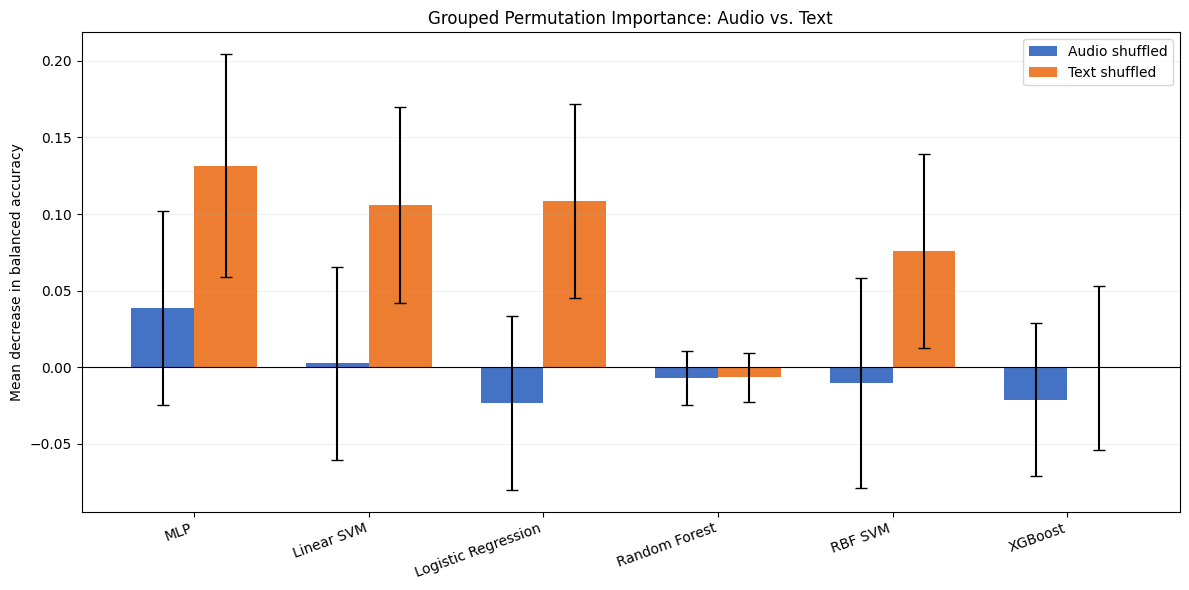

Saved: /content/drive/MyDrive/Thesis/Approach_2_Master/modality_permutation_importance/modality_importance_balanced_accuracy.png


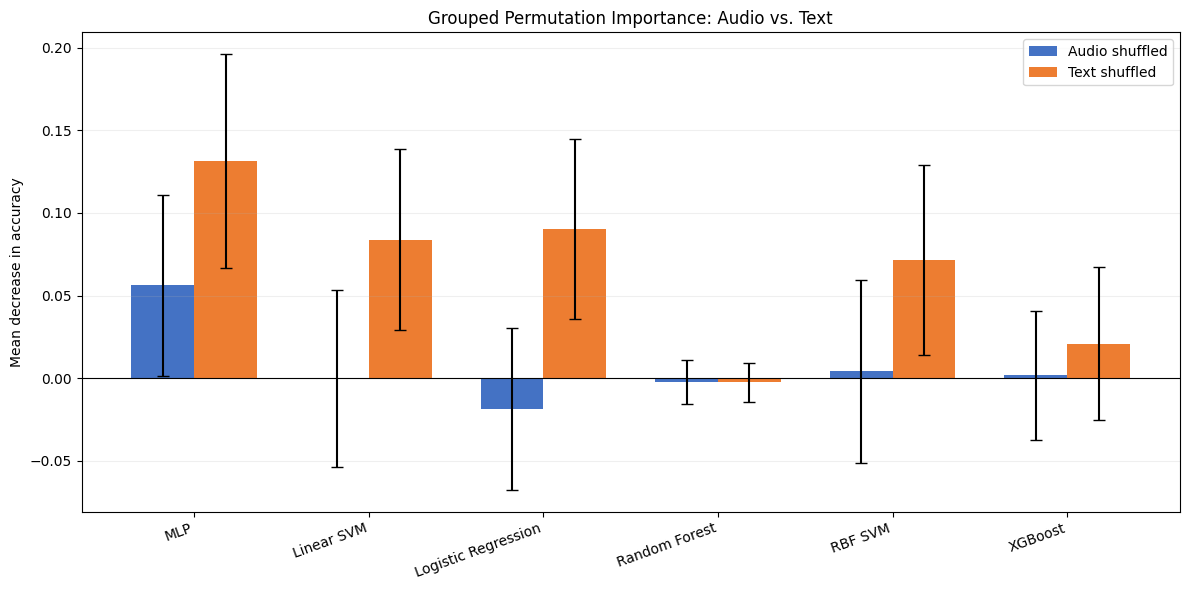

Saved: /content/drive/MyDrive/Thesis/Approach_2_Master/modality_permutation_importance/modality_importance_accuracy.png


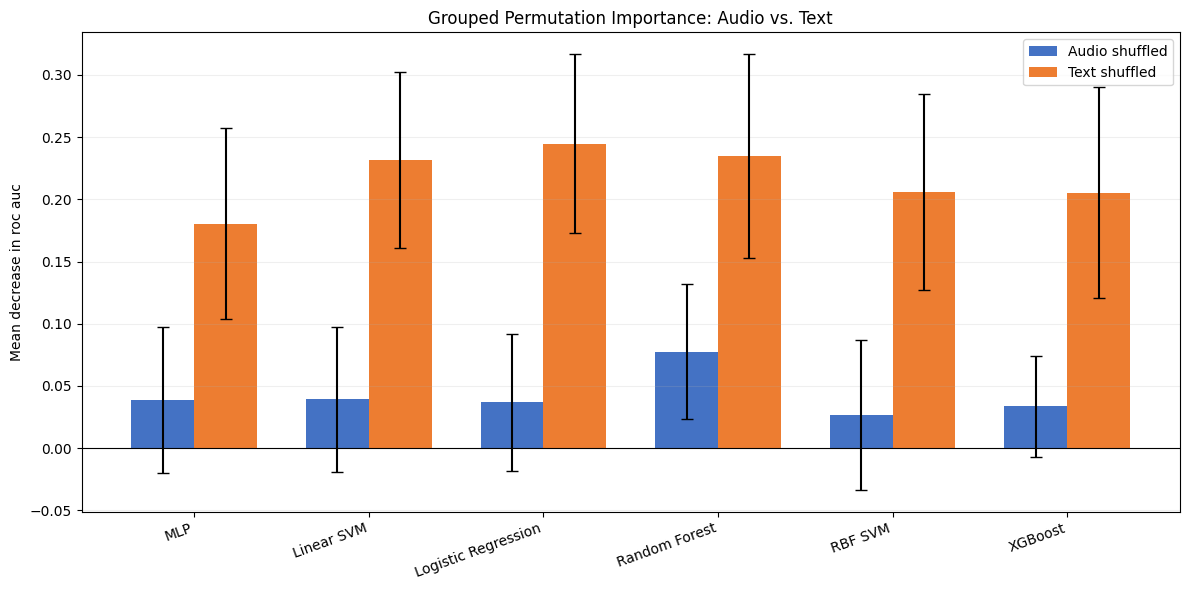

Saved: /content/drive/MyDrive/Thesis/Approach_2_Master/modality_permutation_importance/modality_importance_roc_auc.png


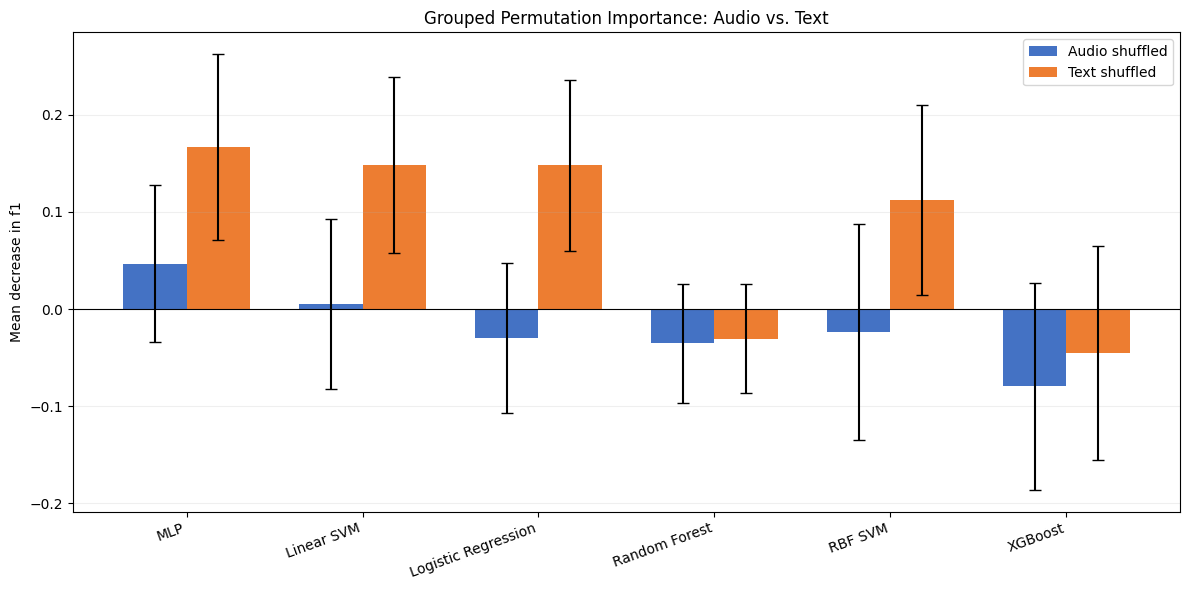

Saved: /content/drive/MyDrive/Thesis/Approach_2_Master/modality_permutation_importance/modality_importance_f1.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

MODEL_NAMES = {
    "MLP": "MLP_audio_text_weighted_256_linear",
    "Linear SVM": "Default_Classifier_audio_text_weighted_768_linear_svm",
    "Logistic Regression": "Tuned_Classifier_audio_text_weighted_768_logistic_regression",
    "Random Forest": "Tuned_Classifier_audio_text_weighted_768_random_forest",
    "RBF SVM": "Default_Classifier_audio_text_weighted_768_rbf_svm",
    "XGBoost": "Default_Classifier_audio_text_weighted_768_xgboost",
}

def plot_modality_importance(
    summary_df,
    metric="balanced_accuracy",
):
    models = [
        m for m in MODEL_NAMES
        if m in summary_df["model"].unique()
    ]

    audio = (
        summary_df[
            summary_df["modality_permuted"] == "audio"
        ]
        .set_index("model")
        .reindex(models)
    )

    text = (
        summary_df[
            summary_df["modality_permuted"] == "text"
        ]
        .set_index("model")
        .reindex(models)
    )

    x = np.arange(len(models))
    width = 0.36

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.bar(
        x - width / 2,
        audio[f"mean_drop_{metric}"],
        width,
        yerr=audio[f"sd_drop_{metric}"],
        capsize=4,
        label="Audio shuffled",
        color="#4472C4",
    )

    ax.bar(
        x + width / 2,
        text[f"mean_drop_{metric}"],
        width,
        yerr=text[f"sd_drop_{metric}"],
        capsize=4,
        label="Text shuffled",
        color="#ED7D31",
    )

    ax.axhline(0, color="black", linewidth=0.8)

    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=20, ha="right")
    ax.set_ylabel(f"Mean decrease in {metric.replace('_', ' ')}")
    ax.set_title(
        "Grouped Permutation Importance: Audio vs. Text"
    )
    ax.legend()
    ax.grid(axis="y", alpha=0.2)

    fig.tight_layout()

    filename = (
        OUTPUT_DIR
        / f"modality_importance_{metric}.png"
    )
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", filename)

for metric in METRICS:
    plot_modality_importance(summary_df, metric)

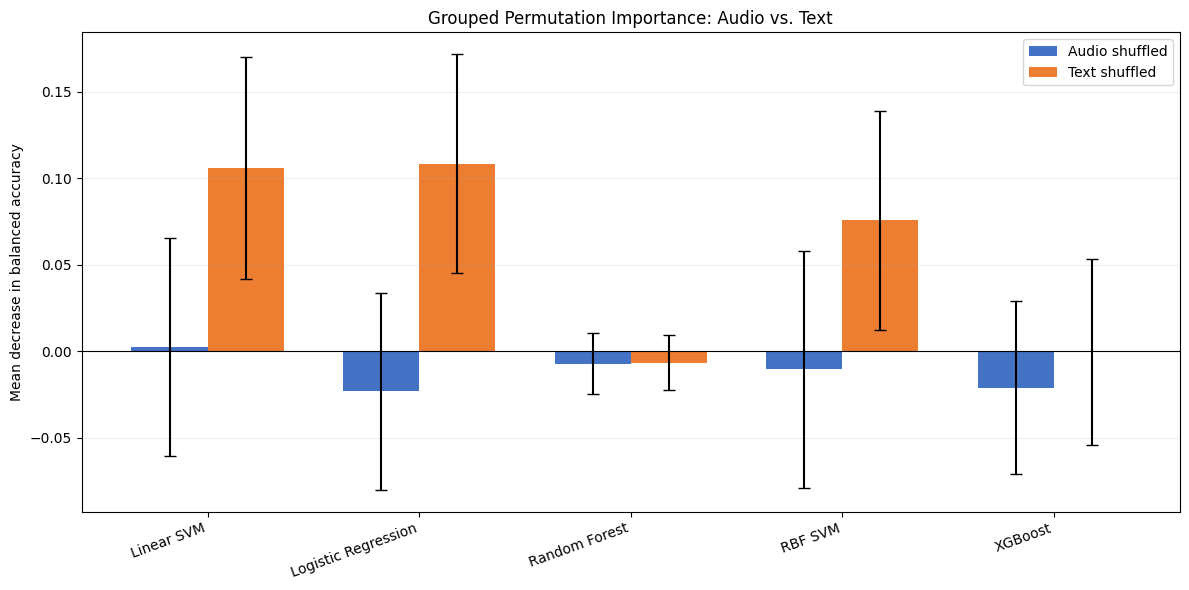

Saved: /content/drive/MyDrive/Thesis/Approach_2_Master/modality_permutation_importance/modality_importance_balanced_accuracy.png


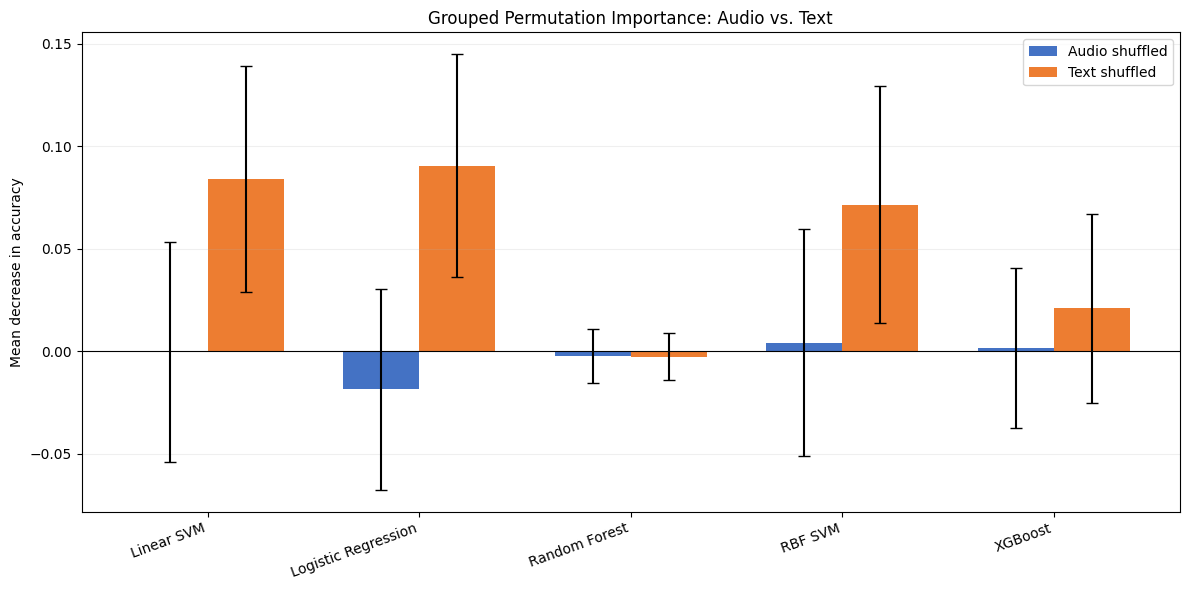

Saved: /content/drive/MyDrive/Thesis/Approach_2_Master/modality_permutation_importance/modality_importance_accuracy.png


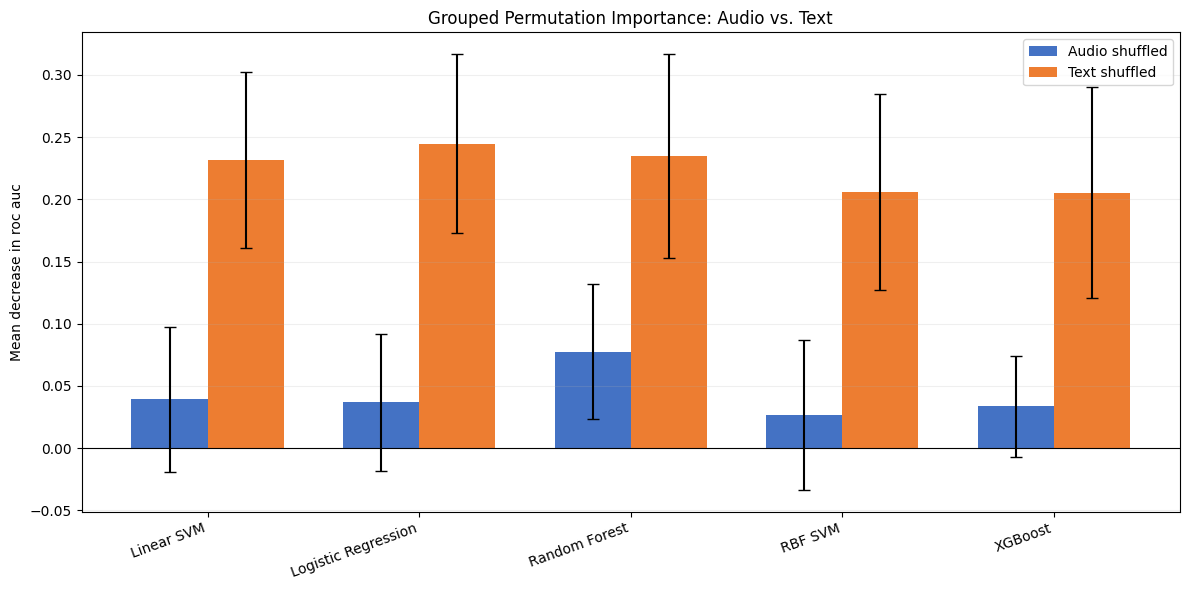

Saved: /content/drive/MyDrive/Thesis/Approach_2_Master/modality_permutation_importance/modality_importance_roc_auc.png


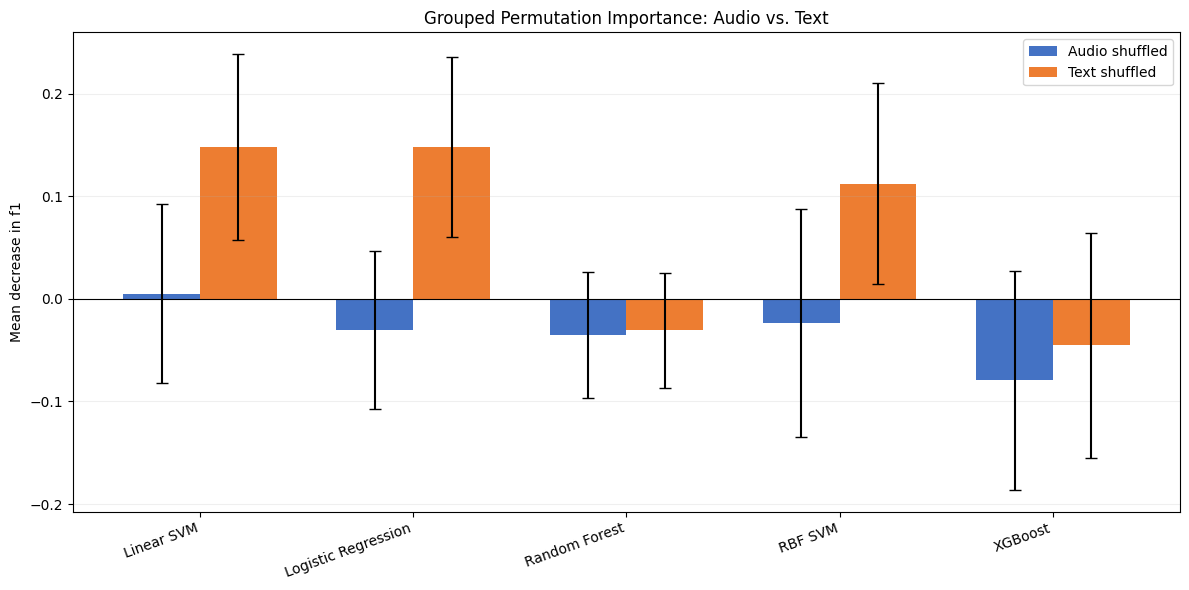

Saved: /content/drive/MyDrive/Thesis/Approach_2_Master/modality_permutation_importance/modality_importance_f1.png


In [ ]:
# Old

import matplotlib.pyplot as plt

def plot_modality_importance(
    summary_df,
    metric="balanced_accuracy",
):
    models = [
        m for m in MODEL_NAMES
        if m in summary_df["model"].unique()
    ]

    audio = (
        summary_df[
            summary_df["modality_permuted"] == "audio"
        ]
        .set_index("model")
        .reindex(models)
    )

    text = (
        summary_df[
            summary_df["modality_permuted"] == "text"
        ]
        .set_index("model")
        .reindex(models)
    )

    x = np.arange(len(models))
    width = 0.36

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.bar(
        x - width / 2,
        audio[f"mean_drop_{metric}"],
        width,
        yerr=audio[f"sd_drop_{metric}"],
        capsize=4,
        label="Audio shuffled",
        color="#4472C4",
    )

    ax.bar(
        x + width / 2,
        text[f"mean_drop_{metric}"],
        width,
        yerr=text[f"sd_drop_{metric}"],
        capsize=4,
        label="Text shuffled",
        color="#ED7D31",
    )

    ax.axhline(0, color="black", linewidth=0.8)

    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=20, ha="right")
    ax.set_ylabel(f"Mean decrease in {metric.replace('_', ' ')}")
    ax.set_title(
        "Grouped Permutation Importance: Audio vs. Text"
    )
    ax.legend()
    ax.grid(axis="y", alpha=0.2)

    fig.tight_layout()

    filename = (
        OUTPUT_DIR
        / f"modality_importance_{metric}.png"
    )
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", filename)

for metric in METRICS:
    plot_modality_importance(summary_df, metric)

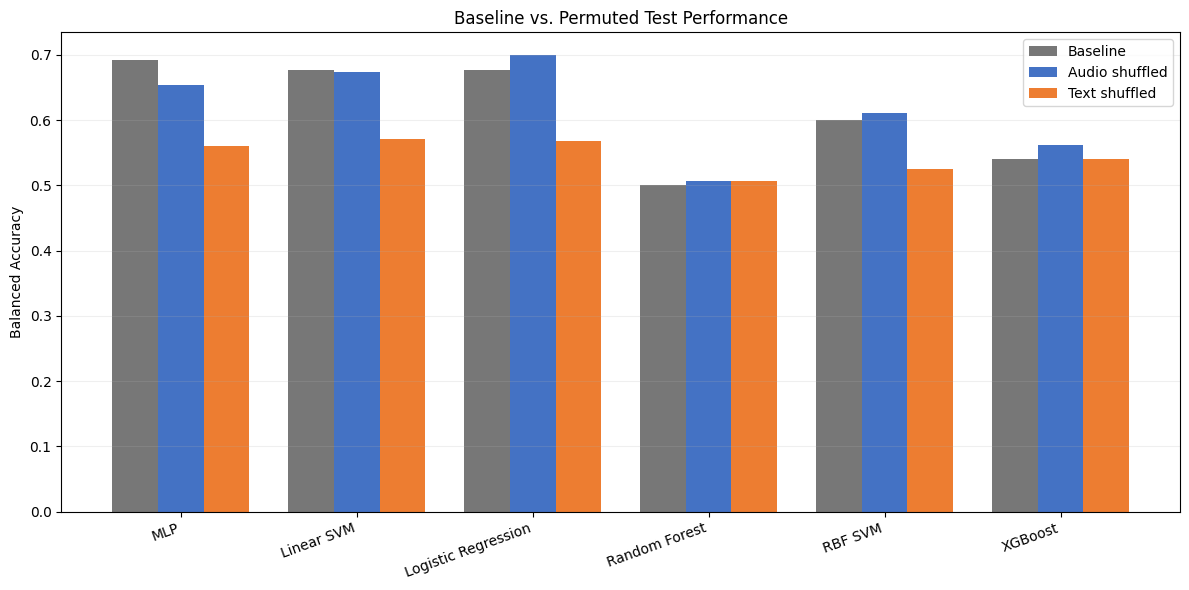

Saved: /content/drive/MyDrive/Thesis/Approach_2_Master/modality_permutation_importance/baseline_vs_permuted_balanced_accuracy.png


In [ ]:
def plot_baseline_vs_permuted(
    summary_df,
    metric="balanced_accuracy",
):
    models = [
        m for m in MODEL_NAMES
        if m in summary_df["model"].unique()
    ]

    audio = (
        summary_df[
            summary_df["modality_permuted"] == "audio"
        ]
        .set_index("model")
        .reindex(models)
    )
    text = (
        summary_df[
            summary_df["modality_permuted"] == "text"
        ]
        .set_index("model")
        .reindex(models)
    )

    x = np.arange(len(models))
    width = 0.26

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.bar(
        x - width,
        audio[f"baseline_{metric}"],
        width,
        label="Baseline",
        color="#777777",
    )
    ax.bar(
        x,
        audio[f"mean_permuted_{metric}"],
        width,
        label="Audio shuffled",
        color="#4472C4",
    )
    ax.bar(
        x + width,
        text[f"mean_permuted_{metric}"],
        width,
        label="Text shuffled",
        color="#ED7D31",
    )

    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=20, ha="right")
    ax.set_ylabel(metric.replace("_", " ").title())
    ax.set_title(
        "Baseline vs. Permuted Test Performance"
    )
    ax.legend()
    ax.grid(axis="y", alpha=0.2)

    fig.tight_layout()

    filename = (
        OUTPUT_DIR
        / f"baseline_vs_permuted_{metric}.png"
    )
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", filename)

plot_baseline_vs_permuted(summary_df)

## LIME

### Pilot

In [ ]:
!pip -q install lime transformers

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
%pip install --no-cache-dir --force-reinstall "sympy==1.13.1"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.2/6.2 MB 43.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.2/536.2 kB 57.2 MB/s  0:00:00
  Attempting uninstall: mpmath
    Found existing installation: mpmath 1.3.0
    Uninstalling mpmath-1.3.0:
      Successfully uninstalled mpmath-1.3.0
  Attempting uninstall: sympy
    Found existing installation: sympy 1.14.0
    Uninstalling sympy-1.14.0:
      Successfully uninstalled sympy-1.14.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [sympy]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.11.0+cu130 requires sympy>=1.13.3, but you have sympy 1.13.1 which is incompatible.


In [ ]:
import sys
import importlib.metadata as md
import importlib.util

print("Python:", sys.version)

for package in ["torch", "sympy", "transformers", "lime"]:
    try:
        print(f"{package}: {md.version(package)}")
    except md.PackageNotFoundError:
        print(f"{package}: Not installed")

spec = importlib.util.find_spec("sympy")
print("SymPy location:", spec.origin if spec else None)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
torch: 2.11.0+cu130
sympy: 1.13.1
transformers: 5.20.2
lime: 0.2.0.1
SymPy location: /usr/local/lib/python3.13/dist-packages/sympy/__init__.py


In [ ]:
import sympy
import sympy.printing

print("SymPy:", sympy.__version__)
print("SymPy printing:", sympy.printing)

import torch
print("PyTorch:", torch.__version__)

from transformers import AutoTokenizer, AutoModel
print("Transformers imports successful!")

from lime.lime_text import LimeTextExplainer
print("LIME import successful!")

SymPy: 1.13.1
SymPy printing: <module 'sympy.printing' from '/usr/local/lib/python3.13/dist-packages/sympy/printing/__init__.py'>
PyTorch: 2.11.0+cu130
Transformers imports successful!
LIME import successful!


In [ ]:
from google.colab import userdata
import os

HF_TOKEN = userdata.get("HF_TOKEN")

os.environ["HF_TOKEN"] = HF_TOKEN

print("HF_TOKEN loaded successfully!")

HF_TOKEN loaded successfully!


In [ ]:
def weighted_mean_numpy(embeddings, lengths):
    embeddings = np.asarray(embeddings, dtype=np.float32)
    lengths = np.asarray(lengths, dtype=np.float32)

    denominator = lengths.sum()

    if denominator <= 0:
        return embeddings.mean(axis=0)

    weights = lengths / denominator

    return np.sum(
        embeddings * weights[:, None],
        axis=0,
    )

In [ ]:
import numpy as np

def make_classical_features(
    X_audio,
    X_text,
    preprocessing
):
    X_audio = np.asarray(X_audio, dtype=np.float32)
    X_text = np.asarray(X_text, dtype=np.float32)

    assert X_audio.shape[0] == X_text.shape[0]
    assert X_audio.shape[1] == 768
    assert X_text.shape[1] == 768

    # No PCA for the weighted_768 experiment.
    assert preprocessing.get("audio_pca") is None
    assert preprocessing.get("text_pca") is None

    return np.concatenate(
        [X_audio, X_text],
        axis=1
    )


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

DRIVE_ROOT = Path("/content/drive/MyDrive")
THESIS_ROOT = DRIVE_ROOT / "Thesis"
MASTER_ROOT = THESIS_ROOT / "Approach_2_Master"

AUDIO_DIR = (
    THESIS_ROOT
    / "precomputed_multimodal_embeddings"
    / "wavlm_base_plus_layer8"
)

TEXT_DIR = (
    THESIS_ROOT
    / "precomputed_multimodal_embeddings"
    / "mentalroberta_layer12"
)

metadata = pd.read_csv(
    THESIS_ROOT / "TFIDF/participant_documents.csv"
)

# Create a standardized participant ID column
metadata["pid"] = (
    metadata["Participant_ID"]
    .astype(int)
    .astype(str)
)

# Select held-out test participants
test_df = metadata[
    metadata["Dataset"].str.strip().str.lower() == "test"
].copy()

# Extract participant IDs and labels
pids = test_df["pid"].tolist()
y_test = test_df["PHQ8_Binary"].astype(int).to_numpy()

print("Test participants:", len(pids))
print("First 5 participant IDs:", pids[:5])
print("Label distribution:")
print(test_df["PHQ8_Binary"].value_counts())


def weighted_mean_numpy(embeddings, lengths):
    embeddings = np.asarray(
        embeddings, dtype=np.float32
    )
    lengths = np.asarray(
        lengths, dtype=np.float32
    )

    if lengths.sum() <= 0:
        return embeddings.mean(axis=0)

    weights = lengths / lengths.sum()

    return np.sum(
        embeddings * weights[:, None],
        axis=0
    )

audio_vectors = []
text_vectors = []

for pid in pids:
    with np.load(AUDIO_DIR / f"{pid}.npz") as data:
        audio_vectors.append(
            weighted_mean_numpy(
                data["embeddings"],
                data["num_frames"]
            )
        )

    with np.load(TEXT_DIR / f"{pid}.npz") as data:
        text_vectors.append(
            weighted_mean_numpy(
                data["embeddings"],
                data["num_tokens"]
            )
        )

X_audio = np.stack(audio_vectors)
X_text = np.stack(text_vectors)

print("Audio:", X_audio.shape)
print("Text:", X_text.shape)
print("Labels:", y_test.shape)
print("Participants:", len(pids))


Mounted at /content/drive
Test participants: 46
First 5 participant IDs: ['300', '301', '306', '308', '309']
Label distribution:
PHQ8_Binary
0    32
1    14
Name: count, dtype: int64
Audio: (46, 768)
Text: (46, 768)
Labels: (46,)
Participants: 46


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
)

MODEL_DIR = (
    ROOT
    / "Approach_2_Master"
    / "models"
    / "Tuned_Classifier_audio_text_weighted_768_logistic_regression"
    / "final"
)

print("Model directory exists:", MODEL_DIR.exists())

if MODEL_DIR.exists():
    print("Files:", [p.name for p in MODEL_DIR.iterdir()])

logreg_model = joblib.load(
    MODEL_DIR / "model.joblib"
)

logreg_prep = joblib.load(
    MODEL_DIR / "preprocessing.joblib"
)

X_baseline = make_classical_features(
    X_audio,
    X_text,
    logreg_prep
)

baseline_pred = logreg_model.predict(X_baseline)

baseline_scores = logreg_model.predict_proba(
    X_baseline
)[:, 1]

print("Accuracy:",
      accuracy_score(y_test, baseline_pred))

print("Balanced accuracy:",
      balanced_accuracy_score(y_test, baseline_pred))

print("F1:",
      f1_score(y_test, baseline_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, baseline_scores))

print("Input shape:", X_baseline.shape)


Model directory exists: True
Files: ['model.joblib', 'preprocessing.joblib']
Accuracy: 0.717391304347826
Balanced accuracy: 0.6763392857142857
F1: 0.5517241379310345
ROC-AUC: 0.8080357142857143
Input shape: (46, 1536)


In [ ]:
import re
import time
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from transformers import AutoTokenizer, AutoModel
from lime.lime_text import LimeTextExplainer

ROOT = Path("/content/drive/MyDrive/Thesis")
LIME_DIR = ROOT / "Approach_2_Master/lime_pilot"
LIME_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_ID = "mental/mental-roberta-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
text_model = AutoModel.from_pretrained(MODEL_ID).to(DEVICE)
text_model.eval()

max_length = tokenizer.model_max_length
if max_length is None or max_length > 100_000:
    max_length = 512

CONTENT_TOKENS = (
    max_length
    - tokenizer.num_special_tokens_to_add(pair=False)
)

print("Device:", DEVICE)
print("Content tokens per chunk:", CONTENT_TOKENS)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: mental/mental-roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Device: cuda
Content tokens per chunk: 510


In [ ]:
@torch.inference_mode()
def encode_transcripts(texts, chunk_batch_size=8):
    """
    Return one pooled 768-D embedding per transcript.
    Uses MentalRoBERTa layer 12 and content-token means.
    """
    results = []

    for text in texts:
        token_ids = tokenizer.encode(
            text,
            add_special_tokens=False,
            truncation=False,
            verbose=False,
        )

        if not token_ids:
            raise ValueError("Empty perturbed transcript")

        chunks = [
            token_ids[i:i + CONTENT_TOKENS]
            for i in range(0, len(token_ids), CONTENT_TOKENS)
        ]

        chunk_vectors = []
        chunk_lengths = []

        for start in range(0, len(chunks), chunk_batch_size):
            batch_chunks = chunks[
                start:start + chunk_batch_size
            ]

            prepared = [
                [tokenizer.cls_token_id]
                + ids
                + [tokenizer.sep_token_id]
                for ids in batch_chunks
            ]

            padded = tokenizer.pad(
                {"input_ids": prepared},
                padding=True,
                return_tensors="pt",
            )

            input_ids = padded["input_ids"].to(DEVICE)
            attention_mask = padded["attention_mask"].to(DEVICE)

            outputs = text_model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                output_hidden_states=True,
                return_dict=True,
            )

            hidden = outputs.hidden_states[12]

            content_mask = torch.zeros_like(
                attention_mask,
                dtype=torch.bool,
            )

            for j, ids in enumerate(batch_chunks):
                content_mask[j, 1:1 + len(ids)] = True

            weights = content_mask.unsqueeze(-1).to(
                hidden.dtype
            )

            pooled = (
                (hidden * weights).sum(dim=1)
                / weights.sum(dim=1).clamp_min(1.0)
            )

            chunk_vectors.append(
                pooled.float().cpu().numpy()
            )
            chunk_lengths.extend(
                len(ids) for ids in batch_chunks
            )

        vectors = np.concatenate(chunk_vectors, axis=0)
        lengths = np.asarray(chunk_lengths, dtype=np.float32)

        results.append(
            weighted_mean_numpy(vectors, lengths)
        )

    return np.asarray(results, dtype=np.float32)

In [ ]:
# Validate regenerated MentalRoBERTa embeddings

import numpy as np
import pandas as pd

metadata = pd.read_csv(
    ROOT / "TFIDF/participant_documents.csv"
)

metadata["pid"] = (
    metadata["Participant_ID"]
    .astype(int)
    .astype(str)
)

metadata_by_pid = metadata.set_index("pid")

# Select one held-out test participant
test_df = metadata[
    metadata["Dataset"].str.lower() == "test"
].copy()

sample_pid = test_df.iloc[0]["pid"]

sample_text = metadata_by_pid.loc[
    sample_pid, "raw_participant_text"
]

# Regenerate embedding from original transcript
regenerated = encode_transcripts([sample_text])[0]

# Load original saved chunk embeddings
text_path = (
    ROOT
    / "precomputed_multimodal_embeddings"
    / "mentalroberta_layer12"
    / f"{sample_pid}.npz"
)

with np.load(text_path) as data:
    stored_chunks = data["embeddings"]
    stored_lengths = data["num_tokens"]

# Apply the original token-weighted pooling
stored = weighted_mean_numpy(
    stored_chunks,
    stored_lengths
)

# Compare embeddings
max_difference = np.max(
    np.abs(regenerated - stored)
)

cosine_similarity = (
    np.dot(regenerated, stored)
    / (
        np.linalg.norm(regenerated)
        * np.linalg.norm(stored)
    )
)

print("Participant:", sample_pid)
print("Stored chunks:", stored_chunks.shape)
print("Regenerated embedding:", regenerated.shape)
print("Max absolute difference:", max_difference)
print("Cosine similarity:", cosine_similarity)

assert np.allclose(
    regenerated,
    stored,
    atol=1e-4,
    rtol=1e-4,
), "Embedding mismatch: investigate before running LIME."

print("Embedding validation passed.")


Participant: 300
Stored chunks: (1, 768)
Regenerated embedding: (768,)
Max absolute difference: 1.4305115e-06
Cosine similarity: 1.0
Embedding validation passed.


In [ ]:
import joblib
import numpy as np
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Thesis")

MODEL_DIR = (
    ROOT
    / "Approach_2_Master"
    / "models"
    / "Tuned_Classifier_audio_text_weighted_768_logistic_regression"
    / "final"
)

print("Model directory exists:", MODEL_DIR.exists())

if MODEL_DIR.exists():
    print("Files:", [p.name for p in MODEL_DIR.iterdir()])

logreg_model = joblib.load(
    MODEL_DIR / "model.joblib"
)

logreg_prep = joblib.load(
    MODEL_DIR / "preprocessing.joblib"
)

print("Model loaded:", type(logreg_model))
print("Preprocessing loaded:", type(logreg_prep))

X_baseline = make_classical_features(
    X_audio, X_text, logreg_prep
)

# Predicted depression labels (0 or 1)
baseline_pred = logreg_model.predict(X_baseline)

# Predicted probability of depression (class 1)
baseline_scores = logreg_model.predict_proba(
    X_baseline
)[:, 1]

selection_df = pd.DataFrame({
    "pid": [str(pid) for pid in pids],
    "true_label": y_test,
    "predicted_label": baseline_pred,
    "depression_score": baseline_scores,
    "correct": baseline_pred == y_test,
    "audio_index": np.arange(len(pids)),
})

# Try to include both correct and incorrect predictions.
selected_parts = []

for label in [0, 1]:
    subset = selection_df[
        selection_df["true_label"] == label
    ]

    correct = subset[subset["correct"]].sample(
        n=min(3, sum(subset["correct"])),
        random_state=42,
    )

    incorrect = subset[
        ~subset["correct"]
    ].sample(
        n=min(2, sum(~subset["correct"])),
        random_state=42,
    )

    chosen = pd.concat([correct, incorrect])

    if len(chosen) < 5:
        remaining = subset[
            ~subset["pid"].isin(chosen["pid"])
        ]
        chosen = pd.concat([
            chosen,
            remaining.sample(
                n=5 - len(chosen),
                random_state=42,
            ),
        ])

    selected_parts.append(chosen)

pilot_df = pd.concat(
    selected_parts,
    ignore_index=True,
)

display(pilot_df)

pilot_df.to_csv(
    LIME_DIR / "pilot_participants.csv",
    index=False,
)


Model directory exists: True
Files: ['model.joblib', 'preprocessing.joblib']
Model loaded: <class 'sklearn.pipeline.Pipeline'>
Preprocessing loaded: <class 'dict'>


,pid,true_label,predicted_label,depression_score,correct,audio_index
0,387,0,0,3.293791e-06,True,20
1,438,0,0,1.442490e-03,True,33
2,300,0,0,6.513650e-09,True,0
3,301,0,1,9.445967e-01,False,1
4,314,0,1,9.207366e-01,False,6
5,332,1,1,9.999607e-01,True,9
6,405,1,1,9.728894e-01,True,23
7,309,1,1,9.961277e-01,True,4
8,308,1,0,6.635315e-06,False,3
9,311,1,0,2.349737e-01,False,5


In [ ]:
explainer = LimeTextExplainer(
    class_names=["No depression", "Depression"],
    random_state=42,
    bow=True,
)

def make_lime_predictor(audio_vector):
    audio_vector = np.asarray(
        audio_vector, dtype=np.float32
    )

    def predict_proba(texts):
        texts = list(texts)

        text_vectors = encode_transcripts(texts)

        audio_vectors = np.repeat(
            audio_vector[None, :],
            len(texts),
            axis=0,
        )

        X = make_classical_features(
            audio_vectors,
            text_vectors,
            logreg_prep,
        )

        return logreg_model.predict_proba(X)

    return predict_proba


### 500 LIME Perturbations

In [ ]:
N_SAMPLES = 500
TOP_WORDS = 15

lime_rows = []
timing_rows = []

for row in pilot_df.itertuples(index=False):
    pid = row.pid

    transcript = metadata_by_pid.loc[
        pid, "raw_participant_text"
    ]

    audio_vector = X_audio[row.audio_index]

    predictor = make_lime_predictor(audio_vector)

    start = time.time()

    explanation = explainer.explain_instance(
        text_instance=transcript,
        classifier_fn=predictor,
        labels=(1,),
        num_features=TOP_WORDS,
        num_samples=N_SAMPLES,
    )

    elapsed = time.time() - start

    explanation.save_to_file(
        str(LIME_DIR / f"participant_{pid}_lime.html")
    )

    for rank, (word, weight) in enumerate(
        explanation.as_list(label=1),
        start=1,
    ):
        lime_rows.append({
            "participant_id": pid,
            "true_label": row.true_label,
            "predicted_label": row.predicted_label,
            "correct": row.correct,
            "word": word,
            "lime_weight": weight,
            "rank": rank,
        })

    timing_rows.append({
        "participant_id": pid,
        "seconds": elapsed,
    })

    print(
        f"Completed {pid}: "
        f"{elapsed:.1f} seconds"
    )

    # Save after every participant.
    pd.DataFrame(lime_rows).to_csv(
        LIME_DIR / "lime_word_explanations.csv",
        index=False,
    )

lime_df = pd.DataFrame(lime_rows)
timing_df = pd.DataFrame(timing_rows)

display(timing_df)
display(lime_df.head(20))


Completed 387: 9.0 seconds
Completed 438: 27.5 seconds
Completed 300: 4.8 seconds
Completed 301: 15.9 seconds
Completed 314: 27.9 seconds
Completed 332: 12.8 seconds
Completed 405: 23.5 seconds
Completed 309: 9.1 seconds
Completed 308: 9.4 seconds
Completed 311: 9.0 seconds


,participant_id,seconds
0,387,8.968151
1,438,27.527600
2,300,4.783101
3,301,15.872168
4,314,27.860608
5,332,12.764758
6,405,23.486893
7,309,9.087621
8,308,9.366304
9,311,9.025499


,participant_id,true_label,predicted_label,correct,word,lime_weight,rank
0,387,0,0,True,a,-0.275585,1
1,387,0,0,True,i,-0.199518,2
2,387,0,0,True,and,-0.187075,3
3,387,0,0,True,happy,-0.151628,4
4,387,0,0,True,brother,-0.139031,5
5,387,0,0,True,had,-0.137036,6
6,387,0,0,True,have,-0.127314,7
7,387,0,0,True,welcome,-0.118021,8
8,387,0,0,True,day,-0.115665,9
9,387,0,0,True,mad,-0.102548,10


In [ ]:
lime_df["normalized_word"] = (
    lime_df["word"]
    .str.lower()
    .str.strip()
)

word_summary = (
    lime_df.groupby("normalized_word")
    .agg(
        participants_present=(
            "participant_id", "nunique"
        ),
        mean_weight=("lime_weight", "mean"),
        mean_abs_weight=(
            "lime_weight",
            lambda x: np.mean(np.abs(x))
        ),
        positive_occurrences=(
            "lime_weight",
            lambda x: int((x > 0).sum())
        ),
        negative_occurrences=(
            "lime_weight",
            lambda x: int((x < 0).sum())
        ),
    )
    .reset_index()
    .sort_values(
        ["participants_present", "mean_abs_weight"],
        ascending=False,
    )
)

word_summary.to_csv(
    LIME_DIR / "recurring_lime_words.csv",
    index=False,
)

display(word_summary.head(20))


,normalized_word,participants_present,mean_weight,mean_abs_weight,positive_occurrences,negative_occurrences
61,i,4,-0.230164,0.230164,0,4
0,a,3,-0.166402,0.166402,0,3
125,um,2,-0.221132,0.221132,0,2
30,day,2,-0.112286,0.112286,0,2
8,and,2,-0.109416,0.109416,0,2
68,like,2,-0.079982,0.079982,0,2
79,mm,2,-0.071934,0.071934,0,2
88,off,2,-0.030255,0.030255,0,2
90,other,2,-0.018121,0.018121,0,2
118,their,2,-0.000179,0.000179,0,2


In [ ]:
# Separate positive and negative LIME contributions

positive_words = (
    lime_df[lime_df["lime_weight"] > 0]
    .groupby("normalized_word")
    .agg(
        participants=("participant_id", "nunique"),
        mean_positive_weight=("lime_weight", "mean"),
        max_positive_weight=("lime_weight", "max"),
    )
    .reset_index()
    .sort_values(
        ["participants", "mean_positive_weight"],
        ascending=False,
    )
)

negative_words = (
    lime_df[lime_df["lime_weight"] < 0]
    .groupby("normalized_word")
    .agg(
        participants=("participant_id", "nunique"),
        mean_negative_weight=("lime_weight", "mean"),
        min_negative_weight=("lime_weight", "min"),
    )
    .reset_index()
    .sort_values(
        ["participants", "mean_negative_weight"],
        ascending=[False, True],
    )
)

print("TOP WORDS SUPPORTING DEPRESSION")
display(positive_words.head(20))

print("TOP WORDS SUPPORTING NO DEPRESSION")
display(negative_words.head(20))


TOP WORDS SUPPORTING DEPRESSION


,normalized_word,participants,mean_positive_weight,max_positive_weight
8,every,2,0.000065,0.000101
20,trying,1,0.069309,0.069309
13,maybe,1,0.067072,0.067072
23,yesterday,1,0.063212,0.063212
2,ago,1,0.046834,0.046834
14,most,1,0.030433,0.030433
21,uneasy,1,0.018317,0.018317
7,didn,1,0.012619,0.012619
9,goodbye,1,0.010296,0.010296
15,once,1,0.009099,0.009099


TOP WORDS SUPPORTING NO DEPRESSION


,normalized_word,participants,mean_negative_weight,min_negative_weight
50,i,4,-0.230164,-0.317161
0,a,3,-0.166402,-0.275585
104,um,2,-0.221132,-0.222678
23,day,2,-0.112286,-0.115665
4,and,2,-0.109416,-0.187075
56,like,2,-0.079982,-0.159784
65,mm,2,-0.071934,-0.115858
73,off,2,-0.030255,-0.059348
74,other,2,-0.018121,-0.036097
100,their,2,-0.000179,-0.000218


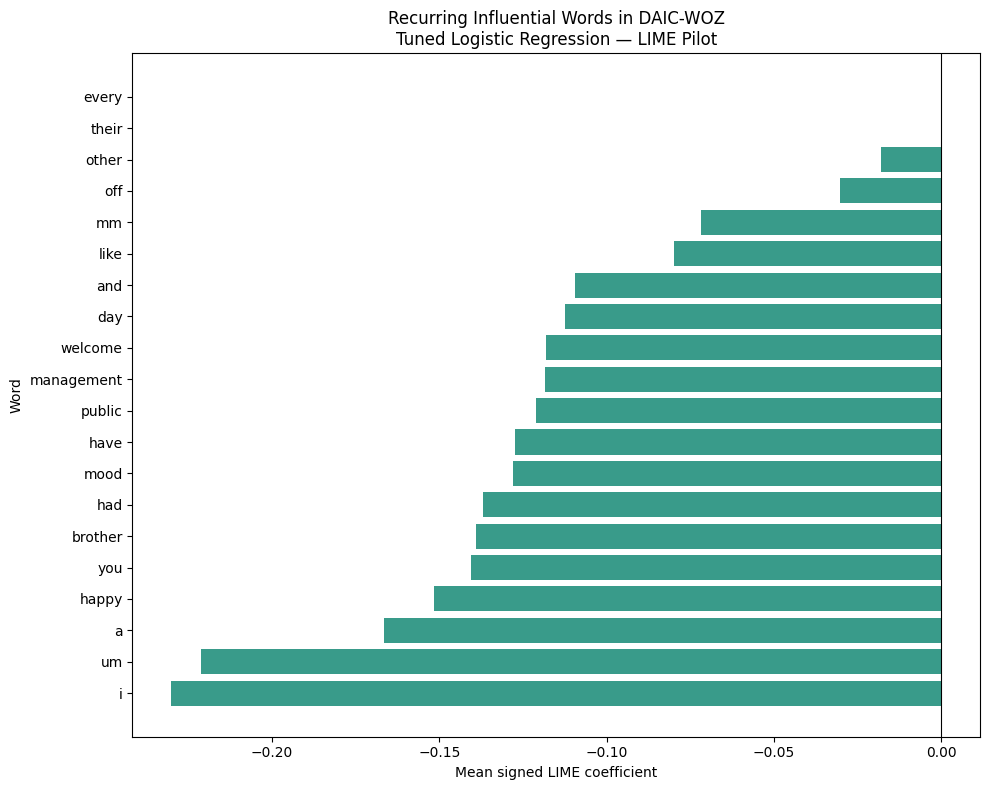

In [ ]:
top_words = (
    word_summary
    .sort_values(
        ["participants_present", "mean_abs_weight"],
        ascending=False,
    )
    .head(20)
    .sort_values("mean_weight")
)

colors = [
    "#D98C3F" if w > 0 else "#399B8A"
    for w in top_words["mean_weight"]
]

fig, ax = plt.subplots(figsize=(10, 8))

ax.barh(
    top_words["normalized_word"],
    top_words["mean_weight"],
    color=colors,
)

ax.axvline(0, color="black", linewidth=0.8)

ax.set_xlabel("Mean signed LIME coefficient")
ax.set_ylabel("Word")
ax.set_title(
    "Recurring Influential Words in DAIC-WOZ\n"
    "Tuned Logistic Regression — LIME Pilot"
)

fig.tight_layout()
fig.savefig(
    LIME_DIR / "lime_recurring_words.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### 1000 LIME Perturbations

In [ ]:
N_SAMPLES = 1000
TOP_WORDS = 20

LIME_BASE_DIR = Path(
    "/content/drive/MyDrive/Thesis/Approach_2_Master/lime_pilot"
)

LIME_DIR = LIME_BASE_DIR / f"perturbations_{N_SAMPLES}"

LIME_DIR.mkdir(parents=True, exist_ok=True)

pilot_df = pd.read_csv(LIME_BASE_DIR / "pilot_participants.csv")


# Load selected pilot participants
pilot_df = pd.read_csv(
    LIME_BASE_DIR / "pilot_participants.csv"
)

# Standardize participant IDs to strings
pilot_df["pid"] = (
    pilot_df["pid"]
    .astype(int)
    .astype(str)
)

metadata["pid"] = (
    metadata["Participant_ID"]
    .astype(int)
    .astype(str)
)

# Rebuild metadata lookup with string IDs
metadata_by_pid = metadata.set_index("pid")

# Verify all selected participants exist
missing_pids = (
    set(pilot_df["pid"])
    - set(metadata_by_pid.index)
)

print("Pilot participants:", len(pilot_df))
print("Missing participant IDs:", missing_pids)
print("Metadata index dtype:", metadata_by_pid.index.dtype)

assert not missing_pids, (
    f"Participants missing from metadata: {missing_pids}"
)

lime_rows = []
timing_rows = []

for row in pilot_df.itertuples(index=False):
    pid = row.pid

    transcript = metadata_by_pid.loc[
        pid, "raw_participant_text"
    ]

    audio_vector = X_audio[row.audio_index]

    predictor = make_lime_predictor(audio_vector)

    start = time.time()

    explanation = explainer.explain_instance(
        text_instance=transcript,
        classifier_fn=predictor,
        labels=(1,),
        num_features=TOP_WORDS,
        num_samples=N_SAMPLES,
    )

    elapsed = time.time() - start

    explanation.save_to_file(
        str(LIME_DIR / f"participant_{pid}_lime.html")
    )

    for rank, (word, weight) in enumerate(
        explanation.as_list(label=1),
        start=1,
    ):
        lime_rows.append({
            "participant_id": pid,
            "true_label": row.true_label,
            "predicted_label": row.predicted_label,
            "correct": row.correct,
            "word": word,
            "lime_weight": weight,
            "rank": rank,
        })

    timing_rows.append({
        "participant_id": pid,
        "seconds": elapsed,
    })

    print(
        f"Completed {pid}: "
        f"{elapsed:.1f} seconds"
    )

    # Save after every participant.
    pd.DataFrame(lime_rows).to_csv(
        LIME_DIR / "lime_word_explanations.csv",
        index=False,
    )

lime_df = pd.DataFrame(lime_rows)
timing_df = pd.DataFrame(timing_rows)

display(timing_df)
display(lime_df.head(20))


Pilot participants: 10
Missing participant IDs: set()
Metadata index dtype: object
Completed 387: 18.1 seconds
Completed 438: 55.7 seconds
Completed 300: 9.9 seconds
Completed 301: 32.1 seconds
Completed 314: 56.6 seconds
Completed 332: 25.6 seconds
Completed 405: 47.7 seconds
Completed 309: 18.2 seconds
Completed 308: 18.8 seconds
Completed 311: 18.2 seconds


,participant_id,seconds
0,387,18.098690
1,438,55.723706
2,300,9.929129
3,301,32.136080
4,314,56.573503
5,332,25.585792
6,405,47.710755
7,309,18.195953
8,308,18.777722
9,311,18.216839


,participant_id,true_label,predicted_label,correct,word,lime_weight,rank
0,387,0,0,True,i,-0.201507,1
1,387,0,0,True,good,-0.123031,2
2,387,0,0,True,a,-0.120223,3
3,387,0,0,True,philadelphia,-0.108614,4
4,387,0,0,True,save,-0.108206,5
5,387,0,0,True,enthusiastic,-0.106259,6
6,387,0,0,True,has,-0.101225,7
7,387,0,0,True,warm,-0.100432,8
8,387,0,0,True,do,-0.099424,9
9,387,0,0,True,okay,-0.090839,10


In [ ]:
lime_df["normalized_word"] = (
    lime_df["word"]
    .str.lower()
    .str.strip()
)

word_summary = (
    lime_df.groupby("normalized_word")
    .agg(
        participants_present=(
            "participant_id", "nunique"
        ),
        mean_weight=("lime_weight", "mean"),
        mean_abs_weight=(
            "lime_weight",
            lambda x: np.mean(np.abs(x))
        ),
        positive_occurrences=(
            "lime_weight",
            lambda x: int((x > 0).sum())
        ),
        negative_occurrences=(
            "lime_weight",
            lambda x: int((x < 0).sum())
        ),
    )
    .reset_index()
    .sort_values(
        ["participants_present", "mean_abs_weight"],
        ascending=False,
    )
)

word_summary.to_csv(
    LIME_DIR / "recurring_lime_words.csv",
    index=False,
)

display(word_summary.head(20))


,normalized_word,participants_present,mean_weight,mean_abs_weight,positive_occurrences,negative_occurrences
66,i,4,-0.195663,0.195663,0,4
126,really,3,-0.039102,0.039102,0,3
74,just,3,-0.007052,0.026196,1,2
159,um,2,-0.248989,0.248989,0,2
0,a,2,-0.104661,0.104661,0,2
79,like,2,-0.088414,0.088414,0,2
158,uh,2,-0.070531,0.070531,0,2
156,twenty,2,-0.068641,0.068641,0,2
9,and,2,-0.068307,0.068307,0,2
108,or,2,-0.043054,0.043054,0,2


In [ ]:
# Separate positive and negative LIME contributions

positive_words = (
    lime_df[lime_df["lime_weight"] > 0]
    .groupby("normalized_word")
    .agg(
        participants=("participant_id", "nunique"),
        mean_positive_weight=("lime_weight", "mean"),
        max_positive_weight=("lime_weight", "max"),
    )
    .reset_index()
    .sort_values(
        ["participants", "mean_positive_weight"],
        ascending=False,
    )
)

negative_words = (
    lime_df[lime_df["lime_weight"] < 0]
    .groupby("normalized_word")
    .agg(
        participants=("participant_id", "nunique"),
        mean_negative_weight=("lime_weight", "mean"),
        min_negative_weight=("lime_weight", "min"),
    )
    .reset_index()
    .sort_values(
        ["participants", "mean_negative_weight"],
        ascending=[False, True],
    )
)

print("TOP WORDS SUPPORTING DEPRESSION")
display(positive_words.head(20))

print("TOP WORDS SUPPORTING NO DEPRESSION")
display(negative_words.head(20))


TOP WORDS SUPPORTING DEPRESSION


,normalized_word,participants,mean_positive_weight,max_positive_weight
28,sigh,2,0.009879,0.019757
34,weeks,1,0.048055,0.048055
32,thin,1,0.039962,0.039962
17,less,1,0.034030,0.034030
31,they,1,0.030626,0.030626
33,was,1,0.029152,0.029152
15,just,1,0.028715,0.028715
5,can,1,0.025326,0.025326
27,regular,1,0.025257,0.025257
0,add,1,0.022410,0.022410


TOP WORDS SUPPORTING NO DEPRESSION


,normalized_word,participants,mean_negative_weight,min_negative_weight
55,i,4,-0.195663,-0.290312
104,really,3,-0.039102,-0.089126
131,um,2,-0.248989,-0.251007
0,a,2,-0.104661,-0.120223
63,like,2,-0.088414,-0.099550
130,uh,2,-0.070531,-0.100194
128,twenty,2,-0.068641,-0.106538
7,and,2,-0.068307,-0.093656
88,or,2,-0.043054,-0.086080
142,you,2,-0.040253,-0.080504


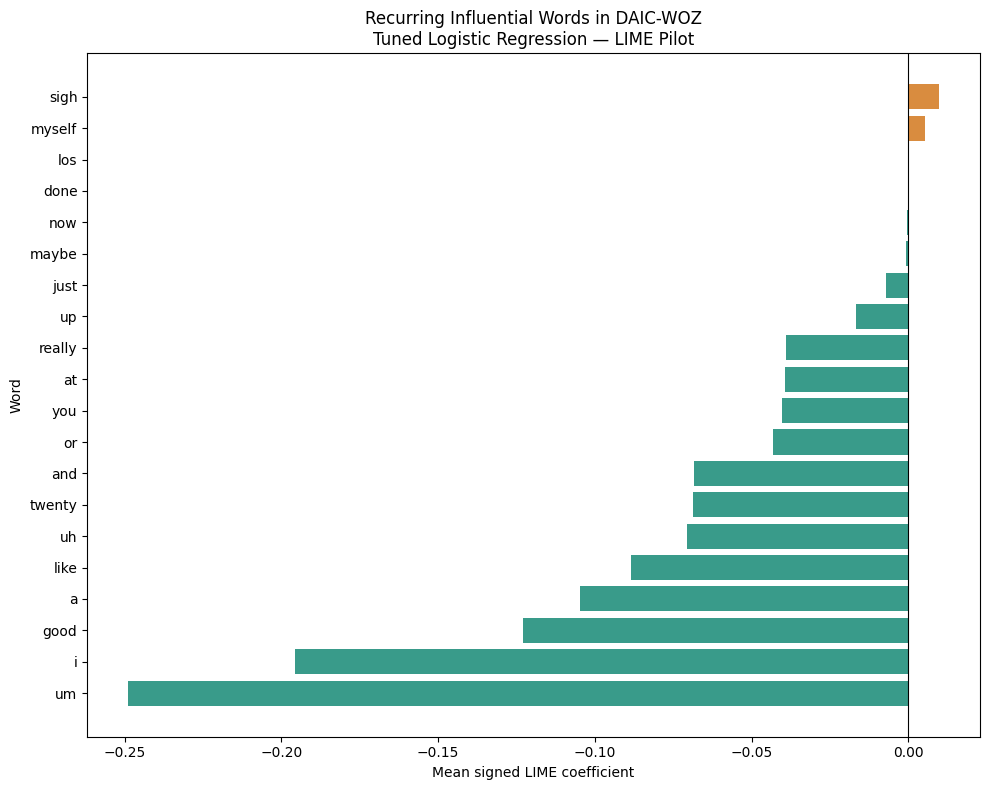

In [ ]:
top_words = (
    word_summary
    .sort_values(
        ["participants_present", "mean_abs_weight"],
        ascending=False,
    )
    .head(20)
    .sort_values("mean_weight")
)

colors = [
    "#D98C3F" if w > 0 else "#399B8A"
    for w in top_words["mean_weight"]
]

fig, ax = plt.subplots(figsize=(10, 8))

ax.barh(
    top_words["normalized_word"],
    top_words["mean_weight"],
    color=colors,
)

ax.axvline(0, color="black", linewidth=0.8)

ax.set_xlabel("Mean signed LIME coefficient")
ax.set_ylabel("Word")
ax.set_title(
    "Recurring Influential Words in DAIC-WOZ\n"
    "Tuned Logistic Regression — LIME Pilot"
)

fig.tight_layout()
fig.savefig(
    LIME_DIR / "lime_recurring_words.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### 2000 Perturbations

In [ ]:
N_SAMPLES = 2000
TOP_WORDS = 30

LIME_BASE_DIR = Path(
    "/content/drive/MyDrive/Thesis/Approach_2_Master/lime_pilot"
)

LIME_DIR = LIME_BASE_DIR / f"perturbations_{N_SAMPLES}"

LIME_DIR.mkdir(parents=True, exist_ok=True)

pilot_df = pd.read_csv(LIME_BASE_DIR / "pilot_participants.csv")


# Load selected pilot participants
pilot_df = pd.read_csv(
    LIME_BASE_DIR / "pilot_participants.csv"
)

# Standardize participant IDs to strings
pilot_df["pid"] = (
    pilot_df["pid"]
    .astype(int)
    .astype(str)
)

metadata["pid"] = (
    metadata["Participant_ID"]
    .astype(int)
    .astype(str)
)

# Rebuild metadata lookup with string IDs
metadata_by_pid = metadata.set_index("pid")

# Verify all selected participants exist
missing_pids = (
    set(pilot_df["pid"])
    - set(metadata_by_pid.index)
)

print("Pilot participants:", len(pilot_df))
print("Missing participant IDs:", missing_pids)
print("Metadata index dtype:", metadata_by_pid.index.dtype)

assert not missing_pids, (
    f"Participants missing from metadata: {missing_pids}"
)

lime_rows = []
timing_rows = []

for row in pilot_df.itertuples(index=False):
    pid = row.pid

    transcript = metadata_by_pid.loc[
        pid, "raw_participant_text"
    ]

    audio_vector = X_audio[row.audio_index]

    predictor = make_lime_predictor(audio_vector)

    start = time.time()

    explanation = explainer.explain_instance(
        text_instance=transcript,
        classifier_fn=predictor,
        labels=(1,),
        num_features=TOP_WORDS,
        num_samples=N_SAMPLES,
    )

    elapsed = time.time() - start

    explanation.save_to_file(
        str(LIME_DIR / f"participant_{pid}_lime.html")
    )

    for rank, (word, weight) in enumerate(
        explanation.as_list(label=1),
        start=1,
    ):
        lime_rows.append({
            "participant_id": pid,
            "true_label": row.true_label,
            "predicted_label": row.predicted_label,
            "correct": row.correct,
            "word": word,
            "lime_weight": weight,
            "rank": rank,
        })

    timing_rows.append({
        "participant_id": pid,
        "seconds": elapsed,
    })

    print(
        f"Completed {pid}: "
        f"{elapsed:.1f} seconds"
    )

    # Save after every participant.
    pd.DataFrame(lime_rows).to_csv(
        LIME_DIR / "lime_word_explanations.csv",
        index=False,
    )

lime_df = pd.DataFrame(lime_rows)
timing_df = pd.DataFrame(timing_rows)

display(timing_df)
display(lime_df.head(20))


Pilot participants: 10
Missing participant IDs: set()
Metadata index dtype: object
Completed 387: 35.6 seconds
Completed 438: 112.3 seconds
Completed 300: 19.4 seconds
Completed 301: 64.0 seconds
Completed 314: 113.2 seconds
Completed 332: 51.8 seconds
Completed 405: 95.7 seconds
Completed 309: 36.8 seconds
Completed 308: 37.7 seconds
Completed 311: 36.5 seconds


,participant_id,seconds
0,387,35.634877
1,438,112.343724
2,300,19.392179
3,301,64.008156
4,314,113.167101
5,332,51.776210
6,405,95.717715
7,309,36.754691
8,308,37.727557
9,311,36.545651


,participant_id,true_label,predicted_label,correct,word,lime_weight,rank
0,387,0,0,True,i,-0.282479,1
1,387,0,0,True,a,-0.134248,2
2,387,0,0,True,good,-0.116093,3
3,387,0,0,True,great,-0.112216,4
4,387,0,0,True,very,-0.097843,5
5,387,0,0,True,had,-0.089102,6
6,387,0,0,True,philadelphia,-0.089047,7
7,387,0,0,True,warm,-0.076597,8
8,387,0,0,True,you,-0.075373,9
9,387,0,0,True,and,-0.072533,10


In [ ]:
lime_df["normalized_word"] = (
    lime_df["word"]
    .str.lower()
    .str.strip()
)

word_summary = (
    lime_df.groupby("normalized_word")
    .agg(
        participants_present=(
            "participant_id", "nunique"
        ),
        mean_weight=("lime_weight", "mean"),
        mean_abs_weight=(
            "lime_weight",
            lambda x: np.mean(np.abs(x))
        ),
        positive_occurrences=(
            "lime_weight",
            lambda x: int((x > 0).sum())
        ),
        negative_occurrences=(
            "lime_weight",
            lambda x: int((x < 0).sum())
        ),
    )
    .reset_index()
    .sort_values(
        ["participants_present", "mean_abs_weight"],
        ascending=False,
    )
)

word_summary.to_csv(
    LIME_DIR / "recurring_lime_words.csv",
    index=False,
)

display(word_summary.head(20))


,normalized_word,participants_present,mean_weight,mean_abs_weight,positive_occurrences,negative_occurrences
97,i,6,-0.162755,0.162755,0,6
236,you,6,-0.054804,0.054804,0,6
212,um,5,-0.118876,0.118876,0,5
197,the,5,-0.057383,0.057383,0,5
0,a,5,-0.057007,0.057007,0,5
211,uh,5,-0.047253,0.047253,0,5
7,and,4,-0.056083,0.056083,0,4
129,me,4,-0.020894,0.020908,2,2
84,happy,3,-0.039397,0.039397,0,3
220,was,3,-0.011604,0.037276,1,2


In [ ]:
# Separate positive and negative LIME contributions

positive_words = (
    lime_df[lime_df["lime_weight"] > 0]
    .groupby("normalized_word")
    .agg(
        participants=("participant_id", "nunique"),
        mean_positive_weight=("lime_weight", "mean"),
        max_positive_weight=("lime_weight", "max"),
    )
    .reset_index()
    .sort_values(
        ["participants", "mean_positive_weight"],
        ascending=False,
    )
)

negative_words = (
    lime_df[lime_df["lime_weight"] < 0]
    .groupby("normalized_word")
    .agg(
        participants=("participant_id", "nunique"),
        mean_negative_weight=("lime_weight", "mean"),
        min_negative_weight=("lime_weight", "min"),
    )
    .reset_index()
    .sort_values(
        ["participants", "mean_negative_weight"],
        ascending=[False, True],
    )
)

print("TOP WORDS SUPPORTING DEPRESSION")
display(positive_words.head(20))

print("TOP WORDS SUPPORTING NO DEPRESSION")
display(negative_words.head(20))


TOP WORDS SUPPORTING DEPRESSION


,normalized_word,participants,mean_positive_weight,max_positive_weight
27,just,3,0.024114,0.058674
54,s,3,0.016809,0.028125
0,ago,2,0.037453,0.038142
67,they,2,0.025534,0.050777
58,sigh,2,0.011813,0.019435
33,me,2,0.000014,0.000027
69,took,1,0.041229,0.041229
74,was,1,0.038509,0.038509
2,anything,1,0.033114,0.033114
8,don,1,0.029834,0.029834


TOP WORDS SUPPORTING NO DEPRESSION


,normalized_word,participants,mean_negative_weight,min_negative_weight
75,i,6,-0.162755,-0.302550
165,you,6,-0.054804,-0.112296
143,um,5,-0.118876,-0.235428
134,the,5,-0.057383,-0.086260
0,a,5,-0.057007,-0.134248
142,uh,5,-0.047253,-0.081175
5,and,4,-0.056083,-0.072533
66,happy,3,-0.039397,-0.059145
52,from,3,-0.036344,-0.065818
105,on,3,-0.014217,-0.038730


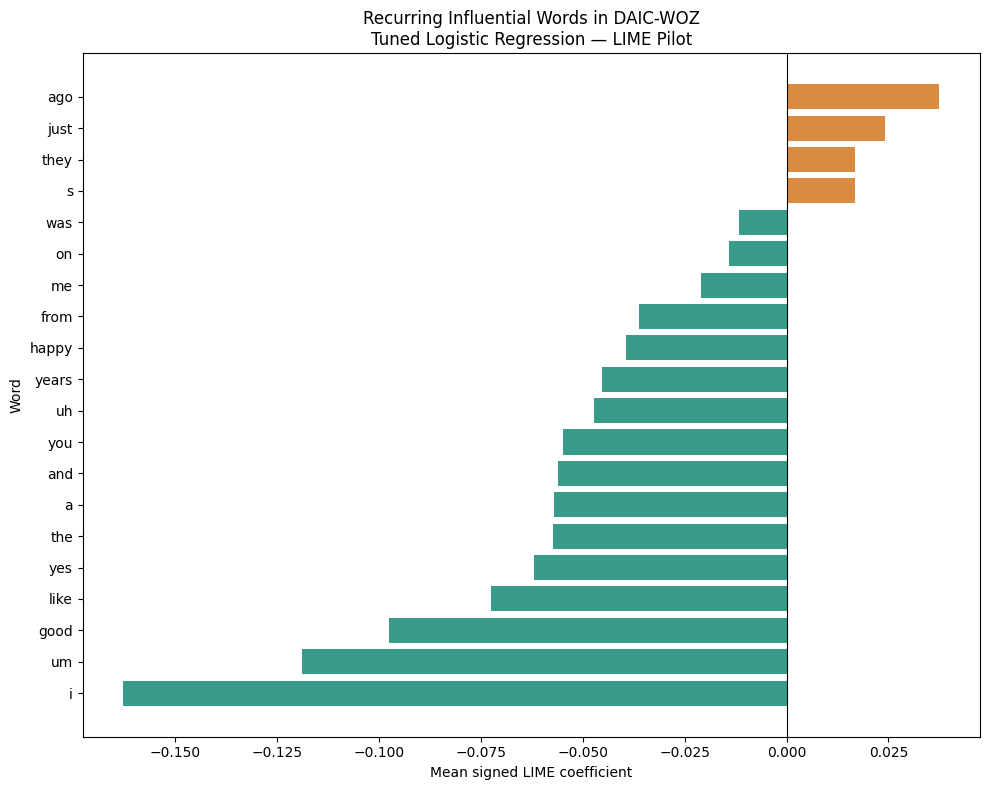

In [ ]:
top_words = (
    word_summary
    .sort_values(
        ["participants_present", "mean_abs_weight"],
        ascending=False,
    )
    .head(20)
    .sort_values("mean_weight")
)

colors = [
    "#D98C3F" if w > 0 else "#399B8A"
    for w in top_words["mean_weight"]
]

fig, ax = plt.subplots(figsize=(10, 8))

ax.barh(
    top_words["normalized_word"],
    top_words["mean_weight"],
    color=colors,
)

ax.axvline(0, color="black", linewidth=0.8)

ax.set_xlabel("Mean signed LIME coefficient")
ax.set_ylabel("Word")
ax.set_title(
    "Recurring Influential Words in DAIC-WOZ\n"
    "Tuned Logistic Regression — LIME Pilot"
)

fig.tight_layout()
fig.savefig(
    LIME_DIR / "lime_recurring_words.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### Run LIME on all 46 test participants

In [ ]:
from pathlib import Path
import time
import numpy as np
import pandas as pd

# ==========================================
# Configuration
# ==========================================

N_SAMPLES = 2000
TOP_WORDS = 20

LIME_BASE_DIR = Path(
    "/content/drive/MyDrive/Thesis/"
    "Approach_2_Master/lime_pilot"
)

LIME_DIR = (
    LIME_BASE_DIR
    / f"full_test_46_perturbations_{N_SAMPLES}"
)

LIME_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_PATH = LIME_DIR / "lime_word_explanations.csv"
TIMING_PATH = LIME_DIR / "lime_timings.csv"

# ==========================================
# Prepare test participants
# ==========================================

metadata = metadata.copy()

metadata["pid"] = (
    metadata["Participant_ID"]
    .astype(int)
    .astype(str)
)

test_df = metadata[
    metadata["Dataset"].str.strip().str.lower()
    == "test"
].copy()

test_df = test_df.reset_index(drop=True)

# Reuse the participant ordering that was
# used when X_audio was originally constructed.
assert len(pids) == len(X_audio)

audio_by_pid = {
    str(pid): X_audio[i]
    for i, pid in enumerate(pids)
}

assert len(audio_by_pid) == len(pids), (
    "Duplicate participant IDs in pids"
)

assert test_df["pid"].is_unique

assert set(test_df["pid"]) == set(audio_by_pid), (
    "Test participant IDs do not match "
    "the audio embedding participant IDs."
)

assert len(test_df) == 46, (
    f"Expected 46 participants, "
    f"found {len(test_df)}"
)

In [ ]:
# ==========================================
# Load existing results (resume support)
# ==========================================

if RESULTS_PATH.exists():
    lime_df = pd.read_csv(RESULTS_PATH)
else:
    lime_df = pd.DataFrame()

if TIMING_PATH.exists():
    timing_df = pd.read_csv(TIMING_PATH)
else:
    timing_df = pd.DataFrame()

# Only treat participants with both their
# CSV results and saved HTML as complete.
completed = set()

if not lime_df.empty:
    for pid in lime_df["participant_id"].astype(str).unique():
        html_path = (
            LIME_DIR / f"participant_{pid}_lime.html"
        )
        if html_path.exists():
            completed.add(pid)

print("Total participants:", len(test_df))
print("Already completed:", len(completed))
print("Output folder:", LIME_DIR)

# ==========================================
# Run LIME
# ==========================================

for row in test_df.itertuples(index=False):

    pid = str(row.pid)

    if pid in completed:
        print(f"Skipping completed participant {pid}")
        continue

    transcript = row.raw_participant_text

    if not isinstance(transcript, str):
        raise ValueError(
            f"Missing transcript for participant {pid}"
        )

    audio_vector = audio_by_pid[pid]

    predictor = make_lime_predictor(
        audio_vector
    )

    start = time.time()

    explanation = explainer.explain_instance(
        text_instance=transcript,
        classifier_fn=predictor,
        labels=(1,),
        num_features=TOP_WORDS,
        num_samples=N_SAMPLES,
    )

    elapsed = time.time() - start

    # Save HTML
    explanation.save_to_file(
        str(
            LIME_DIR
            / f"participant_{pid}_lime.html"
        )
    )

    # Replace any incomplete prior rows
    if not lime_df.empty:
        lime_df = lime_df[
            lime_df["participant_id"].astype(str)
            != pid
        ].copy()

    participant_rows = []

    for rank, (word, weight) in enumerate(
        explanation.as_list(label=1),
        start=1,
    ):
        participant_rows.append({
            "participant_id": pid,
            "true_label": int(row.PHQ8_Binary),
            "word": word,
            "lime_weight": float(weight),
            "rank": rank,
        })

    lime_df = pd.concat(
        [lime_df, pd.DataFrame(participant_rows)],
        ignore_index=True,
    )

    timing_df = pd.concat(
        [
            timing_df[
                timing_df["participant_id"].astype(str)
                != pid
            ] if not timing_df.empty else timing_df,
            pd.DataFrame([{
                "participant_id": pid,
                "seconds": elapsed,
                "num_samples": N_SAMPLES,
            }]),
        ],
        ignore_index=True,
    )

    # Save progress after every participant
    lime_df.to_csv(
        RESULTS_PATH,
        index=False,
    )

    timing_df.to_csv(
        TIMING_PATH,
        index=False,
    )

    completed.add(pid)

    print(
        f"Completed {len(completed)}/46: "
        f"participant {pid}, "
        f"{elapsed:.1f} seconds"
    )

print("\nLIME run complete.")
print("Participants explained:",
      lime_df["participant_id"].nunique())

display(lime_df.head(20))
display(timing_df)


Total participants: 46
Already completed: 0
Output folder: /content/drive/MyDrive/Thesis/Approach_2_Master/lime_pilot/full_test_46_perturbations_2000
Completed 1/46: participant 300, 19.5 seconds
Completed 2/46: participant 301, 63.5 seconds
Completed 3/46: participant 306, 67.1 seconds
Completed 4/46: participant 308, 37.0 seconds
Completed 5/46: participant 309, 36.2 seconds
Completed 6/46: participant 311, 36.0 seconds
Completed 7/46: participant 314, 112.0 seconds
Completed 8/46: participant 323, 60.0 seconds
Completed 9/46: participant 329, 48.7 seconds
Completed 10/46: participant 332, 50.8 seconds
Completed 11/46: participant 334, 65.2 seconds
Completed 12/46: participant 337, 166.7 seconds
Completed 13/46: participant 349, 67.3 seconds
Completed 14/46: participant 354, 32.9 seconds
Completed 15/46: participant 359, 92.6 seconds
Completed 16/46: participant 361, 53.0 seconds
Completed 17/46: participant 365, 83.3 seconds
Completed 18/46: participant 373, 125.8 seconds
Completed 

,participant_id,true_label,word,lime_weight,rank
0,300,0,i,-0.273987,1
1,300,0,um,-0.273751,2
2,300,0,friendship,-0.133439,3
3,300,0,uh,-0.078587,4
4,300,0,break,-0.074821,5
5,300,0,lot,-0.071962,6
6,300,0,alright,-0.070776,7
7,300,0,books,-0.068585,8
8,300,0,weather,-0.068354,9
9,300,0,do,-0.065020,10


,participant_id,seconds,num_samples
0,300,19.488190,2000
1,301,63.459003,2000
2,306,67.108176,2000
3,308,37.027742,2000
4,309,36.192222,2000
5,311,35.954078,2000
6,314,112.023465,2000
7,323,59.960820,2000
8,329,48.655268,2000
9,332,50.768288,2000


In [ ]:
lime_df["normalized_word"] = (
    lime_df["word"]
    .str.lower()
    .str.strip()
)

word_summary = (
    lime_df.groupby("normalized_word")
    .agg(
        participants_present=(
            "participant_id", "nunique"
        ),
        mean_weight=("lime_weight", "mean"),
        mean_abs_weight=(
            "lime_weight",
            lambda x: np.mean(np.abs(x))
        ),
        positive_occurrences=(
            "lime_weight",
            lambda x: int((x > 0).sum())
        ),
        negative_occurrences=(
            "lime_weight",
            lambda x: int((x < 0).sum())
        ),
    )
    .reset_index()
    .sort_values(
        ["participants_present", "mean_abs_weight"],
        ascending=False,
    )
)

word_summary.to_csv(
    LIME_DIR / "recurring_lime_words.csv",
    index=False,
)

display(word_summary.head(20))


,normalized_word,participants_present,mean_weight,mean_abs_weight,positive_occurrences,negative_occurrences
248,i,26,-0.137485,0.137485,0,26
507,um,22,-0.116482,0.116482,0,22
0,a,18,-0.082406,0.082406,0,18
480,the,18,-0.069981,0.069981,0,18
19,and,17,-0.084459,0.084459,0,17
557,you,16,-0.087437,0.087437,0,16
506,uh,15,-0.073559,0.073559,0,15
277,know,11,-0.053711,0.053711,0,11
289,like,8,-0.065906,0.065906,0,8
479,that,8,-0.055064,0.055064,0,8


In [ ]:
# Separate positive and negative LIME contributions

positive_words = (
    lime_df[lime_df["lime_weight"] > 0]
    .groupby("normalized_word")
    .agg(
        participants=("participant_id", "nunique"),
        mean_positive_weight=("lime_weight", "mean"),
        max_positive_weight=("lime_weight", "max"),
    )
    .reset_index()
    .sort_values(
        ["participants", "mean_positive_weight"],
        ascending=False,
    )
)

negative_words = (
    lime_df[lime_df["lime_weight"] < 0]
    .groupby("normalized_word")
    .agg(
        participants=("participant_id", "nunique"),
        mean_negative_weight=("lime_weight", "mean"),
        min_negative_weight=("lime_weight", "min"),
    )
    .reset_index()
    .sort_values(
        ["participants", "mean_negative_weight"],
        ascending=[False, True],
    )
)

print("TOP WORDS SUPPORTING DEPRESSION")
display(positive_words.head(20))

print("TOP WORDS SUPPORTING NO DEPRESSION")
display(negative_words.head(20))


TOP WORDS SUPPORTING DEPRESSION


,normalized_word,participants,mean_positive_weight,max_positive_weight
43,just,7,0.012518,0.050338
61,probably,4,0.007745,0.015699
62,s,3,0.021309,0.023875
8,as,3,0.013681,0.019003
74,they,3,0.012130,0.027522
18,can,3,0.010377,0.023832
81,was,2,0.012009,0.020622
54,now,2,0.008701,0.014161
73,then,2,0.008650,0.010995
70,ten,2,0.008443,0.016866


TOP WORDS SUPPORTING NO DEPRESSION


,normalized_word,participants,mean_negative_weight,min_negative_weight
225,i,26,-0.137485,-0.331218
464,um,22,-0.116482,-0.331587
0,a,18,-0.082406,-0.175101
439,the,18,-0.069981,-0.111136
17,and,17,-0.084459,-0.137653
507,you,16,-0.087437,-0.180829
463,uh,15,-0.073559,-0.127883
252,know,11,-0.053711,-0.105539
263,like,8,-0.065906,-0.105225
438,that,8,-0.055064,-0.112653


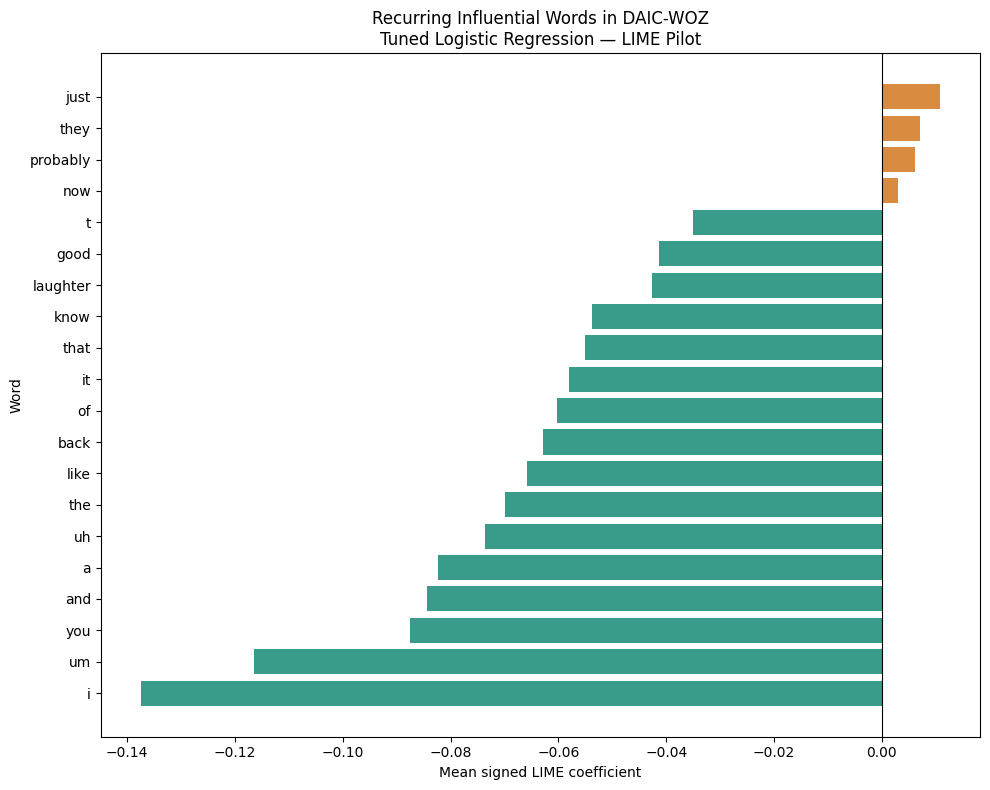

In [ ]:
top_words = (
    word_summary
    .sort_values(
        ["participants_present", "mean_abs_weight"],
        ascending=False,
    )
    .head(20)
    .sort_values("mean_weight")
)

colors = [
    "#D98C3F" if w > 0 else "#399B8A"
    for w in top_words["mean_weight"]
]

fig, ax = plt.subplots(figsize=(10, 8))

ax.barh(
    top_words["normalized_word"],
    top_words["mean_weight"],
    color=colors,
)

ax.axvline(0, color="black", linewidth=0.8)

ax.set_xlabel("Mean signed LIME coefficient")
ax.set_ylabel("Word")
ax.set_title(
    "Recurring Influential Words in DAIC-WOZ\n"
    "Tuned Logistic Regression — LIME Pilot"
)

fig.tight_layout()
fig.savefig(
    LIME_DIR / "lime_recurring_words.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### Phrase-level explanations

In [ ]:
from pathlib import Path
import re
import time
import numpy as np
import pandas as pd

from lime.lime_base import LimeBase
from sklearn.linear_model import Ridge

# Logistic regression phrase-level LIME
MIN_WORDS = 2
MAX_WORDS = 5

N_SAMPLES = 2000
TOP_PHRASES = 20
RANDOM_SEED = 42
PREDICT_BATCH_SIZE = 16

LIME_BASE_DIR = Path(
    "/content/drive/MyDrive/Thesis/"
    "Approach_2_Master/lime_pilot"
)

PHRASE_DIR = (
    LIME_BASE_DIR
    / f"logreg_phrase_level_{MIN_WORDS}to{MAX_WORDS}words_{N_SAMPLES}"
)

PHRASE_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_PATH = PHRASE_DIR / "phrase_explanations.csv"
SUMMARY_PATH = PHRASE_DIR / "participant_summary.csv"

print("Model: Logistic Regression")
print(f"Phrase lengths: {MIN_WORDS}–{MAX_WORDS} words")
print("Perturbations:", N_SAMPLES)
print("Output:", PHRASE_DIR)

Model: Logistic Regression
Phrase lengths: 2–5 words
Perturbations: 2000
Output: /content/drive/MyDrive/Thesis/Approach_2_Master/lime_pilot/logreg_phrase_level_2to5words_2000


In [ ]:
WORD_PATTERN = re.compile(
    r"\b[\w]+(?:['’][\w]+)*\b"
)

SENTENCE_END = re.compile(r"[.!?]")

def extract_phrase_spans(
    text,
    min_words=2,
    max_words=5,
    seed=42,
):
    """
    Generate non-overlapping phrases of 2–5 words.

    Does not cross sentence-ending punctuation.
    Uses a deterministic random seed.
    """

    words = list(WORD_PATTERN.finditer(text))
    rng = np.random.default_rng(seed)

    spans = []
    sentence_groups = []
    current_sentence = []

    for word in words:
        if current_sentence:
            gap = text[
                current_sentence[-1].end():word.start()
            ]

            if SENTENCE_END.search(gap):
                sentence_groups.append(current_sentence)
                current_sentence = []

        current_sentence.append(word)

    if current_sentence:
        sentence_groups.append(current_sentence)

    for sentence_words in sentence_groups:
        i = 0
        n = len(sentence_words)

        while i < n:
            remaining = n - i

            if remaining < min_words:
                break

            valid_lengths = [
                length
                for length in range(min_words, max_words + 1)
                if length <= remaining
                and (
                    remaining - length == 0
                    or remaining - length >= min_words
                )
            ]

            if not valid_lengths:
                break

            length = int(rng.choice(valid_lengths))

            group = sentence_words[i:i + length]

            start = group[0].start()
            end = group[-1].end()

            spans.append({
                "start": start,
                "end": end,
                "phrase": text[start:end],
                "num_words": length,
            })

            i += length

    return spans


def remove_phrase_spans(text, spans, keep_mask):
    """
    Remove selected phrase spans from the
    original transcript.
    """
    pieces = []
    cursor = 0

    for span, keep in zip(spans, keep_mask):
        if not keep:
            pieces.append(text[cursor:span["start"]])
            cursor = span["end"]

    pieces.append(text[cursor:])

    return "".join(pieces)


# Small example
example = (
    "I have been feeling really tired lately. "
    "I don't enjoy things anymore."
)

example_spans = extract_phrase_spans(
    example,
    min_words=MIN_WORDS,
    max_words=MAX_WORDS,
    seed=RANDOM_SEED,
)

display(pd.DataFrame(example_spans))


,start,end,phrase,num_words
0,0,6,I have,2
1,7,39,been feeling really tired lately,5
2,41,54,I don't enjoy,3
3,55,69,things anymore,2


In [ ]:
def explain_phrases(
    transcript,
    audio_vector,
    min_words=2,
    max_words=5,
    num_samples=2000,
    num_features=20,
    seed=42,
    batch_size=16,
    predictor_factory=None,
):
    spans = extract_phrase_spans(
        transcript,
        min_words=min_words,
        max_words=max_words,
        seed=seed,
    )

    n_phrases = len(spans)

    if n_phrases < 2:
        raise ValueError(
            "Not enough phrase units to explain."
        )

    rng = np.random.default_rng(seed)

    # First row is the unmodified transcript.
    masks = np.ones(
        (num_samples, n_phrases),
        dtype=np.int8,
    )

    # Randomly remove different subsets
    # of phrases for the remaining rows.
    for i in range(1, num_samples):
        n_remove = int(
            rng.integers(1, n_phrases + 1)
        )
        removed = rng.choice(
            n_phrases,
            size=n_remove,
            replace=False,
        )
        masks[i, removed] = 0

    if predictor_factory is None:
        predictor_factory = make_lime_predictor

    predictor = predictor_factory(audio_vector)

    probabilities = []

    for start in range(0, num_samples, batch_size):
        batch_masks = masks[
            start:start + batch_size
        ]

        batch_texts = [
            remove_phrase_spans(
                transcript, spans, mask
            )
            for mask in batch_masks
        ]

        batch_probs = np.asarray(
            predictor(batch_texts)
        )

        if (
            batch_probs.ndim != 2
            or batch_probs.shape[1] != 2
        ):
            raise ValueError(
                "Predictor must return "
                "an (N, 2) probability array."
            )

        probabilities.append(batch_probs)

    probabilities = np.vstack(probabilities)

    # Cosine distance to the all-ones
    # original transcript mask.
    retained = masks.sum(axis=1)

    distances = 100.0 * (
        1.0 - np.sqrt(
            retained / n_phrases
        )
    )

    lime_base = LimeBase(
        kernel_fn=lambda d: np.sqrt(
            np.exp(-(d ** 2) / (25.0 ** 2))
        ),
        verbose=False,
        random_state=seed,
    )

    intercept, explanation, score, local_pred = (
        lime_base.explain_instance_with_data(
            neighborhood_data=masks,
            neighborhood_labels=probabilities,
            distances=distances,
            label=1,
            num_features=min(
                num_features, n_phrases
            ),
            model_regressor=Ridge(
                alpha=1.0,
                fit_intercept=True,
                random_state=seed,
            ),
            feature_selection="auto",
        )
    )

    rows = []

    for rank, (feature_id, weight) in enumerate(
        explanation, start=1
    ):
        span = spans[int(feature_id)]

        rows.append({
            "rank": rank,
            "phrase_id": int(feature_id),
            "phrase": span["phrase"],
            "start_char": span["start"],
            "end_char": span["end"],
            "lime_weight": float(weight),
        })

    return {
        "phrases": pd.DataFrame(rows),
        "original_probability": float(
            probabilities[0, 1]
        ),
        "surrogate_r2": float(score),
        "surrogate_prediction": float(
            np.asarray(local_pred).ravel()[0]
        ),
        "num_phrase_units": n_phrases,
    }


In [ ]:
# Select first test participant
participant = test_df.iloc[0]

pid = str(participant["pid"])
transcript = participant["raw_participant_text"]

start = time.time()

# Select first test participant
participant = test_df.iloc[0]

pid = str(participant["pid"])
transcript = participant["raw_participant_text"]

start = time.time()

result = explain_phrases(
    transcript=transcript,
    audio_vector=audio_by_pid[pid],
    min_words=MIN_WORDS,
    max_words=MAX_WORDS,
    num_samples=N_SAMPLES,
    num_features=TOP_PHRASES,
    seed=RANDOM_SEED,
    batch_size=PREDICT_BATCH_SIZE,
    predictor_factory=make_lime_predictor,
)

print("Participant:", pid)
print("True label:", participant["PHQ8_Binary"])
print(
    "Depression probability:",
    result["original_probability"]
)
print("Surrogate R²:", result["surrogate_r2"])
print("Phrase units:", result["num_phrase_units"])
print("Seconds:", round(time.time() - start, 1))

display(result["phrases"])

Participant: 300
True label: 0
Depression probability: 6.513671149213532e-09
Surrogate R²: 0.31628636895337725
Phrase units: 98
Seconds: 20.9


,rank,phrase_id,phrase,start_char,end_char,lime_weight
0,1,95,alright friendship chocolate,1701,1729,-0.044683
1,2,45,with friends and family playing,796,827,-0.042998
2,3,41,don't uh somewhat friendship i,724,754,-0.041910
3,4,96,tall thin,1730,1739,-0.040380
4,5,5,i like the opportunities um,81,108,-0.039573
5,6,73,high school,1312,1323,-0.036869
6,7,83,repeat that irritated um lazy,1461,1490,-0.034496
7,8,37,um i don't like um,651,669,-0.034131
8,9,66,high school well uh i,1201,1222,-0.032928
9,10,76,whatever i wanted,1352,1369,-0.032692


In [ ]:
# Load existing output if resuming
if RESULTS_PATH.exists():
    phrase_df = pd.read_csv(
        RESULTS_PATH,
        dtype={"participant_id": str},
    )
else:
    phrase_df = pd.DataFrame()

if SUMMARY_PATH.exists():
    summary_df = pd.read_csv(
        SUMMARY_PATH,
        dtype={"participant_id": str},
    )
else:
    summary_df = pd.DataFrame()

completed = (
    set(summary_df["participant_id"].astype(str))
    if not summary_df.empty
    else set()
)

for row in test_df.itertuples(index=False):
    pid = str(row.pid)

    if pid in completed:
        print("Skipping", pid)
        continue

    start = time.time()

    result = explain_phrases(
        transcript=row.raw_participant_text,
        audio_vector=audio_by_pid[pid],
        min_words=MIN_WORDS,
        max_words=MAX_WORDS,
        num_samples=N_SAMPLES,
        num_features=TOP_PHRASES,
        seed=RANDOM_SEED,
        batch_size=PREDICT_BATCH_SIZE,
        predictor_factory=make_lime_predictor,
    )

    elapsed = time.time() - start

    participant_phrases = result["phrases"].copy()

    participant_phrases["participant_id"] = pid
    participant_phrases["true_label"] = int(
        row.PHQ8_Binary
    )

    phrase_df = pd.concat(
        [phrase_df, participant_phrases],
        ignore_index=True,
    )

    summary_row = {
        "participant_id": pid,
        "true_label": int(row.PHQ8_Binary),
        "original_probability":
            result["original_probability"],
        "surrogate_r2":
            result["surrogate_r2"],
        "surrogate_prediction":
            result["surrogate_prediction"],
        "num_phrase_units":
            result["num_phrase_units"],
        "num_samples": N_SAMPLES,
        "elapsed_seconds": elapsed,
    }

    summary_df = pd.concat(
        [summary_df, pd.DataFrame([summary_row])],
        ignore_index=True,
    )

    phrase_df.to_csv(
        RESULTS_PATH, index=False
    )

    summary_df.to_csv(
        SUMMARY_PATH, index=False
    )

    completed.add(pid)

    print(
        f"Completed {len(completed)}/46: "
        f"{pid} ({elapsed:.1f}s)"
    )

print("Finished participants:", len(completed))
display(summary_df.head())


Completed 1/46: 300 (20.6s)
Completed 2/46: 301 (46.5s)
Completed 3/46: 306 (49.6s)
Completed 4/46: 308 (32.8s)
Completed 5/46: 309 (30.2s)
Completed 6/46: 311 (28.4s)
Completed 7/46: 314 (84.1s)
Completed 8/46: 323 (45.8s)
Completed 9/46: 329 (34.7s)
Completed 10/46: 332 (36.8s)
Completed 11/46: 334 (46.2s)
Completed 12/46: 337 (111.8s)
Completed 13/46: 349 (48.7s)
Completed 14/46: 354 (22.4s)
Completed 15/46: 359 (65.5s)
Completed 16/46: 361 (41.2s)
Completed 17/46: 365 (62.4s)
Completed 18/46: 373 (89.9s)
Completed 19/46: 378 (43.8s)
Completed 20/46: 384 (38.0s)
Completed 21/46: 387 (24.8s)
Completed 22/46: 396 (37.8s)
Completed 23/46: 399 (38.0s)
Completed 24/46: 405 (66.5s)
Completed 25/46: 407 (79.8s)
Completed 26/46: 408 (31.4s)
Completed 27/46: 410 (44.8s)
Completed 28/46: 411 (76.4s)
Completed 29/46: 421 (36.1s)
Completed 30/46: 424 (65.6s)
Completed 31/46: 431 (32.2s)
Completed 32/46: 432 (40.4s)
Completed 33/46: 435 (35.1s)
Completed 34/46: 438 (81.7s)
Completed 35/46: 442 (

,participant_id,true_label,original_probability,surrogate_r2,surrogate_prediction,num_phrase_units,num_samples,elapsed_seconds
0,300,0,6.513671e-09,0.316286,-0.098205,98,2000,20.631009
1,301,0,9.445956e-01,0.281717,0.988354,424,2000,46.514710
2,306,0,1.415603e-07,0.532292,-0.153571,455,2000,49.617744
3,308,1,6.635192e-06,0.485833,-0.126382,253,2000,32.829226
4,309,1,9.961277e-01,0.270771,0.997544,198,2000,30.151148


In [ ]:
phrase_df["normalized_phrase"] = (
    phrase_df["phrase"]
    .str.lower()
    .str.strip()
    .str.replace(
        r"\s+", " ", regex=True
    )
)

def summarize_phrases(df):
    return (
        df.groupby("normalized_phrase")
        .agg(
            participants_present=(
                "participant_id", "nunique"
            ),
            occurrences=(
                "lime_weight", "size"
            ),
            mean_weight=(
                "lime_weight", "mean"
            ),
            mean_abs_weight=(
                "lime_weight",
                lambda x: np.abs(x).mean()
            ),
        )
        .reset_index()
        .sort_values(
            ["participants_present", "mean_abs_weight"],
            ascending=[False, False],
        )
    )

positive_phrases = summarize_phrases(
    phrase_df[phrase_df["lime_weight"] > 0]
)

negative_phrases = summarize_phrases(
    phrase_df[phrase_df["lime_weight"] < 0]
)

positive_phrases.to_csv(
    PHRASE_DIR / "top_positive_phrases.csv",
    index=False,
)

negative_phrases.to_csv(
    PHRASE_DIR / "top_negative_phrases.csv",
    index=False,
)

print("TOP PHRASES SUPPORTING DEPRESSION")
display(positive_phrases.head(20))

print("TOP PHRASES SUPPORTING NO DEPRESSION")
display(negative_phrases.head(20))


### LIME with XGBoost

In [ ]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)

ROOT = Path("/content/drive/MyDrive/Thesis")

MODEL_DIR = (
    ROOT
    / "Approach_2_Master/models"
    / "Default_Classifier_audio_text_weighted_768_xgboost"
    / "final"
)

model_path = MODEL_DIR / "model.joblib"
prep_path = MODEL_DIR / "preprocessing.joblib"

assert model_path.exists(), model_path

xgb_model = joblib.load(model_path)

print("Model type:", type(xgb_model))
print("Model classes:", xgb_model.classes_)

assert list(xgb_model.classes_) == [0, 1], (
    "Expected classes [0, 1]."
)

# Inspect the saved preprocessing.
if prep_path.exists():
    xgb_prep = joblib.load(prep_path)
    print("Preprocessing type:", type(xgb_prep))
    if isinstance(xgb_prep, dict):
        print("Preprocessing keys:", list(xgb_prep))
else:
    xgb_prep = None
    print("No separate preprocessing.joblib found.")

# Weighted_768 should use both 768-dimensional
# vectors without PCA, but verify the artifact.
if isinstance(xgb_prep, dict):
    X_xgb = make_classical_features(
        X_audio, X_text, xgb_prep
    )
else:
    X_xgb = np.concatenate(
        [X_audio, X_text], axis=1
    )

print("Input shape:", X_xgb.shape)
print("Expected features:", getattr(
    xgb_model, "n_features_in_", "unknown"
))

assert X_xgb.shape == (46, 1536)
assert getattr(
    xgb_model, "n_features_in_", 1536
) == 1536

xgb_pred = xgb_model.predict(X_xgb)
xgb_scores = xgb_model.predict_proba(X_xgb)[:, 1]

print("\nXGBoost test metrics")
print("Accuracy:",
      accuracy_score(y_test, xgb_pred))
print("Balanced accuracy:",
      balanced_accuracy_score(y_test, xgb_pred))
print("F1:",
      f1_score(y_test, xgb_pred))
print("ROC-AUC:",
      roc_auc_score(y_test, xgb_scores))
print("Confusion matrix:")
print(confusion_matrix(y_test, xgb_pred))


In [ ]:
def make_xgb_lime_predictor(audio_vector):
    """
    Predict probabilities for perturbed transcripts
    using fixed WavLM audio and regenerated
    MentalRoBERTa text embeddings.
    """
    audio_vector = np.asarray(
        audio_vector, dtype=np.float32
    ).reshape(1, -1)

    assert audio_vector.shape == (1, 768)

    def predict_proba(texts):
        texts = list(texts)

        text_vectors = np.asarray(
            encode_transcripts(texts),
            dtype=np.float32,
        )

        assert text_vectors.shape == (
            len(texts), 768
        ), text_vectors.shape

        audio_vectors = np.repeat(
            audio_vector,
            len(texts),
            axis=0,
        )

        if isinstance(xgb_prep, dict):
            features = make_classical_features(
                audio_vectors,
                text_vectors,
                xgb_prep,
            )
        else:
            features = np.concatenate(
                [audio_vectors, text_vectors],
                axis=1,
            )

        return xgb_model.predict_proba(features)

    return predict_proba


In [ ]:
# Ensure participant IDs are strings
metadata = metadata.copy()
metadata["pid"] = (
    metadata["Participant_ID"]
    .astype(int)
    .astype(str)
)

test_df = metadata[
    metadata["Dataset"].str.strip().str.lower()
    == "test"
].copy().reset_index(drop=True)

audio_by_pid = {
    str(pid): X_audio[i]
    for i, pid in enumerate(pids)
}

score_by_pid = {
    str(pid): float(xgb_scores[i])
    for i, pid in enumerate(pids)
}

assert len(test_df) == 46
assert test_df["pid"].is_unique
assert set(test_df["pid"]) == set(audio_by_pid)

# Test three participants
for row in test_df.head(3).itertuples(index=False):
    pid = str(row.pid)

    predictor = make_xgb_lime_predictor(
        audio_by_pid[pid]
    )

    regenerated_probability = float(
        predictor([row.raw_participant_text])[0, 1]
    )

    saved_probability = score_by_pid[pid]

    difference = abs(
        regenerated_probability - saved_probability
    )

    print(
        f"PID {pid}: "
        f"saved={saved_probability:.6f}, "
        f"regenerated={regenerated_probability:.6f}, "
        f"difference={difference:.6f}"
    )

    assert np.isclose(
        regenerated_probability,
        saved_probability,
        atol=1e-4,
        rtol=1e-4,
    ), (
        f"Embedding/prediction mismatch for PID {pid}"
    )

print("Predictor validation passed.")


### Word-Level LIME on 46 Participants

In [ ]:
import time

N_SAMPLES = 2000
TOP_WORDS = 20

XGB_WORD_DIR = (
    ROOT
    / "Approach_2_Master/lime_pilot"
    / "xgboost_word_level_2000"
)

XGB_WORD_DIR.mkdir(
    parents=True, exist_ok=True
)

WORD_CSV = (
    XGB_WORD_DIR / "lime_word_explanations.csv"
)

if WORD_CSV.exists():
    word_df = pd.read_csv(
        WORD_CSV,
        dtype={"participant_id": str},
    )
else:
    word_df = pd.DataFrame()

completed = set()

if not word_df.empty:
    for pid in word_df["participant_id"].unique():
        if (
            XGB_WORD_DIR
            / f"participant_{pid}_lime.html"
        ).exists():
            completed.add(str(pid))

for row in test_df.itertuples(index=False):
    pid = str(row.pid)

    if pid in completed:
        print("Skipping", pid)
        continue

    predictor = make_xgb_lime_predictor(
        audio_by_pid[pid]
    )

    start = time.time()

    explanation = explainer.explain_instance(
        text_instance=row.raw_participant_text,
        classifier_fn=predictor,
        labels=(1,),
        num_features=TOP_WORDS,
        num_samples=N_SAMPLES,
    )

    elapsed = time.time() - start

    explanation.save_to_file(
        str(
            XGB_WORD_DIR
            / f"participant_{pid}_lime.html"
        )
    )

    # Replace partial rows from a previous run
    if not word_df.empty:
        word_df = word_df[
            word_df["participant_id"] != pid
        ].copy()

    rows = []

    for rank, (word, weight) in enumerate(
        explanation.as_list(label=1),
        start=1,
    ):
        rows.append({
            "participant_id": pid,
            "true_label": int(row.PHQ8_Binary),
            "predicted_label": int(
                xgb_scores[pids.index(pid)] >= 0.5
            ),
            "word": word,
            "lime_weight": float(weight),
            "rank": rank,
            "seconds": elapsed,
        })

    word_df = pd.concat(
        [word_df, pd.DataFrame(rows)],
        ignore_index=True,
    )

    word_df.to_csv(WORD_CSV, index=False)

    completed.add(pid)

    print(
        f"Completed {len(completed)}/46: "
        f"{pid} ({elapsed:.1f}s)"
    )

print("Completed participants:",
      word_df["participant_id"].nunique())


In [ ]:
# Normalize words
word_df["normalized_word"] = (
    word_df["word"]
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

def summarize_words(df):
    return (
        df.groupby("normalized_word")
        .agg(
            participants_present=(
                "participant_id", "nunique"
            ),
            occurrences=(
                "lime_weight", "size"
            ),
            mean_weight=(
                "lime_weight", "mean"
            ),
            mean_abs_weight=(
                "lime_weight",
                lambda x: np.abs(x).mean()
            ),
        )
        .reset_index()
        .sort_values(
            ["participants_present", "mean_abs_weight"],
            ascending=[False, False],
        )
    )


# Positive LIME weights support depression (class 1)
positive_words = summarize_words(
    word_df[word_df["lime_weight"] > 0]
)

# Negative LIME weights support no depression (class 0)
negative_words = summarize_words(
    word_df[word_df["lime_weight"] < 0]
)

print("TOP 20 WORDS SUPPORTING DEPRESSION")
display(positive_words.head(20))

print("TOP 20 WORDS SUPPORTING NO DEPRESSION")
display(negative_words.head(20))


# Save results
positive_words.to_csv(
    XGB_WORD_DIR / "top_positive_words.csv",
    index=False,
)

negative_words.to_csv(
    XGB_WORD_DIR / "top_negative_words.csv",
    index=False,
)

In [ ]:
XGB_PHRASE_DIR = (
    ROOT
    / "Approach_2_Master/lime_pilot"
    / "xgboost_phrase_level_2to5words_2000"
)

phrase_df = pd.read_csv(
    XGB_PHRASE_DIR / "phrase_explanations.csv",
    dtype={"participant_id": str},
)

phrase_df["normalized_phrase"] = (
    phrase_df["phrase"]
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)


def summarize_phrases(df):
    return (
        df.groupby("normalized_phrase")
        .agg(
            participants_present=(
                "participant_id", "nunique"
            ),
            occurrences=(
                "lime_weight", "size"
            ),
            mean_weight=(
                "lime_weight", "mean"
            ),
            mean_abs_weight=(
                "lime_weight",
                lambda x: np.abs(x).mean()
            ),
        )
        .reset_index()
        .sort_values(
            ["participants_present", "mean_abs_weight"],
            ascending=[False, False],
        )
    )


positive_phrases = summarize_phrases(
    phrase_df[phrase_df["lime_weight"] > 0]
)

negative_phrases = summarize_phrases(
    phrase_df[phrase_df["lime_weight"] < 0]
)

print("TOP 20 PHRASES SUPPORTING DEPRESSION")
display(positive_phrases.head(20))

print("TOP 20 PHRASES SUPPORTING NO DEPRESSION")
display(negative_phrases.head(20))


positive_phrases.to_csv(
    XGB_PHRASE_DIR / "top_positive_phrases.csv",
    index=False,
)

negative_phrases.to_csv(
    XGB_PHRASE_DIR / "top_negative_phrases.csv",
    index=False,
)

### Phrase-Level LIME of 46 Test Participants

In [ ]:
def explain_phrases(
    transcript,
    audio_vector,
    min_words=2,
    max_words=5,
    num_samples=2000,
    num_features=20,
    seed=42,
    batch_size=16,
    predictor_factory=None,
):
    spans = extract_phrase_spans(
        transcript,
        min_words=min_words,
        max_words=max_words,
        seed=seed,
    )

    n_phrases = len(spans)

    if n_phrases < 2:
        raise ValueError(
            "Not enough phrase units to explain."
        )

    rng = np.random.default_rng(seed)

    # First row is the unmodified transcript.
    masks = np.ones(
        (num_samples, n_phrases),
        dtype=np.int8,
    )

    # Randomly remove different subsets
    # of phrases for the remaining rows.
    for i in range(1, num_samples):
        n_remove = int(
            rng.integers(1, n_phrases + 1)
        )
        removed = rng.choice(
            n_phrases,
            size=n_remove,
            replace=False,
        )
        masks[i, removed] = 0

    if predictor_factory is None:
        predictor_factory = make_lime_predictor

    predictor = predictor_factory(audio_vector)

    probabilities = []

    for start in range(0, num_samples, batch_size):
        batch_masks = masks[
            start:start + batch_size
        ]

        batch_texts = [
            remove_phrase_spans(
                transcript, spans, mask
            )
            for mask in batch_masks
        ]

        batch_probs = np.asarray(
            predictor(batch_texts)
        )

        if (
            batch_probs.ndim != 2
            or batch_probs.shape[1] != 2
        ):
            raise ValueError(
                "Predictor must return "
                "an (N, 2) probability array."
            )

        probabilities.append(batch_probs)

    probabilities = np.vstack(probabilities)

    # Cosine distance to the all-ones
    # original transcript mask.
    retained = masks.sum(axis=1)

    distances = 100.0 * (
        1.0 - np.sqrt(
            retained / n_phrases
        )
    )

    lime_base = LimeBase(
        kernel_fn=lambda d: np.sqrt(
            np.exp(-(d ** 2) / (25.0 ** 2))
        ),
        verbose=False,
        random_state=seed,
    )

    intercept, explanation, score, local_pred = (
        lime_base.explain_instance_with_data(
            neighborhood_data=masks,
            neighborhood_labels=probabilities,
            distances=distances,
            label=1,
            num_features=min(
                num_features, n_phrases
            ),
            model_regressor=Ridge(
                alpha=1.0,
                fit_intercept=True,
                random_state=seed,
            ),
            feature_selection="auto",
        )
    )

    rows = []

    for rank, (feature_id, weight) in enumerate(
        explanation, start=1
    ):
        span = spans[int(feature_id)]

        rows.append({
            "rank": rank,
            "phrase_id": int(feature_id),
            "phrase": span["phrase"],
            "start_char": span["start"],
            "end_char": span["end"],
            "lime_weight": float(weight),
        })

    return {
        "phrases": pd.DataFrame(rows),
        "original_probability": float(
            probabilities[0, 1]
        ),
        "surrogate_r2": float(score),
        "surrogate_prediction": float(
            np.asarray(local_pred).ravel()[0]
        ),
        "num_phrase_units": n_phrases,
    }


In [ ]:
spans = extract_phrase_spans(
    test_df.iloc[0]["raw_participant_text"],
    min_words=2,
    max_words=5,
    seed=42,
)

phrase_check = pd.DataFrame(spans)

print("Number of phrases:", len(phrase_check))

display(
    phrase_check["num_words"]
    .value_counts()
    .sort_index()
)

display(
    phrase_check[
        ["phrase", "num_words"]
    ].head(20)
)

assert phrase_check["num_words"].between(2, 5).all()

In [ ]:
XGB_PHRASE_DIR = (
    ROOT
    / "Approach_2_Master/lime_pilot"
    / "xgboost_phrase_level_2to5words_2000"
)

XGB_PHRASE_DIR.mkdir(
    parents=True, exist_ok=True
)

PHRASE_CSV = (
    XGB_PHRASE_DIR / "phrase_explanations.csv"
)

PHRASE_SUMMARY_CSV = (
    XGB_PHRASE_DIR / "participant_summary.csv"
)

if PHRASE_CSV.exists():
    phrase_df = pd.read_csv(
        PHRASE_CSV,
        dtype={"participant_id": str},
    )
else:
    phrase_df = pd.DataFrame()

if PHRASE_SUMMARY_CSV.exists():
    summary_df = pd.read_csv(
        PHRASE_SUMMARY_CSV,
        dtype={"participant_id": str},
    )
else:
    summary_df = pd.DataFrame()

completed = (
    set(summary_df["participant_id"])
    if not summary_df.empty
    else set()
)

for row in test_df.itertuples(index=False):
    pid = str(row.pid)

    if pid in completed:
        print("Skipping", pid)
        continue

    start = time.time()

    result = explain_phrases(
        transcript=row.raw_participant_text,
        audio_vector=audio_by_pid[pid],
        min_words=2,
        max_words=5,
        num_samples=2000,
        num_features=20,
        seed=42,
        batch_size=16,
        predictor_factory=make_xgb_lime_predictor,
    )

    elapsed = time.time() - start

    participant_phrases = result["phrases"].copy()

    participant_phrases["participant_id"] = pid
    participant_phrases["true_label"] = int(
        row.PHQ8_Binary
    )

    phrase_df = pd.concat(
        [phrase_df, participant_phrases],
        ignore_index=True,
    )

    summary_row = {
        "participant_id": pid,
        "true_label": int(row.PHQ8_Binary),
        "original_probability":
            result["original_probability"],
        "surrogate_r2":
            result["surrogate_r2"],
        "surrogate_prediction":
            result["surrogate_prediction"],
        "num_phrase_units":
            result["num_phrase_units"],
        "num_samples": 2000,
        "elapsed_seconds": elapsed,
    }

    summary_df = pd.concat(
        [summary_df, pd.DataFrame([summary_row])],
        ignore_index=True,
    )

    phrase_df.to_csv(
        PHRASE_CSV, index=False
    )

    summary_df.to_csv(
        PHRASE_SUMMARY_CSV, index=False
    )

    completed.add(pid)

    print(
        f"Completed {len(completed)}/46: "
        f"{pid} ({elapsed:.1f}s)"
    )

print("Completed participants:", len(completed))


### LIME on Default Logistic Regression 768-D Audio & Text, Word-Level

In [ ]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import time

from lime.lime_text import LimeTextExplainer

ROOT = Path("/content/drive/MyDrive/Thesis")

EXPERIMENT_NAME = (
    "Default_Classifier_audio_text_"
    "weighted_768_logistic_regression"
)

DEFAULT_MODEL_DIR = (
    ROOT
    / "Approach_2_Master/models"
    / EXPERIMENT_NAME
    / "final"
)

default_logreg_model = joblib.load(
    DEFAULT_MODEL_DIR / "model.joblib"
)

default_logreg_prep = joblib.load(
    DEFAULT_MODEL_DIR / "preprocessing.joblib"
)

print("Model:", EXPERIMENT_NAME)
print("Model type:", type(default_logreg_model))
print("Classes:", default_logreg_model.classes_)
print("Expected features:", default_logreg_model.n_features_in_)

assert default_logreg_model.n_features_in_ == 1536

assert default_logreg_prep["audio_pca"] is None
assert default_logreg_prep["text_pca"] is None

Model: Default_Classifier_audio_text_weighted_768_logistic_regression
Model type: <class 'sklearn.pipeline.Pipeline'>
Classes: [0 1]
Expected features: 1536


In [ ]:
def make_default_logreg_lime_predictor(audio_vector):

    audio_vector = np.asarray(
        audio_vector,
        dtype=np.float32,
    )

    def predict_proba(texts):

        texts = list(texts)

        text_vectors = encode_transcripts(texts)

        audio_vectors = np.repeat(
            audio_vector[None, :],
            len(texts),
            axis=0,
        )

        X = make_classical_features(
            audio_vectors,
            text_vectors,
            default_logreg_prep,
        )

        return default_logreg_model.predict_proba(X)

    return predict_proba


default_explainer = LimeTextExplainer(
    class_names=["No depression", "Depression"],
    random_state=42,
    bow=True,
)

In [ ]:
sample_row = test_df.iloc[0]

sample_pid = str(sample_row["pid"])
sample_text = sample_row["raw_participant_text"]

predictor = make_default_logreg_lime_predictor(
    audio_by_pid[sample_pid]
)

lime_prob = predictor([sample_text])[0]

with np.load(
    ROOT
    / "precomputed_multimodal_embeddings"
    / "mentalroberta_layer12"
    / f"{sample_pid}.npz"
) as data:
    original_text_vector = weighted_mean_numpy(
        data["embeddings"],
        data["num_tokens"],
    )

original_features = make_classical_features(
    audio_by_pid[sample_pid][None, :],
    original_text_vector[None, :],
    default_logreg_prep,
)

original_prob = default_logreg_model.predict_proba(
    original_features
)[0]

print("Participant:", sample_pid)
print("Original probability:", original_prob)
print("LIME predictor probability:", lime_prob)
print(
    "Maximum difference:",
    np.max(np.abs(original_prob - lime_prob))
)

assert np.allclose(
    original_prob,
    lime_prob,
    atol=1e-4,
    rtol=1e-4,
)

print("Validation passed.")

Participant: 300
Original probability: [9.99999404e-01 5.96259235e-07]
LIME predictor probability: [9.99999404e-01 5.96260893e-07]
Maximum difference: 1.658404988665972e-12
Validation passed.


In [ ]:
N_SAMPLES = 2000
TOP_WORDS = 20

DEFAULT_LIME_DIR = (
    ROOT
    / "Approach_2_Master/lime_pilot"
    / "default_logreg_word_level_2000"
)

DEFAULT_LIME_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

RESULTS_PATH = (
    DEFAULT_LIME_DIR / "lime_word_explanations.csv"
)

TIMING_PATH = (
    DEFAULT_LIME_DIR / "lime_timings.csv"
)

if RESULTS_PATH.exists():
    default_lime_df = pd.read_csv(
        RESULTS_PATH,
        dtype={"participant_id": str},
    )
else:
    default_lime_df = pd.DataFrame()

if TIMING_PATH.exists():
    default_timing_df = pd.read_csv(
        TIMING_PATH,
        dtype={"participant_id": str},
    )
else:
    default_timing_df = pd.DataFrame()

completed = set()

if not default_lime_df.empty:
    for pid in default_lime_df["participant_id"].unique():
        html_path = (
            DEFAULT_LIME_DIR
            / f"participant_{pid}_lime.html"
        )
        if html_path.exists():
            completed.add(pid)

assert len(test_df) == 46
assert set(test_df["pid"].astype(str)) == set(audio_by_pid)

print("Total participants:", len(test_df))
print("Already completed:", len(completed))

for row in test_df.itertuples(index=False):

    pid = str(row.pid)

    if pid in completed:
        print("Skipping completed participant:", pid)
        continue

    transcript = row.raw_participant_text

    if not isinstance(transcript, str) or not transcript.strip():
        raise ValueError(
            f"Missing transcript for participant {pid}"
        )

    predictor = make_default_logreg_lime_predictor(
        audio_by_pid[pid]
    )

    start = time.time()

    explanation = default_explainer.explain_instance(
        text_instance=transcript,
        classifier_fn=predictor,
        labels=(1,),
        num_features=TOP_WORDS,
        num_samples=N_SAMPLES,
    )

    elapsed = time.time() - start

    explanation.save_to_file(
        str(
            DEFAULT_LIME_DIR
            / f"participant_{pid}_lime.html"
        )
    )

    # Remove any incomplete previous results.
    if not default_lime_df.empty:
        default_lime_df = default_lime_df[
            default_lime_df["participant_id"] != pid
        ].copy()

    participant_rows = []

    for rank, (word, weight) in enumerate(
        explanation.as_list(label=1),
        start=1,
    ):
        participant_rows.append({
            "participant_id": pid,
            "true_label": int(row.PHQ8_Binary),
            "word": word,
            "lime_weight": float(weight),
            "rank": rank,
        })

    default_lime_df = pd.concat(
        [
            default_lime_df,
            pd.DataFrame(participant_rows),
        ],
        ignore_index=True,
    )

    if not default_timing_df.empty:
        default_timing_df = default_timing_df[
            default_timing_df["participant_id"] != pid
        ].copy()

    default_timing_df = pd.concat(
        [
            default_timing_df,
            pd.DataFrame([{
                "participant_id": pid,
                "seconds": elapsed,
                "num_samples": N_SAMPLES,
            }]),
        ],
        ignore_index=True,
    )

    default_lime_df.to_csv(
        RESULTS_PATH,
        index=False,
    )

    default_timing_df.to_csv(
        TIMING_PATH,
        index=False,
    )

    completed.add(pid)

    print(
        f"Completed {len(completed)}/46: "
        f"{pid} ({elapsed:.1f}s)"
    )

print("\nLIME completed.")
print(
    "Participants explained:",
    default_lime_df["participant_id"].nunique()
)

display(default_lime_df.head(20))
display(default_timing_df)

Total participants: 46
Already completed: 0
Completed 1/46: 300 (20.1s)
Completed 2/46: 301 (62.9s)
Completed 3/46: 306 (65.7s)
Completed 4/46: 308 (36.4s)
Completed 5/46: 309 (35.7s)
Completed 6/46: 311 (35.5s)
Completed 7/46: 314 (109.6s)
Completed 8/46: 323 (58.3s)
Completed 9/46: 329 (46.4s)
Completed 10/46: 332 (49.3s)
Completed 11/46: 334 (63.5s)
Completed 12/46: 337 (162.2s)
Completed 13/46: 349 (65.7s)
Completed 14/46: 354 (32.0s)
Completed 15/46: 359 (89.6s)
Completed 16/46: 361 (50.9s)
Completed 17/46: 365 (81.1s)
Completed 18/46: 373 (122.4s)
Completed 19/46: 378 (54.7s)
Completed 20/46: 384 (50.5s)
Completed 21/46: 387 (34.7s)
Completed 22/46: 396 (50.1s)
Completed 23/46: 399 (50.3s)
Completed 24/46: 405 (94.7s)
Completed 25/46: 407 (110.5s)
Completed 26/46: 408 (36.3s)
Completed 27/46: 410 (61.4s)
Completed 28/46: 411 (108.6s)
Completed 29/46: 421 (50.5s)
Completed 30/46: 424 (91.8s)
Completed 31/46: 431 (36.3s)
Completed 32/46: 432 (51.0s)
Completed 33/46: 435 (50.1s)
Com

,participant_id,true_label,word,lime_weight,rank
0,300,0,i,-0.257755,1
1,300,0,um,-0.252060,2
2,300,0,great,-0.084899,3
3,300,0,friendship,-0.075711,4
4,300,0,like,-0.073336,5
5,300,0,weather,-0.070076,6
6,300,0,and,-0.069816,7
7,300,0,high,-0.063036,8
8,300,0,you,-0.053544,9
9,300,0,administration,-0.052678,10


,participant_id,seconds,num_samples
0,300,20.140092,2000
1,301,62.904012,2000
2,306,65.690852,2000
3,308,36.444980,2000
4,309,35.703155,2000
5,311,35.500889,2000
6,314,109.617869,2000
7,323,58.274428,2000
8,329,46.379302,2000
9,332,49.303059,2000


In [ ]:
default_lime_df["normalized_word"] = (
    default_lime_df["word"]
    .str.lower()
    .str.strip()
)

default_word_summary = (
    default_lime_df
    .groupby("normalized_word")
    .agg(
        participants_present=(
            "participant_id", "nunique"
        ),
        mean_weight=(
            "lime_weight", "mean"
        ),
        mean_abs_weight=(
            "lime_weight",
            lambda x: np.mean(np.abs(x))
        ),
        positive_occurrences=(
            "lime_weight",
            lambda x: int((x > 0).sum())
        ),
        negative_occurrences=(
            "lime_weight",
            lambda x: int((x < 0).sum())
        ),
    )
    .reset_index()
    .sort_values(
        ["participants_present", "mean_abs_weight"],
        ascending=False,
    )
)

default_word_summary.to_csv(
    DEFAULT_LIME_DIR / "recurring_lime_words.csv",
    index=False,
)

display(default_word_summary.head(20))

,normalized_word,participants_present,mean_weight,mean_abs_weight,positive_occurrences,negative_occurrences
212,i,41,-0.115698,0.115698,0,41
438,um,31,-0.102299,0.102299,0,31
0,a,25,-0.076768,0.076768,0,25
16,and,25,-0.072833,0.072833,0,25
482,you,23,-0.078338,0.078338,0,23
416,the,22,-0.052465,0.052465,0,22
437,uh,18,-0.061572,0.061572,0,18
256,like,17,-0.066971,0.066971,0,17
180,good,11,-0.066216,0.066216,0,11
242,know,10,-0.056230,0.056230,0,10


In [ ]:
positive_words = (
    default_lime_df[
        default_lime_df["lime_weight"] > 0
    ]
    .groupby("normalized_word")
    .agg(
        participants=("participant_id", "nunique"),
        mean_weight=("lime_weight", "mean"),
    )
    .reset_index()
    .sort_values(
        ["participants", "mean_weight"],
        ascending=[False, False],
    )
)

negative_words = (
    default_lime_df[
        default_lime_df["lime_weight"] < 0
    ]
    .groupby("normalized_word")
    .agg(
        participants=("participant_id", "nunique"),
        mean_weight=("lime_weight", "mean"),
    )
    .reset_index()
    .sort_values(
        ["participants", "mean_weight"],
        ascending=[False, True],
    )
)

print("TOP 20 WORDS SUPPORTING DEPRESSION")
display(positive_words.head(20))

print("TOP 20 WORDS SUPPORTING NO DEPRESSION")
display(negative_words.head(20))

positive_words.to_csv(
    DEFAULT_LIME_DIR / "positive_words.csv",
    index=False,
)

negative_words.to_csv(
    DEFAULT_LIME_DIR / "negative_words.csv",
    index=False,
)

TOP 20 WORDS SUPPORTING DEPRESSION


,normalized_word,participants,mean_weight
72,s,9,0.014614
48,just,6,0.018715
89,they,3,0.021521
1,ago,3,0.008410
96,was,2,0.026784
4,anything,2,0.011700
74,sigh,2,0.010589
69,probably,2,0.009534
61,own,2,0.008435
15,can,2,0.005377


TOP 20 WORDS SUPPORTING NO DEPRESSION


,normalized_word,participants,mean_weight
181,i,41,-0.115698
378,um,31,-0.102299
0,a,25,-0.076768
15,and,25,-0.072833
418,you,23,-0.078338
359,the,22,-0.052465
377,uh,18,-0.061572
220,like,17,-0.066971
152,good,11,-0.066216
209,know,10,-0.056230


In [ ]:
from IPython.display import HTML, display

participant_id = str(test_df.iloc[0]["pid"])

html_path = (
    DEFAULT_LIME_DIR
    / f"participant_{participant_id}_lime.html"
)

display(HTML(html_path.read_text(encoding="utf-8")))

### Toward and Away from Depression (LR, XGBoost)

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import re

ROOT = Path("/content/drive/MyDrive/Thesis")
LIME_DIR = ROOT / "Approach_2_Master/lime_pilot"

LOGREG_WORD_CSV = (
    LIME_DIR
    / "full_test_46_perturbations_2000"
    / "lime_word_explanations.csv"
)

LOGREG_PHRASE_CSV = (
    LIME_DIR
    / "logreg_phrase_level_2to5words_2000"
    / "phrase_explanations.csv"
)

XGB_WORD_CSV = (
    LIME_DIR
    / "xgboost_word_level_2000"
    / "lime_word_explanations.csv"
)

XGB_PHRASE_CSV = (
    LIME_DIR
    / "xgboost_phrase_level_2to5words_2000"
    / "phrase_explanations.csv"
)

In [ ]:
def generate_top_features(
    csv_path,
    feature_col,
    top_n=20,
):
    df = pd.read_csv(
        csv_path,
        dtype={"participant_id": str},
    )

    required = {
        "participant_id",
        feature_col,
        "lime_weight",
    }

    missing = required - set(df.columns)

    if missing:
        raise ValueError(
            f"Missing columns in {csv_path}: {missing}"
        )

    df = df.dropna(
        subset=[feature_col, "lime_weight"]
    ).copy()

    df["normalized_feature"] = (
        df[feature_col]
        .astype(str)
        .str.lower()
        .str.strip()
        .str.replace("’", "'", regex=False)
        .str.replace(r"\s+", " ", regex=True)
    )

    def summarize(subset):
        return (
            subset.groupby("normalized_feature")
            .agg(
                participants_present=(
                    "participant_id", "nunique"
                ),
                occurrences=(
                    "lime_weight", "size"
                ),
                mean_weight=(
                    "lime_weight", "mean"
                ),
                mean_abs_weight=(
                    "lime_weight",
                    lambda x: x.abs().mean()
                ),
            )
            .reset_index()
            .sort_values(
                [
                    "participants_present",
                    "mean_abs_weight",
                ],
                ascending=[False, False],
            )
            .head(top_n)
            .reset_index(drop=True)
        )

    positive = summarize(
        df[df["lime_weight"] > 0]
    )

    negative = summarize(
        df[df["lime_weight"] < 0]
    )

    # Save next to the source CSV
    output_dir = csv_path.parent

    positive_path = (
        output_dir
        / f"top_positive_{feature_col}s.csv"
    )

    negative_path = (
        output_dir
        / f"top_negative_{feature_col}s.csv"
    )

    positive.to_csv(positive_path, index=False)
    negative.to_csv(negative_path, index=False)

    print(f"\nExperiment: {output_dir.name}")
    print("Participants:", df["participant_id"].nunique())

    print("\nTOP 20 TOWARD DEPRESSION")
    display(positive)

    print("\nTOP 20 AWAY FROM DEPRESSION")
    display(negative)

    print("\nSaved:")
    print(positive_path)
    print(negative_path)

    return positive, negative

In [ ]:
logreg_positive_words, logreg_negative_words = (
    generate_top_features(
        LOGREG_WORD_CSV,
        feature_col="word",
        top_n=20,
    )
)


Experiment: full_test_46_perturbations_2000
Participants: 46

TOP 20 TOWARD DEPRESSION


,normalized_feature,participants_present,occurrences,mean_weight,mean_abs_weight
0,just,7,7,0.012518,0.012518
1,probably,4,4,0.007745,0.007745
2,s,3,3,0.021309,0.021309
3,as,3,3,0.013681,0.013681
4,they,3,3,0.012130,0.012130
5,can,3,3,0.010377,0.010377
6,was,2,2,0.012009,0.012009
7,now,2,2,0.008701,0.008701
8,then,2,2,0.008650,0.008650
9,ten,2,2,0.008443,0.008443



TOP 20 AWAY FROM DEPRESSION


,normalized_feature,participants_present,occurrences,mean_weight,mean_abs_weight
0,i,26,26,-0.137485,0.137485
1,um,22,22,-0.116482,0.116482
2,a,18,18,-0.082406,0.082406
3,the,18,18,-0.069981,0.069981
4,and,17,17,-0.084459,0.084459
5,you,16,16,-0.087437,0.087437
6,uh,15,15,-0.073559,0.073559
7,know,11,11,-0.053711,0.053711
8,like,8,8,-0.065906,0.065906
9,that,8,8,-0.055064,0.055064



Saved:
/content/drive/MyDrive/Thesis/Approach_2_Master/lime_pilot/full_test_46_perturbations_2000/top_positive_words.csv
/content/drive/MyDrive/Thesis/Approach_2_Master/lime_pilot/full_test_46_perturbations_2000/top_negative_words.csv


In [ ]:
logreg_positive_phrases, logreg_negative_phrases = (
    generate_top_features(
        LOGREG_PHRASE_CSV,
        feature_col="phrase",
        top_n=20,
    )
)


Experiment: logreg_phrase_level_2to5words_2000
Participants: 46

TOP 20 TOWARD DEPRESSION


,normalized_feature,participants_present,occurrences,mean_weight,mean_abs_weight
0,they're they're so advanced with,1,1,0.091323,0.091323
1,just a side effect,1,1,0.055324,0.055324
2,just a side <s,1,1,0.040165,0.040165
3,can't treat 'em,1,1,0.036161,0.036161
4,right now i know,1,1,0.035081,0.035081
5,doesn't really,1,1,0.033068,0.033068
6,ago over some family issues,1,1,0.030314,0.030314
7,lately i've still been,1,1,0.028944,0.028944
8,a person that's,1,1,0.027851,0.027851
9,not i'm not,1,1,0.027807,0.027807



TOP 20 AWAY FROM DEPRESSION


,normalized_feature,participants_present,occurrences,mean_weight,mean_abs_weight
0,in the,2,2,-0.090575,0.090575
1,you know,2,2,-0.049662,0.049662
2,do you,2,2,-0.045484,0.045484
3,world i,2,2,-0.034712,0.034712
4,i don't,2,2,-0.001836,0.001836
5,real close uh quiet um,1,1,-0.134527,0.134527
6,what i wanted,1,1,-0.132688,0.132688
7,kept the values,1,1,-0.128993,0.128993
8,on that u_c_l_a i,1,1,-0.128304,0.128304
9,steps to become a filmmaker,1,1,-0.125996,0.125996



Saved:
/content/drive/MyDrive/Thesis/Approach_2_Master/lime_pilot/logreg_phrase_level_2to5words_2000/top_positive_phrases.csv
/content/drive/MyDrive/Thesis/Approach_2_Master/lime_pilot/logreg_phrase_level_2to5words_2000/top_negative_phrases.csv


In [ ]:
xgb_positive_words, xgb_negative_words = (
    generate_top_features(
        XGB_WORD_CSV,
        feature_col="word",
        top_n=20,
    )
)


Experiment: xgboost_word_level_2000
Participants: 46

TOP 20 TOWARD DEPRESSION


,normalized_feature,participants_present,occurrences,mean_weight,mean_abs_weight
0,s,43,43,0.054153,0.054153
1,m,27,27,0.027639,0.027639
2,was,21,21,0.021299,0.021299
3,just,18,18,0.025079,0.025079
4,t,12,12,0.014594,0.014594
5,ve,8,8,0.014913,0.014913
6,i,7,7,0.031430,0.031430
7,my,5,5,0.021767,0.021767
8,been,5,5,0.012456,0.012456
9,don,4,4,0.036026,0.036026



TOP 20 AWAY FROM DEPRESSION


,normalized_feature,participants_present,occurrences,mean_weight,mean_abs_weight
0,and,39,39,-0.085206,0.085206
1,of,29,29,-0.064191,0.064191
2,the,27,27,-0.059851,0.059851
3,you,26,26,-0.066277,0.066277
4,i,25,25,-0.100055,0.100055
5,um,22,22,-0.075477,0.075477
6,that,19,19,-0.057168,0.057168
7,to,19,19,-0.055842,0.055842
8,laughter,18,18,-0.067665,0.067665
9,in,16,16,-0.055025,0.055025



Saved:
/content/drive/MyDrive/Thesis/Approach_2_Master/lime_pilot/xgboost_word_level_2000/top_positive_words.csv
/content/drive/MyDrive/Thesis/Approach_2_Master/lime_pilot/xgboost_word_level_2000/top_negative_words.csv


In [ ]:
xgb_positive_phrases, xgb_negative_phrases = (
    generate_top_features(
        XGB_PHRASE_CSV,
        feature_col="phrase",
        top_n=20,
    )
)


Experiment: xgboost_phrase_level_2to5words_2000
Participants: 46

TOP 20 TOWARD DEPRESSION


,normalized_feature,participants_present,occurrences,mean_weight,mean_abs_weight
0,but she hasn't responded so,1,1,0.054776,0.054776
1,with their signs give me,1,1,0.048668,0.048668
2,it was my ex,1,1,0.046179,0.046179
3,cause i'm divorced now but,1,1,0.042192,0.042192
4,relationship anymore mhm who's been,1,1,0.040610,0.040610
5,uh it's,1,1,0.037136,0.037136
6,laughter> i don't,1,1,0.036711,0.036711
7,currently <curr> uh currently,1,1,0.036433,0.036433
8,just uh it's been,1,1,0.036302,0.036302
9,uh because of,1,1,0.035971,0.035971



TOP 20 AWAY FROM DEPRESSION


,normalized_feature,participants_present,occurrences,mean_weight,mean_abs_weight
0,i go to,2,2,-0.046945,0.046945
1,and i,2,2,-0.046401,0.046401
2,dream no <laughter,1,1,-0.099710,0.099710
3,i have one eleven year,1,1,-0.095887,0.095887
4,erase uh i,1,1,-0.091142,0.091142
5,laughter> like <deep,1,1,-0.089882,0.089882
6,spent the first,1,1,-0.089668,0.089668
7,yes no,1,1,-0.089370,0.089370
8,that uh,1,1,-0.088632,0.088632
9,so i don't have,1,1,-0.087768,0.087768



Saved:
/content/drive/MyDrive/Thesis/Approach_2_Master/lime_pilot/xgboost_phrase_level_2to5words_2000/top_positive_phrases.csv
/content/drive/MyDrive/Thesis/Approach_2_Master/lime_pilot/xgboost_phrase_level_2to5words_2000/top_negative_phrases.csv


### Compare Logistic Regression vs. XGBoost Models for LIME

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import re

ROOT = Path("/content/drive/MyDrive/Thesis")
LIME_DIR = ROOT / "Approach_2_Master/lime_pilot"

LOGREG_WORD_CSV = (
    LIME_DIR
    / "full_test_46_perturbations_2000"
    / "lime_word_explanations.csv"
)

XGB_WORD_CSV = (
    LIME_DIR
    / "xgboost_word_level_2000"
    / "lime_word_explanations.csv"
)

LOGREG_PHRASE_CSV = (
    LIME_DIR
    / "logreg_phrase_level_2to5words_2000"
    / "phrase_explanations.csv"
)

XGB_PHRASE_CSV = (
    LIME_DIR
    / "xgboost_phrase_level_2to5words_2000"
    / "phrase_explanations.csv"
)

AGREEMENT_DIR = LIME_DIR / "model_agreement"
AGREEMENT_DIR.mkdir(parents=True, exist_ok=True)

paths = {
    "LogReg word": LOGREG_WORD_CSV,
    "XGBoost word": XGB_WORD_CSV,
    "LogReg phrase": LOGREG_PHRASE_CSV,
    "XGBoost phrase": XGB_PHRASE_CSV,
}

for name, path in paths.items():
    print(name, ":", path)
    print("  Exists:", path.exists())

LogReg word : /content/drive/MyDrive/Thesis/Approach_2_Master/lime_pilot/full_test_46_perturbations_2000/lime_word_explanations.csv
  Exists: True
XGBoost word : /content/drive/MyDrive/Thesis/Approach_2_Master/lime_pilot/xgboost_word_level_2000/lime_word_explanations.csv
  Exists: True
LogReg phrase : /content/drive/MyDrive/Thesis/Approach_2_Master/lime_pilot/logreg_phrase_level_2to5words_2000/phrase_explanations.csv
  Exists: True
XGBoost phrase : /content/drive/MyDrive/Thesis/Approach_2_Master/lime_pilot/xgboost_phrase_level_2to5words_2000/phrase_explanations.csv
  Exists: True


In [ ]:
def load_explanations(path):
    if not path.exists():
        raise FileNotFoundError(
            f"Cannot find: {path}"
        )

    df = pd.read_csv(
        path,
        dtype={"participant_id": str},
    )

    print(f"\n{path.parent.name}")
    print("Rows:", len(df))
    print(
        "Participants:",
        df["participant_id"].nunique()
    )
    print("Columns:", df.columns.tolist())

    return df


logreg_words = load_explanations(LOGREG_WORD_CSV)
xgb_words = load_explanations(XGB_WORD_CSV)

logreg_phrases = load_explanations(LOGREG_PHRASE_CSV)
xgb_phrases = load_explanations(XGB_PHRASE_CSV)


full_test_46_perturbations_2000
Rows: 920
Participants: 46
Columns: ['participant_id', 'true_label', 'word', 'lime_weight', 'rank']

xgboost_word_level_2000
Rows: 920
Participants: 46
Columns: ['participant_id', 'true_label', 'predicted_label', 'word', 'lime_weight', 'rank', 'seconds']

logreg_phrase_level_2to5words_2000
Rows: 920
Participants: 46
Columns: ['rank', 'phrase_id', 'phrase', 'start_char', 'end_char', 'lime_weight', 'participant_id', 'true_label']

xgboost_phrase_level_2to5words_2000
Rows: 920
Participants: 46
Columns: ['rank', 'phrase_id', 'phrase', 'start_char', 'end_char', 'lime_weight', 'participant_id', 'true_label']


In [ ]:
def normalize_feature(text):
    text = str(text).lower().strip()

    # Normalize curly apostrophes
    text = text.replace("’", "'")

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text)

    return text

### Calculate participant-level Top-20 Jaccard similarity

In [ ]:
def calculate_jaccard_agreement(
    logreg_df,
    xgb_df,
    feature_col,
    top_k=20,
):
    required_cols = {
        "participant_id",
        feature_col,
        "lime_weight",
    }

    for model_name, df in [
        ("LogReg", logreg_df),
        ("XGBoost", xgb_df),
    ]:
        missing = required_cols - set(df.columns)

        if missing:
            raise ValueError(
                f"{model_name} missing columns: {missing}"
            )

    logreg_df = logreg_df.copy()
    xgb_df = xgb_df.copy()

    for df in [logreg_df, xgb_df]:
        df["participant_id"] = (
            df["participant_id"].astype(str)
        )

        df["normalized_feature"] = (
            df[feature_col]
            .apply(normalize_feature)
        )

        df["abs_weight"] = (
            df["lime_weight"].abs()
        )

    logreg_ids = set(logreg_df["participant_id"])
    xgb_ids = set(xgb_df["participant_id"])

    common_ids = sorted(logreg_ids & xgb_ids)

    if logreg_ids != xgb_ids:
        print(
            "Warning: participant sets differ.",
            "Comparing only shared participants."
        )

    rows = []

    for pid in common_ids:
        lr_participant = logreg_df[
            logreg_df["participant_id"] == pid
        ].copy()

        xgb_participant = xgb_df[
            xgb_df["participant_id"] == pid
        ].copy()

        # Select strongest unique features
        # based on absolute LIME weight.
        def top_features(df):
            ranked = (
                df.sort_values(
                    "abs_weight",
                    ascending=False
                )
                .drop_duplicates(
                    "normalized_feature",
                    keep="first"
                )
                .head(top_k)
            )

            return set(
                ranked["normalized_feature"]
            )

        lr_top = top_features(lr_participant)
        xgb_top = top_features(xgb_participant)

        intersection = lr_top & xgb_top
        union = lr_top | xgb_top

        jaccard = (
            len(intersection) / len(union)
            if union else np.nan
        )

        rows.append({
            "participant_id": pid,
            "jaccard_top20": jaccard,
            "num_logreg_features": len(lr_top),
            "num_xgb_features": len(xgb_top),
            "intersection_size": len(intersection),
            "union_size": len(union),
            "shared_features": " | ".join(
                sorted(intersection)
            ),
            "logreg_only": " | ".join(
                sorted(lr_top - xgb_top)
            ),
            "xgb_only": " | ".join(
                sorted(xgb_top - lr_top)
            ),
        })

    return pd.DataFrame(rows)

In [ ]:
# Word agreement

WORD_COLUMN = "word"

word_agreement = calculate_jaccard_agreement(
    logreg_df=logreg_words,
    xgb_df=xgb_words,
    feature_col=WORD_COLUMN,
    top_k=20,
)

display(word_agreement.head(10))

word_agreement.to_csv(
    AGREEMENT_DIR / "word_top20_jaccard.csv",
    index=False,
)

print("WORD AGREEMENT")
print(
    "Mean Jaccard:",
    word_agreement["jaccard_top20"].mean()
)
print(
    "SD Jaccard:",
    word_agreement["jaccard_top20"].std()
)
print(
    "Participants:",
    len(word_agreement)
)

,participant_id,jaccard_top20,num_logreg_features,num_xgb_features,intersection_size,union_size,shared_features,logreg_only,xgb_only
0,300,0.142857,20,20,5,35,friendship | i | s | uh | um,alright | been | books | break | do | easy | h...,and | bias | business | m | maybe | no | playi...
1,301,0.025641,20,20,1,39,the,almost | anybody | ba | good | if | just | kne...,are | average | been | but | don | driving | f...
2,306,0.176471,20,20,6,34,and | i | laughter | of | uh | you,a | as | back | depression | difficult | happi...,another | but | for | if | just | litigated | ...
3,308,0.212121,20,20,7,33,and | can | i | just | s | the | um,a | appetite | awhile | because | don | happy ...,certain | for | life | lifestyle | m | mm | on...
4,309,0.081081,20,20,3,37,i | laughter | of,a | acting | blocking | eleven | fuck | intell...,artist | at | back | basically | be | focusing...
5,311,0.111111,20,20,4,36,i | in | laughter | the,apartment | away | can | colorado | come | fif...,about | and | do | don | mm | no | s | so | th...
6,314,0.000000,20,20,0,40,,anymore | big | confrontational | contact | di...,and | but | eve | factors | getting | gratific...
7,323,0.025641,20,20,1,39,i,a | about | ahead | court | different | else |...,and | are | chicago | don | europe | even | go...
8,329,0.111111,20,20,4,36,and | i | the | was,a | beach | contribution | crowded | do | frie...,fact | in | life | m | nepal | on | or | over ...
9,332,0.142857,20,20,5,35,i | just | panicked | um | you,a | artistic | at | did | eat | everyday | hai...,and | couldn | drugs | fine | it | laughter | ...


WORD AGREEMENT
Mean Jaccard: 0.08943709435027243
SD Jaccard: 0.06609602212359961
Participants: 46


In [ ]:
phrase_agreement = calculate_jaccard_agreement(
    logreg_df=logreg_phrases,
    xgb_df=xgb_phrases,
    feature_col="phrase",
    top_k=20,
)

display(phrase_agreement.head(10))

phrase_agreement.to_csv(
    AGREEMENT_DIR / "phrase_top20_jaccard.csv",
    index=False,
)

print("PHRASE AGREEMENT")
print(
    "Mean Jaccard:",
    phrase_agreement["jaccard_top20"].mean()
)
print(
    "SD Jaccard:",
    phrase_agreement["jaccard_top20"].std()
)
print(
    "Participants:",
    len(phrase_agreement)
)

,participant_id,jaccard_top20,num_logreg_features,num_xgb_features,intersection_size,union_size,shared_features,logreg_only,xgb_only
0,300,0.176471,20,20,6,34,alright friendship chocolate | don't uh somewh...,a year can you be | and they | high school | h...,about two weeks | enjoy i enjoy cooking | from...
1,301,0.025641,20,20,1,39,mmm k i'm doing good,a millionaire but | care of myself | could've ...,and i think it | be but | decently and and | d...
2,306,0.000000,20,20,0,40,,a while | an accomplishment | i'll probably | ...,a new uh professional direction | about that i...
3,308,0.142857,20,20,5,35,about three years ago four | in between and | ...,don't know | for a nice uh sunset | good so | ...,day trying to see if | food so | guidance from...
4,309,0.025641,20,20,1,39,charming i'm,enterainment industry | explain it it's just s...,a bunch of uh cognitive | a separate therapist...
5,311,0.142857,20,20,5,35,the morning there's seagulls instead | the rig...,a long time | a person that's | do you | dogs ...,and colorado i don't | and i've complained to ...
6,314,0.025641,20,20,1,39,her labor picked up,a year old | ch] a lot of either | do and so u...,a very close have | already lived it | and the...
7,323,0.081081,20,20,3,37,airplanes i love visiting new | i have to thin...,anniversary we went | bad laws politics | for ...,at u_c_l_a and my | be very relaxed now ooh | ...
8,329,0.081081,20,20,3,37,and um uh i | but uh really | outdoors in nature,cool um well i went | didn't live | first week...,a big group of | back into india and explored ...
9,332,0.111111,20,20,4,36,i i didn't know there's | that i'd stay home |...,a little old to | always good to have those | ...,but um | cause i'm divorced now but | chose eh...


PHRASE AGREEMENT
Mean Jaccard: 0.06349726074790014
SD Jaccard: 0.06444043681949702
Participants: 46


In [ ]:
def summarize_agreement(df, level):
    values = df["jaccard_top20"].dropna()

    return {
        "Explanation Level": level,
        "Participants": len(values),
        "Mean Jaccard": values.mean(),
        "SD Jaccard": values.std(),
        "Median Jaccard": values.median(),
        "Min Jaccard": values.min(),
        "Max Jaccard": values.max(),
        "Mean Shared Features": (
            df["intersection_size"].mean()
        ),
    }


comparison = pd.DataFrame([
    summarize_agreement(
        word_agreement, "Word-level"
    ),
    summarize_agreement(
        phrase_agreement, "Phrase-level (2–5 words)"
    ),
])

comparison["Mean ± SD"] = comparison.apply(
    lambda row: (
        f"{row['Mean Jaccard']:.4f} "
        f"± {row['SD Jaccard']:.4f}"
    ),
    axis=1,
)

display(comparison)

comparison.to_csv(
    AGREEMENT_DIR / "jaccard_comparison_summary.csv",
    index=False,
)

,Explanation Level,Participants,Mean Jaccard,SD Jaccard,Median Jaccard,Min Jaccard,Max Jaccard,Mean Shared Features,Mean ± SD
0,Word-level,46,0.089437,0.066096,0.081081,0.0,0.212121,3.152174,0.0894 ± 0.0661
1,Phrase-level (2–5 words),46,0.063497,0.064440,0.052632,0.0,0.250000,2.260870,0.0635 ± 0.0644


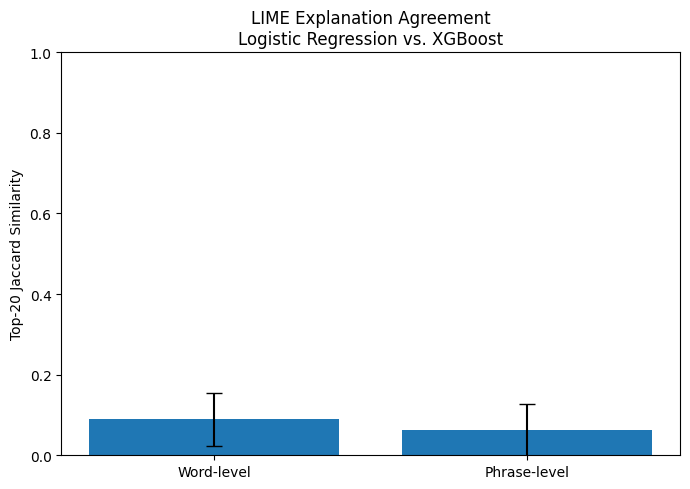

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))

labels = ["Word-level", "Phrase-level"]
means = [
    word_agreement["jaccard_top20"].mean(),
    phrase_agreement["jaccard_top20"].mean(),
]
stds = [
    word_agreement["jaccard_top20"].std(),
    phrase_agreement["jaccard_top20"].std(),
]

ax.bar(
    labels,
    means,
    yerr=stds,
    capsize=6,
)

ax.set_ylabel("Top-20 Jaccard Similarity")
ax.set_title(
    "LIME Explanation Agreement\n"
    "Logistic Regression vs. XGBoost"
)
ax.set_ylim(0, 1)

plt.tight_layout()

plt.savefig(
    AGREEMENT_DIR / "jaccard_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path("/content/drive/MyDrive/Thesis")

AGREEMENT_DIR = (
    ROOT
    / "Approach_2_Master/lime_pilot"
    / "model_agreement"
)

word_agreement = pd.read_csv(
    AGREEMENT_DIR / "word_top20_jaccard.csv",
    dtype={"participant_id": str},
)

scores = word_agreement["jaccard_top20"].dropna()

print("Participants:", len(scores))
print("Mean:", round(scores.mean(), 4))
print("Standard deviation:", round(scores.std(), 4))
print("Median:", round(scores.median(), 4))
print("Minimum:", round(scores.min(), 4))
print("Maximum:", round(scores.max(), 4))

print(
    "Mean shared words:",
    round(word_agreement["intersection_size"].mean(), 2)
)

Participants: 46
Mean: 0.0894
Standard deviation: 0.0661
Median: 0.0811
Minimum: 0.0
Maximum: 0.2121
Mean shared words: 3.15


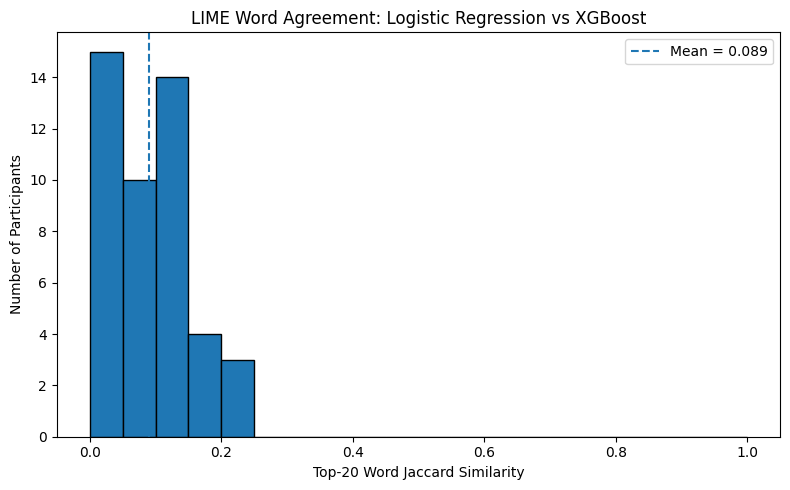

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    scores,
    bins=np.linspace(0, 1, 21),
    edgecolor="black",
)

ax.axvline(
    scores.mean(),
    linestyle="--",
    label=f"Mean = {scores.mean():.3f}",
)

ax.set_xlabel("Top-20 Word Jaccard Similarity")
ax.set_ylabel("Number of Participants")
ax.set_title(
    "LIME Word Agreement: Logistic Regression vs XGBoost"
)
ax.legend()

plt.tight_layout()
plt.savefig(
    AGREEMENT_DIR / "word_jaccard_distribution.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

In [ ]:
columns = [
    "participant_id",
    "jaccard_top20",
    "intersection_size",
    "shared_features",
    "logreg_only",
    "xgb_only",
]

print("HIGHEST AGREEMENT")
display(
    word_agreement
    .sort_values("jaccard_top20", ascending=False)
    [columns]
    .head(5)
)

print("LOWEST AGREEMENT")
display(
    word_agreement
    .sort_values("jaccard_top20", ascending=True)
    [columns]
    .head(5)
)

HIGHEST AGREEMENT


,participant_id,jaccard_top20,intersection_size,shared_features,logreg_only,xgb_only
3,308,0.212121,7,and | can | i | just | s | the | um,a | appetite | awhile | because | don | happy ...,certain | for | life | lifestyle | m | mm | on...
15,361,0.212121,7,a | i | it | the | uh | um | you,bit | don | florida | great | hmm | i_t | in |...,and | aunt | been | have | him | hours | keep ...
44,480,0.212121,7,a | i | laughter | of | the | um | you,ama | argue | care | day | finger | fun | into...,and | charismatic | consistently | educa | fri...
13,354,0.176471,6,close | i | it | just | little | the,around | big | bye | good | have | hours | iss...,actually | adults | and | football | know | m ...
10,334,0.176471,6,advantage | and | i | the | uh | within,back | census | dead | decided | die | done | ...,cal | coulda | difference | either | he | in |...


LOWEST AGREEMENT


,participant_id,jaccard_top20,intersection_size,shared_features,logreg_only,xgb_only
6,314,0.0,0,NaN,anymore | big | confrontational | contact | di...,and | but | eve | factors | getting | gratific...
11,337,0.0,0,NaN,aggressive | between | butt | came | clouded |...,afraid | almost | and | but | celebration | ch...
29,424,0.0,0,NaN,a | business | camera | come | could | even | ...,able | and | away | been | building | but | ca...
17,373,0.0,0,NaN,arrive | barcelona | basis | coolest | creativ...,a | and | books | but | can | caught | come | ...
28,421,0.0,0,NaN,describe | differences | exce | experience | f...,and | hard | i | in | is | just | laughter | l...


In [ ]:
# Uses your existing test_df metadata
labels = test_df[["pid", "PHQ8_Binary"]].copy()

labels["pid"] = labels["pid"].astype(str)

analysis_df = word_agreement.merge(
    labels,
    left_on="participant_id",
    right_on="pid",
    how="left",
    validate="one_to_one",
)

label_summary = (
    analysis_df
    .groupby("PHQ8_Binary")["jaccard_top20"]
    .agg(["count", "mean", "std", "median"])
    .reset_index()
)

display(label_summary)

,PHQ8_Binary,count,mean,std,median
0,0,32,0.095992,0.065798,0.111111
1,1,14,0.074453,0.066715,0.066856


### Jaccard Similarity with Direction

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

ROOT = Path("/content/drive/MyDrive/Thesis")
LIME_DIR = ROOT / "Approach_2_Master/lime_pilot"

LOGREG_WORD_CSV = (
    LIME_DIR
    / "full_test_46_perturbations_2000"
    / "lime_word_explanations.csv"
)

XGB_WORD_CSV = (
    LIME_DIR
    / "xgboost_word_level_2000"
    / "lime_word_explanations.csv"
)

LOGREG_PHRASE_CSV = (
    LIME_DIR
    / "logreg_phrase_level_2to5words_2000"
    / "phrase_explanations.csv"
)

XGB_PHRASE_CSV = (
    LIME_DIR
    / "xgboost_phrase_level_2to5words_2000"
    / "phrase_explanations.csv"
)

AGREEMENT_DIR = LIME_DIR / "model_agreement"
AGREEMENT_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
def load_lime_csv(path):
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")

    df = pd.read_csv(
        path,
        dtype={"participant_id": str},
    )

    print(
        path.parent.name,
        "| participants:",
        df["participant_id"].nunique(),
        "| rows:",
        len(df),
    )

    return df


logreg_words = load_lime_csv(LOGREG_WORD_CSV)
xgb_words = load_lime_csv(XGB_WORD_CSV)

logreg_phrases = load_lime_csv(LOGREG_PHRASE_CSV)
xgb_phrases = load_lime_csv(XGB_PHRASE_CSV)

full_test_46_perturbations_2000 | participants: 46 | rows: 920
xgboost_word_level_2000 | participants: 46 | rows: 920
logreg_phrase_level_2to5words_2000 | participants: 46 | rows: 920
xgboost_phrase_level_2to5words_2000 | participants: 46 | rows: 920


In [ ]:
def normalize_feature(text):
    text = str(text).lower().strip()
    text = text.replace("’", "'")
    text = re.sub(r"\s+", " ", text)
    return text


def calculate_lime_agreement(
    logreg_df,
    xgb_df,
    feature_col,
    top_k=20,
):
    required = {
        "participant_id",
        feature_col,
        "lime_weight",
    }

    for name, df in [
        ("LogReg", logreg_df),
        ("XGBoost", xgb_df),
    ]:
        missing = required - set(df.columns)
        if missing:
            raise ValueError(
                f"{name} missing columns: {missing}"
            )

    def prepare(df):
        df = df.copy()

        df["participant_id"] = (
            df["participant_id"].astype(str)
        )

        df["feature"] = (
            df[feature_col].apply(normalize_feature)
        )

        df["lime_weight"] = pd.to_numeric(
            df["lime_weight"],
            errors="coerce",
        )

        df = df.dropna(
            subset=["lime_weight"]
        )

        df = df[df["feature"] != ""]

        # Aggregate repeated feature strings
        # within each participant.
        df = (
            df.groupby(
                ["participant_id", "feature"],
                as_index=False,
            )["lime_weight"]
            .sum()
        )

        return df

    lr = prepare(logreg_df)
    xgb = prepare(xgb_df)

    lr_ids = set(lr["participant_id"])
    xgb_ids = set(xgb["participant_id"])

    common_ids = sorted(lr_ids & xgb_ids)

    if lr_ids != xgb_ids:
        print(
            "Warning: participant sets differ.",
            "Comparing shared participants only."
        )

    rows = []
    feature_rows = []

    for pid in common_ids:

        def get_top(df):
            subset = df[
                df["participant_id"] == pid
            ].copy()

            subset["abs_weight"] = (
                subset["lime_weight"].abs()
            )

            subset = (
                subset.sort_values(
                    ["abs_weight", "feature"],
                    ascending=[False, True],
                )
                .head(top_k)
            )

            return dict(
                zip(
                    subset["feature"],
                    subset["lime_weight"],
                )
            )

        lr_top = get_top(lr)
        xgb_top = get_top(xgb)

        lr_set = set(lr_top)
        xgb_set = set(xgb_top)

        shared = lr_set & xgb_set
        union = lr_set | xgb_set

        jaccard = (
            len(shared) / len(union)
            if union else np.nan
        )

        same_direction = []
        opposite_direction = []

        for feature in sorted(shared):
            lr_weight = lr_top[feature]
            xgb_weight = xgb_top[feature]

            lr_sign = np.sign(lr_weight)
            xgb_sign = np.sign(xgb_weight)

            agrees = (
                lr_sign == xgb_sign
                and lr_sign != 0
            )

            if agrees:
                same_direction.append(feature)
            else:
                opposite_direction.append(feature)

            feature_rows.append({
                "participant_id": pid,
                "feature": feature,
                "logreg_weight": lr_weight,
                "xgb_weight": xgb_weight,
                "logreg_direction": (
                    "toward_depression"
                    if lr_sign > 0
                    else "away_from_depression"
                    if lr_sign < 0
                    else "neutral"
                ),
                "xgb_direction": (
                    "toward_depression"
                    if xgb_sign > 0
                    else "away_from_depression"
                    if xgb_sign < 0
                    else "neutral"
                ),
                "direction_agrees": agrees,
            })

        directional_agreement = (
            len(same_direction) / len(shared)
            if shared else np.nan
        )

        rows.append({
            "participant_id": pid,
            "jaccard_top20": jaccard,
            "directional_agreement": (
                directional_agreement
            ),
            "num_logreg_features": len(lr_set),
            "num_xgb_features": len(xgb_set),
            "intersection_size": len(shared),
            "union_size": len(union),
            "same_direction_count": (
                len(same_direction)
            ),
            "opposite_direction_count": (
                len(opposite_direction)
            ),
            "shared_features": " | ".join(
                sorted(shared)
            ),
            "same_direction_features": " | ".join(
                same_direction
            ),
            "opposite_direction_features": " | ".join(
                opposite_direction
            ),
        })

    return (
        pd.DataFrame(rows),
        pd.DataFrame(feature_rows),
    )

In [ ]:
word_agreement, word_shared_details = (
    calculate_lime_agreement(
        logreg_df=logreg_words,
        xgb_df=xgb_words,
        feature_col="word",
        top_k=20,
    )
)

display(
    word_agreement[
        [
            "participant_id",
            "jaccard_top20",
            "directional_agreement",
            "intersection_size",
            "same_direction_count",
            "opposite_direction_count",
        ]
    ].head(10)
)

word_agreement.to_csv(
    AGREEMENT_DIR
    / "word_top20_jaccard_directional.csv",
    index=False,
)

word_shared_details.to_csv(
    AGREEMENT_DIR
    / "word_shared_feature_directions.csv",
    index=False,
)

,participant_id,jaccard_top20,directional_agreement,intersection_size,same_direction_count,opposite_direction_count
0,300,0.142857,1.000000,5,5,0
1,301,0.025641,1.000000,1,1,0
2,306,0.176471,0.833333,6,5,1
3,308,0.212121,0.857143,7,6,1
4,309,0.081081,0.666667,3,2,1
5,311,0.111111,1.000000,4,4,0
6,314,0.000000,NaN,0,0,0
7,323,0.025641,1.000000,1,1,0
8,329,0.111111,1.000000,4,4,0
9,332,0.142857,0.600000,5,3,2


In [ ]:
phrase_agreement, phrase_shared_details = (
    calculate_lime_agreement(
        logreg_df=logreg_phrases,
        xgb_df=xgb_phrases,
        feature_col="phrase",
        top_k=20,
    )
)

display(
    phrase_agreement[
        [
            "participant_id",
            "jaccard_top20",
            "directional_agreement",
            "intersection_size",
            "same_direction_count",
            "opposite_direction_count",
        ]
    ].head(10)
)

phrase_agreement.to_csv(
    AGREEMENT_DIR
    / "phrase_top20_jaccard_directional.csv",
    index=False,
)

phrase_shared_details.to_csv(
    AGREEMENT_DIR
    / "phrase_shared_feature_directions.csv",
    index=False,
)

,participant_id,jaccard_top20,directional_agreement,intersection_size,same_direction_count,opposite_direction_count
0,300,0.176471,1.000000,6,6,0
1,301,0.025641,1.000000,1,1,0
2,306,0.000000,NaN,0,0,0
3,308,0.142857,0.800000,5,4,1
4,309,0.025641,1.000000,1,1,0
5,311,0.142857,0.800000,5,4,1
6,314,0.025641,1.000000,1,1,0
7,323,0.081081,0.666667,3,2,1
8,329,0.081081,1.000000,3,3,0
9,332,0.111111,1.000000,4,4,0


In [ ]:
def summarize_agreement(df, level):
    jaccard = df["jaccard_top20"].dropna()
    directional = df["directional_agreement"].dropna()

    return {
        "Explanation Level": level,
        "N (Jaccard)": len(jaccard),
        "Jaccard Mean ± SD": (
            f"{jaccard.mean():.4f} ± "
            f"{jaccard.std():.4f}"
        ),
        "N (Directional)": len(directional),
        "Directional Mean ± SD": (
            f"{directional.mean():.4f} ± "
            f"{directional.std():.4f}"
        ),
        "Mean Shared Features": (
            df["intersection_size"].mean()
        ),
    }


summary = pd.DataFrame([
    summarize_agreement(
        word_agreement, "Word-level"
    ),
    summarize_agreement(
        phrase_agreement, "Phrase-level (2–5 words)"
    ),
])

display(summary)

summary.to_csv(
    AGREEMENT_DIR
    / "jaccard_directional_summary.csv",
    index=False,
)

,Explanation Level,N (Jaccard),Jaccard Mean ± SD,N (Directional),Directional Mean ± SD,Mean Shared Features
0,Word-level,46,0.0894 ± 0.0661,39,0.8200 ± 0.2725,3.152174
1,Phrase-level (2–5 words),46,0.0635 ± 0.0644,36,0.9569 ± 0.0950,2.260870


In [ ]:
print("WORDS WITH OPPOSITE DIRECTIONS")

word_opposite = word_shared_details[
    ~word_shared_details["direction_agrees"]
].copy()

display(
    word_opposite[
        [
            "participant_id",
            "feature",
            "logreg_weight",
            "xgb_weight",
            "logreg_direction",
            "xgb_direction",
        ]
    ].head(30)
)


print("PHRASES WITH OPPOSITE DIRECTIONS")

phrase_opposite = phrase_shared_details[
    ~phrase_shared_details["direction_agrees"]
].copy()

display(
    phrase_opposite[
        [
            "participant_id",
            "feature",
            "logreg_weight",
            "xgb_weight",
            "logreg_direction",
            "xgb_direction",
        ]
    ].head(30)
)

WORDS WITH OPPOSITE DIRECTIONS


,participant_id,feature,logreg_weight,xgb_weight,logreg_direction,xgb_direction
8,306,laughter,-7.115344e-02,0.036939,away_from_depression,toward_depression
14,308,i,-3.312184e-01,0.045472,away_from_depression,toward_depression
19,309,i,-9.754667e-05,0.039313,away_from_depression,toward_depression
31,332,i,-1.934818e-06,0.042036,away_from_depression,toward_depression
33,332,panicked,-1.834671e-06,0.008872,away_from_depression,toward_depression
41,334,within,8.695520e-03,-0.033801,toward_depression,away_from_depression
42,349,know,-7.946686e-08,0.013317,away_from_depression,toward_depression
55,361,uh,-8.683006e-02,0.022092,away_from_depression,toward_depression
61,378,deep,2.984857e-03,-0.064905,toward_depression,away_from_depression
67,384,nightmares,-3.408086e-04,0.011179,away_from_depression,toward_depression


PHRASES WITH OPPOSITE DIRECTIONS


,participant_id,feature,logreg_weight,xgb_weight,logreg_direction,xgb_direction
7,308,about three years ago four,-0.055634,0.018420,away_from_depression,toward_depression
15,311,time mm don't remember,0.006884,-0.058090,toward_depression,away_from_depression
21,323,sure everything is covered,0.006397,-0.005359,toward_depression,away_from_depression
37,354,just a side <s,0.040165,-0.040948,toward_depression,away_from_depression
47,365,if they even care,0.000008,-0.005885,toward_depression,away_from_depression
71,408,uh my uh probably,0.011216,-0.010540,toward_depression,away_from_depression
73,408,would've probably paid,0.000680,-0.005095,toward_depression,away_from_depression
100,480,tired <ti> uh,0.006728,-0.000916,toward_depression,away_from_depression


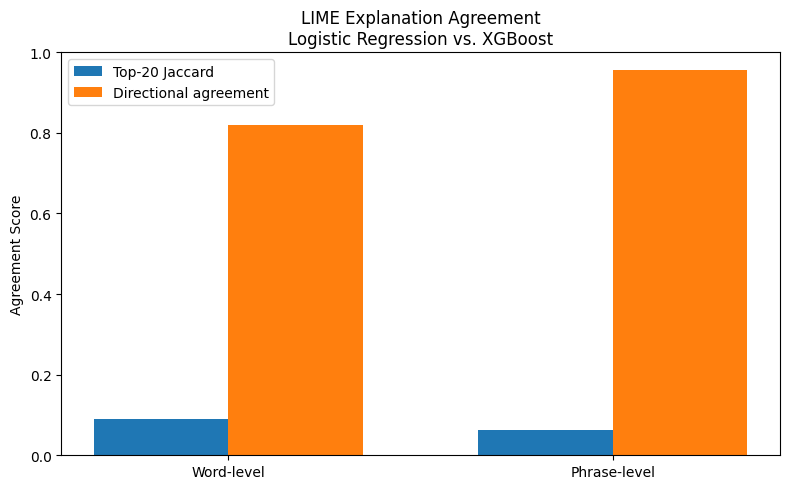

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

labels = ["Word-level", "Phrase-level"]

jaccard_means = [
    word_agreement["jaccard_top20"].mean(),
    phrase_agreement["jaccard_top20"].mean(),
]

direction_means = [
    word_agreement["directional_agreement"].mean(),
    phrase_agreement["directional_agreement"].mean(),
]

x = np.arange(len(labels))
width = 0.35

ax.bar(
    x - width / 2,
    jaccard_means,
    width,
    label="Top-20 Jaccard",
)

ax.bar(
    x + width / 2,
    direction_means,
    width,
    label="Directional agreement",
)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Agreement Score")
ax.set_ylim(0, 1)
ax.set_title(
    "LIME Explanation Agreement\n"
    "Logistic Regression vs. XGBoost"
)
ax.legend()

plt.tight_layout()

plt.savefig(
    AGREEMENT_DIR
    / "jaccard_directional_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()